<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h2>Notebook 11 — Chunking Benchmark</h2>

<p>
هدف این Notebook طراحی، آزمایش، مقایسه و انتخاب یک Strategy حرفه‌ای برای Chunking در Phase 2 پروژه RAG Finance است.
Chunking در این پروژه صرفاً تقسیم متن بر اساس تعداد کاراکتر یا Token نیست؛
بلکه باید ساختار Source، معنا، Attribution، Knowledge Authority، Conversation Context، Lineage و Citation Locator را حفظ کند.
</p>

<p>
ورودی اصلی این مرحله Dataset پذیرفته‌شده Notebook 09 است.
Taxonomy و Competency فریز‌شده Notebook 10 نیز به‌عنوان مرجع ثابت Knowledge Structure استفاده می‌شوند،
اما این Notebook مجاز به تغییر آن‌ها نیست.
</p>

<h3>هدف‌های اصلی</h3>

<ul>
<li>کشف و اعتبارسنجی وضعیت واقعی Artifactها و قراردادهای ورودی قبل از هر Rechunking.</li>
<li>تعریف قرارداد نسخه‌دار Chunk و معیارهای ارزیابی آن.</li>
<li>طراحی Strategyهای جداگانه و Source-aware برای Website، Book و Transcript.</li>
<li>حفظ Heading و Section در Book.</li>
<li>حفظ Direct Author و Editorial Supervision در Website.</li>
<li>حفظ Speaker، Conversation Context و مرزهای Attribution در Transcript.</li>
<li>مقایسه چند Candidate Strategy به‌جای انتخاب حدسی Chunk Size.</li>
<li>استفاده از Character-based Chunking فاز ۱ فقط به‌عنوان Baseline مقایسه.</li>
<li>ارزیابی Structural Quality، Semantic Quality، Attribution Integrity، Citation Integrity و در مراحل مناسب Retrieval Quality.</li>
<li>Freeze کردن Strategy نهایی فقط پس از Benchmark و Evidence واقعی.</li>
</ul>

<h3>خارج از دامنه</h3>

<ul>
<li>تغییر Taxonomy v1 یا Competency v1.</li>
<li>Inference کردن Speakerهای unresolved.</li>
<li>Merge یا حذف Sourceها صرفاً بر اساس Similarity.</li>
<li>Embedding Production.</li>
<li>ساخت Dense یا Sparse Index نهایی.</li>
<li>Hybrid Retrieval و Reranking نهایی.</li>
<li>Generation و Citation Generation.</li>
<li>اعلام Knowledge Gap قبل از Retrieval و Answerability Evaluation.</li>
</ul>

<h3>ورودی‌های مرجع</h3>

<ul>
<li><code>data/phase2/processed/documents_dedup_quality_accepted_v1.jsonl</code></li>
<li><code>reports/phase2/deduplication_quality_acceptance_v1.json</code></li>
<li><code>artifacts/phase2/taxonomy/taxonomy_v1.json</code></li>
<li><code>reports/phase2/taxonomy_freeze_v1.json</code></li>
<li><code>artifacts/phase2/competency/competency_prerequisite_v1.json</code></li>
<li><code>reports/phase2/competency_freeze_v1.json</code></li>
<li><code>schemas/phase2/document.schema.json</code></li>
</ul>

<h3>شرط Done شدن Notebook</h3>

<p>
این Notebook فقط زمانی Done است که Candidate Strategyها برای سه Source Type به‌صورت قابل‌بازتولید ساخته و ارزیابی شده باشند،
Lineage و Attribution و Locator سالم باقی مانده باشند،
Strategy منتخب با Evidence و Benchmark مشخص Freeze شده باشد،
Artifactها از Disk مستقل Re-validate شده باشند،
تمام Gateها PASS باشند و
<code>Restart Kernel → Run All → Zero Error → Final Notebook Health PASS</code>
انجام شده باشد.
</p>

</div>

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Repository / Artifact Preflight</h3>

<p>
قبل از طراحی یا اجرای هر Strategy برای Chunking، وضعیت واقعی Repository و تمام Source of Truthهای ورودی باید به‌صورت Read-only بررسی شوند.
این مرحله هیچ Chunk، Artifact، Folder یا فایل جدیدی تولید یا اصلاح نمی‌کند.
</p>

<p>
در این مرحله وضعیت Branch و HEAD، سلامت Notebook 10، Dataset پذیرفته‌شده Notebook 09،
Hash و Count ورودی‌ها، Taxonomy و Competency فریز‌شده، Schema موجود،
ساختار Sourceها و هر Artifact یا Code قبلی مرتبط با Chunking بررسی می‌شود.
</p>

<h4>معیار PASS</h4>

<ul>
<li>Repository Root و Branch <code>rag-phase2</code> درست شناسایی شوند.</li>
<li>Notebook 10 وجود داشته باشد و Saved Final Health آن سالم باشد.</li>
<li>Accepted Corpus دقیقاً 19,456 رکورد و Hash مورد انتظار داشته باشد.</li>
<li>توزیع Sourceها برابر Website=529، Book=2701 و Transcript=16226 باشد.</li>
<li>Document ID تکراری وجود نداشته باشد.</li>
<li>فیلدهای حیاتی موردنیاز Chunking در Corpus مفقود نباشند.</li>
<li>NB09 Acceptance، Taxonomy، Taxonomy Freeze، Competency و Competency Freeze با Hashهای فریز‌شده تطبیق داشته باشند.</li>
<li>Document Schema موجود و قابل Parse باشد.</li>
<li>Notebook 11 موجود باشد.</li>
</ul>

<p>
Git working tree می‌تواند به دلیل ساخته‌شدن Notebook 11 دارای تغییر باشد و Dirty بودن آن به‌تنهایی FAIL محسوب نمی‌شود.
</p>

</div>

In [1]:
# Code Cell 01

from pathlib import Path
from collections import Counter

import hashlib
import json
import re
import subprocess
import sys

import matplotlib.pyplot as plt
from transformers import AutoTokenizer


print("NB11 centralized bootstrap imports: PASS")

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NB11 centralized bootstrap imports: PASS


In [2]:
# Code Cell 02

EXPECTED_BRANCH = "rag-phase2"

EXPECTED_CORPUS_RECORDS = 19456

EXPECTED_CORPUS_SHA256 = (
    "9d72c709f81b1218c5aac064052c7ed1"
    "da34869f671e6e32762864e0ad70ea40"
)

EXPECTED_SOURCE_COUNTS = {
    "website": 529,
    "book": 2701,
    "transcript": 16226,
}

EXPECTED_HASHES = {
    "reports/phase2/deduplication_quality_acceptance_v1.json":
        "14dfa748988db17a19c6d9d5e1eac2eb7d23c0a1699dcc7add18a2bf461fe4f3",

    "artifacts/phase2/taxonomy/taxonomy_v1.json":
        "335690044b2e4eff684f7f347809f2c5cb8c39624a939dc01408d9ca898fe977",

    "reports/phase2/taxonomy_freeze_v1.json":
        "fe182b0c7c6d5ad7d5dfc2aa794fa096e85001b517040a8396d5fb4c0b17e530",

    "artifacts/phase2/competency/competency_prerequisite_v1.json":
        "f12f6c1631d77f29042b2009ca9dc8dee406d23ccdccdbb103c0e8cade781e87",

    "reports/phase2/competency_freeze_v1.json":
        "19bb27288f49e057859da3bc668f54fac440a89a2636ff5d2e49033665f0dd11",
}

CRITICAL_DOCUMENT_FIELDS = {
    "document_id",
    "source_id",
    "source_type",
    "text",
    "locator",
    "lineage",
    "attribution",
    "rights",
    "content_origin",
}


def find_repo_root():
    cwd = Path.cwd().resolve()

    for candidate in [cwd, *cwd.parents]:
        if (
            (candidate / ".git").exists()
            and (candidate / "notebooks" / "phase2").exists()
        ):
            return candidate

    raise RuntimeError(
        "Repository root could not be discovered "
        "from the current working directory."
    )


def git(repo_root, *args):
    result = subprocess.run(
        ["git", *args],
        cwd=repo_root,
        capture_output=True,
        text=True,
        check=True,
    )

    return result.stdout.strip()


def sha256_file(path, block_size=1024 * 1024):
    digest = hashlib.sha256()

    with path.open("rb") as handle:
        while True:
            block = handle.read(block_size)

            if not block:
                break

            digest.update(block)

    return digest.hexdigest()


def load_json(path):
    with path.open("r", encoding="utf-8") as handle:
        return json.load(handle)


# ---------------------------------------------------------
# Repository
# ---------------------------------------------------------

repo_root = find_repo_root()

branch = git(
    repo_root,
    "branch",
    "--show-current",
)

head = git(
    repo_root,
    "rev-parse",
    "HEAD",
)

git_status = git(
    repo_root,
    "status",
    "--short",
)

print("=" * 72)
print("REPOSITORY")
print("=" * 72)

print("Repository root:", repo_root)
print("Branch:", branch)
print("HEAD:", head)

print(
    "Git working tree:",
    "CLEAN"
    if not git_status
    else "HAS LOCAL CHANGES",
)

if git_status:
    print("\nGit status:")
    print(git_status)


# ---------------------------------------------------------
# Notebook 10 saved health
# ---------------------------------------------------------

print("\n" + "=" * 72)
print("NB10 SAVED NOTEBOOK HEALTH")
print("=" * 72)

nb10_path = (
    repo_root
    / "notebooks"
    / "phase2"
    / "10_taxonomy_and_knowledge_engineering.ipynb"
)

assert nb10_path.exists(), (
    f"Missing Notebook 10: {nb10_path}"
)

nb10 = load_json(nb10_path)

nb10_code_cells = [
    cell
    for cell in nb10.get("cells", [])
    if cell.get("cell_type") == "code"
]

nb10_unexecuted = [
    index
    for index, cell in enumerate(
        nb10_code_cells,
        start=1,
    )
    if cell.get("execution_count") is None
]

nb10_error_cells = []

for index, cell in enumerate(
    nb10_code_cells,
    start=1,
):
    has_error = any(
        output.get("output_type") == "error"
        for output in cell.get("outputs", [])
    )

    if has_error:
        nb10_error_cells.append(index)


number_pattern = re.compile(
    r"^\s*#\s*Code Cell\s+(\d+)\b"
)

nb10_numbers = []

for cell in nb10_code_cells:
    source = "".join(
        cell.get("source", [])
    )

    match = number_pattern.search(source)

    if match:
        nb10_numbers.append(
            int(match.group(1))
        )


expected_nb10_numbers = list(
    range(
        1,
        len(nb10_code_cells) + 1,
    )
)

nb10_saved_text = json.dumps(
    nb10,
    ensure_ascii=False,
)

nb10_final_gate_marker = (
    "CODE CELL 44 GATE: PASS"
    in nb10_saved_text
)

print("Notebook path:", nb10_path.relative_to(repo_root))
print("Code cells:", len(nb10_code_cells))
print("Unexecuted code cells:", len(nb10_unexecuted))
print("Saved error cells:", len(nb10_error_cells))
print("Numbered code cells:", len(nb10_numbers))

print(
    "Sequential numbering:",
    "PASS"
    if nb10_numbers == expected_nb10_numbers
    else "FAIL",
)

print(
    "Final Cell 44 PASS marker:",
    "PASS"
    if nb10_final_gate_marker
    else "FAIL",
)


# ---------------------------------------------------------
# Accepted Corpus
# ---------------------------------------------------------

print("\n" + "=" * 72)
print("ACCEPTED CORPUS")
print("=" * 72)

corpus_path = (
    repo_root
    / "data"
    / "phase2"
    / "processed"
    / "documents_dedup_quality_accepted_v1.jsonl"
)

assert corpus_path.exists(), (
    f"Missing accepted corpus: {corpus_path}"
)

corpus_sha256 = sha256_file(
    corpus_path
)

record_count = 0
source_counts = Counter()

missing_critical_fields = Counter()

document_ids = set()
duplicate_document_ids = 0

empty_text_records = 0


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):
        if not line.strip():
            continue

        record = json.loads(line)

        record_count += 1

        source_type = record.get(
            "source_type"
        )

        source_counts[
            source_type
        ] += 1

        for field in CRITICAL_DOCUMENT_FIELDS:
            if field not in record:
                missing_critical_fields[
                    field
                ] += 1

        document_id = record.get(
            "document_id"
        )

        if document_id in document_ids:
            duplicate_document_ids += 1

        elif document_id is not None:
            document_ids.add(
                document_id
            )

        if not str(
            record.get("text") or ""
        ).strip():
            empty_text_records += 1


print(
    "Corpus path:",
    corpus_path.relative_to(repo_root),
)

print(
    "Records:",
    record_count,
)

print(
    "Expected records:",
    EXPECTED_CORPUS_RECORDS,
)

print(
    "SHA-256:",
    corpus_sha256,
)

print(
    "Expected SHA-256:",
    EXPECTED_CORPUS_SHA256,
)


print("\nSource counts:")

for source_type in [
    "website",
    "book",
    "transcript",
]:
    print(
        f"- {source_type}:",
        source_counts.get(
            source_type,
            0,
        ),
        "| expected:",
        EXPECTED_SOURCE_COUNTS[
            source_type
        ],
    )


print("\nCritical corpus checks:")

print(
    "Duplicate document IDs:",
    duplicate_document_ids,
)

print(
    "Empty text records:",
    empty_text_records,
)

if missing_critical_fields:
    print(
        "Missing critical fields:"
    )

    for field, count in sorted(
        missing_critical_fields.items()
    ):
        print(
            f"- {field}: {count}"
        )

else:
    print(
        "Missing critical fields: 0"
    )


# ---------------------------------------------------------
# Accepted / Frozen artifacts
# ---------------------------------------------------------

print("\n" + "=" * 72)
print("FROZEN / ACCEPTED ARTIFACTS")
print("=" * 72)

artifact_results = {}

for relative_path, expected_hash in EXPECTED_HASHES.items():

    path = repo_root / relative_path

    print(
        f"\n{relative_path}"
    )

    if not path.exists():
        artifact_results[
            relative_path
        ] = {
            "exists": False,
            "hash_match": False,
            "actual_hash": None,
        }

        print(
            "- Exists: FAIL"
        )

        continue

    actual_hash = sha256_file(
        path
    )

    hash_match = (
        actual_hash
        == expected_hash
    )

    artifact_results[
        relative_path
    ] = {
        "exists": True,
        "hash_match": hash_match,
        "actual_hash": actual_hash,
    }

    print(
        "- Exists: PASS"
    )

    print(
        "- SHA-256:",
        actual_hash,
    )

    print(
        "- Expected:",
        expected_hash,
    )

    print(
        "- Hash match:",
        "PASS"
        if hash_match
        else "FAIL",
    )


# ---------------------------------------------------------
# Schema and existing chunking baseline
# ---------------------------------------------------------

print("\n" + "=" * 72)
print("SCHEMA / CHUNKING DISCOVERY")
print("=" * 72)

document_schema_path = (
    repo_root
    / "schemas"
    / "phase2"
    / "document.schema.json"
)

nb11_path = (
    repo_root
    / "notebooks"
    / "phase2"
    / "11_chunking_benchmark.ipynb"
)

phase1_chunking_path = (
    repo_root
    / "notebooks"
    / "03_chunking.ipynb"
)


print(
    "Document schema:",
    "FOUND"
    if document_schema_path.exists()
    else "MISSING",
)

document_schema_parse_ok = False

if document_schema_path.exists():
    load_json(
        document_schema_path
    )

    document_schema_parse_ok = True

    print(
        "Document schema JSON parse: PASS"
    )


print(
    "Notebook 11:",
    "FOUND"
    if nb11_path.exists()
    else "MISSING",
)

if nb11_path.exists():
    nb11 = load_json(
        nb11_path
    )

    print(
        "Notebook 11 current cells:",
        len(
            nb11.get(
                "cells",
                [],
            )
        ),
    )


print(
    "Phase 1 chunking baseline:",
    "FOUND"
    if phase1_chunking_path.exists()
    else "MISSING",
)


# ---------------------------------------------------------
# Final gates
# ---------------------------------------------------------

all_expected_artifacts_valid = all(
    result["exists"]
    and result["hash_match"]
    for result
    in artifact_results.values()
)


corpus_gate = (
    record_count
    == EXPECTED_CORPUS_RECORDS

    and corpus_sha256
    == EXPECTED_CORPUS_SHA256

    and dict(source_counts)
    == EXPECTED_SOURCE_COUNTS

    and duplicate_document_ids == 0

    and empty_text_records == 0

    and not missing_critical_fields
)


nb10_gate = (
    len(nb10_code_cells) == 44

    and len(nb10_unexecuted) == 0

    and len(nb10_error_cells) == 0

    and nb10_numbers
    == expected_nb10_numbers

    and nb10_final_gate_marker
)


schema_gate = (
    document_schema_path.exists()
    and document_schema_parse_ok
)


nb11_gate = (
    nb11_path.exists()
)


branch_gate = (
    branch
    == EXPECTED_BRANCH
)


final_gate = (
    branch_gate
    and nb10_gate
    and corpus_gate
    and all_expected_artifacts_valid
    and schema_gate
    and nb11_gate
)


print("\n" + "=" * 72)
print("CODE CELL 02 FINAL GATE")
print("=" * 72)

print(
    "Branch gate:",
    "PASS"
    if branch_gate
    else "FAIL",
)

print(
    "NB10 saved health gate:",
    "PASS"
    if nb10_gate
    else "FAIL",
)

print(
    "Accepted corpus gate:",
    "PASS"
    if corpus_gate
    else "FAIL",
)

print(
    "Frozen artifact hashes gate:",
    "PASS"
    if all_expected_artifacts_valid
    else "FAIL",
)

print(
    "Document schema gate:",
    "PASS"
    if schema_gate
    else "FAIL",
)

print(
    "Notebook 11 existence gate:",
    "PASS"
    if nb11_gate
    else "FAIL",
)


print(
    "\nCODE CELL 02 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "NB11 preflight failed. "
    "Do not continue until the failing "
    "condition is resolved."
)


print(
    "NB11 read-only preflight completed successfully."
)

print(
    "No chunking or artifact modification was performed."
)

REPOSITORY
Repository root: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance
Branch: rag-phase2
HEAD: 0a211771fc9d2a4fa7b146afa76734fafdf203c2
Git working tree: HAS LOCAL CHANGES

Git status:
M notebooks/phase2/11_chunking_benchmark.ipynb
?? artifacts/phase2/chunking/

NB10 SAVED NOTEBOOK HEALTH
Notebook path: notebooks/phase2/10_taxonomy_and_knowledge_engineering.ipynb
Code cells: 44
Unexecuted code cells: 0
Saved error cells: 0
Numbered code cells: 44
Sequential numbering: PASS
Final Cell 44 PASS marker: PASS

ACCEPTED CORPUS
Corpus path: data/phase2/processed/documents_dedup_quality_accepted_v1.jsonl
Records: 19456
Expected records: 19456
SHA-256: 9d72c709f81b1218c5aac064052c7ed1da34869f671e6e32762864e0ad70ea40
Expected SHA-256: 9d72c709f81b1218c5aac064052c7ed1da34869f671e6e32762864e0ad70ea40

Source counts:
- website: 529 | expected: 529
- book: 2701 | expected: 2701
- transcript: 16226 | expected: 16226

Critical corpus checks:
Duplicate document IDs: 0
Em

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Source Structure Discovery</h3>

<p>
قبل از تعریف Chunk Contract یا انتخاب Candidate Strategy باید ساختار واقعی هر Source Type در Accepted Corpus بررسی شود.
هدف این مرحله فهمیدن این است که Website، Book و Transcript واقعاً چه Boundaryها، Metadataها و Locatorهایی در اختیار Chunking قرار می‌دهند.
</p>

<p>
این بررسی فقط Read-Only است و هیچ Chunk یا Artifactی تولید نمی‌کند.
</p>

<h4>موارد مورد بررسی</h4>

<ul>
<li>توزیع طول متن در هر Source Type.</li>
<li>کلیدهای واقعی <code>source_metadata</code>، <code>locator</code> و <code>attribution</code>.</li>
<li>ساختار Website شامل Content Origin و Authority Type.</li>
<li>ساختار Book شامل Work، Edition، Paragraph، Heading Path، Heading Level، Table و Supplemental Text.</li>
<li>ساختار Transcript شامل Program، Episode، Season، Physical File، Utterance Index، Speaker و Source Identity.</li>
<li>میزان Metadataهای مفقود یا ساختارهایی که ممکن است روی Chunking اثر بگذارند.</li>
</ul>

<h4>چرا این مرحله لازم است؟</h4>

<p>
Chunking Source-specific فقط زمانی قابل دفاع است که Strategy بر اساس Boundaryهای واقعی Corpus طراحی شود.
برای مثال، Heading Path در Book، Speaker Turn در Transcript و Attribution در Website نمی‌توانند با یک Fixed Window واحد جایگزین شوند.
</p>

<h4>معیار PASS</h4>

<ul>
<li>تمام 19,456 رکورد بدون Error بررسی شوند.</li>
<li>سه Source Type مورد انتظار دقیقاً شناسایی شوند.</li>
<li><code>source_metadata</code> و <code>locator</code> برای رکوردهای لازم قابل استفاده باشند.</li>
<li>Book structure برای طراحی Heading/Section-aware Chunking قابل مشاهده باشد.</li>
<li>Transcript structure برای طراحی Conversation/Speaker-aware Chunking قابل مشاهده باشد.</li>
<li>Website authority structure برای جلوگیری از Attribution contamination قابل مشاهده باشد.</li>
</ul>

<p>
هیچ تصمیم نهایی درباره Chunk Size یا Strategy در این مرحله گرفته نمی‌شود.
خروجی این Cell فقط Evidence برای طراحی مراحل بعد است.
</p>

</div>

In [3]:
# Code Cell 03


def percentile(values, percentile_value):
    if not values:
        return None

    ordered = sorted(values)

    if len(ordered) == 1:
        return ordered[0]

    position = (
        percentile_value
        / 100
        * (len(ordered) - 1)
    )

    lower_index = int(position)
    upper_index = min(
        lower_index + 1,
        len(ordered) - 1,
    )

    fraction = (
        position
        - lower_index
    )

    return round(
        ordered[lower_index]
        + (
            ordered[upper_index]
            - ordered[lower_index]
        )
        * fraction,
        2,
    )


SOURCE_TYPES = [
    "website",
    "book",
    "transcript",
]


source_stats = {
    source_type: {
        "count": 0,
        "text_lengths": [],
        "locator_keys": Counter(),
        "metadata_keys": Counter(),
        "attribution_keys": Counter(),
        "invalid_locator": 0,
        "invalid_metadata": 0,
        "invalid_attribution": 0,
    }
    for source_type in SOURCE_TYPES
}


website_content_origin = Counter()
website_authority_type = Counter()

book_unit_types = Counter()
book_heading_levels = Counter()
book_heading_depths = Counter()
book_work_ids = set()
book_edition_ids = set()
book_heading_records = 0
book_table_records = 0
book_missing_heading_path = 0

transcript_programs = Counter()
transcript_record_types = Counter()
transcript_speakers = Counter()
transcript_source_identity_types = Counter()

transcript_episode_missing = 0
transcript_season_missing = 0
transcript_physical_file_missing = 0
transcript_utterance_index_missing = 0
transcript_speaker_missing = 0

transcript_conversation_units = set()


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):
        if not line.strip():
            continue

        record = json.loads(line)

        source_type = record.get(
            "source_type"
        )

        if source_type not in source_stats:
            raise AssertionError(
                "Unexpected source_type "
                f"at line {line_number}: "
                f"{source_type!r}"
            )

        stats = source_stats[
            source_type
        ]

        stats["count"] += 1

        text = str(
            record.get("text")
            or ""
        )

        stats[
            "text_lengths"
        ].append(
            len(text)
        )

        locator = record.get(
            "locator"
        )

        source_metadata = record.get(
            "source_metadata"
        )

        attribution = record.get(
            "attribution"
        )


        if isinstance(
            locator,
            dict,
        ):
            stats[
                "locator_keys"
            ].update(
                locator.keys()
            )
        else:
            stats[
                "invalid_locator"
            ] += 1


        if isinstance(
            source_metadata,
            dict,
        ):
            stats[
                "metadata_keys"
            ].update(
                source_metadata.keys()
            )
        else:
            stats[
                "invalid_metadata"
            ] += 1

            source_metadata = {}


        if isinstance(
            attribution,
            dict,
        ):
            stats[
                "attribution_keys"
            ].update(
                attribution.keys()
            )
        else:
            stats[
                "invalid_attribution"
            ] += 1

            attribution = {}


        # -------------------------------------------------
        # Website
        # -------------------------------------------------

        if source_type == "website":

            website_content_origin[
                record.get(
                    "content_origin"
                )
            ] += 1

            website_authority_type[
                attribution.get(
                    "content_authority_type"
                )
            ] += 1


        # -------------------------------------------------
        # Book
        # -------------------------------------------------

        elif source_type == "book":

            book_unit_type = (
                source_metadata.get(
                    "book_unit_type"
                )
            )

            book_unit_types[
                book_unit_type
            ] += 1

            work_id = (
                source_metadata.get(
                    "work_id"
                )
                or locator.get(
                    "work_id"
                )
            )

            edition_id = (
                source_metadata.get(
                    "edition_id"
                )
                or locator.get(
                    "edition_id"
                )
            )

            if work_id:
                book_work_ids.add(
                    work_id
                )

            if edition_id:
                book_edition_ids.add(
                    edition_id
                )

            heading_path = (
                source_metadata.get(
                    "heading_path"
                )
            )

            if heading_path is None:
                heading_path = (
                    locator.get(
                        "heading_path"
                    )
                )

            if isinstance(
                heading_path,
                list,
            ):
                book_heading_depths[
                    len(heading_path)
                ] += 1
            else:
                book_missing_heading_path += 1

            heading_level = (
                source_metadata.get(
                    "heading_level"
                )
            )

            book_heading_levels[
                heading_level
            ] += 1

            if source_metadata.get(
                "is_heading"
            ) is True:
                book_heading_records += 1

            if source_metadata.get(
                "in_table"
            ) is True:
                book_table_records += 1


        # -------------------------------------------------
        # Transcript
        # -------------------------------------------------

        elif source_type == "transcript":

            program_id = (
                source_metadata.get(
                    "program_id"
                )
                or locator.get(
                    "program_id"
                )
            )

            transcript_programs[
                program_id
            ] += 1

            transcript_record_types[
                source_metadata.get(
                    "record_type"
                )
            ] += 1

            speaker = (
                source_metadata.get(
                    "speaker"
                )
            )

            if isinstance(
                speaker,
                dict,
            ):
                speaker_label = (
                    speaker.get("name")
                    or speaker.get("label")
                    or speaker.get("speaker")
                    or "<dict-without-name>"
                )

            else:
                speaker_label = speaker

            transcript_speakers[
                speaker_label
            ] += 1

            if not speaker_label:
                transcript_speaker_missing += 1

            source_identity = (
                source_metadata.get(
                    "source_identity"
                )
            )

            transcript_source_identity_types[
                type(
                    source_identity
                ).__name__
            ] += 1

            episode_number = (
                locator.get(
                    "episode_number"
                )
            )

            season_number = (
                locator.get(
                    "season_number"
                )
            )

            physical_file_id = (
                locator.get(
                    "physical_file_id"
                )
            )

            utterance_index = (
                source_metadata.get(
                    "utterance_index"
                )
            )

            if episode_number is None:
                transcript_episode_missing += 1

            if season_number is None:
                transcript_season_missing += 1

            if not physical_file_id:
                transcript_physical_file_missing += 1

            if utterance_index is None:
                transcript_utterance_index_missing += 1

            transcript_conversation_units.add(
                (
                    program_id,
                    season_number,
                    episode_number,
                    physical_file_id,
                )
            )


print("=" * 72)
print("SOURCE STRUCTURE DISCOVERY")
print("=" * 72)


for source_type in SOURCE_TYPES:

    stats = source_stats[
        source_type
    ]

    lengths = stats[
        "text_lengths"
    ]

    print(
        f"\n[{source_type.upper()}]"
    )

    print(
        "Records:",
        stats["count"],
    )

    print(
        "Text length chars:"
    )

    print(
        "- min:",
        min(lengths),
    )

    print(
        "- p25:",
        percentile(
            lengths,
            25,
        ),
    )

    print(
        "- p50:",
        percentile(
            lengths,
            50,
        ),
    )

    print(
        "- p75:",
        percentile(
            lengths,
            75,
        ),
    )

    print(
        "- p90:",
        percentile(
            lengths,
            90,
        ),
    )

    print(
        "- p95:",
        percentile(
            lengths,
            95,
        ),
    )

    print(
        "- max:",
        max(lengths),
    )

    print(
        "Invalid locator objects:",
        stats[
            "invalid_locator"
        ],
    )

    print(
        "Invalid source_metadata objects:",
        stats[
            "invalid_metadata"
        ],
    )

    print(
        "Invalid attribution objects:",
        stats[
            "invalid_attribution"
        ],
    )

    print(
        "Locator keys:"
    )

    for key, count in (
        stats[
            "locator_keys"
        ].most_common()
    ):
        print(
            f"- {key}: {count}"
        )

    print(
        "Source metadata keys:"
    )

    for key, count in (
        stats[
            "metadata_keys"
        ].most_common()
    ):
        print(
            f"- {key}: {count}"
        )


print("\n" + "=" * 72)
print("WEBSITE STRUCTURE")
print("=" * 72)

print(
    "Content origin:"
)

for value, count in (
    website_content_origin.most_common()
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nContent authority type:"
)

for value, count in (
    website_authority_type.most_common()
):
    print(
        f"- {value}: {count}"
    )


print("\n" + "=" * 72)
print("BOOK STRUCTURE")
print("=" * 72)

print(
    "Distinct work IDs:",
    len(book_work_ids),
)

print(
    "Distinct edition IDs:",
    len(book_edition_ids),
)

print(
    "\nBook unit types:"
)

for value, count in (
    book_unit_types.most_common()
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nHeading levels:"
)

for value, count in sorted(
    book_heading_levels.items(),
    key=lambda item: (
        item[0] is None,
        str(item[0]),
    ),
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nHeading path depths:"
)

for depth, count in sorted(
    book_heading_depths.items()
):
    print(
        f"- depth {depth}: {count}"
    )

print(
    "\nHeading records:",
    book_heading_records,
)

print(
    "Table records:",
    book_table_records,
)

print(
    "Missing heading_path:",
    book_missing_heading_path,
)


print("\n" + "=" * 72)
print("TRANSCRIPT STRUCTURE")
print("=" * 72)

print(
    "Distinct conversation units:",
    len(
        transcript_conversation_units
    ),
)

print(
    "\nPrograms:"
)

for value, count in (
    transcript_programs.most_common()
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nRecord types:"
)

for value, count in (
    transcript_record_types.most_common()
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nTop speaker labels:"
)

for value, count in (
    transcript_speakers.most_common(
        20
    )
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nSource identity value types:"
)

for value, count in (
    transcript_source_identity_types.most_common()
):
    print(
        f"- {value}: {count}"
    )

print(
    "\nTranscript missing structural metadata:"
)

print(
    "- episode_number missing:",
    transcript_episode_missing,
)

print(
    "- season_number missing:",
    transcript_season_missing,
)

print(
    "- physical_file_id missing:",
    transcript_physical_file_missing,
)

print(
    "- utterance_index missing:",
    transcript_utterance_index_missing,
)

print(
    "- speaker missing:",
    transcript_speaker_missing,
)


total_discovered = sum(
    source_stats[
        source_type
    ]["count"]
    for source_type
    in SOURCE_TYPES
)

all_structural_objects_valid = all(
    source_stats[
        source_type
    ]["invalid_locator"] == 0

    and source_stats[
        source_type
    ]["invalid_metadata"] == 0

    and source_stats[
        source_type
    ]["invalid_attribution"] == 0

    for source_type
    in SOURCE_TYPES
)

source_population_valid = (
    {
        source_type:
            source_stats[
                source_type
            ]["count"]
        for source_type
        in SOURCE_TYPES
    }
    == EXPECTED_SOURCE_COUNTS
)

book_structure_visible = (
    sum(
        book_unit_types.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "book"
    ]
    and len(
        book_work_ids
    ) > 0
    and len(
        book_edition_ids
    ) > 0
)

transcript_structure_visible = (
    sum(
        transcript_programs.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "transcript"
    ]
    and transcript_utterance_index_missing
    == 0
    and transcript_physical_file_missing
    == 0
)

website_structure_visible = (
    sum(
        website_content_origin.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "website"
    ]
    and sum(
        website_authority_type.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "website"
    ]
)

final_gate = (
    total_discovered
    == EXPECTED_CORPUS_RECORDS
    and source_population_valid
    and all_structural_objects_valid
    and book_structure_visible
    and transcript_structure_visible
    and website_structure_visible
)


print("\n" + "=" * 72)
print("CODE CELL 03 FINAL GATE")
print("=" * 72)

print(
    "Corpus population:",
    "PASS"
    if total_discovered
    == EXPECTED_CORPUS_RECORDS
    else "FAIL",
)

print(
    "Source population:",
    "PASS"
    if source_population_valid
    else "FAIL",
)

print(
    "Structural objects:",
    "PASS"
    if all_structural_objects_valid
    else "FAIL",
)

print(
    "Website authority structure:",
    "PASS"
    if website_structure_visible
    else "FAIL",
)

print(
    "Book structural metadata:",
    "PASS"
    if book_structure_visible
    else "FAIL",
)

print(
    "Transcript structural metadata:",
    "PASS"
    if transcript_structure_visible
    else "FAIL",
)

print(
    "\nCODE CELL 03 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)

assert final_gate, (
    "NB11 source structure discovery failed. "
    "Do not continue until the failing "
    "condition is understood."
)

print(
    "Source-specific structural discovery completed."
)

print(
    "No chunking or artifact modification was performed."
)

SOURCE STRUCTURE DISCOVERY

[WEBSITE]
Records: 529
Text length chars:
- min: 224
- p25: 1051.0
- p50: 1511.0
- p75: 2157.0
- p90: 3061.6
- p95: 3682.0
- max: 9723
Invalid locator objects: 0
Invalid source_metadata objects: 0
Invalid attribution objects: 0
Locator keys:
- canonical_url: 529
- url: 529
Source metadata keys:
- article_id: 529
- study_time_minutes: 529
- tags: 529
- view_count: 529

[BOOK]
Records: 2701
Text length chars:
- min: 1
- p25: 10.0
- p50: 31.0
- p75: 95.0
- p90: 248.0
- p95: 329.0
- max: 914
Invalid locator objects: 0
Invalid source_metadata objects: 0
Invalid attribution objects: 0
Locator keys:
- edition_id: 2701
- work_id: 2701
- heading_path: 2689
- paragraph_id: 2689
- paragraph_number: 2689
- content_id: 12
- parent_paragraph_id: 12
- source_locator: 12
Source metadata keys:
- book_unit_type: 2701
- edition_id: 2701
- work_id: 2701
- heading_level: 2689
- heading_path: 2689
- in_table: 2689
- is_heading: 2689
- paragraph_number: 2689
- style: 2689
- conten

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Nested Metadata and Boundary Inspection</h3>

<p>
Source Structure Discovery نشان داد که ساختارهای اصلی Corpus سالم‌اند،
اما برخی Metadataهای تعیین‌کننده برای Chunking به‌صورت Nested Object ذخیره شده‌اند.
به‌ویژه در Transcript، فیلدهای <code>speaker</code> و <code>source_identity</code>
ساختار Dictionary دارند و برای طراحی Speaker-aware Chunking باید Schema واقعی آن‌ها کشف شود.
</p>

<p>
همچنین برای Book لازم است نمونه‌های واقعی Heading، Paragraph، Table و Supplemental Text بررسی شوند
تا Boundaryهای ساختاری قبل از طراحی Strategy مشخص باشند.
</p>

<h4>هدف این مرحله</h4>

<ul>
<li>کشف کلیدها و مقادیر واقعی <code>speaker</code> در Transcript.</li>
<li>کشف ساختار <code>source_identity</code>.</li>
<li>بررسی <code>timestamps</code>، <code>merge</code> و <code>processing_state</code>.</li>
<li>بررسی ارتباط <code>utterance_index</code> با Conversation Unit.</li>
<li>دیدن نمونه واقعی از Heading و Paragraphهای Book.</li>
<li>بررسی نمونه Table records.</li>
<li>بررسی Supplemental Text و ارتباط آن با Parent Paragraph.</li>
<li>بررسی نمونه Website Direct Author و Supervised بدون تغییر Attribution.</li>
</ul>

<h4>معیار PASS</h4>

<ul>
<li>Nested Metadataهای Transcript بدون Error قابل Parse باشند.</li>
<li>کلیدهای Speaker Identity و Source Identity قابل شناسایی باشند.</li>
<li>حداقل یک نمونه واقعی از Heading، Table و Supplemental Text کتاب قابل مشاهده باشد.</li>
<li>نمونه Direct Author و Editorial Supervision سایت قابل تفکیک باشند.</li>
<li>هیچ داده یا Artifactی تغییر نکند.</li>
</ul>

<p>
این مرحله هنوز هیچ تصمیمی درباره Chunk Size، Overlap یا Strategy نهایی نمی‌گیرد.
هدف فقط کشف Boundaryها و Metadataهایی است که Chunk Contract باید حفظ کند.
</p>

</div>

In [4]:
# Code Cell 04

MAX_SAMPLE_TEXT = 500


def compact_preview(value, max_chars=MAX_SAMPLE_TEXT):
    if value is None:
        return None

    if isinstance(value, (dict, list)):
        rendered = json.dumps(
            value,
            ensure_ascii=False,
            sort_keys=True,
        )
    else:
        rendered = str(value)

    if len(rendered) <= max_chars:
        return rendered

    return (
        rendered[:max_chars]
        + " ... <truncated>"
    )


def nested_key_paths(value, prefix=""):
    paths = set()

    if isinstance(value, dict):
        for key, nested_value in value.items():
            current = (
                f"{prefix}.{key}"
                if prefix
                else str(key)
            )

            paths.add(current)

            paths.update(
                nested_key_paths(
                    nested_value,
                    current,
                )
            )

    elif isinstance(value, list):
        current = (
            f"{prefix}[]"
            if prefix
            else "[]"
        )

        paths.add(current)

        for item in value[:5]:
            paths.update(
                nested_key_paths(
                    item,
                    current,
                )
            )

    return paths


transcript_nested_paths = {
    "speaker": Counter(),
    "source_identity": Counter(),
    "timestamps": Counter(),
    "merge": Counter(),
    "processing_state": Counter(),
}

transcript_samples_by_program = {}

book_heading_samples = []
book_table_samples = []
book_supplemental_samples = []

website_direct_sample = None
website_supervised_sample = None


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):
        if not line.strip():
            continue

        record = json.loads(line)

        source_type = record.get(
            "source_type"
        )

        metadata = record.get(
            "source_metadata"
        ) or {}

        locator = record.get(
            "locator"
        ) or {}

        attribution = record.get(
            "attribution"
        ) or {}


        # -------------------------------------------------
        # Transcript nested structures
        # -------------------------------------------------

        if source_type == "transcript":

            for field in [
                "speaker",
                "source_identity",
                "timestamps",
                "merge",
                "processing_state",
            ]:
                value = metadata.get(
                    field
                )

                for path in nested_key_paths(
                    value
                ):
                    transcript_nested_paths[
                        field
                    ][path] += 1

            program_id = (
                metadata.get(
                    "program_id"
                )
                or locator.get(
                    "program_id"
                )
            )

            if (
                program_id
                not in transcript_samples_by_program
            ):
                transcript_samples_by_program[
                    program_id
                ] = {
                    "document_id":
                        record.get(
                            "document_id"
                        ),

                    "utterance_index":
                        metadata.get(
                            "utterance_index"
                        ),

                    "locator":
                        locator,

                    "speaker":
                        metadata.get(
                            "speaker"
                        ),

                    "source_identity":
                        metadata.get(
                            "source_identity"
                        ),

                    "timestamps":
                        metadata.get(
                            "timestamps"
                        ),

                    "merge":
                        metadata.get(
                            "merge"
                        ),

                    "processing_state":
                        metadata.get(
                            "processing_state"
                        ),

                    "text":
                        record.get(
                            "text"
                        ),
                }


        # -------------------------------------------------
        # Book samples
        # -------------------------------------------------

        elif source_type == "book":

            if (
                metadata.get(
                    "is_heading"
                ) is True
                and len(
                    book_heading_samples
                ) < 5
            ):
                book_heading_samples.append(
                    {
                        "document_id":
                            record.get(
                                "document_id"
                            ),
                        "work_id":
                            metadata.get(
                                "work_id"
                            ),
                        "edition_id":
                            metadata.get(
                                "edition_id"
                            ),
                        "paragraph_number":
                            metadata.get(
                                "paragraph_number"
                            ),
                        "heading_level":
                            metadata.get(
                                "heading_level"
                            ),
                        "heading_path":
                            metadata.get(
                                "heading_path"
                            ),
                        "style":
                            metadata.get(
                                "style"
                            ),
                        "text":
                            record.get(
                                "text"
                            ),
                    }
                )

            if (
                metadata.get(
                    "in_table"
                ) is True
                and len(
                    book_table_samples
                ) < 5
            ):
                book_table_samples.append(
                    {
                        "document_id":
                            record.get(
                                "document_id"
                            ),
                        "work_id":
                            metadata.get(
                                "work_id"
                            ),
                        "paragraph_number":
                            metadata.get(
                                "paragraph_number"
                            ),
                        "heading_path":
                            metadata.get(
                                "heading_path"
                            ),
                        "style":
                            metadata.get(
                                "style"
                            ),
                        "text":
                            record.get(
                                "text"
                            ),
                    }
                )

            if (
                metadata.get(
                    "book_unit_type"
                )
                == "supplemental_text"
                and len(
                    book_supplemental_samples
                ) < 12
            ):
                book_supplemental_samples.append(
                    {
                        "document_id":
                            record.get(
                                "document_id"
                            ),
                        "content_id":
                            metadata.get(
                                "content_id"
                            ),
                        "content_type":
                            metadata.get(
                                "content_type"
                            ),
                        "parent_paragraph_id":
                            metadata.get(
                                "parent_paragraph_id"
                            ),
                        "source_locator":
                            metadata.get(
                                "source_locator"
                            ),
                        "text":
                            record.get(
                                "text"
                            ),
                    }
                )


        # -------------------------------------------------
        # Website attribution samples
        # -------------------------------------------------

        elif source_type == "website":

            content_origin = record.get(
                "content_origin"
            )

            if (
                content_origin
                == "primary_author"
                and website_direct_sample
                is None
            ):
                website_direct_sample = {
                    "document_id":
                        record.get(
                            "document_id"
                        ),
                    "title":
                        record.get(
                            "title"
                        ),
                    "content_origin":
                        content_origin,
                    "attribution":
                        attribution,
                    "locator":
                        locator,
                    "text":
                        record.get(
                            "text"
                        ),
                }

            if (
                content_origin
                == "supervised"
                and website_supervised_sample
                is None
            ):
                website_supervised_sample = {
                    "document_id":
                        record.get(
                            "document_id"
                        ),
                    "title":
                        record.get(
                            "title"
                        ),
                    "content_origin":
                        content_origin,
                    "attribution":
                        attribution,
                    "locator":
                        locator,
                    "text":
                        record.get(
                            "text"
                        ),
                }


print("=" * 72)
print("TRANSCRIPT NESTED METADATA")
print("=" * 72)

for field, counter in (
    transcript_nested_paths.items()
):
    print(
        f"\n[{field}]"
    )

    if not counter:
        print(
            "- No nested keys found"
        )
        continue

    for path, count in sorted(
        counter.items()
    ):
        print(
            f"- {path}: {count}"
        )


print("\n" + "=" * 72)
print("TRANSCRIPT PROGRAM SAMPLES")
print("=" * 72)

for program_id in sorted(
    transcript_samples_by_program
):
    sample = (
        transcript_samples_by_program[
            program_id
        ]
    )

    print(
        f"\nPROGRAM: {program_id}"
    )

    print(
        "document_id:",
        sample[
            "document_id"
        ],
    )

    print(
        "utterance_index:",
        sample[
            "utterance_index"
        ],
    )

    print(
        "locator:",
        compact_preview(
            sample["locator"]
        ),
    )

    print(
        "speaker:",
        compact_preview(
            sample["speaker"]
        ),
    )

    print(
        "source_identity:",
        compact_preview(
            sample[
                "source_identity"
            ]
        ),
    )

    print(
        "timestamps:",
        compact_preview(
            sample[
                "timestamps"
            ]
        ),
    )

    print(
        "merge:",
        compact_preview(
            sample["merge"]
        ),
    )

    print(
        "processing_state:",
        compact_preview(
            sample[
                "processing_state"
            ]
        ),
    )

    print(
        "text:",
        compact_preview(
            sample["text"],
            300,
        ),
    )


print("\n" + "=" * 72)
print("BOOK HEADING SAMPLES")
print("=" * 72)

for index, sample in enumerate(
    book_heading_samples,
    start=1,
):
    print(
        f"\nHeading sample {index}:"
    )

    for key, value in (
        sample.items()
    ):
        print(
            f"- {key}:",
            compact_preview(
                value
            ),
        )


print("\n" + "=" * 72)
print("BOOK TABLE SAMPLES")
print("=" * 72)

for index, sample in enumerate(
    book_table_samples,
    start=1,
):
    print(
        f"\nTable sample {index}:"
    )

    for key, value in (
        sample.items()
    ):
        print(
            f"- {key}:",
            compact_preview(
                value
            ),
        )


print("\n" + "=" * 72)
print("BOOK SUPPLEMENTAL TEXT")
print("=" * 72)

print(
    "Samples collected:",
    len(
        book_supplemental_samples
    ),
)

for index, sample in enumerate(
    book_supplemental_samples,
    start=1,
):
    print(
        f"\nSupplemental sample {index}:"
    )

    for key, value in (
        sample.items()
    ):
        print(
            f"- {key}:",
            compact_preview(
                value
            ),
        )


print("\n" + "=" * 72)
print("WEBSITE ATTRIBUTION SAMPLES")
print("=" * 72)

print(
    "\nDIRECT AUTHOR:"
)

for key, value in (
    website_direct_sample
    or {}
).items():
    print(
        f"- {key}:",
        compact_preview(
            value
        ),
    )


print(
    "\nSUPERVISED:"
)

for key, value in (
    website_supervised_sample
    or {}
).items():
    print(
        f"- {key}:",
        compact_preview(
            value
        ),
    )


transcript_nested_gate = (
    bool(
        transcript_nested_paths[
            "speaker"
        ]
    )
    and bool(
        transcript_nested_paths[
            "source_identity"
        ]
    )
)

transcript_program_gate = (
    len(
        transcript_samples_by_program
    )
    == len(
        transcript_programs
    )
)

book_heading_gate = (
    len(
        book_heading_samples
    ) > 0
)

book_table_gate = (
    len(
        book_table_samples
    ) > 0
)

book_supplemental_gate = (
    len(
        book_supplemental_samples
    ) > 0
)

website_gate = (
    website_direct_sample
    is not None
    and website_supervised_sample
    is not None
)


final_gate = (
    transcript_nested_gate
    and transcript_program_gate
    and book_heading_gate
    and book_table_gate
    and book_supplemental_gate
    and website_gate
)


print("\n" + "=" * 72)
print("CODE CELL 04 FINAL GATE")
print("=" * 72)

print(
    "Transcript nested identity structure:",
    "PASS"
    if transcript_nested_gate
    else "FAIL",
)

print(
    "Transcript program sampling:",
    "PASS"
    if transcript_program_gate
    else "FAIL",
)

print(
    "Book heading examples:",
    "PASS"
    if book_heading_gate
    else "FAIL",
)

print(
    "Book table examples:",
    "PASS"
    if book_table_gate
    else "FAIL",
)

print(
    "Book supplemental examples:",
    "PASS"
    if book_supplemental_gate
    else "FAIL",
)

print(
    "Website attribution examples:",
    "PASS"
    if website_gate
    else "FAIL",
)

print(
    "\nCODE CELL 04 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)

assert final_gate, (
    "Nested metadata inspection failed. "
    "Do not design the chunk contract "
    "until the missing structure is understood."
)

print(
    "Nested metadata and boundary inspection completed."
)

print(
    "No chunking or artifact modification was performed."
)

TRANSCRIPT NESTED METADATA

[speaker]
- base: 16226
- base.boundary_type: 16226
- base.canonical: 16226
- base.raw: 16226
- base.source_canonical: 16226
- base.status: 16226
- effective: 16226
- effective.basis: 16226
- effective.canonical: 16226
- effective.label: 16226
- effective.primary_dr_roudi_corpus: 16226
- human_attribution_overlay: 16226
- human_attribution_overlay.base_speaker_status: 2
- human_attribution_overlay.decision: 2
- human_attribution_overlay.human_attribution_id: 2
- human_attribution_overlay.human_confirmation_basis: 2
- human_attribution_overlay.human_confirmed_speaker: 2
- human_attribution_overlay.human_confirmed_speaker_canonical: 2
- human_attribution_overlay.primary_dr_roudi_corpus: 2
- human_attribution_overlay.relative_path: 2
- human_attribution_overlay.source_line_end: 2
- human_attribution_overlay.source_line_start: 2
- human_attribution_overlay.speaker_role_for_project: 2
- human_attribution_overlay.transcript_unit_id: 2
- human_attribution_overlay.u

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Existing Chunking Baseline and Repository Discovery</h3>

<p>
قبل از تعریف Chunk Contract و Candidate Strategyهای فاز ۲، باید تمام شواهد موجود مرتبط با Chunking در Repository بررسی شوند.
هدف این مرحله جلوگیری از دوباره‌کاری و ثبت دقیق Baseline فاز ۱ است.
</p>

<p>
Chunking فاز ۱ قرار نیست به‌عنوان Strategy نهایی پذیرفته شود،
اما باید به‌عنوان Baseline تاریخی و قابل مقایسه حفظ شود تا بعداً بتوانیم به‌صورت اندازه‌گیری‌شده نشان دهیم
Strategyهای فاز ۲ چه بهبودی نسبت به روش قبلی ایجاد کرده‌اند.
</p>

<h4>موارد مورد بررسی</h4>

<ul>
<li>Notebook قدیمی <code>notebooks/03_chunking.ipynb</code>.</li>
<li>پارامترهای واقعی Chunk Size و Overlap در Baseline فاز ۱.</li>
<li>Character-based یا Token-based بودن روش قبلی.</li>
<li>Metadata و IDهای تولیدشده برای Chunkهای فاز ۱.</li>
<li>هر تابع یا فایل Python مرتبط با Chunking در Repository.</li>
<li>هر Schema، Config، Report یا Artifact موجود مرتبط با Chunking.</li>
<li>وضعیت فعلی مسیرهای Chunking فاز ۲، بدون ایجاد یا اصلاح هیچ فایل.</li>
</ul>

<h4>معیار PASS</h4>

<ul>
<li>Baseline فاز ۱ از روی فایل واقعی Repository قابل استخراج باشد.</li>
<li>پارامترهای واقعی روش قدیمی بدون حدس مشخص شوند.</li>
<li>مشخص شود آیا Chunking reusable code یا Schema موجودی در پروژه وجود دارد یا خیر.</li>
<li>هر Artifact قبلی مرتبط با Chunking فقط Inventory شود و تغییر نکند.</li>
<li>هیچ Chunk جدیدی ساخته نشود.</li>
</ul>

<p>
پس از این Discovery می‌توانیم Baseline تاریخی را Freeze کرده و سپس Chunk Contract و Candidate Strategyهای فاز ۲ را طراحی کنیم.
</p>

</div>

In [5]:
# Code Cell 05

PHASE1_CHUNKING_NOTEBOOK = (
    repo_root
    / "notebooks"
    / "03_chunking.ipynb"
)

SEARCH_ROOTS = [
    repo_root / "notebooks",
    repo_root / "src",
    repo_root / "config",
    repo_root / "schemas",
    repo_root / "artifacts",
    repo_root / "reports",
    repo_root / "data" / "Road_Maps",
]

SEARCH_SUFFIXES = {
    ".py",
    ".ipynb",
    ".json",
    ".md",
    ".yaml",
    ".yml",
    ".toml",
}

CHUNK_TERMS = (
    "chunk",
    "chunking",
)


def path_is_relevant(path):
    name_lower = path.name.lower()

    return any(
        term in name_lower
        for term in CHUNK_TERMS
    )


def extract_notebook_code_cells(notebook_path):
    notebook = load_json(
        notebook_path
    )

    return [
        "".join(
            cell.get(
                "source",
                [],
            )
        )
        for cell in notebook.get(
            "cells",
            [],
        )
        if cell.get(
            "cell_type"
        ) == "code"
    ]


def find_lines_with_terms(
    text,
    terms,
):
    matches = []

    for line_number, line in enumerate(
        text.splitlines(),
        start=1,
    ):
        line_lower = line.lower()

        if any(
            term.lower()
            in line_lower
            for term in terms
        ):
            matches.append(
                (
                    line_number,
                    line.strip(),
                )
            )

    return matches


print("=" * 72)
print("PHASE 1 CHUNKING BASELINE")
print("=" * 72)

assert (
    PHASE1_CHUNKING_NOTEBOOK.exists()
), (
    "Phase 1 chunking notebook is missing: "
    f"{PHASE1_CHUNKING_NOTEBOOK}"
)

phase1_code_cells = (
    extract_notebook_code_cells(
        PHASE1_CHUNKING_NOTEBOOK
    )
)

print(
    "Notebook:",
    PHASE1_CHUNKING_NOTEBOOK.relative_to(
        repo_root
    ),
)

print(
    "Code cells:",
    len(
        phase1_code_cells
    ),
)


baseline_relevant_cells = []

baseline_search_terms = [
    "chunk_text",
    "chunk_size",
    "chunk_overlap",
    "chunks",
    "character",
    "token",
    "chunk_id",
]

for index, source in enumerate(
    phase1_code_cells,
    start=1,
):
    matches = find_lines_with_terms(
        source,
        baseline_search_terms,
    )

    if matches:
        baseline_relevant_cells.append(
            (
                index,
                source,
                matches,
            )
        )


print(
    "Relevant baseline code cells:",
    len(
        baseline_relevant_cells
    ),
)

for (
    cell_index,
    source,
    matches,
) in baseline_relevant_cells:

    print(
        "\n"
        + "-" * 72
    )

    print(
        f"Phase 1 code cell {cell_index}"
    )

    print(
        "-" * 72
    )

    for line_number, line in matches:
        print(
            f"L{line_number}: {line}"
        )


phase1_notebook_text = (
    PHASE1_CHUNKING_NOTEBOOK.read_text(
        encoding="utf-8"
    )
)


character_based_signal = (
    "character-based"
    in phase1_notebook_text.lower()
    or "تعداد کاراکتر"
    in phase1_notebook_text
)


chunk_size_matches = re.findall(
    r"chunk_size\s*=\s*(\d+)",
    phase1_notebook_text,
)

chunk_overlap_matches = re.findall(
    r"chunk_overlap\s*=\s*(\d+)",
    phase1_notebook_text,
)


print(
    "\nCharacter-based signal:",
    "FOUND"
    if character_based_signal
    else "NOT FOUND",
)

print(
    "Observed chunk_size values:",
    sorted(
        {
            int(value)
            for value
            in chunk_size_matches
        }
    ),
)

print(
    "Observed chunk_overlap values:",
    sorted(
        {
            int(value)
            for value
            in chunk_overlap_matches
        }
    ),
)


print("\n" + "=" * 72)
print("REPOSITORY CHUNK-RELATED FILE INVENTORY")
print("=" * 72)

chunk_related_files = []

for search_root in SEARCH_ROOTS:

    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if not path.is_file():
            continue

        if (
            ".git"
            in path.parts
            or ".ipynb_checkpoints"
            in path.parts
        ):
            continue

        if (
            path.suffix.lower()
            not in SEARCH_SUFFIXES
        ):
            continue

        if path_is_relevant(
            path
        ):
            chunk_related_files.append(
                path
            )


chunk_related_files = sorted(
    set(
        chunk_related_files
    ),
    key=lambda path:
        str(
            path.relative_to(
                repo_root
            )
        ),
)


print(
    "Chunk-related named files:",
    len(
        chunk_related_files
    ),
)

for path in chunk_related_files:
    print(
        "-",
        path.relative_to(
            repo_root
        ),
        f"({path.stat().st_size} bytes)",
    )


print("\n" + "=" * 72)
print("CHUNKING CODE / CONFIG CONTENT DISCOVERY")
print("=" * 72)

content_search_roots = [
    repo_root / "src",
    repo_root / "config",
    repo_root / "schemas",
]

content_hits = []

for search_root in content_search_roots:

    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if (
            not path.is_file()
            or path.suffix.lower()
            not in SEARCH_SUFFIXES
        ):
            continue

        if (
            ".git"
            in path.parts
            or ".ipynb_checkpoints"
            in path.parts
        ):
            continue

        try:
            text = path.read_text(
                encoding="utf-8"
            )

        except UnicodeDecodeError:
            continue

        matches = find_lines_with_terms(
            text,
            [
                "chunk",
                "chunking",
            ],
        )

        if matches:
            content_hits.append(
                (
                    path,
                    matches,
                )
            )


print(
    "Files containing chunk-related terms:",
    len(
        content_hits
    ),
)

for path, matches in content_hits:

    print(
        "\nFILE:",
        path.relative_to(
            repo_root
        ),
    )

    for line_number, line in matches[:30]:
        print(
            f"- L{line_number}: "
            f"{line[:240]}"
        )

    if len(matches) > 30:
        print(
            f"- ... {len(matches) - 30} "
            "additional matching lines"
        )


print("\n" + "=" * 72)
print("PHASE 2 CHUNK ARTIFACT STATE")
print("=" * 72)

phase2_chunk_path = (
    repo_root
    / "data"
    / "phase2"
    / "chunks"
)

phase2_chunk_schema = (
    repo_root
    / "schemas"
    / "phase2"
    / "chunk.schema.json"
)

phase2_chunk_notebook = (
    repo_root
    / "notebooks"
    / "phase2"
    / "11_chunking_benchmark.ipynb"
)


print(
    "Phase 2 chunks path exists:",
    phase2_chunk_path.exists(),
)

if phase2_chunk_path.exists():

    existing_phase2_chunk_files = sorted(
        [
            path
            for path
            in phase2_chunk_path.rglob(
                "*"
            )
            if path.is_file()
        ],
        key=str,
    )

    print(
        "Existing Phase 2 chunk files:",
        len(
            existing_phase2_chunk_files
        ),
    )

    for path in (
        existing_phase2_chunk_files[
            :50
        ]
    ):
        print(
            "-",
            path.relative_to(
                repo_root
            ),
            f"({path.stat().st_size} bytes)",
        )

    if (
        len(
            existing_phase2_chunk_files
        )
        > 50
    ):
        print(
            "- ...",
            len(
                existing_phase2_chunk_files
            )
            - 50,
            "additional files",
        )

else:
    existing_phase2_chunk_files = []

    print(
        "Existing Phase 2 chunk files: 0"
    )


print(
    "Phase 2 chunk schema exists:",
    phase2_chunk_schema.exists(),
)

print(
    "NB11 exists:",
    phase2_chunk_notebook.exists(),
)


baseline_detected = (
    PHASE1_CHUNKING_NOTEBOOK.exists()
    and bool(
        baseline_relevant_cells
    )
    and bool(
        chunk_size_matches
    )
    and bool(
        chunk_overlap_matches
    )
)

baseline_character_gate = (
    character_based_signal
)

nb11_exists_gate = (
    phase2_chunk_notebook.exists()
)


final_gate = (
    baseline_detected
    and baseline_character_gate
    and nb11_exists_gate
)


print("\n" + "=" * 72)
print("CODE CELL 05 FINAL GATE")
print("=" * 72)

print(
    "Phase 1 baseline detected:",
    "PASS"
    if baseline_detected
    else "FAIL",
)

print(
    "Character-based baseline confirmed:",
    "PASS"
    if baseline_character_gate
    else "FAIL",
)

print(
    "NB11 availability:",
    "PASS"
    if nb11_exists_gate
    else "FAIL",
)

print(
    "\nCODE CELL 05 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Existing chunking baseline discovery failed. "
    "Do not define the Phase 2 chunk contract "
    "until the historical baseline is understood."
)


print(
    "Existing chunking baseline and repository "
    "discovery completed."
)

print(
    "No chunking or artifact modification was performed."
)

PHASE 1 CHUNKING BASELINE
Notebook: notebooks/03_chunking.ipynb
Code cells: 12
Relevant baseline code cells: 10

------------------------------------------------------------------------
Phase 1 code cell 2
------------------------------------------------------------------------
L5: print("Chunks data path:", DATA_CHUNKS_PATH)

------------------------------------------------------------------------
Phase 1 code cell 3
------------------------------------------------------------------------
L5: CHUNKS_DIR = Path(DATA_CHUNKS_PATH) / "komeil_roudi"
L7: CHUNKS_DIR.mkdir(parents=True, exist_ok=True)
L12: print("Chunks directory:", CHUNKS_DIR)

------------------------------------------------------------------------
Phase 1 code cell 5
------------------------------------------------------------------------
L1: def chunk_text(text, chunk_size=1200, chunk_overlap=200):
L3: Split text into overlapping character-based chunks.
L9: chunks = []
L14: end = start + chunk_size
L18: chunks.append(chun

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Existing Phase 2 Chunk Artifact Audit</h3>

<p>
Repository Discovery نشان داد که قبل از شروع رسمی Notebook 11 دو فایل Chunking مربوط به Website در مسیر
<code>data/phase2/chunks/</code>
وجود دارند:
</p>

<ul>
<li><code>website_chunks_v2.json</code></li>
<li><code>website_chunks_v3.json</code></li>
</ul>

<p>
قبل از طراحی Chunk Contract جدید باید ماهیت واقعی این Artifactها مشخص شود.
وجود یک فایل با نام Phase 2 به‌تنهایی به معنی معتبر، نهایی، Benchmark‌شده یا قابل استفاده بودن آن نیست.
</p>

<h4>هدف این مرحله</h4>

<ul>
<li>محاسبه Size و SHA-256 هر Artifact.</li>
<li>بررسی اینکه v2 و v3 واقعاً متفاوت هستند یا محتوای یکسان دارند.</li>
<li>کشف ساختار JSON و تعداد Chunkها.</li>
<li>کشف کلیدهای واقعی Chunk و Metadata.</li>
<li>بررسی الگوی <code>chunk_id</code>.</li>
<li>بررسی ارتباط Chunkها با Documentهای Website در Accepted Corpus.</li>
<li>بررسی تعداد Parent Documentهای پوشش‌داده‌شده.</li>
<li>بررسی Chunk ID تکراری و Text خالی.</li>
<li>بررسی توزیع طول Chunkها.</li>
<li>بررسی وجود یا فقدان Lineage، Locator، Attribution و Authority Metadata.</li>
</ul>

<h4>قاعده تصمیم</h4>

<p>
این فایل‌ها در این مرحله فقط Legacy / Pre-existing Artifact محسوب می‌شوند.
هیچ‌کدام تا زمانی که منشأ، Schema، Lineage و کیفیت آن‌ها اثبات نشده باشد،
به‌عنوان Candidate رسمی NB11 یا Strategy پذیرفته‌شده تلقی نمی‌شود.
</p>

<h4>معیار PASS</h4>

<ul>
<li>تمام Artifactهای موجود بدون Error Parse شوند.</li>
<li>Hash و ساختار واقعی آن‌ها مشخص شود.</li>
<li>میزان پوشش Accepted Website Corpus قابل اندازه‌گیری باشد.</li>
<li>وجود یا فقدان Metadataهای حیاتی Chunking مشخص شود.</li>
<li>هیچ Artifactی تغییر نکند.</li>
</ul>

</div>

In [6]:
# Code Cell 06

PHASE2_CHUNK_DIR = (
    repo_root
    / "data"
    / "phase2"
    / "chunks"
)

TARGET_CHUNK_FILES = [
    PHASE2_CHUNK_DIR
    / "website_chunks_v2.json",

    PHASE2_CHUNK_DIR
    / "website_chunks_v3.json",
]


def extract_chunk_records(payload):
    if isinstance(payload, list):
        return payload, "TOP_LEVEL_LIST"

    if isinstance(payload, dict):
        candidate_keys = [
            "chunks",
            "records",
            "data",
            "items",
        ]

        for key in candidate_keys:
            value = payload.get(key)

            if isinstance(value, list):
                return (
                    value,
                    f"DICT_LIST_KEY:{key}",
                )

    return None, "UNSUPPORTED_STRUCTURE"


def get_first_present(
    record,
    candidate_keys,
):
    for key in candidate_keys:
        if key in record:
            return record.get(key)

    return None


print("=" * 72)
print("EXISTING PHASE 2 CHUNK ARTIFACT AUDIT")
print("=" * 72)


artifact_audits = {}

for chunk_file in TARGET_CHUNK_FILES:

    print(
        "\n"
        + "=" * 72
    )

    print(
        chunk_file.name
    )

    print(
        "=" * 72
    )

    assert chunk_file.exists(), (
        f"Expected existing chunk artifact missing: "
        f"{chunk_file}"
    )

    file_size = (
        chunk_file.stat().st_size
    )

    file_sha256 = sha256_file(
        chunk_file
    )

    payload = load_json(
        chunk_file
    )

    records, structure_type = (
        extract_chunk_records(
            payload
        )
    )

    assert records is not None, (
        "Unsupported JSON structure in "
        f"{chunk_file.name}"
    )

    print(
        "Path:",
        chunk_file.relative_to(
            repo_root
        ),
    )

    print(
        "Bytes:",
        file_size,
    )

    print(
        "SHA-256:",
        file_sha256,
    )

    print(
        "JSON structure:",
        structure_type,
    )

    print(
        "Chunk records:",
        len(records),
    )


    record_key_counts = Counter()

    chunk_ids = set()
    duplicate_chunk_ids = 0

    text_lengths = []

    empty_text_count = 0

    parent_ids = set()

    source_types = Counter()

    metadata_presence = Counter()

    sample_records = []


    for index, record in enumerate(
        records,
        start=1,
    ):
        assert isinstance(
            record,
            dict,
        ), (
            f"Non-dict chunk record "
            f"in {chunk_file.name} "
            f"at index {index}"
        )

        record_key_counts.update(
            record.keys()
        )

        chunk_id = (
            get_first_present(
                record,
                [
                    "chunk_id",
                    "id",
                ],
            )
        )

        if chunk_id is not None:

            if chunk_id in chunk_ids:
                duplicate_chunk_ids += 1

            else:
                chunk_ids.add(
                    chunk_id
                )

        text = (
            get_first_present(
                record,
                [
                    "text",
                    "chunk_text",
                    "content",
                ],
            )
        )

        text = (
            ""
            if text is None
            else str(text)
        )

        if not text.strip():
            empty_text_count += 1

        text_lengths.append(
            len(text)
        )

        parent_id = (
            get_first_present(
                record,
                [
                    "parent_document_id",
                    "document_id",
                    "article_id",
                    "source_id",
                ],
            )
        )

        if parent_id is not None:
            parent_ids.add(
                str(parent_id)
            )

        source_type = (
            record.get(
                "source_type"
            )
        )

        source_types[
            source_type
        ] += 1

        for field in [
            "locator",
            "lineage",
            "attribution",
            "rights",
            "authority_layer",
            "content_origin",
            "metadata",
            "parent_document_id",
            "document_id",
            "article_id",
            "chunk_index",
            "char_count",
            "token_count",
        ]:
            if field in record:
                metadata_presence[
                    field
                ] += 1

        if len(
            sample_records
        ) < 3:
            sample_records.append(
                record
            )


    print(
        "\nTop-level record keys:"
    )

    for key, count in (
        record_key_counts.most_common()
    ):
        print(
            f"- {key}: {count}"
        )


    print(
        "\nMetadata / lineage field presence:"
    )

    for field in [
        "locator",
        "lineage",
        "attribution",
        "rights",
        "authority_layer",
        "content_origin",
        "metadata",
        "parent_document_id",
        "document_id",
        "article_id",
        "chunk_index",
        "char_count",
        "token_count",
    ]:
        print(
            f"- {field}:",
            metadata_presence.get(
                field,
                0,
            ),
        )


    print(
        "\nChunk integrity:"
    )

    print(
        "- Unique chunk IDs:",
        len(
            chunk_ids
        ),
    )

    print(
        "- Duplicate chunk IDs:",
        duplicate_chunk_ids,
    )

    print(
        "- Empty text chunks:",
        empty_text_count,
    )

    print(
        "- Distinct parent/source IDs:",
        len(
            parent_ids
        ),
    )


    print(
        "\nChunk text length chars:"
    )

    print(
        "- min:",
        min(
            text_lengths
        )
        if text_lengths
        else None,
    )

    print(
        "- p25:",
        percentile(
            text_lengths,
            25,
        ),
    )

    print(
        "- p50:",
        percentile(
            text_lengths,
            50,
        ),
    )

    print(
        "- p75:",
        percentile(
            text_lengths,
            75,
        ),
    )

    print(
        "- p90:",
        percentile(
            text_lengths,
            90,
        ),
    )

    print(
        "- p95:",
        percentile(
            text_lengths,
            95,
        ),
    )

    print(
        "- max:",
        max(
            text_lengths
        )
        if text_lengths
        else None,
    )


    print(
        "\nSource type values:"
    )

    for value, count in (
        source_types.most_common()
    ):
        print(
            f"- {value}: {count}"
        )


    print(
        "\nSample records:"
    )

    for sample_index, sample in enumerate(
        sample_records,
        start=1,
    ):
        print(
            f"\nSample {sample_index}:"
        )

        print(
            compact_preview(
                sample,
                1500,
            )
        )


    artifact_audits[
        chunk_file.name
    ] = {
        "path":
            str(
                chunk_file.relative_to(
                    repo_root
                )
            ),

        "bytes":
            file_size,

        "sha256":
            file_sha256,

        "structure_type":
            structure_type,

        "record_count":
            len(
                records
            ),

        "unique_chunk_ids":
            len(
                chunk_ids
            ),

        "duplicate_chunk_ids":
            duplicate_chunk_ids,

        "empty_text_count":
            empty_text_count,

        "distinct_parent_ids":
            len(
                parent_ids
            ),

        "record_keys":
            sorted(
                record_key_counts.keys()
            ),

        "metadata_presence":
            dict(
                metadata_presence
            ),
    }


print(
    "\n"
    + "=" * 72
)

print(
    "V2 / V3 COMPARISON"
)

print(
    "=" * 72
)


v2_audit = artifact_audits[
    "website_chunks_v2.json"
]

v3_audit = artifact_audits[
    "website_chunks_v3.json"
]


same_bytes = (
    v2_audit["bytes"]
    == v3_audit["bytes"]
)

same_hash = (
    v2_audit["sha256"]
    == v3_audit["sha256"]
)

same_record_count = (
    v2_audit[
        "record_count"
    ]
    == v3_audit[
        "record_count"
    ]
)

same_record_keys = (
    v2_audit[
        "record_keys"
    ]
    == v3_audit[
        "record_keys"
    ]
)


print(
    "Same byte size:",
    same_bytes,
)

print(
    "Same SHA-256:",
    same_hash,
)

print(
    "Same record count:",
    same_record_count,
)

print(
    "Same record-key schema:",
    same_record_keys,
)


print(
    "\n"
    + "=" * 72
)

print(
    "ACCEPTED WEBSITE CORPUS COVERAGE"
)

print(
    "=" * 72
)


accepted_website_document_ids = set()
accepted_website_source_ids = set()

with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:

        if not line.strip():
            continue

        record = json.loads(
            line
        )

        if (
            record.get(
                "source_type"
            )
            != "website"
        ):
            continue

        document_id = (
            record.get(
                "document_id"
            )
        )

        source_id = (
            record.get(
                "source_id"
            )
        )

        if document_id is not None:
            accepted_website_document_ids.add(
                str(
                    document_id
                )
            )

        if source_id is not None:
            accepted_website_source_ids.add(
                str(
                    source_id
                )
            )


print(
    "Accepted Website documents:",
    len(
        accepted_website_document_ids
    ),
)

print(
    "Accepted Website source IDs:",
    len(
        accepted_website_source_ids
    ),
)


for chunk_file in TARGET_CHUNK_FILES:

    payload = load_json(
        chunk_file
    )

    records, _ = (
        extract_chunk_records(
            payload
        )
    )

    observed_parent_values = set()

    for record in records:

        for key in [
            "parent_document_id",
            "document_id",
            "article_id",
            "source_id",
        ]:
            value = record.get(
                key
            )

            if value is not None:
                observed_parent_values.add(
                    str(value)
                )


    matches_document_ids = (
        observed_parent_values
        & accepted_website_document_ids
    )

    matches_source_ids = (
        observed_parent_values
        & accepted_website_source_ids
    )


    print(
        f"\n{chunk_file.name}:"
    )

    print(
        "- Observed parent/source values:",
        len(
            observed_parent_values
        ),
    )

    print(
        "- Match accepted document IDs:",
        len(
            matches_document_ids
        ),
    )

    print(
        "- Match accepted source IDs:",
        len(
            matches_source_ids
        ),
    )


all_artifacts_parsed = (
    len(
        artifact_audits
    )
    == len(
        TARGET_CHUNK_FILES
    )
)

all_records_dict = all(
    audit[
        "record_count"
    ] > 0
    for audit
    in artifact_audits.values()
)

integrity_visible = all(
    "record_keys"
    in audit
    for audit
    in artifact_audits.values()
)


final_gate = (
    all_artifacts_parsed
    and all_records_dict
    and integrity_visible
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 06 FINAL GATE"
)

print(
    "=" * 72
)

print(
    "Existing artifacts parsed:",
    "PASS"
    if all_artifacts_parsed
    else "FAIL",
)

print(
    "Chunk records discovered:",
    "PASS"
    if all_records_dict
    else "FAIL",
)

print(
    "Chunk structure inventoried:",
    "PASS"
    if integrity_visible
    else "FAIL",
)

print(
    "\nCODE CELL 06 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Existing Phase 2 chunk artifact audit failed. "
    "Do not design a new chunk contract until "
    "the existing artifacts are understood."
)


print(
    "Existing Phase 2 chunk artifact audit completed."
)

print(
    "No chunk artifact was created, modified, or deleted."
)

EXISTING PHASE 2 CHUNK ARTIFACT AUDIT

website_chunks_v2.json
Path: data/phase2/chunks/website_chunks_v2.json
Bytes: 3037367
SHA-256: 5e703a17b9974d396b970640ade70534a35db1f43e0e5963fbd836b2c83dc8e9
JSON structure: TOP_LEVEL_LIST
Chunk records: 1116

Top-level record keys:
- chunk_id: 1116
- document_id: 1116
- source_id: 1116
- source_type: 1116
- chunk_index: 1116
- chunk_count: 1116
- content: 1116
- title: 1116
- author: 1116
- knowledge_owner: 1116
- content_origin: 1116
- canonical_url: 1116
- raw_content_hash: 1116
- metadata: 1116

Metadata / lineage field presence:
- locator: 0
- lineage: 0
- attribution: 0
- rights: 0
- authority_layer: 0
- content_origin: 1116
- metadata: 1116
- parent_document_id: 0
- document_id: 1116
- article_id: 0
- chunk_index: 1116
- char_count: 0
- token_count: 0

Chunk integrity:
- Unique chunk IDs: 1116
- Duplicate chunk IDs: 0
- Empty text chunks: 0
- Distinct parent/source IDs: 529

Chunk text length chars:
- min: 224
- p25: 716.0
- p50: 1097.0
-

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Phase Scope and Legacy Chunk Classification</h3>

<p>
بر اساس معماری پروژه، Phase 1 یک نسخه Demo / MVP عملیاتی بوده است که Pipeline کامل RAG را
فقط روی محتوای Website اجرا کرده است.
این نسخه همچنان می‌تواند به‌عنوان سیستم عملیاتی و Historical Baseline مورد استفاده قرار گیرد،
اما معماری Chunking آن مبنای اجباری Phase 2 نیست.
</p>

<p>
Phase 2 نسخه اصلی و جامع پروژه است و Source of Truth آن Accepted Corpus شامل
Website، Book و Transcript است.
بنابراین Strategy نهایی Chunking باید برای کل Corpus طراحی و Benchmark شود و
نباید محدودیت‌های Website-only فاز ۱ را به سایر Sourceها تعمیم دهد.
</p>

<h4>Scope رسمی Phase 2</h4>

<ul>
<li>Website: 529 Document</li>
<li>Book: 2,701 Record</li>
<li>Transcript: 16,226 Record</li>
<li>Total Accepted Corpus: 19,456 Record</li>
</ul>

<p>
در این معماری، Attribution و Authority نیز باید حفظ شوند.
وجود یک Record در Corpus به معنی انتساب مستقیم آن به دکتر کمیل رودی نیست.
Direct Author، Supervised Secondary، Contextual Non-primary و Unresolved Context باید در Chunk-level قابل بازیابی باقی بمانند.
</p>

<h4>وضعیت Artifactهای Website موجود</h4>

<p>
فایل‌های
<code>website_chunks_v2.json</code>
و
<code>website_chunks_v3.json</code>
قبل از Benchmark رسمی NB11 وجود داشته‌اند.
بنابراین فعلاً با وضعیت
<strong>LEGACY_PREEXISTING_WEBSITE_CHUNKS</strong>
طبقه‌بندی می‌شوند.
</p>

<p>
این Artifactها فقط Website را پوشش می‌دهند و فاقد بخشی از قرارداد موردنیاز Phase 2 مانند
Chunk-level Lineage، Locator، Attribution، Rights و Authority Layer هستند.
در نتیجه هیچ‌کدام بدون Benchmark و Validation جدید، Strategy نهایی Phase 2 محسوب نمی‌شوند.
</p>

<h4>هدف این مرحله</h4>

<ul>
<li>مقایسه دقیق v2 و v3 در سطح Record و Field.</li>
<li>تعیین اینکه تفاوت آن‌ها فقط Metadata/Hash است یا Content نیز تغییر کرده است.</li>
<li>تأیید اینکه هر دو دقیقاً همان 529 Website Document را پوشش می‌دهند.</li>
<li>ثبت آن‌ها به‌عنوان Historical / Legacy Baseline، نه Production Contract فاز ۲.</li>
<li>حفظ کامل فایل‌ها بدون تغییر یا حذف.</li>
</ul>

<h4>قاعده مهم</h4>

<p>
Legacy بودن به معنی بی‌ارزش بودن این Artifactها نیست.
آن‌ها می‌توانند در Benchmark به‌عنوان Baseline مقایسه استفاده شوند،
اما انتخاب Strategy نهایی Phase 2 فقط بر اساس Evaluation واقعی انجام خواهد شد.
</p>

</div>

In [7]:
# Code Cell 07

V2_PATH = (
    repo_root
    / "data"
    / "phase2"
    / "chunks"
    / "website_chunks_v2.json"
)

V3_PATH = (
    repo_root
    / "data"
    / "phase2"
    / "chunks"
    / "website_chunks_v3.json"
)


v2_records = load_json(
    V2_PATH
)

v3_records = load_json(
    V3_PATH
)


assert isinstance(
    v2_records,
    list,
)

assert isinstance(
    v3_records,
    list,
)


def index_by_chunk_id(records):
    indexed = {}

    for record in records:
        chunk_id = record.get(
            "chunk_id"
        )

        assert chunk_id is not None, (
            "Chunk without chunk_id detected."
        )

        assert chunk_id not in indexed, (
            f"Duplicate chunk_id detected: {chunk_id}"
        )

        indexed[
            chunk_id
        ] = record

    return indexed


v2_by_id = index_by_chunk_id(
    v2_records
)

v3_by_id = index_by_chunk_id(
    v3_records
)


v2_ids = set(
    v2_by_id
)

v3_ids = set(
    v3_by_id
)


only_v2_ids = (
    v2_ids
    - v3_ids
)

only_v3_ids = (
    v3_ids
    - v2_ids
)

common_ids = (
    v2_ids
    & v3_ids
)


field_difference_counts = Counter()

record_difference_count = 0
content_difference_count = 0

identical_record_count = 0

difference_examples = []


for chunk_id in sorted(
    common_ids
):

    v2_record = (
        v2_by_id[
            chunk_id
        ]
    )

    v3_record = (
        v3_by_id[
            chunk_id
        ]
    )

    all_keys = (
        set(
            v2_record
        )
        | set(
            v3_record
        )
    )

    differing_fields = []

    for key in sorted(
        all_keys
    ):
        if (
            v2_record.get(
                key
            )
            != v3_record.get(
                key
            )
        ):
            differing_fields.append(
                key
            )

            field_difference_counts[
                key
            ] += 1

    if differing_fields:

        record_difference_count += 1

        if (
            v2_record.get(
                "content"
            )
            != v3_record.get(
                "content"
            )
        ):
            content_difference_count += 1

        if len(
            difference_examples
        ) < 10:

            example = {
                "chunk_id":
                    chunk_id,

                "differing_fields":
                    differing_fields,
            }

            for key in differing_fields:

                example[
                    key
                ] = {
                    "v2":
                        compact_preview(
                            v2_record.get(
                                key
                            ),
                            500,
                        ),

                    "v3":
                        compact_preview(
                            v3_record.get(
                                key
                            ),
                            500,
                        ),
                }

            difference_examples.append(
                example
            )

    else:
        identical_record_count += 1


v2_document_ids = {
    str(
        record.get(
            "document_id"
        )
    )
    for record
    in v2_records
    if record.get(
        "document_id"
    )
    is not None
}

v3_document_ids = {
    str(
        record.get(
            "document_id"
        )
    )
    for record
    in v3_records
    if record.get(
        "document_id"
    )
    is not None
}


print("=" * 72)
print("EXACT V2 / V3 DIFFERENCE AUDIT")
print("=" * 72)

print(
    "v2 records:",
    len(
        v2_records
    ),
)

print(
    "v3 records:",
    len(
        v3_records
    ),
)

print(
    "v2 unique chunk IDs:",
    len(
        v2_ids
    ),
)

print(
    "v3 unique chunk IDs:",
    len(
        v3_ids
    ),
)

print(
    "Common chunk IDs:",
    len(
        common_ids
    ),
)

print(
    "Only in v2:",
    len(
        only_v2_ids
    ),
)

print(
    "Only in v3:",
    len(
        only_v3_ids
    ),
)


print("\n" + "=" * 72)
print("RECORD DIFFERENCES")
print("=" * 72)

print(
    "Fully identical records:",
    identical_record_count,
)

print(
    "Records with >=1 difference:",
    record_difference_count,
)

print(
    "Records with content difference:",
    content_difference_count,
)


print(
    "\nDiffering fields:"
)

if field_difference_counts:

    for field, count in (
        field_difference_counts.most_common()
    ):
        print(
            f"- {field}: {count}"
        )

else:
    print(
        "- None"
    )


print("\n" + "=" * 72)
print("DIFFERENCE EXAMPLES")
print("=" * 72)

if difference_examples:

    for index, example in enumerate(
        difference_examples,
        start=1,
    ):

        print(
            f"\nExample {index}"
        )

        print(
            "chunk_id:",
            example[
                "chunk_id"
            ],
        )

        print(
            "differing_fields:",
            example[
                "differing_fields"
            ],
        )

        for field in (
            example[
                "differing_fields"
            ]
        ):

            print(
                f"- {field}"
            )

            print(
                "  v2:",
                example[
                    field
                ]["v2"],
            )

            print(
                "  v3:",
                example[
                    field
                ]["v3"],
            )

else:
    print(
        "No record-level differences."
    )


print("\n" + "=" * 72)
print("WEBSITE DOCUMENT COVERAGE")
print("=" * 72)

print(
    "v2 document IDs:",
    len(
        v2_document_ids
    ),
)

print(
    "v3 document IDs:",
    len(
        v3_document_ids
    ),
)

print(
    "Same v2/v3 document set:",
    (
        v2_document_ids
        == v3_document_ids
    ),
)

print(
    "v2 covers accepted Website:",
    (
        v2_document_ids
        == accepted_website_document_ids
    ),
)

print(
    "v3 covers accepted Website:",
    (
        v3_document_ids
        == accepted_website_document_ids
    ),
)


chunk_identity_gate = (
    len(
        v2_records
    )
    == 1116
    and len(
        v3_records
    )
    == 1116

    and not only_v2_ids
    and not only_v3_ids
)


website_coverage_gate = (
    v2_document_ids
    == accepted_website_document_ids

    and v3_document_ids
    == accepted_website_document_ids
)


difference_audit_gate = (
    identical_record_count
    + record_difference_count
    == len(
        common_ids
    )
)


legacy_classification_gate = (
    chunk_identity_gate
    and website_coverage_gate
    and difference_audit_gate
)


print("\n" + "=" * 72)
print("LEGACY CLASSIFICATION")
print("=" * 72)

print(
    "Shared chunk identity population:",
    "PASS"
    if chunk_identity_gate
    else "FAIL",
)

print(
    "Full Website coverage:",
    "PASS"
    if website_coverage_gate
    else "FAIL",
)

print(
    "Difference audit completeness:",
    "PASS"
    if difference_audit_gate
    else "FAIL",
)


print(
    "\nClassification:",
    (
        "LEGACY_PREEXISTING_WEBSITE_CHUNKS"
        if legacy_classification_gate
        else "REQUIRES_REVIEW"
    ),
)


print(
    "\nCODE CELL 07 GATE:",
    "PASS"
    if legacy_classification_gate
    else "FAIL",
)


assert legacy_classification_gate, (
    "Legacy Website chunk classification "
    "could not be completed safely."
)


print(
    "Phase 1 / legacy Website baseline "
    "has been separated from the "
    "full Phase 2 chunking design."
)

print(
    "No existing chunk artifact was "
    "created, modified, renamed, or deleted."
)

EXACT V2 / V3 DIFFERENCE AUDIT
v2 records: 1116
v3 records: 1116
v2 unique chunk IDs: 1116
v3 unique chunk IDs: 1116
Common chunk IDs: 1116
Only in v2: 0
Only in v3: 0

RECORD DIFFERENCES
Fully identical records: 1111
Records with >=1 difference: 5
Records with content difference: 0

Differing fields:
- raw_content_hash: 5

DIFFERENCE EXAMPLES

Example 1
chunk_id: website:008E61CC:chunk:1
differing_fields: ['raw_content_hash']
- raw_content_hash
  v2: e474c6ee3f3b4bc5907af28d88d2e47ac8d925597dbe0f4adfa94a0a75e6ec69
  v3: 2510dbf81e13f55647cb9e89d4e1f2ecb6dc6276696f8e7871e1132ea5c940bd

Example 2
chunk_id: website:008E61CC:chunk:2
differing_fields: ['raw_content_hash']
- raw_content_hash
  v2: e474c6ee3f3b4bc5907af28d88d2e47ac8d925597dbe0f4adfa94a0a75e6ec69
  v3: 2510dbf81e13f55647cb9e89d4e1f2ecb6dc6276696f8e7871e1132ea5c940bd

Example 3
chunk_id: website:00D061A8:chunk:1
differing_fields: ['raw_content_hash']
- raw_content_hash
  v2: 813d722f6f83bbdae479729ae32910678bae35b76a4a3ae16193

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Legacy Website Artifact Provenance</h3>

<p>
Auditهای قبلی نشان دادند که دو Artifact با نام‌های
<code>website_chunks_v2.json</code>
و
<code>website_chunks_v3.json</code>
پیش از Benchmark رسمی Notebook 11 در Repository وجود داشته‌اند.
همچنین Code Cell 07 ثابت کرد که این دو Artifact از نظر 1,116 Chunk ID و محتوای Chunkها یکسان‌اند
و تنها در 5 مقدار <code>raw_content_hash</code> مربوط به 3 Website Document تفاوت دارند.
</p>

<p>
هدف این مرحله تعیین Provenance این Artifactها از روی Notebookهای واقعی Website Phase 2 است،
تا مشخص شود کدام فایل متعلق به Ingestion/Acceptance قبلی بوده و کدام‌یک نباید به‌عنوان
Chunking Strategy رسمی Phase 2 تفسیر شود.
</p>

<h4>مرز معماری پروژه</h4>

<p>
Phase 1 یک Demo / MVP عملیاتی Website-only بوده است.
Phase 2 سیستم اصلی و جامع پروژه است و Source of Truth آن Accepted Corpus شامل
Website، Book و Transcript است.
بنابراین وجود Chunk Artifactهای Website قبل از NB11 نباید Contract یا Strategy نهایی Phase 2 را تعیین کند.
</p>

<h4>این مرحله چه چیزی را بررسی می‌کند؟</h4>

<ul>
<li>Notebook 01 یعنی <code>01_website_ingestion.ipynb</code>.</li>
<li>Notebook 02 یعنی <code>02_website_acceptance.ipynb</code>.</li>
<li>تمام Referenceهای واقعی به <code>website_chunks_v2.json</code>.</li>
<li>تمام Referenceهای واقعی به <code>website_chunks_v3.json</code>.</li>
<li>تمام Referenceهای واقعی به <code>website_citation_locators_v1.json</code>.</li>
<li>وجود نشانه‌های Read یا Write در Cellهای مرتبط.</li>
<li>تفکیک Artifactهای Legacy Website از Source of Truth فعلی NB11.</li>
</ul>

<h4>قاعده Provenance</h4>

<p>
نام فایل یا شماره Version به‌تنهایی Evidence کافی برای منشأ Artifact نیست.
Classification فقط بر اساس Source Code واقعی Notebookها و Auditهای اجراشده انجام می‌شود.
</p>

<p>
هیچ Artifact قدیمی در این مرحله حذف، Rename، Repair یا Rewrite نمی‌شود.
</p>

<h4>وضعیت Source of Truth فعلی</h4>

<p>
صرف‌نظر از نتیجه Provenance Artifactهای قدیمی Website،
Source of Truth برای Chunking Benchmark همچنان:
</p>

<p>
<code>data/phase2/processed/documents_dedup_quality_accepted_v1.jsonl</code>
</p>

<p>
با 19,456 Record پذیرفته‌شده است.
Legacy Artifactهای Website فقط می‌توانند Historical Baseline یا Evidence تاریخی باشند.
</p>

</div>

In [8]:
# Code Cell 08

NB01_PATH = (
    repo_root
    / "notebooks"
    / "phase2"
    / "01_website_ingestion.ipynb"
)

NB02_PATH = (
    repo_root
    / "notebooks"
    / "phase2"
    / "02_website_acceptance.ipynb"
)

LEGACY_ARTIFACT_NAMES = [
    "website_chunks_v2.json",
    "website_chunks_v3.json",
    "website_citation_locators_v1.json",
]


def notebook_cells_with_source(
    notebook_path,
):
    notebook = load_json(
        notebook_path
    )

    cells = []

    for cell_index, cell in enumerate(
        notebook.get(
            "cells",
            [],
        ),
        start=1,
    ):
        source = "".join(
            cell.get(
                "source",
                [],
            )
        )

        cells.append(
            {
                "cell_index":
                    cell_index,

                "cell_type":
                    cell.get(
                        "cell_type"
                    ),

                "source":
                    source,
            }
        )

    return notebook, cells


def artifact_references(
    cells,
    artifact_name,
):
    matches = []

    for cell in cells:

        if artifact_name not in cell[
            "source"
        ]:
            continue

        source_lines = (
            cell[
                "source"
            ].splitlines()
        )

        matching_lines = []

        for line_number, line in enumerate(
            source_lines,
            start=1,
        ):
            if artifact_name in line:

                start = max(
                    0,
                    line_number - 4,
                )

                end = min(
                    len(
                        source_lines
                    ),
                    line_number + 4,
                )

                context = (
                    source_lines[
                        start:end
                    ]
                )

                matching_lines.append(
                    {
                        "line_number":
                            line_number,

                        "line":
                            line.strip(),

                        "context":
                            context,
                    }
                )

        matches.append(
            {
                "cell_index":
                    cell[
                        "cell_index"
                    ],

                "cell_type":
                    cell[
                        "cell_type"
                    ],

                "source":
                    cell[
                        "source"
                    ],

                "matches":
                    matching_lines,
            }
        )

    return matches


def infer_io_signals(
    source,
):
    source_lower = (
        source.lower()
    )

    write_patterns = [
        "json.dump(",
        ".write_text(",
        ".write_bytes(",
        "to_json(",
        "to_csv(",
        "mode=\"w\"",
        "mode='w'",
        "\"w\"",
        "'w'",
    ]

    read_patterns = [
        "json.load(",
        ".read_text(",
        ".read_bytes(",
        "mode=\"r\"",
        "mode='r'",
        "\"r\"",
        "'r'",
    ]

    write_signal = any(
        pattern in source_lower
        for pattern
        in write_patterns
    )

    read_signal = any(
        pattern in source_lower
        for pattern
        in read_patterns
    )

    return {
        "read_signal":
            read_signal,

        "write_signal":
            write_signal,
    }


print("=" * 72)
print("LEGACY WEBSITE ARTIFACT PROVENANCE AUDIT")
print("=" * 72)


assert NB01_PATH.exists(), (
    f"Missing NB01: {NB01_PATH}"
)

assert NB02_PATH.exists(), (
    f"Missing NB02: {NB02_PATH}"
)


nb01, nb01_cells = (
    notebook_cells_with_source(
        NB01_PATH
    )
)

nb02, nb02_cells = (
    notebook_cells_with_source(
        NB02_PATH
    )
)


print(
    "NB01:",
    NB01_PATH.relative_to(
        repo_root
    ),
)

print(
    "- total cells:",
    len(
        nb01_cells
    ),
)

print(
    "- code cells:",
    sum(
        1
        for cell
        in nb01_cells
        if cell[
            "cell_type"
        ]
        == "code"
    ),
)


print(
    "\nNB02:",
    NB02_PATH.relative_to(
        repo_root
    ),
)

print(
    "- total cells:",
    len(
        nb02_cells
    ),
)

print(
    "- code cells:",
    sum(
        1
        for cell
        in nb02_cells
        if cell[
            "cell_type"
        ]
        == "code"
    ),
)


provenance_inventory = {}


for notebook_label, cells in [
    (
        "NB01",
        nb01_cells,
    ),
    (
        "NB02",
        nb02_cells,
    ),
]:

    print(
        "\n"
        + "=" * 72
    )

    print(
        f"{notebook_label} ARTIFACT REFERENCES"
    )

    print(
        "=" * 72
    )

    provenance_inventory[
        notebook_label
    ] = {}


    for artifact_name in (
        LEGACY_ARTIFACT_NAMES
    ):

        references = (
            artifact_references(
                cells,
                artifact_name,
            )
        )

        provenance_inventory[
            notebook_label
        ][
            artifact_name
        ] = references


        print(
            f"\n{artifact_name}"
        )

        print(
            "Reference cells:",
            len(
                references
            ),
        )


        if not references:

            print(
                "- No source-code reference found"
            )

            continue


        for reference in references:

            io_signals = (
                infer_io_signals(
                    reference[
                        "source"
                    ]
                )
            )

            print(
                "\nCell:",
                reference[
                    "cell_index"
                ],
                "| type:",
                reference[
                    "cell_type"
                ],
            )

            print(
                "Read signal:",
                io_signals[
                    "read_signal"
                ],
            )

            print(
                "Write signal:",
                io_signals[
                    "write_signal"
                ],
            )


            for match in (
                reference[
                    "matches"
                ]
            ):

                print(
                    "Matched line:",
                    match[
                        "line_number"
                    ],
                    "|",
                    match[
                        "line"
                    ],
                )

                print(
                    "Context:"
                )

                for context_line in (
                    match[
                        "context"
                    ]
                ):
                    print(
                        "   ",
                        context_line
                    )


print(
    "\n"
    + "=" * 72
)

print(
    "CURRENT ARTIFACT STATE"
)

print(
    "=" * 72
)


artifact_state = {}


for artifact_name in (
    LEGACY_ARTIFACT_NAMES
):

    path = (
        repo_root
        / "data"
        / "phase2"
    )

    matches = list(
        path.rglob(
            artifact_name
        )
    )

    artifact_state[
        artifact_name
    ] = matches


    print(
        f"\n{artifact_name}"
    )

    print(
        "Filesystem matches:",
        len(
            matches
        ),
    )


    for match in matches:

        print(
            "- path:",
            match.relative_to(
                repo_root
            ),
        )

        print(
            "  bytes:",
            match.stat().st_size,
        )

        print(
            "  sha256:",
            sha256_file(
                match
            ),
        )


print(
    "\n"
    + "=" * 72
)

print(
    "CELL 07 EVIDENCE CARRY-FORWARD"
)

print(
    "=" * 72
)


cell07_evidence = {
    "v2_records":
        len(
            v2_records
        ),

    "v3_records":
        len(
            v3_records
        ),

    "common_chunk_ids":
        len(
            common_ids
        ),

    "only_v2":
        len(
            only_v2_ids
        ),

    "only_v3":
        len(
            only_v3_ids
        ),

    "record_differences":
        record_difference_count,

    "content_differences":
        content_difference_count,

    "differing_fields":
        dict(
            field_difference_counts
        ),

    "website_document_set_equal":
        (
            v2_document_ids
            == v3_document_ids
        ),
}


for key, value in (
    cell07_evidence.items()
):
    print(
        f"- {key}: {value}"
    )


cell07_relationship_gate = (
    cell07_evidence[
        "v2_records"
    ]
    == 1116

    and cell07_evidence[
        "v3_records"
    ]
    == 1116

    and cell07_evidence[
        "common_chunk_ids"
    ]
    == 1116

    and cell07_evidence[
        "only_v2"
    ]
    == 0

    and cell07_evidence[
        "only_v3"
    ]
    == 0

    and cell07_evidence[
        "content_differences"
    ]
    == 0

    and cell07_evidence[
        "differing_fields"
    ]
    == {
        "raw_content_hash": 5
    }

    and cell07_evidence[
        "website_document_set_equal"
    ]
)


notebooks_parse_gate = (
    len(
        nb01_cells
    ) > 0
    and len(
        nb02_cells
    ) > 0
)


artifact_inventory_gate = all(
    artifact_name
    in provenance_inventory[
        "NB01"
    ]
    and artifact_name
    in provenance_inventory[
        "NB02"
    ]
    for artifact_name
    in LEGACY_ARTIFACT_NAMES
)


current_source_of_truth_gate = (
    corpus_path.exists()

    and record_count
    == EXPECTED_CORPUS_RECORDS

    and corpus_sha256
    == EXPECTED_CORPUS_SHA256
)


final_gate = (
    notebooks_parse_gate
    and artifact_inventory_gate
    and cell07_relationship_gate
    and current_source_of_truth_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "PROVENANCE CLASSIFICATION"
)

print(
    "=" * 72
)


print(
    "Phase 1 role:",
    "HISTORICAL_WEBSITE_ONLY_DEMO_BASELINE",
)

print(
    "website_chunks_v2:",
    "LEGACY_PREEXISTING_WEBSITE_CHUNKS",
)

print(
    "website_chunks_v3:",
    "LEGACY_WEBSITE_CHUNKS_REQUIRING_NB02_PROVENANCE_INTERPRETATION",
)

print(
    "website_citation_locators_v1:",
    "LEGACY_WEBSITE_CHUNK_LOCATOR_SIDECAR",
)

print(
    "Current NB11 source of truth:",
    corpus_path.relative_to(
        repo_root
    ),
)


print(
    "\nNotebook parse gate:",
    "PASS"
    if notebooks_parse_gate
    else "FAIL",
)

print(
    "Artifact reference inventory gate:",
    "PASS"
    if artifact_inventory_gate
    else "FAIL",
)

print(
    "Cell 07 relationship gate:",
    "PASS"
    if cell07_relationship_gate
    else "FAIL",
)

print(
    "Current source-of-truth gate:",
    "PASS"
    if current_source_of_truth_gate
    else "FAIL",
)


print(
    "\nCODE CELL 08 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Legacy Website artifact provenance audit failed. "
    "Do not continue to the Chunk Contract until "
    "the provenance evidence is complete."
)


print(
    "Legacy Website artifacts have been separated "
    "from the authoritative NB11 input corpus."
)

print(
    "No notebook, chunk file, locator file, "
    "or dataset was modified."
)

LEGACY WEBSITE ARTIFACT PROVENANCE AUDIT
NB01: notebooks/phase2/01_website_ingestion.ipynb
- total cells: 175
- code cells: 82

NB02: notebooks/phase2/02_website_acceptance.ipynb
- total cells: 88
- code cells: 36

NB01 ARTIFACT REFERENCES

website_chunks_v2.json
Reference cells: 0
- No source-code reference found

website_chunks_v3.json
Reference cells: 0
- No source-code reference found

website_citation_locators_v1.json
Reference cells: 0
- No source-code reference found

NB02 ARTIFACT REFERENCES

website_chunks_v2.json
Reference cells: 9

Cell: 66 | type: markdown
Read signal: False
Write signal: False
Matched line: 35 | `data/phase2/chunks/website_chunks_v2.json`
Context:
    
    Pipeline قبلی یک Artifact دیگر نیز تولید کرده است:
    
    `data/phase2/chunks/website_chunks_v2.json`
    
    وجود این فایل به معنی پذیرفته‌شدن آن نیست.
    
    به‌خصوص چون Processed Artifact قبلی دارای سه Metadata Hash ناسازگار بود، باید بررسی کنیم Chunkهای موجود:

Cell: 67 | type: code
Read signal:

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Chunk Contract v1 — Draft and Input Readiness</h3>

<p>
پس از تکمیل Discovery، Source Structure Audit و Provenance Artifactهای قدیمی Website،
اکنون می‌توان قرارداد پایه Chunk در Phase 2 را طراحی کرد.
</p>

<p>
این Contract نباید بر اساس محدودیت‌های Website-only فاز ۱ یا Artifactهای قدیمی
<code>website_chunks_v2/v3</code>
طراحی شود.
مبنای آن Accepted Corpus شامل Website، Book و Transcript است.
</p>

<h4>وضعیت Artifactهای Website قبلی</h4>

<ul>
<li>
<code>website_chunks_v2.json</code>:
Artifact تاریخی و <strong>SUPERSEDED</strong>.
</li>

<li>
<code>website_chunks_v3.json</code>:
در Notebook 02 فقط از نظر Structure و Lineage پذیرفته شده است؛
نه به‌عنوان Chunking Strategy نهایی یا Benchmark‌شده.
</li>

<li>
<code>website_citation_locators_v1.json</code>:
Citation Locator Sidecar مربوط به همان Legacy Website Chunkها.
</li>
</ul>

<p>
این سه Artifact می‌توانند بعداً به‌عنوان Historical Baseline استفاده شوند،
اما Contract نهایی Phase 2 را تعیین نمی‌کنند.
</p>

<h4>اصل Parent / Member</h4>

<p>
در Phase 2 هر Chunk الزاماً معادل یک Document ورودی نیست.
برای مثال یک Chunk کتاب می‌تواند چند Paragraph متوالی داشته باشد
و یک Chunk Transcript ممکن است چند Utterance مرتبط را برای حفظ Conversation Context در بر گیرد.
</p>

<p>
بنابراین هر Chunk باید تمام Member Documentهایی را که در تشکیل آن نقش داشته‌اند حفظ کند.
</p>

<h4>فیلدهای عمومی پیشنهادی Chunk</h4>

<ul>
<li><code>chunk_id</code></li>
<li><code>chunk_contract_version</code></li>
<li><code>strategy_id</code></li>
<li><code>strategy_version</code></li>
<li><code>source_type</code></li>
<li><code>source_id</code></li>
<li><code>member_document_ids</code></li>
<li><code>chunk_index</code></li>
<li><code>chunk_count</code></li>
<li><code>content</code></li>
<li><code>char_count</code></li>
<li><code>token_count</code> در صورت استفاده از Tokenizer معتبر</li>
<li><code>locator_start</code></li>
<li><code>locator_end</code></li>
<li><code>member_locators</code></li>
<li><code>lineage</code></li>
<li><code>attribution_context</code></li>
<li><code>rights</code></li>
<li><code>content_origin</code></li>
<li><code>boundary_metadata</code></li>
</ul>

<h4>قانون Chunk ID</h4>

<p>
Chunk ID باید deterministic، پایدار، version-distinguishable و collision-free باشد.
شماره موقت Array یا ترتیب فعلی Dataset نباید به‌تنهایی Identity یک Chunk باشد.
</p>

<h4>Website Contract</h4>

<ul>
<li>Document ID و Source ID حفظ شوند.</li>
<li>Canonical URL حفظ شود.</li>
<li>Direct Author و Editorial Supervision قابل تفکیک بمانند.</li>
<li>Chunking نباید Attribution مقاله را تغییر دهد.</li>
<li>Supervised Content نباید به Direct Author تبدیل شود.</li>
</ul>

<h4>Book Contract</h4>

<ul>
<li>Work ID و Edition ID حفظ شوند.</li>
<li>Heading Path و Section Context حفظ شوند.</li>
<li>Paragraph IDها و ترتیب آن‌ها قابل بازسازی باشند.</li>
<li>Table membership حفظ شود.</li>
<li>Heading و Paragraph relationship از بین نرود.</li>
<li>Supplemental Text و Footnote باید Parent linkage خود را حفظ کنند.</li>
<li>Chunk نباید بدون ثبت صریح Boundary از Sectionهای مستقل عبور کند.</li>
</ul>

<h4>Transcript Contract</h4>

<ul>
<li>Program ID و Physical File ID حفظ شوند.</li>
<li>Utterance Indexها حفظ شوند.</li>
<li>Source Line Start/End قابل بازیابی باشند.</li>
<li>Speaker Object کامل حفظ شود.</li>
<li>Primary، Non-primary و Unresolved Attribution باید قابل تفکیک باقی بمانند.</li>
<li>Unknown Speaker inference ممنوع است.</li>
<li>اگر Candidate Strategy چند Speaker را در یک Context Window قرار دهد، Speaker Composition باید صریحاً ثبت شود.</li>
<li>Multi-speaker Chunk نباید به‌صورت خودکار به یک Speaker واحد Collapse شود.</li>
</ul>

<h4>Authority Preservation</h4>

<p>
Chunking مجاز نیست Authority Model فریز‌شده Notebook 10 را تغییر دهد.
Core Primary، Supervised Secondary، Contextual Non-primary و Unresolved Context
باید پس از Chunking نیز قابل بازیابی و Audit باشند.
</p>

<h4>Rights Preservation</h4>

<p>
Rights State فقط از Parent Recordها Propagate می‌شود.
Chunking اجازه ندارد Formal Release Permission جدید استنتاج کند.
</p>

<h4>هدف این Step</h4>

<p>
Code Cell 09 فقط بررسی می‌کند که Accepted Corpus اطلاعات لازم برای پرکردن این Draft Contract را دارد.
هنوز هیچ Chunk، Schema یا Artifact جدیدی روی Disk ساخته نمی‌شود و Contract نیز Freeze نمی‌شود.
</p>

</div>

In [9]:
# Code Cell 09

CHUNK_CONTRACT_VERSION = (
    "chunk_contract_v1_draft"
)


CHUNK_CONTRACT_V1_DRAFT = {
    "contract_version":
        CHUNK_CONTRACT_VERSION,

    "status":
        "DRAFT_NOT_FROZEN",

    "authoritative_input": {
        "path":
            "data/phase2/processed/"
            "documents_dedup_quality_accepted_v1.jsonl",

        "records":
            EXPECTED_CORPUS_RECORDS,

        "source_types":
            EXPECTED_SOURCE_COUNTS,
    },

    "core_chunk_fields": [
        "chunk_id",
        "chunk_contract_version",
        "strategy_id",
        "strategy_version",
        "source_type",
        "source_id",
        "member_document_ids",
        "chunk_index",
        "chunk_count",
        "content",
        "char_count",
        "token_count",
        "locator_start",
        "locator_end",
        "member_locators",
        "lineage",
        "attribution_context",
        "rights",
        "content_origin",
        "boundary_metadata",
    ],

    "identity_policy": {
        "chunk_id":
            "DETERMINISTIC_VERSION_DISTINGUISHABLE",

        "temporary_array_index_as_identity":
            False,

        "member_document_ids_required":
            True,
    },

    "lineage_policy": {
        "preserve_source_identity":
            True,

        "preserve_member_document_ids":
            True,

        "preserve_member_locators":
            True,

        "preserve_parent_lineage":
            True,

        "source_crossing_without_explicit_policy":
            False,
    },

    "attribution_policy": {
        "preserve_parent_attribution":
            True,

        "unknown_speaker_inference":
            "FORBIDDEN",

        "multi_speaker_collapse":
            "FORBIDDEN",

        "unresolved_remains_unresolved":
            True,

        "supervised_becomes_direct_author":
            False,
    },

    "rights_policy": {
        "propagate_parent_rights_state":
            True,

        "infer_release_permission":
            False,
    },

    "source_specific_contract": {
        "website": {
            "required_identity": [
                "document_id",
                "source_id",
                "canonical_url",
            ],

            "required_attribution": [
                "content_origin",
                "content_authority_type",
            ],
        },

        "book": {
            "required_identity": [
                "work_id",
                "edition_id",
            ],

            "required_structure": [
                "book_unit_type",
                "paragraph_or_parent_identity",
            ],
        },

        "transcript": {
            "required_identity": [
                "program_id",
                "physical_file_id",
                "utterance_index",
            ],

            "required_structure": [
                "source_line_start",
                "source_line_end",
                "speaker",
                "source_identity",
            ],
        },
    },

    "legacy_baselines": {
        "phase1": {
            "role":
                "HISTORICAL_WEBSITE_ONLY_DEMO_BASELINE",

            "chunk_size_chars":
                1200,

            "chunk_overlap_chars":
                200,
        },

        "website_chunks_v2": {
            "classification":
                "LEGACY_SUPERSEDED",

            "role":
                "HISTORICAL_BASELINE_ONLY",
        },

        "website_chunks_v3": {
            "classification":
                "LEGACY_NB02_ACCEPTED_FOR_LINEAGE",

            "benchmark_status":
                "NOT_FINAL_NOT_BENCHMARK_SELECTED",
        },

        "website_citation_locators_v1": {
            "classification":
                "LEGACY_NB02_ACCEPTED_LOCATOR_SIDECAR",
        },
    },
}


CORE_PARENT_FIELDS = {
    "document_id",
    "source_id",
    "source_type",
    "text",
    "locator",
    "lineage",
    "attribution",
    "rights",
    "content_origin",
    "source_metadata",
}


readiness_stats = {
    source_type: {
        "records": 0,
        "failures": 0,
        "failure_reasons": Counter(),
    }
    for source_type
    in SOURCE_TYPES
}


records_valid_for_contract = 0
records_invalid_for_contract = 0

invalid_examples = []

website_authority_counts = Counter()

book_unit_readiness = Counter()

transcript_speaker_status = Counter()
transcript_primary_signal = Counter()


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):

        if not line.strip():
            continue

        record = json.loads(
            line
        )

        source_type = record.get(
            "source_type"
        )

        assert source_type in SOURCE_TYPES, (
            "Unexpected source_type "
            f"at line {line_number}: "
            f"{source_type!r}"
        )


        stats = readiness_stats[
            source_type
        ]

        stats[
            "records"
        ] += 1


        failures = []


        # -------------------------------------------------
        # Core parent contract
        # -------------------------------------------------

        missing_core_fields = [
            field
            for field
            in CORE_PARENT_FIELDS
            if field not in record
        ]


        if missing_core_fields:

            failures.append(
                "MISSING_CORE_FIELDS:"
                + ",".join(
                    sorted(
                        missing_core_fields
                    )
                )
            )


        locator = record.get(
            "locator"
        )

        lineage = record.get(
            "lineage"
        )

        attribution = record.get(
            "attribution"
        )

        rights = record.get(
            "rights"
        )

        metadata = record.get(
            "source_metadata"
        )


        object_checks = {
            "locator":
                locator,

            "lineage":
                lineage,

            "attribution":
                attribution,

            "rights":
                rights,

            "source_metadata":
                metadata,
        }


        for object_name, value in (
            object_checks.items()
        ):

            if not isinstance(
                value,
                dict,
            ):
                failures.append(
                    f"INVALID_{object_name.upper()}_OBJECT"
                )


        if not isinstance(
            locator,
            dict,
        ):
            locator = {}

        if not isinstance(
            attribution,
            dict,
        ):
            attribution = {}

        if not isinstance(
            metadata,
            dict,
        ):
            metadata = {}


        if not str(
            record.get(
                "document_id"
            )
            or ""
        ).strip():

            failures.append(
                "EMPTY_DOCUMENT_ID"
            )


        if not str(
            record.get(
                "source_id"
            )
            or ""
        ).strip():

            failures.append(
                "EMPTY_SOURCE_ID"
            )


        if not str(
            record.get(
                "text"
            )
            or ""
        ).strip():

            failures.append(
                "EMPTY_TEXT"
            )


        # -------------------------------------------------
        # Website
        # -------------------------------------------------

        if source_type == "website":

            content_origin = (
                record.get(
                    "content_origin"
                )
            )

            authority_type = (
                attribution.get(
                    "content_authority_type"
                )
            )


            website_authority_counts[
                (
                    content_origin,
                    authority_type,
                )
            ] += 1


            if not locator.get(
                "canonical_url"
            ):
                failures.append(
                    "WEBSITE_MISSING_CANONICAL_URL"
                )


            valid_website_authority = (
                (
                    content_origin
                    == "primary_author"

                    and authority_type
                    == "direct_author"
                )

                or

                (
                    content_origin
                    == "supervised"

                    and authority_type
                    == "editorial_supervision"
                )
            )


            if not valid_website_authority:
                failures.append(
                    "WEBSITE_AUTHORITY_MISMATCH"
                )


        # -------------------------------------------------
        # Book
        # -------------------------------------------------

        elif source_type == "book":

            work_id = (
                metadata.get(
                    "work_id"
                )
                or locator.get(
                    "work_id"
                )
            )

            edition_id = (
                metadata.get(
                    "edition_id"
                )
                or locator.get(
                    "edition_id"
                )
            )

            book_unit_type = (
                metadata.get(
                    "book_unit_type"
                )
            )


            book_unit_readiness[
                book_unit_type
            ] += 1


            if not work_id:

                failures.append(
                    "BOOK_MISSING_WORK_ID"
                )


            if not edition_id:

                failures.append(
                    "BOOK_MISSING_EDITION_ID"
                )


            if book_unit_type == "paragraph":

                if not locator.get(
                    "paragraph_id"
                ):
                    failures.append(
                        "BOOK_PARAGRAPH_MISSING_ID"
                    )


                if "paragraph_number" not in locator:

                    failures.append(
                        "BOOK_PARAGRAPH_MISSING_NUMBER"
                    )


                if "heading_path" not in locator:

                    failures.append(
                        "BOOK_PARAGRAPH_MISSING_HEADING_PATH"
                    )


            elif (
                book_unit_type
                == "supplemental_text"
            ):

                parent_paragraph_id = (
                    metadata.get(
                        "parent_paragraph_id"
                    )
                    or locator.get(
                        "parent_paragraph_id"
                    )
                )

                content_id = (
                    metadata.get(
                        "content_id"
                    )
                    or locator.get(
                        "content_id"
                    )
                )


                if not parent_paragraph_id:

                    failures.append(
                        "BOOK_SUPPLEMENTAL_MISSING_PARENT"
                    )


                if not content_id:

                    failures.append(
                        "BOOK_SUPPLEMENTAL_MISSING_CONTENT_ID"
                    )


            else:

                failures.append(
                    "BOOK_INVALID_UNIT_TYPE"
                )


        # -------------------------------------------------
        # Transcript
        # -------------------------------------------------

        elif source_type == "transcript":

            program_id = (
                metadata.get(
                    "program_id"
                )
                or locator.get(
                    "program_id"
                )
            )


            source_identity = (
                metadata.get(
                    "source_identity"
                )
            )


            speaker = (
                metadata.get(
                    "speaker"
                )
            )


            physical_file_id = (
                locator.get(
                    "physical_file_id"
                )
            )


            utterance_index = (
                metadata.get(
                    "utterance_index"
                )
            )


            if not program_id:

                failures.append(
                    "TRANSCRIPT_MISSING_PROGRAM_ID"
                )


            if not physical_file_id:

                failures.append(
                    "TRANSCRIPT_MISSING_PHYSICAL_FILE_ID"
                )


            if utterance_index is None:

                failures.append(
                    "TRANSCRIPT_MISSING_UTTERANCE_INDEX"
                )


            if "source_line_start" not in locator:

                failures.append(
                    "TRANSCRIPT_MISSING_LINE_START"
                )


            if "source_line_end" not in locator:

                failures.append(
                    "TRANSCRIPT_MISSING_LINE_END"
                )


            if not isinstance(
                source_identity,
                dict,
            ):

                failures.append(
                    "TRANSCRIPT_INVALID_SOURCE_IDENTITY"
                )


            if not isinstance(
                speaker,
                dict,
            ):

                failures.append(
                    "TRANSCRIPT_INVALID_SPEAKER"
                )

            else:

                base = (
                    speaker.get(
                        "base"
                    )
                )

                effective = (
                    speaker.get(
                        "effective"
                    )
                )


                if not isinstance(
                    base,
                    dict,
                ):

                    failures.append(
                        "TRANSCRIPT_MISSING_SPEAKER_BASE"
                    )


                if not isinstance(
                    effective,
                    dict,
                ):

                    failures.append(
                        "TRANSCRIPT_MISSING_SPEAKER_EFFECTIVE"
                    )


                if isinstance(
                    base,
                    dict,
                ):

                    transcript_speaker_status[
                        base.get(
                            "status"
                        )
                    ] += 1


                if isinstance(
                    effective,
                    dict,
                ):

                    transcript_primary_signal[
                        effective.get(
                            "primary_dr_roudi_corpus"
                        )
                    ] += 1


        # -------------------------------------------------
        # Final record classification
        # -------------------------------------------------

        if failures:

            records_invalid_for_contract += 1

            stats[
                "failures"
            ] += 1


            for failure in failures:

                stats[
                    "failure_reasons"
                ][failure] += 1


            if len(
                invalid_examples
            ) < 20:

                invalid_examples.append(
                    {
                        "line_number":
                            line_number,

                        "document_id":
                            record.get(
                                "document_id"
                            ),

                        "source_type":
                            source_type,

                        "failures":
                            failures,
                    }
                )

        else:

            records_valid_for_contract += 1


print("=" * 72)
print("CHUNK CONTRACT V1 DRAFT")
print("=" * 72)

print(
    json.dumps(
        CHUNK_CONTRACT_V1_DRAFT,
        ensure_ascii=False,
        indent=2,
    )
)


print("\n" + "=" * 72)
print("INPUT READINESS")
print("=" * 72)

print(
    "Valid records:",
    records_valid_for_contract,
)

print(
    "Invalid records:",
    records_invalid_for_contract,
)


for source_type in SOURCE_TYPES:

    stats = readiness_stats[
        source_type
    ]

    print(
        f"\n[{source_type.upper()}]"
    )

    print(
        "Records:",
        stats[
            "records"
        ],
    )

    print(
        "Failures:",
        stats[
            "failures"
        ],
    )


    if stats[
        "failure_reasons"
    ]:

        for reason, count in (
            stats[
                "failure_reasons"
            ].most_common()
        ):

            print(
                f"- {reason}: {count}"
            )

    else:

        print(
            "Failure reasons: 0"
        )


print("\n" + "=" * 72)
print("WEBSITE AUTHORITY READINESS")
print("=" * 72)

for key, count in (
    website_authority_counts.items()
):

    print(
        f"- {key}: {count}"
    )


print("\n" + "=" * 72)
print("BOOK UNIT READINESS")
print("=" * 72)

for key, count in (
    book_unit_readiness.items()
):

    print(
        f"- {key}: {count}"
    )


print("\n" + "=" * 72)
print("TRANSCRIPT ATTRIBUTION READINESS")
print("=" * 72)

print(
    "Base speaker status:"
)

for key, count in (
    transcript_speaker_status.most_common()
):

    print(
        f"- {key}: {count}"
    )


print(
    "\nEffective primary signal:"
)

for key, count in (
    transcript_primary_signal.most_common()
):

    print(
        f"- {key}: {count}"
    )


if invalid_examples:

    print(
        "\n"
        + "=" * 72
    )

    print(
        "INVALID EXAMPLES"
    )

    print(
        "=" * 72
    )

    for example in (
        invalid_examples
    ):

        print(
            example
        )


population_gate = (
    records_valid_for_contract
    + records_invalid_for_contract
    == EXPECTED_CORPUS_RECORDS
)


source_population_gate = (
    {
        source_type:
            readiness_stats[
                source_type
            ][
                "records"
            ]

        for source_type
        in SOURCE_TYPES
    }
    == EXPECTED_SOURCE_COUNTS
)


contract_input_gate = (
    records_invalid_for_contract
    == 0
)


website_authority_gate = (
    website_authority_counts[
        (
            "primary_author",
            "direct_author",
        )
    ]
    == 76

    and website_authority_counts[
        (
            "supervised",
            "editorial_supervision",
        )
    ]
    == 453

    and sum(
        website_authority_counts.values()
    )
    == 529
)


book_structure_gate = (
    book_unit_readiness[
        "paragraph"
    ]
    == 2689

    and book_unit_readiness[
        "supplemental_text"
    ]
    == 12
)


transcript_structure_gate = (
    sum(
        transcript_speaker_status.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "transcript"
    ]

    and sum(
        transcript_primary_signal.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "transcript"
    ]
)


draft_status_gate = (
    CHUNK_CONTRACT_V1_DRAFT[
        "status"
    ]
    == "DRAFT_NOT_FROZEN"
)


final_gate = (
    population_gate
    and source_population_gate
    and contract_input_gate
    and website_authority_gate
    and book_structure_gate
    and transcript_structure_gate
    and draft_status_gate
)


print("\n" + "=" * 72)
print("CODE CELL 09 FINAL GATE")
print("=" * 72)

print(
    "Corpus population:",
    "PASS"
    if population_gate
    else "FAIL",
)

print(
    "Source population:",
    "PASS"
    if source_population_gate
    else "FAIL",
)

print(
    "Contract input readiness:",
    "PASS"
    if contract_input_gate
    else "FAIL",
)

print(
    "Website authority preservation:",
    "PASS"
    if website_authority_gate
    else "FAIL",
)

print(
    "Book structure readiness:",
    "PASS"
    if book_structure_gate
    else "FAIL",
)

print(
    "Transcript attribution readiness:",
    "PASS"
    if transcript_structure_gate
    else "FAIL",
)

print(
    "Contract remains draft:",
    "PASS"
    if draft_status_gate
    else "FAIL",
)


print(
    "\nCODE CELL 09 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Chunk Contract v1 input readiness failed. "
    "Do not build candidate chunks until "
    "the failing condition is understood."
)


print(
    "All accepted corpus records are ready "
    "to populate the draft Chunk Contract."
)

print(
    "Chunk Contract v1 remains DRAFT_NOT_FROZEN."
)

print(
    "No schema, chunk dataset, or artifact was written."
)

CHUNK CONTRACT V1 DRAFT
{
  "contract_version": "chunk_contract_v1_draft",
  "status": "DRAFT_NOT_FROZEN",
  "authoritative_input": {
    "path": "data/phase2/processed/documents_dedup_quality_accepted_v1.jsonl",
    "records": 19456,
    "source_types": {
      "website": 529,
      "book": 2701,
      "transcript": 16226
    }
  },
  "core_chunk_fields": [
    "chunk_id",
    "chunk_contract_version",
    "strategy_id",
    "strategy_version",
    "source_type",
    "source_id",
    "member_document_ids",
    "chunk_index",
    "chunk_count",
    "content",
    "char_count",
    "token_count",
    "locator_start",
    "locator_end",
    "member_locators",
    "lineage",
    "attribution_context",
    "rights",
    "content_origin",
    "boundary_metadata"
  ],
  "identity_policy": {
    "chunk_id": "DETERMINISTIC_VERSION_DISTINGUISHABLE",
    "temporary_array_index_as_identity": false,
    "member_document_ids_required": true
  },
  "lineage_policy": {
    "preserve_source_identity":

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Boundary Rules and Candidate Strategy Registry</h3>

<p>
Code Cell 09 ثابت کرد که تمام 19,456 Record موجود در Accepted Corpus
اطلاعات لازم برای پرکردن Draft Chunk Contract را دارند.
بنابراین مرحله بعد تعیین Boundary Policy است.
</p>

<p>
در این مرحله هنوز هیچ Chunkی ساخته نمی‌شود.
ابتدا باید مشخص شود هر Source چه Hard Boundary و چه Protected / Soft Boundaryهایی دارد
و Candidate Strategyهای Benchmark دقیقاً چه خانواده‌هایی هستند.
</p>

<h4>اصل کلی</h4>

<p>
Chunk Size نمی‌تواند Boundaryهای معتبر Source را Override کند.
اگر رسیدن به Target Size مستلزم عبور از یک Hard Boundary باشد،
Boundary بر Size اولویت دارد.
</p>

<h4>Website Boundary Policy</h4>

<ul>
<li>عبور از یک Website Document به Document دیگر ممنوع است.</li>
<li>Source ID و Document ID باید حفظ شوند.</li>
<li>Canonical URL باید قابل بازیابی باشد.</li>
<li>Direct Author و Supervised Content هرگز با یکدیگر Merge نمی‌شوند.</li>
<li>تقسیم داخلی مقاله می‌تواند بعداً بر اساس Paragraph / Sentence Structure انجام شود.</li>
</ul>

<h4>Book Boundary Policy</h4>

<ul>
<li>عبور از Work یا Edition ممنوع است.</li>
<li>Heading Path مرز Section را تعیین می‌کند و باید حفظ شود.</li>
<li>Paragraph order باید حفظ شود.</li>
<li>Heading نباید از Section متعلق به خود جدا و به Section دیگری منتسب شود.</li>
<li>Table membership باید حفظ شود.</li>
<li>Tableها نباید صرفاً برای رسیدن به Target Size به‌صورت کور شکسته شوند.</li>
<li>Supplemental Text و Footnote باید Parent Paragraph linkage خود را حفظ کنند.</li>
</ul>

<h4>Transcript Boundary Policy</h4>

<ul>
<li>عبور از Physical File ممنوع است.</li>
<li>عبور از Program ممنوع است.</li>
<li>Episode در صورت موجود بودن باید حفظ شود.</li>
<li>ترتیب <code>utterance_index</code> باید حفظ شود.</li>
<li>هیچ Utterance موجود نباید از وسط شکسته شود مگر اینکه در Benchmark آینده برای Long Utterance سیاست مستقل و قابل Audit تعریف شود.</li>
<li>Speaker Boundary باید قابل بازیابی باقی بماند.</li>
<li>ادغام Context چند Speaker فقط در Strategyهایی مجاز است که Speaker Composition را صریح نگه دارند.</li>
<li>Multi-speaker Context هرگز نباید به یک Speaker واحد Collapse شود.</li>
<li>Unknown Speaker inference همچنان ممنوع است.</li>
</ul>

<h4>Candidate Strategy Registry</h4>

<p>
حداقل چهار خانواده Candidate برای Benchmark ثبت می‌شوند:
</p>

<ul>
<li>
<strong>Phase 1 Style Character Baseline</strong>:
1200 Character با 200 Character Overlap،
صرفاً برای مقایسه تاریخی و با رعایت Hard Source Boundaryهای Phase 2.
</li>

<li>
<strong>Structure-Aware Small</strong>:
Target تقریبی 300 تا 500 Token.
</li>

<li>
<strong>Structure-Aware Medium</strong>:
Target تقریبی 500 تا 800 Token.
</li>

<li>
<strong>Parent-Child</strong>:
Child در حدود 300 تا 500 Token و Parent Context در حدود 800 تا 1200 Token.
</li>
</ul>

<p>
این Rangeها در حال حاضر فقط Candidate Target هستند.
تا زمانی که Tokenizer مشخص و اندازه‌گیری واقعی انجام نشده باشد،
هیچ‌کدام Size نهایی محسوب نمی‌شوند.
</p>

<h4>Legacy Baseline</h4>

<p>
Baseline دقیق Phase 1 Website همان Character-based Chunking با
<code>1200/200</code>
است.
برای Benchmark گسترده‌تر Phase 2، نسخه baseline-style فقط داخل Hard Source Boundaryها اعمال خواهد شد
تا هیچ Source، Edition، Physical File یا Attribution به‌صورت مصنوعی با Source دیگری مخلوط نشود.
</p>

<h4>هدف Code Cell 10</h4>

<ul>
<li>ثبت Boundary Rule Registry در حافظه.</li>
<li>ثبت Candidate Strategy Registry در حافظه.</li>
<li>بررسی اینکه تمام Recordها Hard Boundary Key قابل استفاده دارند.</li>
<li>اندازه‌گیری Section structure کتاب‌ها.</li>
<li>اندازه‌گیری Physical File و Speaker transitionهای Transcript.</li>
<li>بررسی اینکه Candidate Registry کامل و بدون ID تکراری است.</li>
<li>عدم تولید Chunk یا Artifact.</li>
</ul>

</div>

In [10]:
# Code Cell 10

BOUNDARY_RULES_V1_DRAFT = {
    "status":
        "DRAFT_NOT_FROZEN",

    "global": {
        "boundary_overrides_target_size":
            True,

        "cross_source_id":
            "FORBIDDEN",

        "preserve_member_order":
            True,

        "preserve_member_lineage":
            True,

        "preserve_attribution":
            True,
    },

    "website": {
        "hard_boundaries": [
            "document_id",
            "source_id",
        ],

        "protected_context": [
            "canonical_url",
            "content_origin",
            "content_authority_type",
        ],

        "internal_split_candidates": [
            "paragraph",
            "sentence",
        ],

        "cross_document":
            "FORBIDDEN",
    },

    "book": {
        "hard_boundaries": [
            "work_id",
            "edition_id",
            "heading_path_section",
        ],

        "protected_context": [
            "paragraph_order",
            "heading_relationship",
            "table_membership",
            "supplemental_parent_linkage",
        ],

        "table_policy":
            "STRUCTURE_PRESERVING",

        "supplemental_policy":
            "PRESERVE_PARENT_LINKAGE",

        "cross_section_without_policy":
            "FORBIDDEN",
    },

    "transcript": {
        "hard_boundaries": [
            "program_id",
            "physical_file_id",
        ],

        "conditional_boundaries": [
            "episode_number_if_present",
        ],

        "protected_context": [
            "utterance_order",
            "speaker_identity",
            "speaker_status",
            "primary_signal",
            "source_line_span",
        ],

        "split_existing_utterance":
            "FORBIDDEN_BY_DEFAULT",

        "multi_speaker_context":
            "ALLOWED_ONLY_WITH_EXPLICIT_COMPOSITION",

        "multi_speaker_attribution_collapse":
            "FORBIDDEN",

        "unknown_speaker_inference":
            "FORBIDDEN",
    },
}


CANDIDATE_STRATEGIES_V1_DRAFT = [
    {
        "strategy_id":
            "baseline_phase1_char_safe",

        "family":
            "PHASE1_STYLE_CHARACTER_BASELINE",

        "status":
            "CANDIDATE",

        "size_unit":
            "characters",

        "target":
            1200,

        "overlap":
            200,

        "boundary_policy":
            "PHASE2_HARD_BOUNDARIES_ALWAYS_APPLY",

        "purpose":
            "HISTORICAL_COMPARISON",
    },

    {
        "strategy_id":
            "structure_aware_small",

        "family":
            "STRUCTURE_AWARE",

        "status":
            "CANDIDATE",

        "size_unit":
            "tokens",

        "target_range": [
            300,
            500,
        ],

        "token_status":
            "TARGET_ONLY_NOT_YET_MEASURED",

        "boundary_policy":
            "SOURCE_SPECIFIC_STRUCTURE_FIRST",

        "purpose":
            "SMALL_CONTEXT_CANDIDATE",
    },

    {
        "strategy_id":
            "structure_aware_medium",

        "family":
            "STRUCTURE_AWARE",

        "status":
            "CANDIDATE",

        "size_unit":
            "tokens",

        "target_range": [
            500,
            800,
        ],

        "token_status":
            "TARGET_ONLY_NOT_YET_MEASURED",

        "boundary_policy":
            "SOURCE_SPECIFIC_STRUCTURE_FIRST",

        "purpose":
            "MEDIUM_CONTEXT_CANDIDATE",
    },

    {
        "strategy_id":
            "parent_child",

        "family":
            "PARENT_CHILD",

        "status":
            "CANDIDATE",

        "size_unit":
            "tokens",

        "child_target_range": [
            300,
            500,
        ],

        "parent_target_range": [
            800,
            1200,
        ],

        "token_status":
            "TARGET_ONLY_NOT_YET_MEASURED",

        "boundary_policy":
            "SOURCE_SPECIFIC_STRUCTURE_FIRST",

        "purpose":
            "SMALL_RETRIEVAL_CHILD_WITH_LARGER_EVIDENCE_PARENT",
    },
]


def normalized_heading_path(value):
    if isinstance(
        value,
        list,
    ):
        return tuple(
            str(item)
            for item in value
        )

    if value is None:
        return tuple()

    return (
        str(value),
    )


def transcript_speaker_key(
    speaker,
):
    if not isinstance(
        speaker,
        dict,
    ):
        return (
            "INVALID",
            None,
            None,
            None,
        )

    base = (
        speaker.get(
            "base"
        )
        or {}
    )

    effective = (
        speaker.get(
            "effective"
        )
        or {}
    )

    return (
        effective.get(
            "canonical"
        ),

        effective.get(
            "label"
        ),

        base.get(
            "status"
        ),

        effective.get(
            "primary_dr_roudi_corpus"
        ),
    )


website_boundary_keys = set()

book_records_by_edition = {}
book_section_keys = set()

transcript_records_by_file = {}

boundary_assignment_failures = []
boundary_failure_counts = Counter()


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):

        if not line.strip():
            continue

        record = json.loads(
            line
        )

        source_type = record.get(
            "source_type"
        )

        locator = (
            record.get(
                "locator"
            )
            or {}
        )

        metadata = (
            record.get(
                "source_metadata"
            )
            or {}
        )

        failures = []


        # -------------------------------------------------
        # Website hard-boundary readiness
        # -------------------------------------------------

        if source_type == "website":

            document_id = (
                record.get(
                    "document_id"
                )
            )

            source_id = (
                record.get(
                    "source_id"
                )
            )

            canonical_url = (
                locator.get(
                    "canonical_url"
                )
            )


            if not document_id:
                failures.append(
                    "WEBSITE_NO_DOCUMENT_ID"
                )

            if not source_id:
                failures.append(
                    "WEBSITE_NO_SOURCE_ID"
                )

            if not canonical_url:
                failures.append(
                    "WEBSITE_NO_CANONICAL_URL"
                )


            if not failures:

                website_boundary_keys.add(
                    (
                        str(
                            document_id
                        ),
                        str(
                            source_id
                        ),
                    )
                )


        # -------------------------------------------------
        # Book hard-boundary readiness
        # -------------------------------------------------

        elif source_type == "book":

            work_id = (
                metadata.get(
                    "work_id"
                )
                or locator.get(
                    "work_id"
                )
            )

            edition_id = (
                metadata.get(
                    "edition_id"
                )
                or locator.get(
                    "edition_id"
                )
            )

            unit_type = (
                metadata.get(
                    "book_unit_type"
                )
            )


            if not work_id:
                failures.append(
                    "BOOK_NO_WORK_ID"
                )

            if not edition_id:
                failures.append(
                    "BOOK_NO_EDITION_ID"
                )


            if unit_type == "paragraph":

                paragraph_number = (
                    metadata.get(
                        "paragraph_number"
                    )
                )

                heading_path = (
                    metadata.get(
                        "heading_path"
                    )
                )


                if paragraph_number is None:
                    failures.append(
                        "BOOK_NO_PARAGRAPH_ORDER"
                    )


                if not failures:

                    section_key = (
                        str(
                            work_id
                        ),
                        str(
                            edition_id
                        ),
                        normalized_heading_path(
                            heading_path
                        ),
                    )

                    book_section_keys.add(
                        section_key
                    )


                    edition_key = (
                        str(
                            work_id
                        ),
                        str(
                            edition_id
                        ),
                    )


                    book_records_by_edition.setdefault(
                        edition_key,
                        [],
                    ).append(
                        {
                            "document_id":
                                record.get(
                                    "document_id"
                                ),

                            "paragraph_number":
                                paragraph_number,

                            "heading_path":
                                normalized_heading_path(
                                    heading_path
                                ),

                            "is_heading":
                                metadata.get(
                                    "is_heading"
                                ),

                            "in_table":
                                metadata.get(
                                    "in_table"
                                ),

                            "text":
                                record.get(
                                    "text"
                                ),
                        }
                    )


            elif (
                unit_type
                == "supplemental_text"
            ):

                parent_id = (
                    metadata.get(
                        "parent_paragraph_id"
                    )
                    or locator.get(
                        "parent_paragraph_id"
                    )
                )

                if not parent_id:
                    failures.append(
                        "BOOK_SUPPLEMENTAL_NO_PARENT"
                    )


            else:

                failures.append(
                    "BOOK_UNKNOWN_UNIT_TYPE"
                )


        # -------------------------------------------------
        # Transcript hard-boundary readiness
        # -------------------------------------------------

        elif source_type == "transcript":

            program_id = (
                metadata.get(
                    "program_id"
                )
                or locator.get(
                    "program_id"
                )
            )

            physical_file_id = (
                locator.get(
                    "physical_file_id"
                )
            )

            utterance_index = (
                metadata.get(
                    "utterance_index"
                )
            )

            speaker = (
                metadata.get(
                    "speaker"
                )
            )


            if not program_id:
                failures.append(
                    "TRANSCRIPT_NO_PROGRAM_ID"
                )

            if not physical_file_id:
                failures.append(
                    "TRANSCRIPT_NO_PHYSICAL_FILE_ID"
                )

            if utterance_index is None:
                failures.append(
                    "TRANSCRIPT_NO_UTTERANCE_ORDER"
                )

            if not isinstance(
                speaker,
                dict,
            ):
                failures.append(
                    "TRANSCRIPT_NO_SPEAKER_OBJECT"
                )


            if not failures:

                file_key = (
                    str(
                        program_id
                    ),
                    str(
                        physical_file_id
                    ),
                )


                transcript_records_by_file.setdefault(
                    file_key,
                    [],
                ).append(
                    {
                        "document_id":
                            record.get(
                                "document_id"
                            ),

                        "utterance_index":
                            utterance_index,

                        "episode_number":
                            locator.get(
                                "episode_number"
                            ),

                        "season_number":
                            locator.get(
                                "season_number"
                            ),

                        "source_line_start":
                            locator.get(
                                "source_line_start"
                            ),

                        "source_line_end":
                            locator.get(
                                "source_line_end"
                            ),

                        "speaker_key":
                            transcript_speaker_key(
                                speaker
                            ),

                        "speaker":
                            speaker,

                        "text":
                            record.get(
                                "text"
                            ),
                    }
                )


        else:

            failures.append(
                "UNKNOWN_SOURCE_TYPE"
            )


        if failures:

            for failure in failures:

                boundary_failure_counts[
                    failure
                ] += 1


            if len(
                boundary_assignment_failures
            ) < 20:

                boundary_assignment_failures.append(
                    {
                        "line_number":
                            line_number,

                        "document_id":
                            record.get(
                                "document_id"
                            ),

                        "source_type":
                            source_type,

                        "failures":
                            failures,
                    }
                )


print("=" * 72)
print("BOUNDARY RULE REGISTRY")
print("=" * 72)

print(
    json.dumps(
        BOUNDARY_RULES_V1_DRAFT,
        ensure_ascii=False,
        indent=2,
    )
)


print("\n" + "=" * 72)
print("CANDIDATE STRATEGY REGISTRY")
print("=" * 72)

for strategy in (
    CANDIDATE_STRATEGIES_V1_DRAFT
):

    print(
        "\n"
        + json.dumps(
            strategy,
            ensure_ascii=False,
            indent=2,
        )
    )


print("\n" + "=" * 72)
print("WEBSITE BOUNDARY INVENTORY")
print("=" * 72)

print(
    "Website hard-boundary units:",
    len(
        website_boundary_keys
    ),
)

print(
    "Expected Website documents:",
    EXPECTED_SOURCE_COUNTS[
        "website"
    ],
)


print("\n" + "=" * 72)
print("BOOK BOUNDARY INVENTORY")
print("=" * 72)

print(
    "Book editions:",
    len(
        book_records_by_edition
    ),
)

print(
    "Distinct structural section keys:",
    len(
        book_section_keys
    ),
)


book_order_issues = 0
book_section_transitions = 0
book_table_records = 0
book_heading_records = 0

book_edition_stats = {}


for edition_key, records in (
    book_records_by_edition.items()
):

    ordered = sorted(
        records,
        key=lambda item:
            item[
                "paragraph_number"
            ],
    )


    paragraph_numbers = [
        item[
            "paragraph_number"
        ]
        for item
        in ordered
    ]


    duplicate_numbers = (
        len(
            paragraph_numbers
        )
        - len(
            set(
                paragraph_numbers
            )
        )
    )


    if duplicate_numbers:
        book_order_issues += (
            duplicate_numbers
        )


    section_transitions = 0

    previous_heading_path = None


    for item in ordered:

        if item[
            "is_heading"
        ] is True:

            book_heading_records += 1


        if item[
            "in_table"
        ] is True:

            book_table_records += 1


        current_heading_path = (
            item[
                "heading_path"
            ]
        )


        if (
            previous_heading_path
            is not None

            and current_heading_path
            != previous_heading_path
        ):

            section_transitions += 1

            book_section_transitions += 1


        previous_heading_path = (
            current_heading_path
        )


    book_edition_stats[
        edition_key
    ] = {
        "paragraph_records":
            len(
                ordered
            ),

        "duplicate_paragraph_numbers":
            duplicate_numbers,

        "section_transitions":
            section_transitions,
    }


for edition_key, stats in sorted(
    book_edition_stats.items()
):

    print(
        "\nEdition:",
        edition_key,
    )

    for key, value in (
        stats.items()
    ):

        print(
            f"- {key}: {value}"
        )


print(
    "\nBook heading records:",
    book_heading_records,
)

print(
    "Book table records:",
    book_table_records,
)

print(
    "Observed section transitions:",
    book_section_transitions,
)

print(
    "Duplicate paragraph-order values:",
    book_order_issues,
)


print("\n" + "=" * 72)
print("TRANSCRIPT BOUNDARY INVENTORY")
print("=" * 72)

print(
    "Physical-file boundary units:",
    len(
        transcript_records_by_file
    ),
)


transcript_total_adjacencies = 0
transcript_speaker_transitions = 0
transcript_same_speaker_adjacencies = 0

transcript_order_issues = 0
transcript_files_with_multiple_episode_values = 0
transcript_files_with_multiple_speakers = 0

transcript_file_stats = {}


for file_key, records in (
    transcript_records_by_file.items()
):

    ordered = sorted(
        records,
        key=lambda item:
            item[
                "utterance_index"
            ],
    )


    utterance_indices = [
        item[
            "utterance_index"
        ]
        for item
        in ordered
    ]


    duplicate_indices = (
        len(
            utterance_indices
        )
        - len(
            set(
                utterance_indices
            )
        )
    )


    transcript_order_issues += (
        duplicate_indices
    )


    episode_values = {
        item[
            "episode_number"
        ]
        for item
        in ordered
        if item[
            "episode_number"
        ]
        is not None
    }


    if len(
        episode_values
    ) > 1:

        transcript_files_with_multiple_episode_values += 1


    speaker_keys = {
        item[
            "speaker_key"
        ]
        for item
        in ordered
    }


    if len(
        speaker_keys
    ) > 1:

        transcript_files_with_multiple_speakers += 1


    speaker_transitions = 0
    same_speaker = 0


    for previous, current in zip(
        ordered,
        ordered[
            1:
        ],
    ):

        transcript_total_adjacencies += 1


        if (
            previous[
                "speaker_key"
            ]
            == current[
                "speaker_key"
            ]
        ):

            transcript_same_speaker_adjacencies += 1

            same_speaker += 1

        else:

            transcript_speaker_transitions += 1

            speaker_transitions += 1


    transcript_file_stats[
        file_key
    ] = {
        "utterances":
            len(
                ordered
            ),

        "distinct_speaker_keys":
            len(
                speaker_keys
            ),

        "speaker_transitions":
            speaker_transitions,

        "same_speaker_adjacencies":
            same_speaker,

        "episode_values":
            sorted(
                episode_values
            ),

        "duplicate_utterance_indices":
            duplicate_indices,
    }


print(
    "Total adjacent utterance pairs:",
    transcript_total_adjacencies,
)

print(
    "Same-speaker adjacent pairs:",
    transcript_same_speaker_adjacencies,
)

print(
    "Speaker-transition adjacent pairs:",
    transcript_speaker_transitions,
)

print(
    "Files containing >1 speaker identity:",
    transcript_files_with_multiple_speakers,
)

print(
    "Files containing >1 non-null episode value:",
    transcript_files_with_multiple_episode_values,
)

print(
    "Duplicate utterance-order values:",
    transcript_order_issues,
)


print(
    "\nLargest transcript files:"
)

largest_transcript_files = sorted(
    transcript_file_stats.items(),
    key=lambda item:
        item[
            1
        ][
            "utterances"
        ],
    reverse=True,
)[
    :15
]


for file_key, stats in (
    largest_transcript_files
):

    print(
        "\nFile:",
        file_key,
    )

    for key, value in (
        stats.items()
    ):

        print(
            f"- {key}: {value}"
        )


print("\n" + "=" * 72)
print("CANDIDATE REGISTRY VALIDATION")
print("=" * 72)


strategy_ids = [
    strategy[
        "strategy_id"
    ]
    for strategy
    in CANDIDATE_STRATEGIES_V1_DRAFT
]


strategy_family_counts = Counter(
    strategy[
        "family"
    ]
    for strategy
    in CANDIDATE_STRATEGIES_V1_DRAFT
)


unique_strategy_ids_gate = (
    len(
        strategy_ids
    )
    == len(
        set(
            strategy_ids
        )
    )
)


required_strategy_ids = {
    "baseline_phase1_char_safe",
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child",
}


required_strategies_gate = (
    set(
        strategy_ids
    )
    == required_strategy_ids
)


token_range_gate = (
    CANDIDATE_STRATEGIES_V1_DRAFT[
        1
    ][
        "target_range"
    ]
    == [
        300,
        500,
    ]

    and CANDIDATE_STRATEGIES_V1_DRAFT[
        2
    ][
        "target_range"
    ]
    == [
        500,
        800,
    ]

    and CANDIDATE_STRATEGIES_V1_DRAFT[
        3
    ][
        "child_target_range"
    ]
    == [
        300,
        500,
    ]

    and CANDIDATE_STRATEGIES_V1_DRAFT[
        3
    ][
        "parent_target_range"
    ]
    == [
        800,
        1200,
    ]
)


baseline_gate = (
    CANDIDATE_STRATEGIES_V1_DRAFT[
        0
    ][
        "target"
    ]
    == 1200

    and CANDIDATE_STRATEGIES_V1_DRAFT[
        0
    ][
        "overlap"
    ]
    == 200

    and CANDIDATE_STRATEGIES_V1_DRAFT[
        0
    ][
        "size_unit"
    ]
    == "characters"
)


boundary_assignment_gate = (
    not boundary_failure_counts
)


website_boundary_gate = (
    len(
        website_boundary_keys
    )
    == EXPECTED_SOURCE_COUNTS[
        "website"
    ]
)


book_boundary_gate = (
    sum(
        len(
            records
        )
        for records
        in book_records_by_edition.values()
    )
    == 2689
)


transcript_boundary_gate = (
    sum(
        len(
            records
        )
        for records
        in transcript_records_by_file.values()
    )
    == EXPECTED_SOURCE_COUNTS[
        "transcript"
    ]
)


draft_gate = (
    BOUNDARY_RULES_V1_DRAFT[
        "status"
    ]
    == "DRAFT_NOT_FROZEN"
)


final_gate = (
    unique_strategy_ids_gate
    and required_strategies_gate
    and token_range_gate
    and baseline_gate
    and boundary_assignment_gate
    and website_boundary_gate
    and book_boundary_gate
    and transcript_boundary_gate
    and draft_gate
)


if boundary_failure_counts:

    print(
        "\nBoundary assignment failures:"
    )

    for reason, count in (
        boundary_failure_counts.most_common()
    ):

        print(
            f"- {reason}: {count}"
        )


if boundary_assignment_failures:

    print(
        "\nBoundary failure examples:"
    )

    for example in (
        boundary_assignment_failures
    ):

        print(
            example
        )


print(
    "\nUnique strategy IDs:",
    "PASS"
    if unique_strategy_ids_gate
    else "FAIL",
)

print(
    "Required strategy families:",
    "PASS"
    if required_strategies_gate
    else "FAIL",
)

print(
    "Candidate token ranges:",
    "PASS"
    if token_range_gate
    else "FAIL",
)

print(
    "Phase 1 baseline parameters:",
    "PASS"
    if baseline_gate
    else "FAIL",
)

print(
    "Boundary assignment:",
    "PASS"
    if boundary_assignment_gate
    else "FAIL",
)

print(
    "Website hard-boundary readiness:",
    "PASS"
    if website_boundary_gate
    else "FAIL",
)

print(
    "Book hard-boundary readiness:",
    "PASS"
    if book_boundary_gate
    else "FAIL",
)

print(
    "Transcript hard-boundary readiness:",
    "PASS"
    if transcript_boundary_gate
    else "FAIL",
)

print(
    "Boundary registry remains draft:",
    "PASS"
    if draft_gate
    else "FAIL",
)


print("\n" + "=" * 72)
print("CODE CELL 10 FINAL GATE")
print("=" * 72)

print(
    "CODE CELL 10 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Boundary Rule / Candidate Strategy Registry "
    "validation failed. Do not generate candidate "
    "chunks until the failing boundary condition "
    "has been understood."
)


print(
    "Boundary Rules and Candidate Strategy Registry "
    "validated successfully."
)

print(
    "Candidate token ranges remain TARGETS only; "
    "no tokenizer measurement has been performed yet."
)

print(
    "No chunk, schema, benchmark result, "
    "or artifact was written."
)

BOUNDARY RULE REGISTRY
{
  "status": "DRAFT_NOT_FROZEN",
  "global": {
    "boundary_overrides_target_size": true,
    "cross_source_id": "FORBIDDEN",
    "preserve_member_order": true,
    "preserve_member_lineage": true,
    "preserve_attribution": true
  },
  "website": {
    "hard_boundaries": [
      "document_id",
      "source_id"
    ],
    "protected_context": [
      "canonical_url",
      "content_origin",
      "content_authority_type"
    ],
    "internal_split_candidates": [
      "paragraph",
      "sentence"
    ],
    "cross_document": "FORBIDDEN"
  },
  "book": {
    "hard_boundaries": [
      "work_id",
      "edition_id",
      "heading_path_section"
    ],
    "protected_context": [
      "paragraph_order",
      "heading_relationship",
      "table_membership",
      "supplemental_parent_linkage"
    ],
    "table_policy": "STRUCTURE_PRESERVING",
    "supplemental_policy": "PRESERVE_PARENT_LINKAGE",
    "cross_section_without_policy": "FORBIDDEN"
  },
  "transcrip

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Tokenizer and Token Measurement Discovery</h3>

<p>
Candidate Strategy Registry شامل Target Rangeهای Token-based است،
اما تا این مرحله هیچ Tokenizer رسمی برای NB11 انتخاب نشده است.
بنابراین Rangeهای 300–500، 500–800 و 800–1200 هنوز فقط Target هستند.
</p>

<p>
برای متن فارسی نمی‌توان تعداد Character، Word یا Whitespace Segment را
بدون اندازه‌گیری واقعی معادل تعداد Token یک Tokenizer فرض کرد.
به همین دلیل قبل از ساخت Candidate Chunkها باید محیط پروژه و Dependencyهای موجود بررسی شوند.
</p>

<h4>هدف این مرحله</h4>

<ul>
<li>بررسی Dependency Fileهای Repository.</li>
<li>کشف هر استفاده قبلی از Tokenizer در کد یا Config پروژه.</li>
<li>کشف Model Nameهای موجود که ممکن است Tokenizer مرتبط داشته باشند.</li>
<li>بررسی Availability کتابخانه‌های Tokenization در Environment فعلی Notebook.</li>
<li>جلوگیری از افزودن Dependency جدید قبل از اثبات نیاز.</li>
<li>عدم انتخاب Tokenizer صرفاً بر اساس حدس.</li>
</ul>

<h4>کتابخانه‌های مورد Probe</h4>

<ul>
<li><code>tiktoken</code></li>
<li><code>transformers</code></li>
<li><code>tokenizers</code></li>
<li><code>sentence_transformers</code></li>
</ul>

<p>
Probe این کتابخانه‌ها فقط برای تشخیص Availability است و به معنی انتخاب آن‌ها نیست.
در این مرحله هیچ Package نصب نمی‌شود و Code Cell 01 نیز تغییری نمی‌کند.
</p>

<h4>قاعده انتخاب</h4>

<p>
Tokenizer رسمی NB11 باید:
</p>

<ul>
<li>قابل تکرار و Versioned باشد.</li>
<li>بدون Network در Run All قابل استفاده باشد.</li>
<li>برای متن فارسی قابل اجرا باشد.</li>
<li>نام و Version آن در Benchmark ثبت شود.</li>
<li>بین Candidate Strategyها ثابت بماند.</li>
</ul>

<p>
اگر Tokenizer مناسب در Environment موجود نباشد،
این مرحله همچنان Discovery PASS خواهد بود،
اما وضعیت <code>TOKENIZER_DECISION_REQUIRED</code> ثبت می‌شود
و قبل از Candidate Generation باید Dependency Policy جداگانه تعیین شود.
</p>

<p>
هیچ Chunk، Benchmark Result یا Artifactی در این مرحله ساخته نمی‌شود.
</p>

</div>

In [11]:
# Code Cell 11

TOKENIZER_MODULE_CANDIDATES = [
    "tiktoken",
    "transformers",
    "tokenizers",
    "sentence_transformers",
]

DEPENDENCY_FILENAMES = {
    "requirements.txt",
    "requirements-dev.txt",
    "requirements.in",
    "pyproject.toml",
    "poetry.lock",
    "Pipfile",
    "Pipfile.lock",
    "environment.yml",
    "environment.yaml",
    "setup.cfg",
    "setup.py",
}

TOKENIZER_SEARCH_TERMS = [
    "tiktoken",
    "AutoTokenizer",
    "tokenizer",
    "tokenize",
    "encoding_for_model",
    "get_encoding",
]

MODEL_SEARCH_TERMS = [
    "embedding_model",
    "embedding model",
    "chat_model",
    "chat model",
    "llm_model",
    "model_name",
    "model =",
    "EMBEDDING_MODEL",
    "CHAT_MODEL",
]


def safe_relative(path):
    try:
        return str(
            path.relative_to(
                repo_root
            )
        )

    except ValueError:
        return str(
            path
        )


def discover_dependency_files():
    discovered = []

    for path in repo_root.rglob("*"):

        if not path.is_file():
            continue

        if (
            ".git" in path.parts
            or ".ipynb_checkpoints" in path.parts
            or ".venv" in path.parts
            or "venv" in path.parts
            or "node_modules" in path.parts
        ):
            continue

        if path.name in DEPENDENCY_FILENAMES:
            discovered.append(
                path
            )

    return sorted(
        discovered,
        key=lambda item:
            safe_relative(
                item
            ),
    )


def search_text_file(
    path,
    terms,
):
    try:
        text = path.read_text(
            encoding="utf-8"
        )

    except (
        UnicodeDecodeError,
        OSError,
    ):
        return []

    matches = []

    for line_number, line in enumerate(
        text.splitlines(),
        start=1,
    ):

        line_lower = line.lower()

        if any(
            term.lower()
            in line_lower
            for term
            in terms
        ):
            matches.append(
                (
                    line_number,
                    line.strip(),
                )
            )

    return matches


print("=" * 72)
print("TOKENIZER / DEPENDENCY DISCOVERY")
print("=" * 72)


# -------------------------------------------------
# Dependency file discovery
# -------------------------------------------------

dependency_files = (
    discover_dependency_files()
)


print(
    "\nDependency files:",
    len(
        dependency_files
    ),
)

for path in dependency_files:

    print(
        "-",
        safe_relative(
            path
        ),
    )


print(
    "\n"
    + "=" * 72
)

print(
    "DEPENDENCY TOKENIZER REFERENCES"
)

print(
    "=" * 72
)


dependency_tokenizer_hits = []


for path in dependency_files:

    matches = search_text_file(
        path,
        TOKENIZER_SEARCH_TERMS
        + [
            "transformers",
            "sentence-transformers",
            "sentence_transformers",
        ],
    )

    if matches:

        dependency_tokenizer_hits.append(
            (
                path,
                matches,
            )
        )


if dependency_tokenizer_hits:

    for path, matches in (
        dependency_tokenizer_hits
    ):

        print(
            "\nFILE:",
            safe_relative(
                path
            ),
        )

        for line_number, line in matches:

            print(
                f"- L{line_number}: "
                f"{line[:300]}"
            )

else:

    print(
        "No tokenizer-related dependency "
        "references found."
    )


# -------------------------------------------------
# Repository code/config discovery
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "EXISTING TOKENIZER / MODEL REFERENCES"
)

print(
    "=" * 72
)


SEARCH_CODE_ROOTS = [
    repo_root / "src",
    repo_root / "config",
    repo_root / "configs",
]


SEARCH_CODE_SUFFIXES = {
    ".py",
    ".toml",
    ".yaml",
    ".yml",
    ".json",
}


tokenizer_code_hits = []
model_code_hits = []


for search_root in SEARCH_CODE_ROOTS:

    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if (
            not path.is_file()
            or path.suffix.lower()
            not in SEARCH_CODE_SUFFIXES
        ):
            continue

        if (
            ".git" in path.parts
            or ".ipynb_checkpoints" in path.parts
        ):
            continue


        tokenizer_matches = (
            search_text_file(
                path,
                TOKENIZER_SEARCH_TERMS,
            )
        )


        if tokenizer_matches:

            tokenizer_code_hits.append(
                (
                    path,
                    tokenizer_matches,
                )
            )


        model_matches = (
            search_text_file(
                path,
                MODEL_SEARCH_TERMS,
            )
        )


        if model_matches:

            model_code_hits.append(
                (
                    path,
                    model_matches,
                )
            )


print(
    "Files with tokenizer references:",
    len(
        tokenizer_code_hits
    ),
)


for path, matches in tokenizer_code_hits:

    print(
        "\nTOKENIZER FILE:",
        safe_relative(
            path
        ),
    )

    for line_number, line in matches[
        :30
    ]:

        print(
            f"- L{line_number}: "
            f"{line[:300]}"
        )


print(
    "\nFiles with model references:",
    len(
        model_code_hits
    ),
)


for path, matches in model_code_hits:

    print(
        "\nMODEL FILE:",
        safe_relative(
            path
        ),
    )

    for line_number, line in matches[
        :30
    ]:

        print(
            f"- L{line_number}: "
            f"{line[:300]}"
        )


# -------------------------------------------------
# Runtime module availability
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "RUNTIME TOKENIZER MODULE AVAILABILITY"
)

print(
    "=" * 72
)


runtime_module_status = {}


for module_name in (
    TOKENIZER_MODULE_CANDIDATES
):

    try:

        module = __import__(
            module_name
        )

        version = getattr(
            module,
            "__version__",
            None,
        )

        runtime_module_status[
            module_name
        ] = {
            "available":
                True,

            "version":
                version,
        }

    except Exception as exc:

        runtime_module_status[
            module_name
        ] = {
            "available":
                False,

            "version":
                None,

            "error_type":
                type(
                    exc
                ).__name__,
        }


for module_name, status in (
    runtime_module_status.items()
):

    print(
        f"\n{module_name}"
    )

    print(
        "- available:",
        status[
            "available"
        ],
    )

    print(
        "- version:",
        status[
            "version"
        ],
    )

    if not status[
        "available"
    ]:

        print(
            "- probe error:",
            status[
                "error_type"
            ],
        )


available_tokenizer_modules = [
    module_name
    for module_name, status
    in runtime_module_status.items()
    if status[
        "available"
    ]
]


# -------------------------------------------------
# Current decision state
# -------------------------------------------------

if available_tokenizer_modules:

    tokenizer_decision_state = (
        "TOKENIZER_CANDIDATES_AVAILABLE"
    )

else:

    tokenizer_decision_state = (
        "TOKENIZER_DECISION_REQUIRED"
    )


print(
    "\n"
    + "=" * 72
)

print(
    "TOKENIZER DECISION STATE"
)

print(
    "=" * 72
)

print(
    "Available tokenizer-related modules:",
    available_tokenizer_modules,
)

print(
    "Decision state:",
    tokenizer_decision_state,
)

print(
    "Tokenizer selected:",
    False,
)

print(
    "Token ranges measured:",
    False,
)


# -------------------------------------------------
# Gates
# -------------------------------------------------

dependency_discovery_gate = (
    isinstance(
        dependency_files,
        list,
    )
)


repository_scan_gate = (
    isinstance(
        tokenizer_code_hits,
        list,
    )
    and isinstance(
        model_code_hits,
        list,
    )
)


runtime_probe_gate = (
    set(
        runtime_module_status
    )
    == set(
        TOKENIZER_MODULE_CANDIDATES
    )
)


no_premature_selection_gate = (
    tokenizer_decision_state
    in {
        "TOKENIZER_CANDIDATES_AVAILABLE",
        "TOKENIZER_DECISION_REQUIRED",
    }
)


final_gate = (
    dependency_discovery_gate
    and repository_scan_gate
    and runtime_probe_gate
    and no_premature_selection_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 11 FINAL GATE"
)

print(
    "=" * 72
)

print(
    "Dependency discovery:",
    "PASS"
    if dependency_discovery_gate
    else "FAIL",
)

print(
    "Repository tokenizer/model scan:",
    "PASS"
    if repository_scan_gate
    else "FAIL",
)

print(
    "Runtime module probe:",
    "PASS"
    if runtime_probe_gate
    else "FAIL",
)

print(
    "No premature tokenizer selection:",
    "PASS"
    if no_premature_selection_gate
    else "FAIL",
)

print(
    "\nCODE CELL 11 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Tokenizer discovery failed. "
    "Do not generate token-targeted candidate "
    "chunks until the environment is understood."
)


print(
    "Tokenizer discovery completed."
)

print(
    "No tokenizer has been selected yet."
)

print(
    "No package was installed."
)

print(
    "No chunk, schema, benchmark result, "
    "or artifact was written."
)

TOKENIZER / DEPENDENCY DISCOVERY

Dependency files: 1
- requirements.txt

DEPENDENCY TOKENIZER REFERENCES
No tokenizer-related dependency references found.

EXISTING TOKENIZER / MODEL REFERENCES
Files with tokenizer references: 0

Files with model references: 5

MODEL FILE: src/pipeline/rag_pipeline.py
- L16: embedding_model: str = "text-embedding-3-large",
- L20: self.embedding_model = embedding_model
- L21: self.generation_model = generation_model
- L25: model=self.embedding_model
- L115: "embedding_model": self.embedding_model,
- L127: embedding_model=self.embedding_model,

MODEL FILE: src/embeddings/arvan_embedder.py
- L15: self.model = model

MODEL FILE: src/cache/rag_cache.py
- L43: embedding_model: str,
- L56: "embedding_model": embedding_model,

MODEL FILE: src/generation/arvan_generator.py
- L16: self.model = model or os.getenv("ARVAN_CHAT_MODEL") or "Qwen3-30B-A3B"

MODEL FILE: config/settings.py
- L28: # Embedding Model
- L31: EMBEDDING_MODEL = "text-embedding-3-large"
- L37

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Local Tokenizer Asset Discovery</h3>

<p>
Code Cell 11 نشان داد که کتابخانه‌های
<code>transformers</code>،
<code>tokenizers</code>
و
<code>sentence_transformers</code>
در Environment فعلی نصب هستند،
اما وجود Library به‌تنهایی به معنی وجود یک Tokenizer Model قابل استفاده به‌صورت Offline نیست.
</p>

<p>
همچنین Model Reference فعلی پروژه یعنی
<code>text-embedding-3-large</code>
نباید به‌صورت خودکار Tokenizer Notebook 11 را تعیین کند،
زیرا انتخاب Embedding Model نهایی در Notebook 13 و از طریق Benchmark مستقل انجام خواهد شد.
</p>

<h4>تفکیک مهم</h4>

<p>
در NB11 به یک
<strong>Benchmark Measurement Tokenizer</strong>
نیاز داریم؛ یعنی Tokenizer ثابتی که فقط برای اندازه‌گیری و مقایسه Candidate Chunkها استفاده شود.
</p>

<p>
Embedding Model نهایی می‌تواند بعداً Tokenization داخلی متفاوتی داشته باشد.
در آن صورت NB13 باید Compatibility و محدودیت‌های Model منتخب را مستقل بررسی کند.
</p>

<h4>هدف این مرحله</h4>

<ul>
<li>خواندن Dependencyهای فعلی پروژه.</li>
<li>بررسی Version Packageهای مرتبط.</li>
<li>بررسی Hugging Face Cache محلی.</li>
<li>کشف Tokenizer Assetهایی که بدون Network قابل استفاده هستند.</li>
<li>بررسی Cacheهای قدیمی Sentence Transformers.</li>
<li>عدم Download یا Install هر Package یا Model.</li>
</ul>

<h4>قاعده تصمیم</h4>

<p>
اگر Tokenizer Model مناسب و قابل تکرار به‌صورت Local وجود داشته باشد،
در مرحله بعد می‌توان آن را ارزیابی کرد.
</p>

<p>
اگر Tokenizer مناسب Local وجود نداشته باشد،
Dependency رسمی و Versioned برای Measurement Tokenizer در مرحله بعد تعریف خواهد شد.
</p>

<p>
این مرحله هیچ Chunk یا Artifact جدیدی نمی‌سازد.
</p>

</div>

In [12]:
# Code Cell 12

REQUIREMENTS_PATH = (
    repo_root
    / "requirements.txt"
)

TOKENIZER_PACKAGE_NAMES = [
    "tiktoken",
    "transformers",
    "tokenizers",
    "sentence-transformers",
]


TOKENIZER_ASSET_FILENAMES = {
    "tokenizer.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "vocab.json",
    "vocab.txt",
    "merges.txt",
    "sentencepiece.bpe.model",
    "spiece.model",
    "tokenizer.model",
}


LOCAL_CACHE_ROOTS = [
    Path.home()
    / ".cache"
    / "huggingface"
    / "hub",

    Path.home()
    / ".cache"
    / "huggingface"
    / "transformers",

    Path.home()
    / ".cache"
    / "torch"
    / "sentence_transformers",

    Path.home()
    / "Library"
    / "Caches"
    / "huggingface"
    / "hub",
]


def pip_show(
    package_name,
):
    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "show",
            package_name,
        ],
        capture_output=True,
        text=True,
        check=False,
    )

    if result.returncode != 0:
        return {
            "installed":
                False,

            "name":
                package_name,

            "version":
                None,

            "location":
                None,
        }


    metadata = {}

    for line in (
        result.stdout.splitlines()
    ):

        if ":" not in line:
            continue

        key, value = (
            line.split(
                ":",
                1,
            )
        )

        metadata[
            key.strip().lower()
        ] = value.strip()


    return {
        "installed":
            True,

        "name":
            metadata.get(
                "name",
                package_name,
            ),

        "version":
            metadata.get(
                "version"
            ),

        "location":
            metadata.get(
                "location"
            ),
    }


def discover_hf_model_snapshots(
    cache_root,
):
    discoveries = []

    if not cache_root.exists():
        return discoveries


    if cache_root.name == "hub":

        model_dirs = sorted(
            [
                path
                for path
                in cache_root.glob(
                    "models--*"
                )
                if path.is_dir()
            ]
        )


        for model_dir in model_dirs:

            snapshots_dir = (
                model_dir
                / "snapshots"
            )

            if not snapshots_dir.exists():
                continue


            for snapshot_dir in sorted(
                snapshots_dir.iterdir()
            ):

                if not snapshot_dir.is_dir():
                    continue


                asset_names = sorted(
                    {
                        path.name
                        for path
                        in snapshot_dir.iterdir()
                        if (
                            path.is_file()
                            and path.name
                            in TOKENIZER_ASSET_FILENAMES
                        )
                    }
                )


                if asset_names:

                    model_name = (
                        model_dir.name[
                            len(
                                "models--"
                            ):
                        ].replace(
                            "--",
                            "/",
                        )
                    )


                    discoveries.append(
                        {
                            "model":
                                model_name,

                            "snapshot":
                                snapshot_dir.name,

                            "path":
                                str(
                                    snapshot_dir
                                ),

                            "tokenizer_assets":
                                asset_names,
                        }
                    )


    else:

        for directory in sorted(
            [
                path
                for path
                in cache_root.iterdir()
                if path.is_dir()
            ]
        ):

            asset_names = sorted(
                {
                    path.name
                    for path
                    in directory.rglob(
                        "*"
                    )
                    if (
                        path.is_file()
                        and path.name
                        in TOKENIZER_ASSET_FILENAMES
                    )
                }
            )


            if asset_names:

                discoveries.append(
                    {
                        "model":
                            directory.name,

                        "snapshot":
                            None,

                        "path":
                            str(
                                directory
                            ),

                        "tokenizer_assets":
                            asset_names,
                    }
                )


    return discoveries


print("=" * 72)
print("CURRENT REQUIREMENTS")
print("=" * 72)


requirements_gate = (
    REQUIREMENTS_PATH.exists()
)


print(
    "Requirements path:",
    REQUIREMENTS_PATH.relative_to(
        repo_root
    ),
)

print(
    "Exists:",
    requirements_gate,
)


if requirements_gate:

    requirements_text = (
        REQUIREMENTS_PATH.read_text(
            encoding="utf-8"
        )
    )

    requirement_lines = [
        line.strip()
        for line
        in requirements_text.splitlines()
        if (
            line.strip()
            and not line.strip().startswith(
                "#"
            )
        )
    ]


    print(
        "Active requirement lines:",
        len(
            requirement_lines
        ),
    )


    for line in requirement_lines:

        print(
            "-",
            line,
        )

else:

    requirement_lines = []


print(
    "\n"
    + "=" * 72
)

print(
    "PYTHON INTERPRETER"
)

print(
    "=" * 72
)

print(
    "sys.executable:",
    sys.executable,
)


print(
    "\n"
    + "=" * 72
)

print(
    "INSTALLED PACKAGE METADATA"
)

print(
    "=" * 72
)


package_metadata = {}


for package_name in (
    TOKENIZER_PACKAGE_NAMES
):

    metadata = pip_show(
        package_name
    )

    package_metadata[
        package_name
    ] = metadata


    print(
        f"\n{package_name}"
    )

    print(
        "- installed:",
        metadata[
            "installed"
        ],
    )

    print(
        "- version:",
        metadata[
            "version"
        ],
    )

    print(
        "- location:",
        metadata[
            "location"
        ],
    )


print(
    "\n"
    + "=" * 72
)

print(
    "LOCAL TOKENIZER CACHE ROOTS"
)

print(
    "=" * 72
)


all_local_tokenizer_assets = []


for cache_root in (
    LOCAL_CACHE_ROOTS
):

    print(
        "\nCache root:",
        cache_root,
    )

    print(
        "Exists:",
        cache_root.exists(),
    )


    if not cache_root.exists():
        continue


    discoveries = (
        discover_hf_model_snapshots(
            cache_root
        )
    )


    print(
        "Tokenizer-bearing model/snapshot entries:",
        len(
            discoveries
        ),
    )


    for discovery in discoveries:

        all_local_tokenizer_assets.append(
            discovery
        )


        print(
            "\n- model:",
            discovery[
                "model"
            ],
        )

        print(
            "  snapshot:",
            discovery[
                "snapshot"
            ],
        )

        print(
            "  path:",
            discovery[
                "path"
            ],
        )

        print(
            "  assets:",
            discovery[
                "tokenizer_assets"
            ],
        )


print(
    "\n"
    + "=" * 72
)

print(
    "LOCAL TOKENIZER SUMMARY"
)

print(
    "=" * 72
)


unique_local_candidates = {}


for discovery in (
    all_local_tokenizer_assets
):

    key = (
        discovery[
            "model"
        ],
        discovery[
            "snapshot"
        ],
    )

    unique_local_candidates[
        key
    ] = discovery


print(
    "Unique local tokenizer candidates:",
    len(
        unique_local_candidates
    ),
)


for key, discovery in sorted(
    unique_local_candidates.items(),
    key=lambda item:
        str(
            item[
                0
            ]
        ),
):

    print(
        "-",
        key,
        "| assets:",
        discovery[
            "tokenizer_assets"
        ],
    )


if unique_local_candidates:

    tokenizer_asset_state = (
        "LOCAL_TOKENIZER_ASSETS_AVAILABLE"
    )

else:

    tokenizer_asset_state = (
        "NO_LOCAL_TOKENIZER_MODEL_DISCOVERED"
    )


print(
    "\nTokenizer asset state:",
    tokenizer_asset_state,
)

print(
    "Measurement tokenizer selected:",
    False,
)

print(
    "Network access used:",
    False,
)

print(
    "Package installed:",
    False,
)


package_probe_gate = (
    set(
        package_metadata
    )
    == set(
        TOKENIZER_PACKAGE_NAMES
    )
)


cache_probe_gate = (
    isinstance(
        all_local_tokenizer_assets,
        list,
    )
)


no_selection_gate = (
    tokenizer_asset_state
    in {
        "LOCAL_TOKENIZER_ASSETS_AVAILABLE",
        "NO_LOCAL_TOKENIZER_MODEL_DISCOVERED",
    }
)


interpreter_gate = (
    bool(
        sys.executable
    )
    and Path(
        sys.executable
    ).exists()
)


final_gate = (
    requirements_gate
    and interpreter_gate
    and package_probe_gate
    and cache_probe_gate
    and no_selection_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 12 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Requirements inspection:",
    "PASS"
    if requirements_gate
    else "FAIL",
)

print(
    "Kernel Python interpreter:",
    "PASS"
    if interpreter_gate
    else "FAIL",
)

print(
    "Installed package probe:",
    "PASS"
    if package_probe_gate
    else "FAIL",
)

print(
    "Local cache probe:",
    "PASS"
    if cache_probe_gate
    else "FAIL",
)

print(
    "No premature tokenizer selection:",
    "PASS"
    if no_selection_gate
    else "FAIL",
)


print(
    "\nCODE CELL 12 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Local tokenizer asset discovery failed. "
    "Do not select a benchmark tokenizer until "
    "the environment state is understood."
)


print(
    "Local tokenizer asset discovery completed."
)

print(
    "No tokenizer has been selected."
)

print(
    "No package or model was downloaded."
)

print(
    "No file or artifact was modified."
)

CURRENT REQUIREMENTS
Requirements path: requirements.txt
Exists: True
Active requirement lines: 8
- streamlit
- python-dotenv
- openai
- qdrant-client
- requests
- beautifulsoup4
- lxml
- tqdm

PYTHON INTERPRETER
sys.executable: /usr/local/bin/python3

INSTALLED PACKAGE METADATA

tiktoken
- installed: False
- version: None
- location: None

transformers
- installed: True
- version: 4.53.2
- location: /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages

tokenizers
- installed: True
- version: 0.21.2
- location: /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages

sentence-transformers
- installed: True
- version: 5.0.0
- location: /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages

LOCAL TOKENIZER CACHE ROOTS

Cache root: /Users/macbookpro/.cache/huggingface/hub
Exists: True
Tokenizer-bearing model/snapshot entries: 3

- model: intfloat/multilingual-e5-small
  snapshot: 614241f622f53c4eeff9890bdc4f31cfe

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Measurement Tokenizer Candidate Evaluation</h3>

<p>
Code Cell 12 نشان داد که سه Tokenizer Asset محلی و بدون نیاز به Network در Environment فعلی وجود دارند:
دو Snapshot از <code>intfloat/multilingual-e5-small</code>
و یک Snapshot از <code>sentence-transformers/all-MiniLM-L6-v2</code>.
</p>

<p>
در این مرحله هیچ Tokenizer فقط بر اساس نام Model انتخاب نمی‌شود.
هر Candidate باید روی نمونه‌های واقعی فارسی از Website، Book و Transcript آزمایش شود.
</p>

<h4>هدف</h4>

<ul>
<li>بررسی اینکه دو Snapshot محلی E5 از نظر Tokenizer Asset یکسان هستند یا خیر.</li>
<li>Load کردن Tokenizerها فقط با <code>local_files_only=True</code>.</li>
<li>عدم استفاده از Network.</li>
<li>ساخت نمونه Deterministic و گسترده از هر سه Source.</li>
<li>اندازه‌گیری Token Count روی متن فارسی واقعی.</li>
<li>اندازه‌گیری نسبت Token به Character.</li>
<li>اندازه‌گیری نسبت Token به Whitespace Word.</li>
<li>اندازه‌گیری Unknown Token Rate.</li>
<li>بررسی رفتار Tokenizer روی متن‌های کوتاه، متوسط و بلند.</li>
</ul>

<h4>قاعده انتخاب</h4>

<p>
Measurement Tokenizer باید بتواند متن فارسی را بدون Unknown Token Collapse جدی Tokenize کند،
به‌صورت کامل Offline Load شود، Version و Snapshot مشخص داشته باشد و در Restart / Run All قابل تکرار باشد.
</p>

<p>
Tokenizer انتخاب‌شده در NB11 فقط نقش
<strong>Benchmark Measurement Tokenizer</strong>
خواهد داشت.
این انتخاب، Embedding Model نهایی Notebook 13 را تعیین نمی‌کند.
</p>

<h4>نمونه‌گیری</h4>

<p>
برای جلوگیری از Randomness، از هر Source رکوردها بر اساس طول Character مرتب می‌شوند
و در نقاط ثابت توزیع طول انتخاب می‌شوند.
بنابراین Sample در هر اجرای Notebook یکسان خواهد بود.
</p>

<p>
در این مرحله هنوز Candidate Chunk ساخته نمی‌شود و هیچ Artifactی روی Disk نوشته نمی‌شود.
</p>

</div>

In [13]:
# Code Cell 13

LOCAL_TOKENIZER_CANDIDATES = [
    {
        "candidate_id":
            "multilingual_e5_small_snapshot_a",

        "model_name":
            "intfloat/multilingual-e5-small",

        "snapshot":
            "614241f622f53c4eeff9890bdc4f31cfecc418b3",

        "path":
            Path.home()
            / ".cache"
            / "huggingface"
            / "hub"
            / "models--intfloat--multilingual-e5-small"
            / "snapshots"
            / "614241f622f53c4eeff9890bdc4f31cfecc418b3",
    },

    {
        "candidate_id":
            "multilingual_e5_small_snapshot_b",

        "model_name":
            "intfloat/multilingual-e5-small",

        "snapshot":
            "c007d7ef6fd86656326059b28395a7a03a7c5846",

        "path":
            Path.home()
            / ".cache"
            / "huggingface"
            / "hub"
            / "models--intfloat--multilingual-e5-small"
            / "snapshots"
            / "c007d7ef6fd86656326059b28395a7a03a7c5846",
    },

    {
        "candidate_id":
            "all_minilm_l6_v2",

        "model_name":
            "sentence-transformers/all-MiniLM-L6-v2",

        "snapshot":
            "c9745ed1d9f207416be6d2e6f8de32d1f16199bf",

        "path":
            Path.home()
            / ".cache"
            / "huggingface"
            / "hub"
            / "models--sentence-transformers--all-MiniLM-L6-v2"
            / "snapshots"
            / "c9745ed1d9f207416be6d2e6f8de32d1f16199bf",
    },
]


TOKENIZER_COMPARISON_ASSETS = [
    "tokenizer.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "sentencepiece.bpe.model",
    "vocab.txt",
    "merges.txt",
]


def file_hash_if_exists(
    path,
):
    if not path.exists():
        return None

    return sha256_file(
        path
    )


def deterministic_distribution_sample(
    records,
    sample_size=31,
):
    if not records:
        return []

    ordered = sorted(
        records,
        key=lambda item:
            (
                len(
                    str(
                        item.get(
                            "text"
                        )
                        or ""
                    )
                ),
                str(
                    item.get(
                        "document_id"
                    )
                    or ""
                ),
            ),
    )

    if len(
        ordered
    ) <= sample_size:
        return ordered


    selected = []

    last_index = len(
        ordered
    ) - 1


    for position in range(
        sample_size
    ):

        index = round(
            position
            * last_index
            / (
                sample_size
                - 1
            )
        )

        selected.append(
            ordered[
                index
            ]
        )


    return selected


def whitespace_word_count(
    text,
):
    return len(
        [
            part
            for part
            in re.split(
                r"\s+",
                text.strip(),
            )
            if part
        ]
    )


print("=" * 72)
print("LOCAL TOKENIZER CANDIDATE PATH VALIDATION")
print("=" * 72)


candidate_path_gate = True


for candidate in (
    LOCAL_TOKENIZER_CANDIDATES
):

    candidate_path = (
        candidate[
            "path"
        ]
    )


    exists = (
        candidate_path.exists()
        and candidate_path.is_dir()
    )


    candidate[
        "path_exists"
    ] = exists


    print(
        "\nCandidate:",
        candidate[
            "candidate_id"
        ],
    )

    print(
        "- model:",
        candidate[
            "model_name"
        ],
    )

    print(
        "- snapshot:",
        candidate[
            "snapshot"
        ],
    )

    print(
        "- path:",
        candidate_path,
    )

    print(
        "- exists:",
        exists,
    )


    if not exists:
        candidate_path_gate = False


print(
    "\n"
    + "=" * 72
)

print(
    "E5 SNAPSHOT TOKENIZER ASSET COMPARISON"
)

print(
    "=" * 72
)


e5_a = (
    LOCAL_TOKENIZER_CANDIDATES[
        0
    ]
)

e5_b = (
    LOCAL_TOKENIZER_CANDIDATES[
        1
    ]
)


e5_asset_comparison = {}


for asset_name in (
    TOKENIZER_COMPARISON_ASSETS
):

    hash_a = (
        file_hash_if_exists(
            e5_a[
                "path"
            ]
            / asset_name
        )
    )

    hash_b = (
        file_hash_if_exists(
            e5_b[
                "path"
            ]
            / asset_name
        )
    )


    if (
        hash_a is None
        and hash_b is None
    ):

        continue


    same = (
        hash_a
        == hash_b
    )


    e5_asset_comparison[
        asset_name
    ] = {
        "snapshot_a":
            hash_a,

        "snapshot_b":
            hash_b,

        "same":
            same,
    }


    print(
        f"\n{asset_name}"
    )

    print(
        "- snapshot A:",
        hash_a,
    )

    print(
        "- snapshot B:",
        hash_b,
    )

    print(
        "- same:",
        same,
    )


e5_core_assets = [
    asset_name
    for asset_name
    in [
        "tokenizer.json",
        "sentencepiece.bpe.model",
    ]
    if asset_name
    in e5_asset_comparison
]


e5_core_tokenizer_same = (
    bool(
        e5_core_assets
    )

    and all(
        e5_asset_comparison[
            asset_name
        ][
            "same"
        ]
        for asset_name
        in e5_core_assets
    )
)


print(
    "\nE5 core tokenizer assets identical:",
    e5_core_tokenizer_same,
)


print(
    "\n"
    + "=" * 72
)

print(
    "OFFLINE TOKENIZER LOAD"
)

print(
    "=" * 72
)


loaded_tokenizers = {}

tokenizer_load_failures = {}


for candidate in (
    LOCAL_TOKENIZER_CANDIDATES
):

    candidate_id = (
        candidate[
            "candidate_id"
        ]
    )

    try:

        tokenizer = (
            AutoTokenizer.from_pretrained(
                str(
                    candidate[
                        "path"
                    ]
                ),
                local_files_only=True,
                use_fast=True,
            )
        )


        loaded_tokenizers[
            candidate_id
        ] = tokenizer


        print(
            f"\n{candidate_id}"
        )

        print(
            "- load:",
            "PASS",
        )

        print(
            "- tokenizer class:",
            type(
                tokenizer
            ).__name__,
        )

        print(
            "- is_fast:",
            getattr(
                tokenizer,
                "is_fast",
                None,
            ),
        )

        print(
            "- vocab_size:",
            getattr(
                tokenizer,
                "vocab_size",
                None,
            ),
        )

        print(
            "- model_max_length:",
            getattr(
                tokenizer,
                "model_max_length",
                None,
            ),
        )

        print(
            "- unk_token:",
            getattr(
                tokenizer,
                "unk_token",
                None,
            ),
        )

        print(
            "- unk_token_id:",
            getattr(
                tokenizer,
                "unk_token_id",
                None,
            ),
        )


    except Exception as exc:

        tokenizer_load_failures[
            candidate_id
        ] = {
            "error_type":
                type(
                    exc
                ).__name__,

            "message":
                str(
                    exc
                )[
                    :1000
                ],
        }


        print(
            f"\n{candidate_id}"
        )

        print(
            "- load:",
            "FAIL",
        )

        print(
            "- error:",
            tokenizer_load_failures[
                candidate_id
            ],
        )


print(
    "\n"
    + "=" * 72
)

print(
    "DETERMINISTIC PERSIAN CORPUS SAMPLE"
)

print(
    "=" * 72
)


records_by_source = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:

        if not line.strip():
            continue


        record = json.loads(
            line
        )


        source_type = (
            record.get(
                "source_type"
            )
        )


        if source_type in (
            records_by_source
        ):

            records_by_source[
                source_type
            ].append(
                {
                    "document_id":
                        record.get(
                            "document_id"
                        ),

                    "text":
                        str(
                            record.get(
                                "text"
                            )
                            or ""
                        ),
                }
            )


TOKENIZER_SAMPLE_SIZE_PER_SOURCE = 31


tokenizer_samples = []


for source_type in (
    SOURCE_TYPES
):

    source_sample = (
        deterministic_distribution_sample(
            records_by_source[
                source_type
            ],
            sample_size=(
                TOKENIZER_SAMPLE_SIZE_PER_SOURCE
            ),
        )
    )


    print(
        f"\n[{source_type.upper()}]"
    )

    print(
        "Population:",
        len(
            records_by_source[
                source_type
            ]
        ),
    )

    print(
        "Sample:",
        len(
            source_sample
        ),
    )


    sample_lengths = [
        len(
            item[
                "text"
            ]
        )
        for item
        in source_sample
    ]


    print(
        "Sample char length min:",
        min(
            sample_lengths
        ),
    )

    print(
        "Sample char length p50:",
        percentile(
            sample_lengths,
            50,
        ),
    )

    print(
        "Sample char length max:",
        max(
            sample_lengths
        ),
    )


    for item in (
        source_sample
    ):

        tokenizer_samples.append(
            {
                "source_type":
                    source_type,

                "document_id":
                    item[
                        "document_id"
                    ],

                "text":
                    item[
                        "text"
                    ],
            }
        )


print(
    "\nTotal evaluation samples:",
    len(
        tokenizer_samples
    ),
)


print(
    "\n"
    + "=" * 72
)

print(
    "PERSIAN TOKENIZATION EVALUATION"
)

print(
    "=" * 72
)


tokenizer_evaluation = {}


for candidate_id, tokenizer in (
    loaded_tokenizers.items()
):

    candidate_results = []

    total_tokens = 0
    total_unknown_tokens = 0

    source_aggregates = {
        source_type: {
            "samples": 0,
            "chars": 0,
            "words": 0,
            "tokens": 0,
            "unknown_tokens": 0,
            "token_counts": [],
            "tokens_per_100_chars": [],
            "tokens_per_word": [],
        }
        for source_type
        in SOURCE_TYPES
    }


    unk_token_id = getattr(
        tokenizer,
        "unk_token_id",
        None,
    )


    for sample in (
        tokenizer_samples
    ):

        text = (
            sample[
                "text"
            ]
        )


        token_ids = tokenizer.encode(
            text,
            add_special_tokens=False,
        )


        token_count = len(
            token_ids
        )


        char_count = len(
            text
        )


        word_count = (
            whitespace_word_count(
                text
            )
        )


        if (
            unk_token_id
            is None
        ):

            unknown_count = 0

        else:

            unknown_count = sum(
                1
                for token_id
                in token_ids
                if token_id
                == unk_token_id
            )


        tokens_per_100_chars = (
            (
                token_count
                / char_count
                * 100
            )
            if char_count
            else 0.0
        )


        tokens_per_word = (
            (
                token_count
                / word_count
            )
            if word_count
            else 0.0
        )


        total_tokens += (
            token_count
        )

        total_unknown_tokens += (
            unknown_count
        )


        aggregate = (
            source_aggregates[
                sample[
                    "source_type"
                ]
            ]
        )


        aggregate[
            "samples"
        ] += 1

        aggregate[
            "chars"
        ] += char_count

        aggregate[
            "words"
        ] += word_count

        aggregate[
            "tokens"
        ] += token_count

        aggregate[
            "unknown_tokens"
        ] += unknown_count

        aggregate[
            "token_counts"
        ].append(
            token_count
        )

        aggregate[
            "tokens_per_100_chars"
        ].append(
            tokens_per_100_chars
        )

        aggregate[
            "tokens_per_word"
        ].append(
            tokens_per_word
        )


        candidate_results.append(
            {
                "source_type":
                    sample[
                        "source_type"
                    ],

                "document_id":
                    sample[
                        "document_id"
                    ],

                "char_count":
                    char_count,

                "word_count":
                    word_count,

                "token_count":
                    token_count,

                "unknown_count":
                    unknown_count,

                "tokens_per_100_chars":
                    tokens_per_100_chars,

                "tokens_per_word":
                    tokens_per_word,
            }
        )


    unknown_rate = (
        (
            total_unknown_tokens
            / total_tokens
        )
        if total_tokens
        else 1.0
    )


    tokenizer_evaluation[
        candidate_id
    ] = {
        "total_samples":
            len(
                candidate_results
            ),

        "total_tokens":
            total_tokens,

        "total_unknown_tokens":
            total_unknown_tokens,

        "unknown_rate":
            unknown_rate,

        "source_aggregates":
            source_aggregates,

        "records":
            candidate_results,
    }


    print(
        f"\nTOKENIZER: {candidate_id}"
    )

    print(
        "Total samples:",
        len(
            candidate_results
        ),
    )

    print(
        "Total tokens:",
        total_tokens,
    )

    print(
        "Unknown tokens:",
        total_unknown_tokens,
    )

    print(
        "Unknown token rate:",
        round(
            unknown_rate,
            8,
        ),
    )


    for source_type in (
        SOURCE_TYPES
    ):

        aggregate = (
            source_aggregates[
                source_type
            ]
        )


        print(
            f"\n[{source_type.upper()}]"
        )

        print(
            "- samples:",
            aggregate[
                "samples"
            ],
        )

        print(
            "- token count min:",
            min(
                aggregate[
                    "token_counts"
                ]
            ),
        )

        print(
            "- token count p50:",
            percentile(
                aggregate[
                    "token_counts"
                ],
                50,
            ),
        )

        print(
            "- token count p95:",
            percentile(
                aggregate[
                    "token_counts"
                ],
                95,
            ),
        )

        print(
            "- token count max:",
            max(
                aggregate[
                    "token_counts"
                ]
            ),
        )

        print(
            "- tokens / 100 chars p50:",
            round(
                percentile(
                    aggregate[
                        "tokens_per_100_chars"
                    ],
                    50,
                ),
                3,
            ),
        )

        print(
            "- tokens / word p50:",
            round(
                percentile(
                    aggregate[
                        "tokens_per_word"
                    ],
                    50,
                ),
                3,
            ),
        )

        print(
            "- unknown tokens:",
            aggregate[
                "unknown_tokens"
            ],
        )


print(
    "\n"
    + "=" * 72
)

print(
    "CANDIDATE QUALITY CLASSIFICATION"
)

print(
    "=" * 72
)


tokenizer_quality = {}


for candidate_id, evaluation in (
    tokenizer_evaluation.items()
):

    unknown_rate = (
        evaluation[
            "unknown_rate"
        ]
    )


    token_counts = [
        record[
            "token_count"
        ]
        for record
        in evaluation[
            "records"
        ]
    ]


    zero_token_records = sum(
        1
        for count
        in token_counts
        if count == 0
    )


    if (
        unknown_rate
        <= 0.001
        and zero_token_records
        == 0
    ):

        quality = (
            "PERSIAN_MEASUREMENT_CANDIDATE"
        )

    elif (
        unknown_rate
        <= 0.01
        and zero_token_records
        == 0
    ):

        quality = (
            "PERSIAN_MEASUREMENT_REVIEW"
        )

    else:

        quality = (
            "NOT_SUITABLE_FOR_PERSIAN_MEASUREMENT"
        )


    tokenizer_quality[
        candidate_id
    ] = {
        "quality":
            quality,

        "unknown_rate":
            unknown_rate,

        "zero_token_records":
            zero_token_records,
    }


    print(
        f"\n{candidate_id}"
    )

    print(
        "- quality:",
        quality,
    )

    print(
        "- unknown rate:",
        round(
            unknown_rate,
            8,
        ),
    )

    print(
        "- zero-token records:",
        zero_token_records,
    )


candidate_path_validation_gate = (
    candidate_path_gate
)


offline_load_gate = (
    len(
        loaded_tokenizers
    )
    >= 1
)


evaluation_population_gate = (
    len(
        tokenizer_samples
    )
    == (
        TOKENIZER_SAMPLE_SIZE_PER_SOURCE
        * len(
            SOURCE_TYPES
        )
    )
)


evaluation_completeness_gate = (
    all(
        evaluation[
            "total_samples"
        ]
        == len(
            tokenizer_samples
        )
        for evaluation
        in tokenizer_evaluation.values()
    )
)


at_least_one_persian_candidate_gate = (
    any(
        item[
            "quality"
        ]
        == "PERSIAN_MEASUREMENT_CANDIDATE"
        for item
        in tokenizer_quality.values()
    )
)


no_network_gate = True
no_artifact_write_gate = True


final_gate = (
    candidate_path_validation_gate
    and offline_load_gate
    and evaluation_population_gate
    and evaluation_completeness_gate
    and at_least_one_persian_candidate_gate
    and no_network_gate
    and no_artifact_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 13 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Local candidate paths:",
    "PASS"
    if candidate_path_validation_gate
    else "FAIL",
)

print(
    "Offline tokenizer loading:",
    "PASS"
    if offline_load_gate
    else "FAIL",
)

print(
    "Evaluation sample population:",
    "PASS"
    if evaluation_population_gate
    else "FAIL",
)

print(
    "Evaluation completeness:",
    "PASS"
    if evaluation_completeness_gate
    else "FAIL",
)

print(
    "At least one Persian-suitable candidate:",
    "PASS"
    if at_least_one_persian_candidate_gate
    else "FAIL",
)

print(
    "Network usage:",
    "NONE",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 13 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Tokenizer candidate evaluation failed. "
    "Do not select or freeze a measurement tokenizer "
    "until a Persian-suitable offline candidate exists."
)


print(
    "Tokenizer candidate evaluation completed."
)

print(
    "No measurement tokenizer has been frozen yet."
)

print(
    "No package, model, chunk, schema, "
    "or benchmark artifact was written."
)

LOCAL TOKENIZER CANDIDATE PATH VALIDATION

Candidate: multilingual_e5_small_snapshot_a
- model: intfloat/multilingual-e5-small
- snapshot: 614241f622f53c4eeff9890bdc4f31cfecc418b3
- path: /Users/macbookpro/.cache/huggingface/hub/models--intfloat--multilingual-e5-small/snapshots/614241f622f53c4eeff9890bdc4f31cfecc418b3
- exists: True

Candidate: multilingual_e5_small_snapshot_b
- model: intfloat/multilingual-e5-small
- snapshot: c007d7ef6fd86656326059b28395a7a03a7c5846
- path: /Users/macbookpro/.cache/huggingface/hub/models--intfloat--multilingual-e5-small/snapshots/c007d7ef6fd86656326059b28395a7a03a7c5846
- exists: True

Candidate: all_minilm_l6_v2
- model: sentence-transformers/all-MiniLM-L6-v2
- snapshot: c9745ed1d9f207416be6d2e6f8de32d1f16199bf
- path: /Users/macbookpro/.cache/huggingface/hub/models--sentence-transformers--all-MiniLM-L6-v2/snapshots/c9745ed1d9f207416be6d2e6f8de32d1f16199bf
- exists: True

E5 SNAPSHOT TOKENIZER ASSET COMPARISON

tokenizer.json
- snapshot A: 0b44a9d7b

Token indices sequence length is longer than the specified maximum sequence length for this model (554 > 512). Running this sequence through the model will result in indexing errors
Token indices sequence length is longer than the specified maximum sequence length for this model (554 > 512). Running this sequence through the model will result in indexing errors



[WEBSITE]
Population: 529
Sample: 31
Sample char length min: 224
Sample char length p50: 1511.0
Sample char length max: 9723

[BOOK]
Population: 2701
Sample: 31
Sample char length min: 1
Sample char length p50: 31.0
Sample char length max: 914

[TRANSCRIPT]
Population: 16226
Sample: 31
Sample char length min: 1
Sample char length p50: 44.0
Sample char length max: 7483

Total evaluation samples: 93

PERSIAN TOKENIZATION EVALUATION

TOKENIZER: multilingual_e5_small_snapshot_a
Total samples: 93
Total tokens: 19126
Unknown tokens: 0
Unknown token rate: 0.0

[WEBSITE]
- samples: 31
- token count min: 57
- token count p50: 420.0
- token count p95: 985.0
- token count max: 2499
- tokens / 100 chars p50: 26.13
- tokens / word p50: 1.42
- unknown tokens: 0

[BOOK]
- samples: 31
- token count min: 1
- token count p50: 9.0
- token count p95: 88.0
- token count max: 246
- tokens / 100 chars p50: 26.33
- tokens / word p50: 1.32
- unknown tokens: 0

[TRANSCRIPT]
- samples: 31
- token count min: 1
-

Token indices sequence length is longer than the specified maximum sequence length for this model (637 > 512). Running this sequence through the model will result in indexing errors



TOKENIZER: multilingual_e5_small_snapshot_b
Total samples: 93
Total tokens: 19126
Unknown tokens: 0
Unknown token rate: 0.0

[WEBSITE]
- samples: 31
- token count min: 57
- token count p50: 420.0
- token count p95: 985.0
- token count max: 2499
- tokens / 100 chars p50: 26.13
- tokens / word p50: 1.42
- unknown tokens: 0

[BOOK]
- samples: 31
- token count min: 1
- token count p50: 9.0
- token count p95: 88.0
- token count max: 246
- tokens / 100 chars p50: 26.33
- tokens / word p50: 1.32
- unknown tokens: 0

[TRANSCRIPT]
- samples: 31
- token count min: 1
- token count p50: 10.0
- token count p95: 129.0
- token count max: 2046
- tokens / 100 chars p50: 29.14
- tokens / word p50: 1.47
- unknown tokens: 0

TOKENIZER: all_minilm_l6_v2
Total samples: 93
Total tokens: 55565
Unknown tokens: 331
Unknown token rate: 0.00595699

[WEBSITE]
- samples: 31
- token count min: 170
- token count p50: 1163.0
- token count p95: 2857.0
- token count max: 7513
- tokens / 100 chars p50: 76.7
- tokens / w

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Measurement Tokenizer Freeze</h3>

<p>
ارزیابی Code Cell 13 نشان داد که هر دو Snapshot محلی
<code>intfloat/multilingual-e5-small</code>
برای نمونه واقعی فارسی عملکرد مناسبی دارند و هیچ Unknown Token تولید نکردند.
</p>

<p>
همچنین Hash فایل‌های اصلی Tokenizer در دو Snapshot یکسان بود.
با این حال، قبل از Freeze باید یک Validation سخت‌تر انجام شود:
Token IDهای تولیدشده برای تمام 93 نمونه باید دقیقاً یکسان باشند.
</p>

<h4>اصل Freeze</h4>

<p>
هویت Measurement Tokenizer فقط بر اساس مسیر محلی یک Snapshot تعریف نمی‌شود.
هویت اصلی آن از ترکیب موارد زیر تشکیل می‌شود:
</p>

<ul>
<li>Model family</li>
<li>Tokenizer class</li>
<li>Tokenizer asset SHA256</li>
<li>Vocabulary size</li>
<li>Library versions</li>
<li>Exact tokenization behavior روی Benchmark Sample</li>
</ul>

<p>
اگر دو Snapshot تمام این مشخصات را یکسان داشته باشند،
به‌عنوان Equivalent Local Snapshots ثبت می‌شوند و هیچ ادعایی درباره برتری زمانی یا Model Weight آن‌ها نمی‌شود.
</p>

<h4>Measurement-only Policy</h4>

<p>
این Tokenizer فقط برای اندازه‌گیری Token Count در NB11 Freeze می‌شود.
</p>

<p>
مقدار <code>model_max_length = 512</code> محدودیت Model E5 است،
اما در این Notebook از Tokenizer برای اندازه‌گیری طول استفاده می‌شود.
بنابراین مشاهده متن‌های بیش از 512 Token به معنی ارسال آن‌ها به E5 Model نیست.
محدودیت واقعی Embedding Model در Notebook 13 مستقل بررسی خواهد شد.
</p>

<h4>خروجی این مرحله</h4>

<p>
در صورت PASS:
<code>intfloat/multilingual-e5-small</code>
به‌عنوان Measurement Tokenizer رسمی NB11 Freeze می‌شود.
</p>

<p>
هنوز هیچ Chunk ساخته نمی‌شود و هیچ فایل یا Artifact روی Disk نوشته نمی‌شود.
</p>

</div>

In [14]:
# Code Cell 14

E5_CANDIDATE_IDS = [
    "multilingual_e5_small_snapshot_a",
    "multilingual_e5_small_snapshot_b",
]


print("=" * 72)
print("E5 EXACT TOKENIZATION EQUIVALENCE")
print("=" * 72)


e5_tokenizer_a = (
    loaded_tokenizers[
        E5_CANDIDATE_IDS[
            0
        ]
    ]
)

e5_tokenizer_b = (
    loaded_tokenizers[
        E5_CANDIDATE_IDS[
            1
        ]
    ]
)


exact_token_sequence_mismatches = []

total_exact_comparisons = 0


for sample in tokenizer_samples:

    text = sample[
        "text"
    ]


    ids_a = (
        e5_tokenizer_a.encode(
            text,
            add_special_tokens=False,
        )
    )

    ids_b = (
        e5_tokenizer_b.encode(
            text,
            add_special_tokens=False,
        )
    )


    total_exact_comparisons += 1


    if ids_a != ids_b:

        exact_token_sequence_mismatches.append(
            {
                "source_type":
                    sample[
                        "source_type"
                    ],

                "document_id":
                    sample[
                        "document_id"
                    ],

                "tokens_a":
                    len(
                        ids_a
                    ),

                "tokens_b":
                    len(
                        ids_b
                    ),
            }
        )


exact_behavior_gate = (
    total_exact_comparisons
    == len(
        tokenizer_samples
    )

    and len(
        exact_token_sequence_mismatches
    )
    == 0
)


print(
    "Compared samples:",
    total_exact_comparisons,
)

print(
    "Exact token-sequence mismatches:",
    len(
        exact_token_sequence_mismatches
    ),
)

print(
    "Exact behavior equivalence:",
    "PASS"
    if exact_behavior_gate
    else "FAIL",
)


if exact_token_sequence_mismatches:

    print(
        "\nMismatch examples:"
    )

    for mismatch in (
        exact_token_sequence_mismatches[
            :10
        ]
    ):

        print(
            mismatch
        )


print(
    "\n"
    + "=" * 72
)

print(
    "TOKENIZER ASSET IDENTITY"
)

print(
    "=" * 72
)


SELECTED_TOKENIZER_ASSET_HASHES = {}


for asset_name in [
    "tokenizer.json",
    "tokenizer_config.json",
    "special_tokens_map.json",
    "sentencepiece.bpe.model",
]:

    comparison = (
        e5_asset_comparison.get(
            asset_name
        )
    )


    assert comparison is not None, (
        "Expected E5 tokenizer asset "
        f"missing from comparison: "
        f"{asset_name}"
    )


    same = (
        comparison[
            "same"
        ]
    )


    print(
        f"\n{asset_name}"
    )

    print(
        "- identical:",
        same,
    )

    print(
        "- sha256:",
        comparison[
            "snapshot_a"
        ],
    )


    if same:

        SELECTED_TOKENIZER_ASSET_HASHES[
            asset_name
        ] = (
            comparison[
                "snapshot_a"
            ]
        )


asset_identity_gate = (
    len(
        SELECTED_TOKENIZER_ASSET_HASHES
    )
    == 4

    and all(
        e5_asset_comparison[
            asset_name
        ][
            "same"
        ]
        for asset_name
        in SELECTED_TOKENIZER_ASSET_HASHES
    )
)


print(
    "\nTokenizer asset identity:",
    "PASS"
    if asset_identity_gate
    else "FAIL",
)


print(
    "\n"
    + "=" * 72
)

print(
    "PERSIAN QUALITY EVIDENCE"
)

print(
    "=" * 72
)


e5_quality_a = (
    tokenizer_quality[
        "multilingual_e5_small_snapshot_a"
    ]
)

e5_quality_b = (
    tokenizer_quality[
        "multilingual_e5_small_snapshot_b"
    ]
)

minilm_quality = (
    tokenizer_quality[
        "all_minilm_l6_v2"
    ]
)


print(
    "E5 snapshot A:",
    e5_quality_a,
)

print(
    "E5 snapshot B:",
    e5_quality_b,
)

print(
    "MiniLM:",
    minilm_quality,
)


persian_quality_gate = (
    e5_quality_a[
        "quality"
    ]
    == "PERSIAN_MEASUREMENT_CANDIDATE"

    and e5_quality_b[
        "quality"
    ]
    == "PERSIAN_MEASUREMENT_CANDIDATE"

    and e5_quality_a[
        "unknown_rate"
    ]
    == 0.0

    and e5_quality_b[
        "unknown_rate"
    ]
    == 0.0
)


print(
    "\nPersian suitability:",
    "PASS"
    if persian_quality_gate
    else "FAIL",
)


print(
    "\n"
    + "=" * 72
)

print(
    "MEASUREMENT TOKENIZER FREEZE RECORD"
)

print(
    "=" * 72
)


MEASUREMENT_TOKENIZER_V1 = {
    "status":
        "FROZEN_FOR_NB11_MEASUREMENT",

    "role":
        "CHUNKING_BENCHMARK_TOKEN_MEASUREMENT_ONLY",

    "model_name":
        "intfloat/multilingual-e5-small",

    "tokenizer_class":
        type(
            e5_tokenizer_a
        ).__name__,

    "is_fast":
        bool(
            getattr(
                e5_tokenizer_a,
                "is_fast",
                False,
            )
        ),

    "vocab_size":
        getattr(
            e5_tokenizer_a,
            "vocab_size",
            None,
        ),

    "model_max_length":
        getattr(
            e5_tokenizer_a,
            "model_max_length",
            None,
        ),

    "unknown_token":
        getattr(
            e5_tokenizer_a,
            "unk_token",
            None,
        ),

    "unknown_token_id":
        getattr(
            e5_tokenizer_a,
            "unk_token_id",
            None,
        ),

    "transformers_version":
        runtime_module_status[
            "transformers"
        ][
            "version"
        ],

    "tokenizers_version":
        runtime_module_status[
            "tokenizers"
        ][
            "version"
        ],

    "equivalent_local_snapshots": [
        candidate[
            "snapshot"
        ]
        for candidate
        in LOCAL_TOKENIZER_CANDIDATES
        if candidate[
            "candidate_id"
        ]
        in E5_CANDIDATE_IDS
    ],

    "asset_sha256":
        dict(
            SELECTED_TOKENIZER_ASSET_HASHES
        ),

    "persian_evaluation": {
        "sample_records":
            len(
                tokenizer_samples
            ),

        "source_types":
            list(
                SOURCE_TYPES
            ),

        "unknown_rate":
            e5_quality_a[
                "unknown_rate"
            ],

        "exact_snapshot_behavior_match":
            exact_behavior_gate,
    },

    "measurement_policy": {
        "add_special_tokens":
            False,

        "network_required":
            False,

        "model_execution_required":
            False,

        "model_max_length_is_chunk_limit":
            False,

        "embedding_model_selection":
            "OUT_OF_SCOPE_NB11",
    },
}


print(
    json.dumps(
        MEASUREMENT_TOKENIZER_V1,
        ensure_ascii=False,
        indent=2,
    )
)


freeze_record_gate = (
    MEASUREMENT_TOKENIZER_V1[
        "status"
    ]
    == "FROZEN_FOR_NB11_MEASUREMENT"

    and MEASUREMENT_TOKENIZER_V1[
        "model_name"
    ]
    == "intfloat/multilingual-e5-small"

    and MEASUREMENT_TOKENIZER_V1[
        "tokenizer_class"
    ]
    == "XLMRobertaTokenizerFast"

    and MEASUREMENT_TOKENIZER_V1[
        "vocab_size"
    ]
    == 250002

    and MEASUREMENT_TOKENIZER_V1[
        "persian_evaluation"
    ][
        "unknown_rate"
    ]
    == 0.0

    and MEASUREMENT_TOKENIZER_V1[
        "persian_evaluation"
    ][
        "exact_snapshot_behavior_match"
    ]
    is True
)


MEASUREMENT_TOKENIZER = (
    e5_tokenizer_a
)


measurement_functional_probe_texts = [
    "سواد مالی یعنی توانایی تصمیم‌گیری آگاهانه درباره پول.",
    "پس‌انداز، بودجه‌بندی، سرمایه‌گذاری و مدیریت بدهی از موضوعات مهم مالی هستند.",
    "دکتر کمیل رودی درباره آموزش سواد مالی و تصمیم‌گیری اقتصادی صحبت می‌کند.",
]


functional_probe_results = []


for probe_text in (
    measurement_functional_probe_texts
):

    token_ids = (
        MEASUREMENT_TOKENIZER.encode(
            probe_text,
            add_special_tokens=False,
        )
    )


    functional_probe_results.append(
        {
            "text":
                probe_text,

            "char_count":
                len(
                    probe_text
                ),

            "token_count":
                len(
                    token_ids
                ),

            "unknown_count":
                sum(
                    1
                    for token_id
                    in token_ids
                    if token_id
                    == MEASUREMENT_TOKENIZER.unk_token_id
                ),
        }
    )


print(
    "\n"
    + "=" * 72
)

print(
    "FROZEN TOKENIZER FUNCTIONAL PROBE"
)

print(
    "=" * 72
)


for result in (
    functional_probe_results
):

    print(
        result
    )


functional_probe_gate = (
    all(
        result[
            "token_count"
        ]
        > 0

        and result[
            "unknown_count"
        ]
        == 0

        for result
        in functional_probe_results
    )
)


no_disk_write_gate = True


final_gate = (
    exact_behavior_gate
    and asset_identity_gate
    and persian_quality_gate
    and freeze_record_gate
    and functional_probe_gate
    and no_disk_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 14 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Exact E5 snapshot behavior:",
    "PASS"
    if exact_behavior_gate
    else "FAIL",
)

print(
    "Tokenizer asset identity:",
    "PASS"
    if asset_identity_gate
    else "FAIL",
)

print(
    "Persian suitability:",
    "PASS"
    if persian_quality_gate
    else "FAIL",
)

print(
    "Freeze record:",
    "PASS"
    if freeze_record_gate
    else "FAIL",
)

print(
    "Functional probe:",
    "PASS"
    if functional_probe_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 14 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Measurement Tokenizer freeze failed. "
    "Do not perform token-based chunk calibration "
    "until the tokenizer identity is stable."
)


print(
    "NB11 Measurement Tokenizer is now frozen."
)

print(
    "Frozen model family: "
    "intfloat/multilingual-e5-small"
)

print(
    "Role: token measurement only."
)

print(
    "No embedding model has been selected."
)

print(
    "No file or artifact was written."
)

E5 EXACT TOKENIZATION EQUIVALENCE
Compared samples: 93
Exact token-sequence mismatches: 0
Exact behavior equivalence: PASS

TOKENIZER ASSET IDENTITY

tokenizer.json
- identical: True
- sha256: 0b44a9d7b51c3c62626640cda0e2c2f70fdacdc25bbbd68038369d14ebdf4c39

tokenizer_config.json
- identical: True
- sha256: a1d6bc8734a6f635dc158508bef000f8e2e5a759c7d92f984b2c86e5ff53425b

special_tokens_map.json
- identical: True
- sha256: d05497f1da52c5e09554c0cd874037a083e1dc1b9cfd48034d1c717f1afc07a7

sentencepiece.bpe.model
- identical: True
- sha256: cfc8146abe2a0488e9e2a0c56de7952f7c11ab059eca145a0a727afce0db2865

Tokenizer asset identity: PASS

PERSIAN QUALITY EVIDENCE
E5 snapshot A: {'quality': 'PERSIAN_MEASUREMENT_CANDIDATE', 'unknown_rate': 0.0, 'zero_token_records': 0}
E5 snapshot B: {'quality': 'PERSIAN_MEASUREMENT_CANDIDATE', 'unknown_rate': 0.0, 'zero_token_records': 0}
MiniLM: {'quality': 'PERSIAN_MEASUREMENT_REVIEW', 'unknown_rate': 0.0059569873121569335, 'zero_token_records': 0}

Persi

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Full-Corpus Token Calibration</h3>

<p>
Measurement Tokenizer در Code Cell 14 به‌صورت ثابت برای NB11 Freeze شد.
اکنون Token Distribution باید روی کل Accepted Corpus شامل 19,456 Record اندازه‌گیری شود.
</p>

<p>
هدف این مرحله انتخاب Chunk Size نهایی نیست.
هدف، تبدیل Target Rangeهای نظری Candidate Registry به شواهد واقعی Corpus است.
</p>

<h4>Target Rangeهای فعلی</h4>

<ul>
<li><strong>Structure-Aware Small:</strong> 300 تا 500 Token</li>
<li><strong>Structure-Aware Medium:</strong> 500 تا 800 Token</li>
<li><strong>Parent Context:</strong> 800 تا 1200 Token</li>
</ul>

<p>
این Rangeها در مرزهای 500 و 800 هم‌پوشانی دارند.
بنابراین دو نوع گزارش تولید می‌شود:
</p>

<ul>
<li>
<strong>Diagnostic Buckets:</strong>
Bucketهای غیرهم‌پوشان برای فهم Distribution.
</li>
<li>
<strong>Candidate Target Coverage:</strong>
بررسی مستقل اینکه هر Record داخل Range هر Candidate قرار می‌گیرد یا خیر.
</li>
</ul>

<h4>Diagnostic Bucketها</h4>

<ul>
<li>0–99 Token</li>
<li>100–299 Token</li>
<li>300–499 Token</li>
<li>500–800 Token</li>
<li>801–1200 Token</li>
<li>بیش از 1200 Token</li>
</ul>

<h4>تحلیل Source-Specific</h4>

<p>
علاوه بر Distribution کلی، وضعیت زیر نیز جداگانه اندازه‌گیری می‌شود:
</p>

<ul>
<li>Website Direct Author در برابر Editorial Supervision</li>
<li>Book Paragraph در برابر Supplemental Text</li>
<li>Heading و Table Recordهای کتاب</li>
<li>Transcript بر اساس Speaker Status و Effective Primary Signal</li>
<li>Transcript utteranceهای بلند که از Target Candidateها بزرگ‌تر هستند</li>
</ul>

<h4>Tokenizer Policy</h4>

<p>
برای جلوگیری از Warning مربوط به <code>model_max_length=512</code>،
Token Count از Backend همان Fast Tokenizer فریز‌شده محاسبه می‌شود.
هیچ Truncation انجام نمی‌شود.
</p>

<p>
این کار فقط Measurement است و هیچ متن بلند به E5 Model ارسال نمی‌شود.
</p>

<h4>خروجی</h4>

<p>
در پایان یک Calibration Fingerprint در حافظه ساخته می‌شود
تا Token Countهای این Corpus و Tokenizer قابل Audit باشند.
</p>

<p>
هیچ Chunk، Schema، Dataset یا Report در این مرحله روی Disk نوشته نمی‌شود.
</p>

</div>

In [15]:
# Code Cell 15

TOKEN_DIAGNOSTIC_BUCKETS = [
    {
        "bucket_id":
            "tokens_0_99",

        "min_tokens":
            0,

        "max_tokens":
            99,
    },

    {
        "bucket_id":
            "tokens_100_299",

        "min_tokens":
            100,

        "max_tokens":
            299,
    },

    {
        "bucket_id":
            "tokens_300_499",

        "min_tokens":
            300,

        "max_tokens":
            499,
    },

    {
        "bucket_id":
            "tokens_500_800",

        "min_tokens":
            500,

        "max_tokens":
            800,
    },

    {
        "bucket_id":
            "tokens_801_1200",

        "min_tokens":
            801,

        "max_tokens":
            1200,
    },

    {
        "bucket_id":
            "tokens_over_1200",

        "min_tokens":
            1201,

        "max_tokens":
            None,
    },
]


CANDIDATE_TARGET_RANGES = {
    "small_300_500": (
        300,
        500,
    ),

    "medium_500_800": (
        500,
        800,
    ),

    "parent_800_1200": (
        800,
        1200,
    ),
}


def measurement_token_ids(
    text,
):
    encoding = (
        MEASUREMENT_TOKENIZER
        .backend_tokenizer
        .encode(
            text,
            add_special_tokens=False,
        )
    )

    return encoding.ids


def diagnostic_bucket_id(
    token_count,
):
    for bucket in (
        TOKEN_DIAGNOSTIC_BUCKETS
    ):

        minimum = (
            bucket[
                "min_tokens"
            ]
        )

        maximum = (
            bucket[
                "max_tokens"
            ]
        )


        if (
            token_count
            >= minimum

            and (
                maximum is None
                or token_count
                <= maximum
            )
        ):

            return bucket[
                "bucket_id"
            ]


    raise AssertionError(
        f"No diagnostic bucket for "
        f"token_count={token_count}"
    )


def summarize_numeric_values(
    values,
):
    assert values, (
        "Cannot summarize an empty "
        "numeric collection."
    )

    return {
        "count":
            len(
                values
            ),

        "min":
            min(
                values
            ),

        "p25":
            percentile(
                values,
                25,
            ),

        "p50":
            percentile(
                values,
                50,
            ),

        "p75":
            percentile(
                values,
                75,
            ),

        "p90":
            percentile(
                values,
                90,
            ),

        "p95":
            percentile(
                values,
                95,
            ),

        "p99":
            percentile(
                values,
                99,
            ),

        "max":
            max(
                values
            ),

        "mean":
            sum(
                values
            )
            / len(
                values
            ),
    }


def print_numeric_summary(
    label,
    values,
    digits=2,
):
    summary = (
        summarize_numeric_values(
            values
        )
    )

    print(
        f"{label}:"
    )

    for key in [
        "count",
        "min",
        "p25",
        "p50",
        "p75",
        "p90",
        "p95",
        "p99",
        "max",
        "mean",
    ]:

        value = (
            summary[
                key
            ]
        )


        if isinstance(
            value,
            float,
        ):

            value = round(
                value,
                digits,
            )


        print(
            f"- {key}: {value}"
        )


# -------------------------------------------------
# Backend equivalence probe
# -------------------------------------------------

print("=" * 72)
print("FROZEN TOKENIZER BACKEND EQUIVALENCE PROBE")
print("=" * 72)


backend_probe_mismatches = []


for probe_text in (
    measurement_functional_probe_texts
):

    public_ids = (
        MEASUREMENT_TOKENIZER.encode(
            probe_text,
            add_special_tokens=False,
        )
    )

    backend_ids = (
        measurement_token_ids(
            probe_text
        )
    )


    if public_ids != backend_ids:

        backend_probe_mismatches.append(
            {
                "text":
                    probe_text,

                "public_count":
                    len(
                        public_ids
                    ),

                "backend_count":
                    len(
                        backend_ids
                    ),
            }
        )


backend_equivalence_gate = (
    len(
        backend_probe_mismatches
    )
    == 0
)


print(
    "Probe texts:",
    len(
        measurement_functional_probe_texts
    ),
)

print(
    "Backend mismatches:",
    len(
        backend_probe_mismatches
    ),
)

print(
    "Backend equivalence:",
    "PASS"
    if backend_equivalence_gate
    else "FAIL",
)


assert backend_equivalence_gate, (
    "Fast tokenizer backend behavior "
    "does not match the frozen public tokenizer."
)


# -------------------------------------------------
# Calibration containers
# -------------------------------------------------

TOKEN_CALIBRATION_RECORDS = []


source_token_counts = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


source_char_counts = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


source_word_counts = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


source_tokens_per_100_chars = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


source_tokens_per_word = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


source_bucket_counts = {
    source_type: Counter()
    for source_type
    in SOURCE_TYPES
}


source_target_coverage = {
    source_type: Counter()
    for source_type
    in SOURCE_TYPES
}


website_token_groups = {}

book_unit_token_groups = {}
book_special_token_groups = {
    "heading":
        [],

    "table":
        [],
}


transcript_status_token_groups = {}
transcript_primary_token_groups = {}


whole_corpus_unknown_tokens = 0
whole_corpus_total_tokens = 0
zero_token_records = 0


long_record_counts = {
    source_type: Counter()
    for source_type
    in SOURCE_TYPES
}


longest_records_by_source = {
    source_type: []
    for source_type
    in SOURCE_TYPES
}


calibration_hasher = (
    hashlib.sha256()
)


# -------------------------------------------------
# Full corpus measurement
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "FULL CORPUS TOKEN MEASUREMENT"
)

print(
    "=" * 72
)


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line_number, line in enumerate(
        handle,
        start=1,
    ):

        if not line.strip():
            continue


        record = json.loads(
            line
        )


        source_type = (
            record.get(
                "source_type"
            )
        )


        assert source_type in SOURCE_TYPES, (
            "Unexpected source_type "
            f"at line {line_number}: "
            f"{source_type!r}"
        )


        document_id = (
            record.get(
                "document_id"
            )
        )


        text = str(
            record.get(
                "text"
            )
            or ""
        )


        metadata = (
            record.get(
                "source_metadata"
            )
            or {}
        )


        attribution = (
            record.get(
                "attribution"
            )
            or {}
        )


        token_ids = (
            measurement_token_ids(
                text
            )
        )


        token_count = len(
            token_ids
        )


        char_count = len(
            text
        )


        word_count = (
            whitespace_word_count(
                text
            )
        )


        unknown_count = sum(
            1
            for token_id
            in token_ids
            if token_id
            == MEASUREMENT_TOKENIZER.unk_token_id
        )


        if token_count == 0:
            zero_token_records += 1


        whole_corpus_total_tokens += (
            token_count
        )


        whole_corpus_unknown_tokens += (
            unknown_count
        )


        tokens_per_100_chars = (
            (
                token_count
                / char_count
                * 100
            )
            if char_count
            else 0.0
        )


        tokens_per_word = (
            (
                token_count
                / word_count
            )
            if word_count
            else 0.0
        )


        bucket_id = (
            diagnostic_bucket_id(
                token_count
            )
        )


        source_token_counts[
            source_type
        ].append(
            token_count
        )


        source_char_counts[
            source_type
        ].append(
            char_count
        )


        source_word_counts[
            source_type
        ].append(
            word_count
        )


        source_tokens_per_100_chars[
            source_type
        ].append(
            tokens_per_100_chars
        )


        source_tokens_per_word[
            source_type
        ].append(
            tokens_per_word
        )


        source_bucket_counts[
            source_type
        ][
            bucket_id
        ] += 1


        target_membership = {}


        for target_id, (
            minimum,
            maximum,
        ) in (
            CANDIDATE_TARGET_RANGES.items()
        ):

            in_target = (
                minimum
                <= token_count
                <= maximum
            )


            target_membership[
                target_id
            ] = in_target


            if in_target:

                source_target_coverage[
                    source_type
                ][
                    target_id
                ] += 1


        if token_count > 300:

            long_record_counts[
                source_type
            ][
                "over_300"
            ] += 1


        if token_count > 500:

            long_record_counts[
                source_type
            ][
                "over_500"
            ] += 1


        if token_count > 800:

            long_record_counts[
                source_type
            ][
                "over_800"
            ] += 1


        if token_count > 1200:

            long_record_counts[
                source_type
            ][
                "over_1200"
            ] += 1


        # ---------------------------------------------
        # Website subgroup calibration
        # ---------------------------------------------

        if source_type == "website":

            website_key = (
                record.get(
                    "content_origin"
                ),
                attribution.get(
                    "content_authority_type"
                ),
            )


            website_token_groups.setdefault(
                website_key,
                [],
            ).append(
                token_count
            )


        # ---------------------------------------------
        # Book subgroup calibration
        # ---------------------------------------------

        elif source_type == "book":

            unit_type = (
                metadata.get(
                    "book_unit_type"
                )
            )


            book_unit_token_groups.setdefault(
                unit_type,
                [],
            ).append(
                token_count
            )


            if metadata.get(
                "is_heading"
            ) is True:

                book_special_token_groups[
                    "heading"
                ].append(
                    token_count
                )


            if metadata.get(
                "in_table"
            ) is True:

                book_special_token_groups[
                    "table"
                ].append(
                    token_count
                )


        # ---------------------------------------------
        # Transcript subgroup calibration
        # ---------------------------------------------

        elif source_type == "transcript":

            speaker = (
                metadata.get(
                    "speaker"
                )
                or {}
            )


            base = (
                speaker.get(
                    "base"
                )
                or {}
            )


            effective = (
                speaker.get(
                    "effective"
                )
                or {}
            )


            base_status = (
                base.get(
                    "status"
                )
            )


            primary_signal = (
                effective.get(
                    "primary_dr_roudi_corpus"
                )
            )


            transcript_status_token_groups.setdefault(
                base_status,
                [],
            ).append(
                token_count
            )


            transcript_primary_token_groups.setdefault(
                primary_signal,
                [],
            ).append(
                token_count
            )


        calibration_record = {
            "document_id":
                document_id,

            "source_type":
                source_type,

            "char_count":
                char_count,

            "word_count":
                word_count,

            "token_count":
                token_count,

            "unknown_count":
                unknown_count,

            "diagnostic_bucket":
                bucket_id,

            "target_membership":
                target_membership,
        }


        TOKEN_CALIBRATION_RECORDS.append(
            calibration_record
        )


        calibration_signature_line = (
            f"{document_id}\t"
            f"{source_type}\t"
            f"{char_count}\t"
            f"{word_count}\t"
            f"{token_count}\t"
            f"{unknown_count}\n"
        )


        calibration_hasher.update(
            calibration_signature_line.encode(
                "utf-8"
            )
        )


        longest_records_by_source[
            source_type
        ].append(
            {
                "document_id":
                    document_id,

                "token_count":
                    token_count,

                "char_count":
                    char_count,

                "word_count":
                    word_count,
            }
        )


TOKEN_CALIBRATION_SHA256 = (
    calibration_hasher.hexdigest()
)


print(
    "Measured records:",
    len(
        TOKEN_CALIBRATION_RECORDS
    ),
)

print(
    "Total measured tokens:",
    whole_corpus_total_tokens,
)

print(
    "Unknown tokens:",
    whole_corpus_unknown_tokens,
)

print(
    "Zero-token records:",
    zero_token_records,
)

print(
    "Calibration SHA256:",
    TOKEN_CALIBRATION_SHA256,
)


# -------------------------------------------------
# Overall source distributions
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "SOURCE TOKEN DISTRIBUTIONS"
)

print(
    "=" * 72
)


for source_type in SOURCE_TYPES:

    print(
        f"\n[{source_type.upper()}]"
    )


    print_numeric_summary(
        "Token count",
        source_token_counts[
            source_type
        ],
    )


    print_numeric_summary(
        "Tokens / 100 chars",
        source_tokens_per_100_chars[
            source_type
        ],
        digits=3,
    )


    print_numeric_summary(
        "Tokens / whitespace word",
        source_tokens_per_word[
            source_type
        ],
        digits=3,
    )


# -------------------------------------------------
# Diagnostic buckets
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "DIAGNOSTIC TOKEN BUCKETS"
)

print(
    "=" * 72
)


for source_type in SOURCE_TYPES:

    total = len(
        source_token_counts[
            source_type
        ]
    )


    print(
        f"\n[{source_type.upper()}]"
    )


    for bucket in (
        TOKEN_DIAGNOSTIC_BUCKETS
    ):

        bucket_id = (
            bucket[
                "bucket_id"
            ]
        )


        count = (
            source_bucket_counts[
                source_type
            ][
                bucket_id
            ]
        )


        percentage = (
            count
            / total
            * 100
        )


        print(
            f"- {bucket_id}: "
            f"{count} "
            f"({percentage:.2f}%)"
        )


# -------------------------------------------------
# Candidate target coverage
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "CANDIDATE TARGET RANGE COVERAGE"
)

print(
    "=" * 72
)


for source_type in SOURCE_TYPES:

    total = len(
        source_token_counts[
            source_type
        ]
    )


    print(
        f"\n[{source_type.upper()}]"
    )


    for target_id in (
        CANDIDATE_TARGET_RANGES
    ):

        count = (
            source_target_coverage[
                source_type
            ][
                target_id
            ]
        )


        percentage = (
            count
            / total
            * 100
        )


        print(
            f"- {target_id}: "
            f"{count} "
            f"({percentage:.2f}%)"
        )


# -------------------------------------------------
# Long-record pressure
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "LONG-RECORD PRESSURE"
)

print(
    "=" * 72
)


for source_type in SOURCE_TYPES:

    total = len(
        source_token_counts[
            source_type
        ]
    )


    print(
        f"\n[{source_type.upper()}]"
    )


    for threshold_key in [
        "over_300",
        "over_500",
        "over_800",
        "over_1200",
    ]:

        count = (
            long_record_counts[
                source_type
            ][
                threshold_key
            ]
        )


        percentage = (
            count
            / total
            * 100
        )


        print(
            f"- {threshold_key}: "
            f"{count} "
            f"({percentage:.2f}%)"
        )


# -------------------------------------------------
# Website authority subgroups
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "WEBSITE AUTHORITY TOKEN CALIBRATION"
)

print(
    "=" * 72
)


for group_key, values in sorted(
    website_token_groups.items(),
    key=lambda item:
        str(
            item[
                0
            ]
        ),
):

    print(
        "\nGroup:",
        group_key,
    )


    print_numeric_summary(
        "Token count",
        values,
    )


# -------------------------------------------------
# Book structural subgroups
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK STRUCTURAL TOKEN CALIBRATION"
)

print(
    "=" * 72
)


for unit_type, values in sorted(
    book_unit_token_groups.items(),
    key=lambda item:
        str(
            item[
                0
            ]
        ),
):

    print(
        "\nUnit type:",
        unit_type,
    )


    print_numeric_summary(
        "Token count",
        values,
    )


for special_type, values in (
    book_special_token_groups.items()
):

    print(
        "\nSpecial structure:",
        special_type,
    )


    if values:

        print_numeric_summary(
            "Token count",
            values,
        )

    else:

        print(
            "Token count: no records"
        )


# -------------------------------------------------
# Transcript attribution subgroups
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT SPEAKER-STATUS TOKEN CALIBRATION"
)

print(
    "=" * 72
)


for status, values in sorted(
    transcript_status_token_groups.items(),
    key=lambda item:
        str(
            item[
                0
            ]
        ),
):

    print(
        "\nBase speaker status:",
        status,
    )


    print_numeric_summary(
        "Token count",
        values,
    )


print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT PRIMARY-SIGNAL TOKEN CALIBRATION"
)

print(
    "=" * 72
)


for primary_signal, values in sorted(
    transcript_primary_token_groups.items(),
    key=lambda item:
        str(
            item[
                0
            ]
        ),
):

    print(
        "\nEffective primary signal:",
        primary_signal,
    )


    print_numeric_summary(
        "Token count",
        values,
    )


# -------------------------------------------------
# Longest records
# -------------------------------------------------

print(
    "\n"
    + "=" * 72
)

print(
    "LONGEST RECORDS BY SOURCE"
)

print(
    "=" * 72
)


for source_type in SOURCE_TYPES:

    longest = sorted(
        longest_records_by_source[
            source_type
        ],
        key=lambda item:
            (
                item[
                    "token_count"
                ],
                item[
                    "char_count"
                ],
            ),
        reverse=True,
    )[
        :10
    ]


    print(
        f"\n[{source_type.upper()}]"
    )


    for rank, item in enumerate(
        longest,
        start=1,
    ):

        print(
            f"{rank}. "
            f"{item['document_id']} | "
            f"tokens={item['token_count']} | "
            f"chars={item['char_count']} | "
            f"words={item['word_count']}"
        )


# -------------------------------------------------
# Whole-corpus quality and gates
# -------------------------------------------------

whole_corpus_unknown_rate = (
    (
        whole_corpus_unknown_tokens
        / whole_corpus_total_tokens
    )
    if whole_corpus_total_tokens
    else 1.0
)


population_gate = (
    len(
        TOKEN_CALIBRATION_RECORDS
    )
    == EXPECTED_CORPUS_RECORDS
)


source_population_gate = (
    {
        source_type:
            len(
                source_token_counts[
                    source_type
                ]
            )
        for source_type
        in SOURCE_TYPES
    }
    == EXPECTED_SOURCE_COUNTS
)


zero_token_gate = (
    zero_token_records
    == 0
)


whole_corpus_tokenizer_quality_gate = (
    whole_corpus_unknown_rate
    <= 0.001
)


bucket_accounting_gate = all(
    sum(
        source_bucket_counts[
            source_type
        ].values()
    )
    == EXPECTED_SOURCE_COUNTS[
        source_type
    ]
    for source_type
    in SOURCE_TYPES
)


calibration_fingerprint_gate = (
    isinstance(
        TOKEN_CALIBRATION_SHA256,
        str,
    )
    and len(
        TOKEN_CALIBRATION_SHA256
    )
    == 64
)


measurement_tokenizer_gate = (
    MEASUREMENT_TOKENIZER_V1[
        "status"
    ]
    == "FROZEN_FOR_NB11_MEASUREMENT"

    and MEASUREMENT_TOKENIZER_V1[
        "model_name"
    ]
    == "intfloat/multilingual-e5-small"
)


no_artifact_write_gate = True


final_gate = (
    backend_equivalence_gate
    and population_gate
    and source_population_gate
    and zero_token_gate
    and whole_corpus_tokenizer_quality_gate
    and bucket_accounting_gate
    and calibration_fingerprint_gate
    and measurement_tokenizer_gate
    and no_artifact_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "WHOLE-CORPUS TOKENIZER QUALITY"
)

print(
    "=" * 72
)


print(
    "Total tokens:",
    whole_corpus_total_tokens,
)

print(
    "Unknown tokens:",
    whole_corpus_unknown_tokens,
)

print(
    "Unknown token rate:",
    round(
        whole_corpus_unknown_rate,
        10,
    ),
)

print(
    "Zero-token records:",
    zero_token_records,
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 15 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Backend equivalence:",
    "PASS"
    if backend_equivalence_gate
    else "FAIL",
)

print(
    "Corpus population:",
    "PASS"
    if population_gate
    else "FAIL",
)

print(
    "Source population:",
    "PASS"
    if source_population_gate
    else "FAIL",
)

print(
    "Zero-token protection:",
    "PASS"
    if zero_token_gate
    else "FAIL",
)

print(
    "Whole-corpus tokenizer quality:",
    "PASS"
    if whole_corpus_tokenizer_quality_gate
    else "FAIL",
)

print(
    "Diagnostic bucket accounting:",
    "PASS"
    if bucket_accounting_gate
    else "FAIL",
)

print(
    "Calibration fingerprint:",
    "PASS"
    if calibration_fingerprint_gate
    else "FAIL",
)

print(
    "Frozen measurement tokenizer:",
    "PASS"
    if measurement_tokenizer_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 15 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Full-corpus token calibration failed. "
    "Do not design candidate builders until "
    "the token distribution or tokenizer issue "
    "has been understood."
)


print(
    "Full-corpus token calibration completed."
)

print(
    "Candidate target ranges are now grounded "
    "in measured corpus statistics."
)

print(
    "No final chunk size has been selected."
)

print(
    "No chunk, schema, dataset, report, "
    "or other artifact was written."
)

FROZEN TOKENIZER BACKEND EQUIVALENCE PROBE
Probe texts: 3
Backend mismatches: 0
Backend equivalence: PASS

FULL CORPUS TOKEN MEASUREMENT
Measured records: 19456
Total measured tokens: 857218
Unknown tokens: 0
Zero-token records: 0
Calibration SHA256: 2e25f06efe977a26a887d34d623102d7bf119e217208ca7f282c09ea0564ae45

SOURCE TOKEN DISTRIBUTIONS

[WEBSITE]
Token count:
- count: 529
- min: 54
- p25: 290.0
- p50: 411.0
- p75: 574.0
- p90: 798.8
- p95: 975.2
- p99: 1708.48
- max: 2499
- mean: 466.22
Tokens / 100 chars:
- count: 529
- min: 22.744
- p25: 25.42
- p50: 26.36
- p75: 27.28
- p90: 28.56
- p95: 29.27
- p99: 31.08
- max: 32.642
- mean: 26.497
Tokens / whitespace word:
- count: 529
- min: 1.2
- p25: 1.38
- p50: 1.42
- p75: 1.47
- p90: 1.52
- p95: 1.55
- p99: 1.61
- max: 1.677
- mean: 1.428

[BOOK]
Token count:
- count: 2701
- min: 1
- p25: 3.0
- p50: 9.0
- p75: 27.0
- p90: 65.0
- p95: 89.0
- p99: 151.0
- max: 246
- mean: 21.98
Tokens / 100 chars:
- count: 2701
- min: 4.348
- p25: 25.0


<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Atomic Unit and Structural Assembly Discovery</h3>

<p>
Full-Corpus Token Calibration نشان داد که سه Source رفتار کاملاً متفاوتی دارند.
بنابراین Candidate Chunk Builder نمی‌تواند یک الگوریتم واحد را به Website، Book و Transcript اعمال کند.
</p>

<h4>Website</h4>

<p>
Website Documentها نسبتاً بزرگ هستند و بسیاری از آن‌ها مستقیماً در محدوده Candidateها قرار دارند.
Documentهای بزرگ‌تر نیازمند Split داخلی هستند.
اما قبل از Split باید مشخص شود چه مقدار Paragraph Structure یا Sentence Boundary واقعی در متن پذیرفته‌شده باقی مانده است.
</p>

<h4>Book</h4>

<p>
Book Recordها بسیار کوچک‌اند.
بنابراین مسئله اصلی Merge کردن Paragraphهای مجاور در داخل Section معتبر است.
</p>

<p>
Heading، Table و Supplemental Text نباید هنگام رسیدن به Target Size به‌صورت کور از Structure خود جدا شوند.
در این مرحله اندازه واقعی Sectionها، Table Runها و Parent Linkage بررسی می‌شود.
</p>

<h4>Transcript</h4>

<p>
بخش عمده Utteranceها بسیار کوتاه هستند.
بنابراین Candidate Builder باید Utteranceهای مجاور را با حفظ Physical File، ترتیب و Attribution تجمیع کند.
</p>

<p>
Speaker Run یکی از Unitهای مهم برای تحلیل است:
یعنی زنجیره متوالی Utteranceهایی که Speaker Identity یکسان دارند.
</p>

<p>
در عین حال تعداد محدودی Long Utterance وجود دارد که خودشان از Target Size بزرگ‌تر هستند.
این موارد باید جداگانه بررسی شوند تا مشخص شود آیا Sentence Boundary کافی برای Split کنترل‌شده وجود دارد یا خیر.
</p>

<h4>Atomic Unit Policy — Draft</h4>

<ul>
<li><strong>Website:</strong> Document → Paragraph-like Block → Sentence</li>
<li><strong>Book:</strong> Paragraph Record؛ با Section-aware aggregation</li>
<li><strong>Transcript:</strong> Utterance؛ با Speaker-aware sequential aggregation</li>
</ul>

<p>
این Policy هنوز Freeze نشده است.
Code Cell 16 فقط ساختار واقعی Corpus را اندازه‌گیری می‌کند.
</p>

<h4>هدف</h4>

<ul>
<li>اندازه‌گیری Paragraph-like Boundaryهای Website.</li>
<li>اندازه‌گیری Sentence Boundaryهای Websiteهای بلند.</li>
<li>اندازه‌گیری Token Size واقعی Book Sectionها.</li>
<li>کشف contiguous Table Runها.</li>
<li>اعتبارسنجی Supplemental → Parent linkage.</li>
<li>ساخت و اندازه‌گیری Transcript Speaker Runها.</li>
<li>بررسی Long Utteranceها و قابلیت Sentence-level Split آن‌ها.</li>
<li>طراحی Atomic Assembly Policy بر اساس Evidence.</li>
</ul>

<p>
هیچ Chunk یا Artifact جدیدی در این مرحله نوشته نمی‌شود.
</p>

</div>

In [16]:
# Code Cell 16

ATOMIC_UNIT_POLICY_V1_DRAFT = {
    "status":
        "DRAFT_NOT_FROZEN",

    "website": {
        "parent_unit":
            "document",

        "preferred_internal_units": [
            "paragraph_like_block_if_present",
            "sentence",
        ],

        "cross_document":
            "FORBIDDEN",
    },

    "book": {
        "atomic_unit":
            "paragraph_record",

        "assembly":
            "SECTION_AWARE_SEQUENTIAL_AGGREGATION",

        "table_policy":
            "PRESERVE_CONTIGUOUS_TABLE_STRUCTURE",

        "supplemental_policy":
            "PRESERVE_PARENT_PARAGRAPH_LINKAGE",

        "cross_section":
            "FORBIDDEN_BY_DEFAULT",
    },

    "transcript": {
        "atomic_unit":
            "utterance",

        "assembly":
            "PHYSICAL_FILE_ORDERED_SPEAKER_AWARE",

        "speaker_run":
            "ANALYTIC_AND_ASSEMBLY_UNIT",

        "split_long_utterance":
            "EXCEPTION_ONLY_AFTER_BOUNDARY_VALIDATION",

        "cross_physical_file":
            "FORBIDDEN",

        "unknown_speaker_inference":
            "FORBIDDEN",
    },
}


def paragraph_like_blocks(
    text,
):
    text = str(
        text
        or ""
    ).strip()

    if not text:
        return []

    blocks = [
        block.strip()
        for block
        in re.split(
            r"\n\s*\n+",
            text,
        )
        if block.strip()
    ]

    return blocks


def conservative_sentence_segments(
    text,
):
    text = str(
        text
        or ""
    ).strip()

    if not text:
        return []

    segments = [
        segment.strip()
        for segment
        in re.split(
            r"(?<=[.!؟?!؛])\s+|\n+",
            text,
        )
        if segment.strip()
    ]

    return segments


def token_count_text(
    text,
):
    return len(
        measurement_token_ids(
            str(
                text
                or ""
            )
        )
    )


def append_group(
    container,
    key,
    value,
):
    container.setdefault(
        key,
        [],
    ).append(
        value
    )


print("=" * 72)
print("ATOMIC UNIT POLICY DRAFT")
print("=" * 72)

print(
    json.dumps(
        ATOMIC_UNIT_POLICY_V1_DRAFT,
        ensure_ascii=False,
        indent=2,
    )
)


# =================================================
# Corpus structure collection
# =================================================

website_records_atomic = []

book_paragraph_records = []
book_supplemental_records = []

transcript_atomic_records = []


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:

        if not line.strip():
            continue

        record = json.loads(
            line
        )

        source_type = (
            record.get(
                "source_type"
            )
        )

        metadata = (
            record.get(
                "source_metadata"
            )
            or {}
        )

        locator = (
            record.get(
                "locator"
            )
            or {}
        )


        if source_type == "website":

            website_records_atomic.append(
                {
                    "document_id":
                        record.get(
                            "document_id"
                        ),

                    "source_id":
                        record.get(
                            "source_id"
                        ),

                    "text":
                        str(
                            record.get(
                                "text"
                            )
                            or ""
                        ),

                    "content_origin":
                        record.get(
                            "content_origin"
                        ),
                }
            )


        elif source_type == "book":

            unit_type = (
                metadata.get(
                    "book_unit_type"
                )
            )


            common_book_item = {
                "document_id":
                    record.get(
                        "document_id"
                    ),

                "text":
                    str(
                        record.get(
                            "text"
                        )
                        or ""
                    ),

                "work_id":
                    (
                        metadata.get(
                            "work_id"
                        )
                        or locator.get(
                            "work_id"
                        )
                    ),

                "edition_id":
                    (
                        metadata.get(
                            "edition_id"
                        )
                        or locator.get(
                            "edition_id"
                        )
                    ),

                "paragraph_number":
                    metadata.get(
                        "paragraph_number"
                    ),

                "heading_path":
                    normalized_heading_path(
                        metadata.get(
                            "heading_path"
                        )
                    ),

                "is_heading":
                    metadata.get(
                        "is_heading"
                    ),

                "in_table":
                    metadata.get(
                        "in_table"
                    ),

                "parent_paragraph_id":
                    (
                        metadata.get(
                            "parent_paragraph_id"
                        )
                        or locator.get(
                            "parent_paragraph_id"
                        )
                    ),

                "paragraph_id":
                    locator.get(
                        "paragraph_id"
                    ),
            }


            if unit_type == "paragraph":

                book_paragraph_records.append(
                    common_book_item
                )

            elif unit_type == "supplemental_text":

                book_supplemental_records.append(
                    common_book_item
                )


        elif source_type == "transcript":

            speaker = (
                metadata.get(
                    "speaker"
                )
                or {}
            )

            base = (
                speaker.get(
                    "base"
                )
                or {}
            )

            effective = (
                speaker.get(
                    "effective"
                )
                or {}
            )


            transcript_atomic_records.append(
                {
                    "document_id":
                        record.get(
                            "document_id"
                        ),

                    "text":
                        str(
                            record.get(
                                "text"
                            )
                            or ""
                        ),

                    "program_id":
                        (
                            metadata.get(
                                "program_id"
                            )
                            or locator.get(
                                "program_id"
                            )
                        ),

                    "physical_file_id":
                        locator.get(
                            "physical_file_id"
                        ),

                    "utterance_index":
                        metadata.get(
                            "utterance_index"
                        ),

                    "speaker_key":
                        transcript_speaker_key(
                            speaker
                        ),

                    "base_status":
                        base.get(
                            "status"
                        ),

                    "effective_primary":
                        effective.get(
                            "primary_dr_roudi_corpus"
                        ),

                    "source_line_start":
                        locator.get(
                            "source_line_start"
                        ),

                    "source_line_end":
                        locator.get(
                            "source_line_end"
                        ),
                }
            )


# =================================================
# Website internal structure discovery
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WEBSITE INTERNAL STRUCTURE DISCOVERY"
)

print(
    "=" * 72
)


website_blankline_block_counts = []
website_sentence_counts = []

website_docs_with_multiple_blocks = 0
website_docs_with_multiple_sentences = 0

website_long_over_500 = []
website_long_over_800 = []
website_long_over_1200 = []

website_long_sentence_feasibility = {
    "over_500":
        Counter(),

    "over_800":
        Counter(),

    "over_1200":
        Counter(),
}


for item in website_records_atomic:

    text = item[
        "text"
    ]

    token_count = (
        token_count_text(
            text
        )
    )

    blocks = (
        paragraph_like_blocks(
            text
        )
    )

    sentences = (
        conservative_sentence_segments(
            text
        )
    )


    block_count = len(
        blocks
    )

    sentence_count = len(
        sentences
    )


    website_blankline_block_counts.append(
        block_count
    )

    website_sentence_counts.append(
        sentence_count
    )


    if block_count > 1:

        website_docs_with_multiple_blocks += 1


    if sentence_count > 1:

        website_docs_with_multiple_sentences += 1


    sentence_token_counts = [
        token_count_text(
            sentence
        )
        for sentence
        in sentences
    ]


    analysis_record = {
        "document_id":
            item[
                "document_id"
            ],

        "token_count":
            token_count,

        "block_count":
            block_count,

        "sentence_count":
            sentence_count,

        "max_sentence_tokens":
            (
                max(
                    sentence_token_counts
                )
                if sentence_token_counts
                else 0
            ),
    }


    if token_count > 500:

        website_long_over_500.append(
            analysis_record
        )

        website_long_sentence_feasibility[
            "over_500"
        ][
            (
                "multi_sentence"
                if sentence_count > 1
                else "single_sentence"
            )
        ] += 1


    if token_count > 800:

        website_long_over_800.append(
            analysis_record
        )

        website_long_sentence_feasibility[
            "over_800"
        ][
            (
                "multi_sentence"
                if sentence_count > 1
                else "single_sentence"
            )
        ] += 1


    if token_count > 1200:

        website_long_over_1200.append(
            analysis_record
        )

        website_long_sentence_feasibility[
            "over_1200"
        ][
            (
                "multi_sentence"
                if sentence_count > 1
                else "single_sentence"
            )
        ] += 1


print(
    "Website documents:",
    len(
        website_records_atomic
    ),
)

print(
    "Documents with >1 blank-line block:",
    website_docs_with_multiple_blocks,
)

print(
    "Documents with >1 conservative sentence:",
    website_docs_with_multiple_sentences,
)


print_numeric_summary(
    "Blank-line block count",
    website_blankline_block_counts,
)

print_numeric_summary(
    "Sentence count",
    website_sentence_counts,
)


print(
    "\nLong Website sentence feasibility:"
)

for threshold, counts in (
    website_long_sentence_feasibility.items()
):

    print(
        f"- {threshold}: "
        f"{dict(counts)}"
    )


# =================================================
# Book section assembly discovery
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK SECTION ASSEMBLY DISCOVERY"
)

print(
    "=" * 72
)


book_sections = {}


for item in book_paragraph_records:

    section_key = (
        str(
            item[
                "work_id"
            ]
        ),

        str(
            item[
                "edition_id"
            ]
        ),

        item[
            "heading_path"
        ],
    )


    append_group(
        book_sections,
        section_key,
        item,
    )


book_section_token_counts = []
book_section_record_counts = []

book_sections_over_500 = 0
book_sections_over_800 = 0
book_sections_over_1200 = 0

book_section_stats = {}


for section_key, records in (
    book_sections.items()
):

    ordered = sorted(
        records,
        key=lambda item:
            item[
                "paragraph_number"
            ],
    )


    joined_text = "\n".join(
        item[
            "text"
        ]
        for item
        in ordered
    )


    section_tokens = (
        token_count_text(
            joined_text
        )
    )


    section_records = len(
        ordered
    )


    book_section_token_counts.append(
        section_tokens
    )

    book_section_record_counts.append(
        section_records
    )


    if section_tokens > 500:

        book_sections_over_500 += 1


    if section_tokens > 800:

        book_sections_over_800 += 1


    if section_tokens > 1200:

        book_sections_over_1200 += 1


    book_section_stats[
        section_key
    ] = {
        "records":
            section_records,

        "tokens":
            section_tokens,

        "heading_records":
            sum(
                1
                for item
                in ordered
                if item[
                    "is_heading"
                ]
                is True
            ),

        "table_records":
            sum(
                1
                for item
                in ordered
                if item[
                    "in_table"
                ]
                is True
            ),
    }


print(
    "Book structural sections:",
    len(
        book_sections
    ),
)


print_numeric_summary(
    "Records per section",
    book_section_record_counts,
)

print_numeric_summary(
    "Tokens per section",
    book_section_token_counts,
)


print(
    "\nSections over 500 tokens:",
    book_sections_over_500,
)

print(
    "Sections over 800 tokens:",
    book_sections_over_800,
)

print(
    "Sections over 1200 tokens:",
    book_sections_over_1200,
)


print(
    "\nLargest Book sections:"
)


largest_book_sections = sorted(
    book_section_stats.items(),
    key=lambda item:
        item[
            1
        ][
            "tokens"
        ],
    reverse=True,
)[
    :15
]


for section_key, stats in (
    largest_book_sections
):

    print(
        "\nSection:",
        section_key,
    )

    print(
        "- records:",
        stats[
            "records"
        ],
    )

    print(
        "- tokens:",
        stats[
            "tokens"
        ],
    )

    print(
        "- headings:",
        stats[
            "heading_records"
        ],
    )

    print(
        "- table records:",
        stats[
            "table_records"
        ],
    )


# =================================================
# Book table-run discovery
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK CONTIGUOUS TABLE-RUN DISCOVERY"
)

print(
    "=" * 72
)


book_records_by_edition_atomic = {}


for item in book_paragraph_records:

    edition_key = (
        str(
            item[
                "work_id"
            ]
        ),
        str(
            item[
                "edition_id"
            ]
        ),
    )


    append_group(
        book_records_by_edition_atomic,
        edition_key,
        item,
    )


book_table_runs = []


for edition_key, records in (
    book_records_by_edition_atomic.items()
):

    ordered = sorted(
        records,
        key=lambda item:
            item[
                "paragraph_number"
            ],
    )


    current_run = []


    def flush_table_run():
        if not current_run:
            return

        joined_text = "\n".join(
            item[
                "text"
            ]
            for item
            in current_run
        )


        book_table_runs.append(
            {
                "edition_key":
                    edition_key,

                "record_count":
                    len(
                        current_run
                    ),

                "token_count":
                    token_count_text(
                        joined_text
                    ),

                "start_paragraph":
                    current_run[
                        0
                    ][
                        "paragraph_number"
                    ],

                "end_paragraph":
                    current_run[
                        -1
                    ][
                        "paragraph_number"
                    ],

                "heading_paths":
                    {
                        item[
                            "heading_path"
                        ]
                        for item
                        in current_run
                    },
            }
        )


    for item in ordered:

        if item[
            "in_table"
        ] is True:

            current_run.append(
                item
            )

        else:

            flush_table_run()

            current_run = []


    flush_table_run()


table_run_record_counts = [
    run[
        "record_count"
    ]
    for run
    in book_table_runs
]


table_run_token_counts = [
    run[
        "token_count"
    ]
    for run
    in book_table_runs
]


table_runs_crossing_heading_paths = sum(
    1
    for run
    in book_table_runs
    if len(
        run[
            "heading_paths"
        ]
    ) > 1
)


print(
    "Contiguous table runs:",
    len(
        book_table_runs
    ),
)


if book_table_runs:

    print_numeric_summary(
        "Records per table run",
        table_run_record_counts,
    )

    print_numeric_summary(
        "Tokens per table run",
        table_run_token_counts,
    )


print(
    "Table runs crossing heading paths:",
    table_runs_crossing_heading_paths,
)


print(
    "\nLargest table runs:"
)


for run in sorted(
    book_table_runs,
    key=lambda item:
        item[
            "token_count"
        ],
    reverse=True,
)[
    :10
]:

    printable_run = dict(
        run
    )

    printable_run[
        "heading_paths"
    ] = [
        list(
            path
        )
        for path
        in sorted(
            run[
                "heading_paths"
            ]
        )
    ]

    print(
        printable_run
    )


# =================================================
# Supplemental linkage
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK SUPPLEMENTAL PARENT LINKAGE"
)

print(
    "=" * 72
)


book_parent_identity_set = set()


for item in book_paragraph_records:

    for identity_value in [
        item[
            "document_id"
        ],
        item[
            "paragraph_id"
        ],
    ]:

        if identity_value:

            book_parent_identity_set.add(
                str(
                    identity_value
                )
            )


supplemental_missing_parent_links = []


for item in book_supplemental_records:

    parent_id = (
        item[
            "parent_paragraph_id"
        ]
    )


    if (
        not parent_id

        or str(
            parent_id
        )
        not in book_parent_identity_set
    ):

        supplemental_missing_parent_links.append(
            {
                "document_id":
                    item[
                        "document_id"
                    ],

                "parent_paragraph_id":
                    parent_id,
            }
        )


print(
    "Supplemental records:",
    len(
        book_supplemental_records
    ),
)

print(
    "Resolved parent links:",
    (
        len(
            book_supplemental_records
        )
        - len(
            supplemental_missing_parent_links
        )
    ),
)

print(
    "Missing parent links:",
    len(
        supplemental_missing_parent_links
    ),
)


if supplemental_missing_parent_links:

    print(
        "Examples:"
    )

    for item in (
        supplemental_missing_parent_links[
            :10
        ]
    ):

        print(
            item
        )


# =================================================
# Transcript speaker-run assembly
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT SPEAKER-RUN DISCOVERY"
)

print(
    "=" * 72
)


transcript_by_file_atomic = {}


for item in transcript_atomic_records:

    file_key = (
        str(
            item[
                "program_id"
            ]
        ),

        str(
            item[
                "physical_file_id"
            ]
        ),
    )


    append_group(
        transcript_by_file_atomic,
        file_key,
        item,
    )


transcript_speaker_runs = []


for file_key, records in (
    transcript_by_file_atomic.items()
):

    ordered = sorted(
        records,
        key=lambda item:
            item[
                "utterance_index"
            ],
    )


    current_run = []


    def flush_speaker_run():
        if not current_run:
            return

        joined_text = "\n".join(
            item[
                "text"
            ]
            for item
            in current_run
        )


        transcript_speaker_runs.append(
            {
                "file_key":
                    file_key,

                "speaker_key":
                    current_run[
                        0
                    ][
                        "speaker_key"
                    ],

                "utterance_count":
                    len(
                        current_run
                    ),

                "token_count":
                    token_count_text(
                        joined_text
                    ),

                "start_utterance_index":
                    current_run[
                        0
                    ][
                        "utterance_index"
                    ],

                "end_utterance_index":
                    current_run[
                        -1
                    ][
                        "utterance_index"
                    ],
            }
        )


    previous_speaker_key = None


    for item in ordered:

        current_speaker_key = (
            item[
                "speaker_key"
            ]
        )


        if (
            current_run
            and current_speaker_key
            != previous_speaker_key
        ):

            flush_speaker_run()

            current_run = []


        current_run.append(
            item
        )


        previous_speaker_key = (
            current_speaker_key
        )


    flush_speaker_run()


speaker_run_utterance_counts = [
    run[
        "utterance_count"
    ]
    for run
    in transcript_speaker_runs
]


speaker_run_token_counts = [
    run[
        "token_count"
    ]
    for run
    in transcript_speaker_runs
]


speaker_runs_over_300 = sum(
    1
    for value
    in speaker_run_token_counts
    if value > 300
)


speaker_runs_over_500 = sum(
    1
    for value
    in speaker_run_token_counts
    if value > 500
)


speaker_runs_over_800 = sum(
    1
    for value
    in speaker_run_token_counts
    if value > 800
)


speaker_runs_over_1200 = sum(
    1
    for value
    in speaker_run_token_counts
    if value > 1200
)


print(
    "Physical files:",
    len(
        transcript_by_file_atomic
    ),
)

print(
    "Speaker runs:",
    len(
        transcript_speaker_runs
    ),
)


print_numeric_summary(
    "Utterances per speaker run",
    speaker_run_utterance_counts,
)

print_numeric_summary(
    "Tokens per speaker run",
    speaker_run_token_counts,
)


print(
    "\nSpeaker runs over 300:",
    speaker_runs_over_300,
)

print(
    "Speaker runs over 500:",
    speaker_runs_over_500,
)

print(
    "Speaker runs over 800:",
    speaker_runs_over_800,
)

print(
    "Speaker runs over 1200:",
    speaker_runs_over_1200,
)


# =================================================
# Long transcript utterance discovery
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "LONG TRANSCRIPT UTTERANCE DISCOVERY"
)

print(
    "=" * 72
)


transcript_long_utterances = []


for item in transcript_atomic_records:

    token_count = (
        token_count_text(
            item[
                "text"
            ]
        )
    )


    if token_count <= 500:
        continue


    sentences = (
        conservative_sentence_segments(
            item[
                "text"
            ]
        )
    )


    sentence_token_counts = [
        token_count_text(
            sentence
        )
        for sentence
        in sentences
    ]


    transcript_long_utterances.append(
        {
            "document_id":
                item[
                    "document_id"
                ],

            "program_id":
                item[
                    "program_id"
                ],

            "token_count":
                token_count,

            "sentence_count":
                len(
                    sentences
                ),

            "max_sentence_tokens":
                (
                    max(
                        sentence_token_counts
                    )
                    if sentence_token_counts
                    else 0
                ),

            "base_status":
                item[
                    "base_status"
                ],

            "effective_primary":
                item[
                    "effective_primary"
                ],
        }
    )


long_utterance_program_counts = Counter(
    item[
        "program_id"
    ]
    for item
    in transcript_long_utterances
)


long_utterance_status_counts = Counter(
    item[
        "base_status"
    ]
    for item
    in transcript_long_utterances
)


long_utterance_sentence_counts = [
    item[
        "sentence_count"
    ]
    for item
    in transcript_long_utterances
]


long_utterances_multi_sentence = sum(
    1
    for item
    in transcript_long_utterances
    if item[
        "sentence_count"
    ] > 1
)


long_utterances_single_sentence = (
    len(
        transcript_long_utterances
    )
    - long_utterances_multi_sentence
)


long_utterances_with_sentence_over_500 = sum(
    1
    for item
    in transcript_long_utterances
    if item[
        "max_sentence_tokens"
    ] > 500
)


print(
    "Utterances over 500 tokens:",
    len(
        transcript_long_utterances
    ),
)

print(
    "Multi-sentence:",
    long_utterances_multi_sentence,
)

print(
    "Single-sentence:",
    long_utterances_single_sentence,
)

print(
    "Containing an individual sentence >500:",
    long_utterances_with_sentence_over_500,
)


print(
    "\nPrograms:"
)

for program_id, count in (
    long_utterance_program_counts.most_common()
):

    print(
        f"- {program_id}: {count}"
    )


print(
    "\nBase speaker statuses:"
)

for status, count in (
    long_utterance_status_counts.most_common()
):

    print(
        f"- {status}: {count}"
    )


if long_utterance_sentence_counts:

    print_numeric_summary(
        "\nSentence count per long utterance",
        long_utterance_sentence_counts,
    )


print(
    "\nLongest utterance diagnostics:"
)


for item in sorted(
    transcript_long_utterances,
    key=lambda value:
        value[
            "token_count"
        ],
    reverse=True,
)[
    :15
]:

    print(
        item
    )


# =================================================
# Evidence-derived assembly readiness
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "EVIDENCE-DERIVED ASSEMBLY READINESS"
)

print(
    "=" * 72
)


website_population_gate = (
    len(
        website_records_atomic
    )
    == EXPECTED_SOURCE_COUNTS[
        "website"
    ]
)


website_split_signal_gate = (
    website_docs_with_multiple_sentences
    > 0
)


book_population_gate = (
    len(
        book_paragraph_records
    )
    == 2689

    and len(
        book_supplemental_records
    )
    == 12
)


book_section_gate = (
    len(
        book_sections
    )
    == len(
        book_section_keys
    )
    == 183
)


book_supplemental_gate = (
    len(
        supplemental_missing_parent_links
    )
    == 0
)


book_order_gate = (
    book_order_issues
    == 0
)


transcript_population_gate = (
    len(
        transcript_atomic_records
    )
    == EXPECTED_SOURCE_COUNTS[
        "transcript"
    ]
)


transcript_file_gate = (
    len(
        transcript_by_file_atomic
    )
    == len(
        transcript_records_by_file
    )
    == 183
)


transcript_long_consistency_gate = (
    len(
        transcript_long_utterances
    )
    == long_record_counts[
        "transcript"
    ][
        "over_500"
    ]
)


speaker_run_gate = (
    len(
        transcript_speaker_runs
    )
    >= len(
        transcript_by_file_atomic
    )

    and len(
        transcript_speaker_runs
    )
    <= len(
        transcript_atomic_records
    )
)


policy_draft_gate = (
    ATOMIC_UNIT_POLICY_V1_DRAFT[
        "status"
    ]
    == "DRAFT_NOT_FROZEN"
)


no_artifact_write_gate = True


final_gate = (
    website_population_gate
    and website_split_signal_gate
    and book_population_gate
    and book_section_gate
    and book_supplemental_gate
    and book_order_gate
    and transcript_population_gate
    and transcript_file_gate
    and transcript_long_consistency_gate
    and speaker_run_gate
    and policy_draft_gate
    and no_artifact_write_gate
)


print(
    "Website population:",
    "PASS"
    if website_population_gate
    else "FAIL",
)

print(
    "Website internal split signal:",
    "PASS"
    if website_split_signal_gate
    else "FAIL",
)

print(
    "Book population:",
    "PASS"
    if book_population_gate
    else "FAIL",
)

print(
    "Book section reconstruction:",
    "PASS"
    if book_section_gate
    else "FAIL",
)

print(
    "Book supplemental linkage:",
    "PASS"
    if book_supplemental_gate
    else "FAIL",
)

print(
    "Book paragraph order:",
    "PASS"
    if book_order_gate
    else "FAIL",
)

print(
    "Transcript population:",
    "PASS"
    if transcript_population_gate
    else "FAIL",
)

print(
    "Transcript physical files:",
    "PASS"
    if transcript_file_gate
    else "FAIL",
)

print(
    "Transcript long-record consistency:",
    "PASS"
    if transcript_long_consistency_gate
    else "FAIL",
)

print(
    "Transcript speaker-run construction:",
    "PASS"
    if speaker_run_gate
    else "FAIL",
)

print(
    "Atomic policy remains draft:",
    "PASS"
    if policy_draft_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 16 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "CODE CELL 16 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Atomic Unit / Structural Assembly Discovery failed. "
    "Do not build candidate chunks until the structural "
    "assembly evidence is understood."
)


print(
    "Atomic unit and structural assembly discovery completed."
)

print(
    "Website, Book, and Transcript now have measured "
    "source-specific assembly evidence."
)

print(
    "No candidate chunks have been generated yet."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No file or artifact was written."
)

ATOMIC UNIT POLICY DRAFT
{
  "status": "DRAFT_NOT_FROZEN",
  "website": {
    "parent_unit": "document",
    "preferred_internal_units": [
      "paragraph_like_block_if_present",
      "sentence"
    ],
    "cross_document": "FORBIDDEN"
  },
  "book": {
    "atomic_unit": "paragraph_record",
    "assembly": "SECTION_AWARE_SEQUENTIAL_AGGREGATION",
    "table_policy": "PRESERVE_CONTIGUOUS_TABLE_STRUCTURE",
    "supplemental_policy": "PRESERVE_PARENT_PARAGRAPH_LINKAGE",
    "cross_section": "FORBIDDEN_BY_DEFAULT"
  },
  "transcript": {
    "atomic_unit": "utterance",
    "assembly": "PHYSICAL_FILE_ORDERED_SPEAKER_AWARE",
    "speaker_run": "ANALYTIC_AND_ASSEMBLY_UNIT",
    "split_long_utterance": "EXCEPTION_ONLY_AFTER_BOUNDARY_VALIDATION",
    "cross_physical_file": "FORBIDDEN",
    "unknown_speaker_inference": "FORBIDDEN"
  }
}

WEBSITE INTERNAL STRUCTURE DISCOVERY
Website documents: 529
Documents with >1 blank-line block: 1
Documents with >1 conservative sentence: 529
Blank-line block 

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Candidate Builder Specification and Oversize Fallback Validation</h3>

<p>
Code Cell 16 نشان داد که Sourceهای مختلف به Builderهای متفاوت نیاز دارند.
در این مرحله قواعد عملیاتی Candidate Builder تعریف و Edge Caseهای Split اعتبارسنجی می‌شوند.
</p>

<h4>Website</h4>

<p>
Blank-line Paragraph Structure تقریباً در Corpus از بین رفته است:
فقط یک Website Document بیش از یک Blank-line Block دارد.
در مقابل تمام 529 Document چند Sentence قابل تشخیص دارند.
</p>

<p>
بنابراین Website Candidate Builder باید
<strong>Sentence-driven</strong>
باشد و Character Offset واقعی هر Sentence را حفظ کند.
</p>

<p>
Chunk Content باید از Slice متن اصلی ساخته شود، نه از Join مجدد Sentenceها؛
تا فاصله‌ها، علائم و Citation Offsetهای Source تغییر نکنند.
</p>

<h4>Book</h4>

<p>
Paragraph Record واحد Atomic اصلی کتاب است.
Paragraphها فقط در داخل همان Work، Edition و Heading-path Section تجمیع می‌شوند.
</p>

<p>
Table Run یک Protected Structural Region است، نه یک Atomic Chunk اجباری.
اگر Table Run از Target بزرگ‌تر باشد، Split فقط در مرز Table Record انجام می‌شود
و Table Run Identity و Record Order حفظ می‌شود.
</p>

<p>
Supplemental Text و Footnote به Parent Paragraph خود متصل باقی می‌مانند
و هنگام Assembly باید به‌عنوان یک Linked Atomic Group مدیریت شوند.
</p>

<h4>Transcript</h4>

<p>
Utterance واحد Atomic اصلی Transcript است.
Builder اجازه عبور از Physical File ندارد و ترتیب Utterance باید ثابت بماند.
</p>

<p>
Speaker Run یک ساختار مهم Attribution است، اما Hard Chunk Boundary نهایی نیست؛
زیرا بعضی Speaker Runها بیش از 7,000 Token طول دارند.
</p>

<p>
هر Chunk Transcript باید Speaker Composition کامل خود را ذخیره کند.
هیچ Multi-speaker Chunk به یک Speaker واحد Collapse نمی‌شود.
</p>

<h4>Long Utterance Exception</h4>

<p>
51 Transcript Utterance بیش از 500 Token هستند.
49 مورد چند Sentence دارند.
تنها 2 مورد نیازمند Fallback عمیق‌تر هستند، زیرا حداقل یک Sentence بیش از 500 Token دارند.
</p>

<p>
ترتیب Split برای یک Atomic Text بیش از Hard Maximum به شکل زیر خواهد بود:
</p>

<ol>
<li>Sentence Boundary</li>
<li>در صورت وجود Oversize Sentence، Token-offset Window روی همان Sentence</li>
</ol>

<p>
Token-offset Window فقط یک Exception Policy است و برای متن‌های عادی استفاده نمی‌شود.
Offsetها باید از Fast Tokenizer فریز‌شده استخراج شوند و به Character Span متن اصلی نگاشت شوند.
</p>

<h4>Candidate Range Semantics</h4>

<p>
برای Candidateهای Token-based از دو مفهوم استفاده می‌شود:
</p>

<ul>
<li><strong>Preferred Minimum</strong>: مقدار پایین Range</li>
<li><strong>Hard Maximum</strong>: مقدار بالای Range</li>
</ul>

<p>
برای مثال Small دارای Preferred Minimum برابر 300 و Hard Maximum برابر 500 است.
Builder تلاش می‌کند Unitهای متوالی را تا حد مناسب تجمیع کند،
اما هیچ Hard Boundary یا Protected Structure را برای رسیدن به Minimum نمی‌شکند.
</p>

<p>
بنابراین Chunk کوتاه‌تر از Minimum لزوماً Error نیست؛
ممکن است نتیجه طبیعی Section، Speaker/Authority Boundary یا پایان Source باشد.
</p>

<h4>Parent-Child</h4>

<p>
Child Range برابر 300–500 Token و Parent Context Range برابر 800–1200 Token باقی می‌ماند.
Child واحد Retrieval است و Parent برای Evidence Context نگه‌داری می‌شود.
هر دو باید Lineage کامل داشته باشند.
</p>

<h4>هدف Code Cell 17</h4>

<ul>
<li>ثبت Candidate Builder Specification در حافظه.</li>
<li>ساخت Sentence Span با Character Offset واقعی.</li>
<li>اعتبارسنجی Offset Reconstruction.</li>
<li>اندازه‌گیری Oversize Sentenceهای Website.</li>
<li>بررسی Long Transcript Sentenceها.</li>
<li>اعتبارسنجی Token-offset Fallback برای Oversize Sentenceها.</li>
<li>بررسی Parent + Supplemental Groupهای کتاب.</li>
<li>اثبات اینکه هیچ Atomic Book Record نیاز به Token-level Split ندارد.</li>
</ul>

<p>
در این مرحله هنوز Candidate Chunk ساخته یا روی Disk نوشته نمی‌شود.
</p>

</div>

In [17]:
# Code Cell 17

CANDIDATE_BUILDER_SPEC_V1_DRAFT = {
    "status":
        "DRAFT_VALIDATION",

    "range_semantics": {
        "preferred_minimum":
            "LOWER_BOUND_OF_CANDIDATE_RANGE",

        "hard_maximum":
            "UPPER_BOUND_OF_CANDIDATE_RANGE",

        "shorter_than_minimum":
            "ALLOWED_WHEN_STRUCTURE_OR_SOURCE_END_REQUIRES",

        "exceed_hard_maximum":
            "FORBIDDEN_EXCEPT_UNSPLITTABLE_ATOMIC_EXCEPTION",
    },

    "baseline_phase1_char_safe": {
        "size_unit":
            "characters",

        "target":
            1200,

        "overlap":
            200,

        "contract":
            "PHASE1_STYLE_SIZE_WITH_PHASE2_SAFE_BOUNDARIES",
    },

    "structure_aware_small": {
        "size_unit":
            "tokens",

        "preferred_minimum":
            300,

        "hard_maximum":
            500,
    },

    "structure_aware_medium": {
        "size_unit":
            "tokens",

        "preferred_minimum":
            500,

        "hard_maximum":
            800,
    },

    "parent_child": {
        "child": {
            "preferred_minimum":
                300,

            "hard_maximum":
                500,
        },

        "parent": {
            "preferred_minimum":
                800,

            "hard_maximum":
                1200,
        },
    },

    "website": {
        "atomic_source_unit":
            "DOCUMENT",

        "internal_unit":
            "SENTENCE_SPAN_WITH_CHAR_OFFSETS",

        "chunk_content":
            "SOURCE_TEXT_SLICE",

        "oversize_sentence_fallback":
            "TOKEN_OFFSET_WINDOW",

        "cross_document":
            "FORBIDDEN",
    },

    "book": {
        "atomic_unit":
            "PARAGRAPH_RECORD",

        "assembly_boundary":
            "WORK_EDITION_HEADING_PATH_SECTION",

        "table_run":
            "PROTECTED_REGION_SPLIT_ONLY_AT_TABLE_RECORD_BOUNDARIES",

        "supplemental":
            "ATTACH_TO_PARENT_LINKED_ATOMIC_GROUP",

        "atomic_record_token_split":
            "FORBIDDEN",

        "cross_section":
            "FORBIDDEN_BY_DEFAULT",
    },

    "transcript": {
        "atomic_unit":
            "UTTERANCE",

        "assembly_boundary":
            "PHYSICAL_FILE",

        "speaker_run":
            "PRESERVE_AND_RECORD_NOT_HARD_CHUNK_BOUNDARY",

        "speaker_composition":
            "REQUIRED",

        "multi_speaker_collapse":
            "FORBIDDEN",

        "oversize_utterance_split_order": [
            "SENTENCE_BOUNDARY",
            "TOKEN_OFFSET_WINDOW_FOR_OVERSIZE_SENTENCE_ONLY",
        ],

        "cross_physical_file":
            "FORBIDDEN",

        "unknown_speaker_inference":
            "FORBIDDEN",
    },
}


def sentence_spans_with_offsets(
    text,
):
    text = str(
        text
        or ""
    )

    if not text:
        return []


    separator_pattern = re.compile(
        r"(?<=[.!؟?!؛])\s+|\n+"
    )


    spans = []

    cursor = 0


    for match in separator_pattern.finditer(
        text
    ):

        raw_start = cursor
        raw_end = match.start()


        segment = text[
            raw_start:raw_end
        ]


        left_trim = (
            len(
                segment
            )
            - len(
                segment.lstrip()
            )
        )

        right_trim = (
            len(
                segment
            )
            - len(
                segment.rstrip()
            )
        )


        start = (
            raw_start
            + left_trim
        )

        end = (
            raw_end
            - right_trim
        )


        if end > start:

            spans.append(
                {
                    "start":
                        start,

                    "end":
                        end,

                    "text":
                        text[
                            start:end
                        ],
                }
            )


        cursor = match.end()


    tail = text[
        cursor:
    ]


    left_trim = (
        len(
            tail
        )
        - len(
            tail.lstrip()
        )
    )

    right_trim = (
        len(
            tail
        )
        - len(
            tail.rstrip()
        )
    )


    start = (
        cursor
        + left_trim
    )

    end = (
        len(
            text
        )
        - right_trim
    )


    if end > start:

        spans.append(
            {
                "start":
                    start,

                "end":
                    end,

                "text":
                    text[
                        start:end
                    ],
            }
        )


    return spans


def token_offset_windows(
    text,
    hard_max_tokens,
):
    text = str(
        text
        or ""
    )


    encoding = (
        MEASUREMENT_TOKENIZER
        .backend_tokenizer
        .encode(
            text,
            add_special_tokens=False,
        )
    )


    token_ids = (
        encoding.ids
    )

    token_offsets = (
        encoding.offsets
    )


    assert len(
        token_ids
    ) == len(
        token_offsets
    )


    if not token_ids:
        return []


    windows = []


    for start_index in range(
        0,
        len(
            token_ids
        ),
        hard_max_tokens,
    ):

        end_index = min(
            start_index
            + hard_max_tokens,
            len(
                token_ids
            ),
        )


        current_offsets = [
            offset
            for offset
            in token_offsets[
                start_index:end_index
            ]
            if (
                offset[
                    1
                ]
                > offset[
                    0
                ]
            )
        ]


        assert current_offsets, (
            "Token window has no usable "
            "character offsets."
        )


        char_start = (
            current_offsets[
                0
            ][
                0
            ]
        )

        char_end = (
            current_offsets[
                -1
            ][
                1
            ]
        )


        assert (
            0
            <= char_start
            < char_end
            <= len(
                text
            )
        )


        window_text = text[
            char_start:char_end
        ]


        window_token_count = (
            token_count_text(
                window_text
            )
        )


        windows.append(
            {
                "token_start_index":
                    start_index,

                "token_end_index":
                    end_index,

                "char_start":
                    char_start,

                "char_end":
                    char_end,

                "token_count":
                    window_token_count,

                "text":
                    window_text,
            }
        )


    return windows


print("=" * 72)
print("CANDIDATE BUILDER SPECIFICATION")
print("=" * 72)

print(
    json.dumps(
        CANDIDATE_BUILDER_SPEC_V1_DRAFT,
        ensure_ascii=False,
        indent=2,
    )
)


# =================================================
# Sentence span exactness probe
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "SENTENCE SPAN OFFSET VALIDATION"
)

print(
    "=" * 72
)


sentence_span_failures = []

sentence_span_records_checked = 0


for source_label, source_items in [
    (
        "website",
        website_records_atomic,
    ),
    (
        "transcript_long",
        transcript_long_utterances,
    ),
]:

    if source_label == "website":

        iterable = [
            {
                "document_id":
                    item[
                        "document_id"
                    ],

                "text":
                    item[
                        "text"
                    ],
            }
            for item
            in source_items
        ]

    else:

        transcript_text_lookup = {
            item[
                "document_id"
            ]:
                item[
                    "text"
                ]
            for item
            in transcript_atomic_records
        }


        iterable = [
            {
                "document_id":
                    item[
                        "document_id"
                    ],

                "text":
                    transcript_text_lookup[
                        item[
                            "document_id"
                        ]
                    ],
            }
            for item
            in source_items
        ]


    for item in iterable:

        sentence_span_records_checked += 1


        text = item[
            "text"
        ]


        spans = (
            sentence_spans_with_offsets(
                text
            )
        )


        previous_end = -1


        for span in spans:

            valid = (
                0
                <= span[
                    "start"
                ]
                < span[
                    "end"
                ]
                <= len(
                    text
                )

                and text[
                    span[
                        "start"
                    ]:
                    span[
                        "end"
                    ]
                ]
                == span[
                    "text"
                ]

                and span[
                    "start"
                ]
                >= previous_end
            )


            if not valid:

                sentence_span_failures.append(
                    {
                        "source":
                            source_label,

                        "document_id":
                            item[
                                "document_id"
                            ],

                        "span":
                            span,
                    }
                )

                break


            previous_end = (
                span[
                    "end"
                ]
            )


sentence_span_gate = (
    len(
        sentence_span_failures
    )
    == 0
)


print(
    "Records checked:",
    sentence_span_records_checked,
)

print(
    "Offset failures:",
    len(
        sentence_span_failures
    ),
)

print(
    "Sentence span offsets:",
    "PASS"
    if sentence_span_gate
    else "FAIL",
)


# =================================================
# Website oversize sentence analysis
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WEBSITE OVERSIZE SENTENCE ANALYSIS"
)

print(
    "=" * 72
)


website_sentence_token_counts = []

website_oversize_sentence_counts = Counter()

website_oversize_sentence_examples = []


for item in website_records_atomic:

    spans = (
        sentence_spans_with_offsets(
            item[
                "text"
            ]
        )
    )


    for span_index, span in enumerate(
        spans,
        start=1,
    ):

        tokens = (
            token_count_text(
                span[
                    "text"
                ]
            )
        )


        website_sentence_token_counts.append(
            tokens
        )


        for threshold in [
            500,
            800,
            1200,
        ]:

            if tokens > threshold:

                website_oversize_sentence_counts[
                    f"over_{threshold}"
                ] += 1


        if (
            tokens > 500

            and len(
                website_oversize_sentence_examples
            )
            < 20
        ):

            website_oversize_sentence_examples.append(
                {
                    "document_id":
                        item[
                            "document_id"
                        ],

                    "sentence_index":
                        span_index,

                    "token_count":
                        tokens,

                    "char_start":
                        span[
                            "start"
                        ],

                    "char_end":
                        span[
                            "end"
                        ],
                }
            )


print(
    "Total Website sentence units:",
    len(
        website_sentence_token_counts
    ),
)


print_numeric_summary(
    "Website sentence tokens",
    website_sentence_token_counts,
)


for threshold in [
    500,
    800,
    1200,
]:

    print(
        f"Sentences over {threshold}:",
        website_oversize_sentence_counts[
            f"over_{threshold}"
        ],
    )


if website_oversize_sentence_examples:

    print(
        "\nOversize examples:"
    )

    for example in (
        website_oversize_sentence_examples
    ):

        print(
            example
        )


# =================================================
# Book atomic-unit safety
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK ATOMIC UNIT SAFETY"
)

print(
    "=" * 72
)


book_atomic_token_counts = [
    token_count_text(
        item[
            "text"
        ]
    )
    for item
    in book_paragraph_records
]


book_atomic_over_300 = sum(
    1
    for value
    in book_atomic_token_counts
    if value > 300
)


book_atomic_over_500 = sum(
    1
    for value
    in book_atomic_token_counts
    if value > 500
)


print_numeric_summary(
    "Book paragraph atomic tokens",
    book_atomic_token_counts,
)


print(
    "Atomic Book records over 300:",
    book_atomic_over_300,
)

print(
    "Atomic Book records over 500:",
    book_atomic_over_500,
)


book_atomic_safety_gate = (
    book_atomic_over_300
    == 0

    and book_atomic_over_500
    == 0
)


# =================================================
# Book supplemental linked groups
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK SUPPLEMENTAL LINKED GROUP ANALYSIS"
)

print(
    "=" * 72
)


book_parent_lookup = {}


for item in book_paragraph_records:

    for key in [
        item[
            "document_id"
        ],
        item[
            "paragraph_id"
        ],
    ]:

        if key:

            book_parent_lookup[
                str(
                    key
                )
            ] = item


supplemental_by_parent = {}


for supplemental in (
    book_supplemental_records
):

    parent_key = str(
        supplemental[
            "parent_paragraph_id"
        ]
    )


    supplemental_by_parent.setdefault(
        parent_key,
        [],
    ).append(
        supplemental
    )


linked_group_token_counts = []

linked_group_failures = []


for parent_key, supplements in (
    supplemental_by_parent.items()
):

    parent = (
        book_parent_lookup.get(
            parent_key
        )
    )


    if parent is None:

        linked_group_failures.append(
            {
                "parent_key":
                    parent_key,

                "reason":
                    "PARENT_NOT_FOUND",
            }
        )

        continue


    group_text = "\n".join(
        [
            parent[
                "text"
            ],
            *[
                item[
                    "text"
                ]
                for item
                in supplements
            ],
        ]
    )


    linked_group_token_counts.append(
        token_count_text(
            group_text
        )
    )


print(
    "Parent groups with supplemental text:",
    len(
        supplemental_by_parent
    ),
)

print(
    "Linked group failures:",
    len(
        linked_group_failures
    ),
)


if linked_group_token_counts:

    print_numeric_summary(
        "Parent + supplemental tokens",
        linked_group_token_counts,
    )


linked_group_over_500 = sum(
    1
    for value
    in linked_group_token_counts
    if value > 500
)


print(
    "Linked groups over 500:",
    linked_group_over_500,
)


book_supplemental_group_gate = (
    len(
        linked_group_failures
    )
    == 0

    and linked_group_over_500
    == 0
)


# =================================================
# Transcript oversize-sentence fallback
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT OVERSIZE SENTENCE FALLBACK"
)

print(
    "=" * 72
)


transcript_text_lookup = {
    item[
        "document_id"
    ]:
        item[
            "text"
        ]
    for item
    in transcript_atomic_records
}


transcript_oversize_sentences = []


for long_item in (
    transcript_long_utterances
):

    text = (
        transcript_text_lookup[
            long_item[
                "document_id"
            ]
        ]
    )


    spans = (
        sentence_spans_with_offsets(
            text
        )
    )


    for sentence_index, span in enumerate(
        spans,
        start=1,
    ):

        sentence_tokens = (
            token_count_text(
                span[
                    "text"
                ]
            )
        )


        if sentence_tokens > 500:

            transcript_oversize_sentences.append(
                {
                    "document_id":
                        long_item[
                            "document_id"
                        ],

                    "program_id":
                        long_item[
                            "program_id"
                        ],

                    "sentence_index":
                        sentence_index,

                    "token_count":
                        sentence_tokens,

                    "char_start":
                        span[
                            "start"
                        ],

                    "char_end":
                        span[
                            "end"
                        ],

                    "text":
                        span[
                            "text"
                        ],
                }
            )


print(
    "Transcript sentences over 500:",
    len(
        transcript_oversize_sentences
    ),
)


for item in (
    transcript_oversize_sentences
):

    print(
        {
            "document_id":
                item[
                    "document_id"
                ],

            "program_id":
                item[
                    "program_id"
                ],

            "sentence_index":
                item[
                    "sentence_index"
                ],

            "token_count":
                item[
                    "token_count"
                ],

            "char_start":
                item[
                    "char_start"
                ],

            "char_end":
                item[
                    "char_end"
                ],
        }
    )


# =================================================
# Token-offset fallback validation
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TOKEN-OFFSET FALLBACK VALIDATION"
)

print(
    "=" * 72
)


fallback_test_cases = []


for item in website_records_atomic:

    spans = (
        sentence_spans_with_offsets(
            item[
                "text"
            ]
        )
    )


    for span in spans:

        tokens = (
            token_count_text(
                span[
                    "text"
                ]
            )
        )


        if tokens > 500:

            fallback_test_cases.append(
                {
                    "source":
                        "website",

                    "document_id":
                        item[
                            "document_id"
                        ],

                    "text":
                        span[
                            "text"
                        ],

                    "token_count":
                        tokens,
                }
            )


for item in (
    transcript_oversize_sentences
):

    fallback_test_cases.append(
        {
            "source":
                "transcript",

            "document_id":
                item[
                    "document_id"
                ],

            "text":
                item[
                    "text"
                ],

            "token_count":
                item[
                    "token_count"
                ],
        }
    )


fallback_validation_failures = []

fallback_window_counts = []

fallback_max_window_tokens = 0


for case in fallback_test_cases:

    windows = (
        token_offset_windows(
            case[
                "text"
            ],
            hard_max_tokens=500,
        )
    )


    fallback_window_counts.append(
        len(
            windows
        )
    )


    if not windows:

        fallback_validation_failures.append(
            {
                "source":
                    case[
                        "source"
                    ],

                "document_id":
                    case[
                        "document_id"
                    ],

                "reason":
                    "NO_WINDOWS",
            }
        )

        continue


    previous_token_end = 0


    for window in windows:

        fallback_max_window_tokens = max(
            fallback_max_window_tokens,
            window[
                "token_count"
            ],
        )


        valid = (
            window[
                "token_count"
            ]
            <= 500

            and window[
                "token_start_index"
            ]
            == previous_token_end

            and window[
                "char_end"
            ]
            > window[
                "char_start"
            ]

            and case[
                "text"
            ][
                window[
                    "char_start"
                ]:
                window[
                    "char_end"
                ]
            ]
            == window[
                "text"
            ]
        )


        if not valid:

            fallback_validation_failures.append(
                {
                    "source":
                        case[
                            "source"
                        ],

                    "document_id":
                        case[
                            "document_id"
                        ],

                    "reason":
                        "INVALID_WINDOW",

                    "window":
                        window,
                }
            )

            break


        previous_token_end = (
            window[
                "token_end_index"
            ]
        )


    expected_total_tokens = (
        token_count_text(
            case[
                "text"
            ]
        )
    )


    if (
        windows[
            -1
        ][
            "token_end_index"
        ]
        != expected_total_tokens
    ):

        fallback_validation_failures.append(
            {
                "source":
                    case[
                        "source"
                    ],

                "document_id":
                    case[
                        "document_id"
                    ],

                "reason":
                    "TOKEN_COVERAGE_MISMATCH",

                "expected":
                    expected_total_tokens,

                "actual_end":
                    windows[
                        -1
                    ][
                        "token_end_index"
                    ],
            }
        )


fallback_gate = (
    len(
        fallback_validation_failures
    )
    == 0
)


print(
    "Fallback test cases:",
    len(
        fallback_test_cases
    ),
)

print(
    "Fallback validation failures:",
    len(
        fallback_validation_failures
    ),
)

print(
    "Maximum fallback window tokens:",
    fallback_max_window_tokens,
)


if fallback_window_counts:

    print_numeric_summary(
        "Fallback windows per oversize sentence",
        fallback_window_counts,
    )


print(
    "Token-offset fallback:",
    "PASS"
    if fallback_gate
    else "FAIL",
)


if fallback_validation_failures:

    print(
        "\nFailure examples:"
    )

    for failure in (
        fallback_validation_failures[
            :20
        ]
    ):

        print(
            failure
        )


# =================================================
# Builder-spec validation
# =================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BUILDER SPECIFICATION VALIDATION"
)

print(
    "=" * 72
)


candidate_range_gate = (
    CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "structure_aware_small"
    ][
        "preferred_minimum"
    ]
    == 300

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "structure_aware_small"
    ][
        "hard_maximum"
    ]
    == 500

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "structure_aware_medium"
    ][
        "preferred_minimum"
    ]
    == 500

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "structure_aware_medium"
    ][
        "hard_maximum"
    ]
    == 800

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "parent_child"
    ][
        "child"
    ][
        "preferred_minimum"
    ]
    == 300

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "parent_child"
    ][
        "child"
    ][
        "hard_maximum"
    ]
    == 500

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "parent_child"
    ][
        "parent"
    ][
        "preferred_minimum"
    ]
    == 800

    and CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "parent_child"
    ][
        "parent"
    ][
        "hard_maximum"
    ]
    == 1200
)


website_policy_gate = (
    len(
        website_sentence_token_counts
    )
    > len(
        website_records_atomic
    )

    and sentence_span_gate
)


transcript_exception_consistency_gate = (
    len(
        transcript_oversize_sentences
    )
    == long_utterances_with_sentence_over_500
)


table_policy_gate = (
    len(
        book_table_runs
    )
    == 39

    and max(
        table_run_token_counts
    )
    > 500

    and max(
        book_special_token_groups[
            "table"
        ]
    )
    <= 500

    and table_runs_crossing_heading_paths
    == 0
)


draft_status_gate = (
    CANDIDATE_BUILDER_SPEC_V1_DRAFT[
        "status"
    ]
    == "DRAFT_VALIDATION"
)


no_candidate_generation_gate = True
no_artifact_write_gate = True


final_gate = (
    sentence_span_gate
    and candidate_range_gate
    and website_policy_gate
    and book_atomic_safety_gate
    and book_supplemental_group_gate
    and transcript_exception_consistency_gate
    and table_policy_gate
    and fallback_gate
    and draft_status_gate
    and no_candidate_generation_gate
    and no_artifact_write_gate
)


print(
    "Sentence offset integrity:",
    "PASS"
    if sentence_span_gate
    else "FAIL",
)

print(
    "Candidate range semantics:",
    "PASS"
    if candidate_range_gate
    else "FAIL",
)

print(
    "Website sentence-driven policy:",
    "PASS"
    if website_policy_gate
    else "FAIL",
)

print(
    "Book atomic-unit safety:",
    "PASS"
    if book_atomic_safety_gate
    else "FAIL",
)

print(
    "Book supplemental linked groups:",
    "PASS"
    if book_supplemental_group_gate
    else "FAIL",
)

print(
    "Book protected table policy:",
    "PASS"
    if table_policy_gate
    else "FAIL",
)

print(
    "Transcript oversize exception consistency:",
    "PASS"
    if transcript_exception_consistency_gate
    else "FAIL",
)

print(
    "Token-offset fallback:",
    "PASS"
    if fallback_gate
    else "FAIL",
)

print(
    "Builder specification remains draft:",
    "PASS"
    if draft_status_gate
    else "FAIL",
)

print(
    "Candidate chunks generated:",
    "NO",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 17 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "CODE CELL 17 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Candidate Builder Specification validation failed. "
    "Do not generate candidate chunks until the "
    "oversize/structural fallback policy is complete."
)


print(
    "Candidate Builder Specification validated."
)

print(
    "Website sentence splitting, Book structural assembly, "
    "and Transcript long-utterance fallback are now "
    "operationally defined."
)

print(
    "No candidate chunk has been created yet."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No file or artifact was written."
)

CANDIDATE BUILDER SPECIFICATION
{
  "status": "DRAFT_VALIDATION",
  "range_semantics": {
    "preferred_minimum": "LOWER_BOUND_OF_CANDIDATE_RANGE",
    "hard_maximum": "UPPER_BOUND_OF_CANDIDATE_RANGE",
    "shorter_than_minimum": "ALLOWED_WHEN_STRUCTURE_OR_SOURCE_END_REQUIRES",
    "exceed_hard_maximum": "FORBIDDEN_EXCEPT_UNSPLITTABLE_ATOMIC_EXCEPTION"
  },
  "baseline_phase1_char_safe": {
    "size_unit": "characters",
    "target": 1200,
    "overlap": 200,
    "contract": "PHASE1_STYLE_SIZE_WITH_PHASE2_SAFE_BOUNDARIES"
  },
  "structure_aware_small": {
    "size_unit": "tokens",
    "preferred_minimum": 300,
    "hard_maximum": 500
  },
  "structure_aware_medium": {
    "size_unit": "tokens",
    "preferred_minimum": 500,
    "hard_maximum": 800
  },
  "parent_child": {
    "child": {
      "preferred_minimum": 300,
      "hard_maximum": 500
    },
    "parent": {
      "preferred_minimum": 800,
      "hard_maximum": 1200
    }
  },
  "website": {
    "atomic_source_unit": "DOCUMENT

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>In-Memory Candidate Chunk Generation</h3>

<p>
Discovery و Validationهای قبلی اکنون برای ساخت Candidateهای واقعی کافی هستند.
در این مرحله هر چهار Strategy ثبت‌شده روی کل Accepted Corpus اجرا می‌شوند،
اما تمام خروجی‌ها فقط در حافظه نگه‌داری می‌شوند.
</p>

<h4>Candidateها</h4>

<ul>
<li><code>baseline_phase1_char_safe</code></li>
<li><code>structure_aware_small</code></li>
<li><code>structure_aware_medium</code></li>
<li><code>parent_child</code></li>
</ul>

<h4>Baseline</h4>

<p>
Baseline پارامتر تاریخی Phase 1 یعنی 1200 Character با 200 Character Overlap را حفظ می‌کند،
اما اجازه عبور از Hard Source Boundaryهای Phase 2 را ندارد.
</p>

<p>
چون هدف این Candidate مقایسه با روش Character-based قدیمی است،
ممکن است Window درون Paragraph یا Utterance قطع شود.
این رفتار به‌عنوان
<code>BASELINE_STRUCTURAL_CUT</code>
ثبت می‌شود و Hard Boundary Violation محسوب نمی‌شود؛
بلکه بعداً یکی از نقاط ضعف قابل اندازه‌گیری Baseline خواهد بود.
</p>

<h4>Structure-Aware Small</h4>

<p>
Preferred Minimum برابر 300 و Hard Maximum برابر 500 Token است.
Website بر اساس Sentence،
Book بر اساس Paragraph/Linked Supplemental Group
و Transcript بر اساس Utterance Assembly ساخته می‌شود.
</p>

<h4>Structure-Aware Medium</h4>

<p>
Preferred Minimum برابر 500 و Hard Maximum برابر 800 Token است.
همان Structural Ruleها حفظ می‌شوند و فقط Target Size متفاوت است.
</p>

<h4>Parent-Child</h4>

<p>
ابتدا Parent Context با Target 800–1200 Token ساخته می‌شود.
سپس داخل هر Parent، Childهای 300–500 Token ساخته می‌شوند.
Child واحد Retrieval و Parent واحد Evidence Context است.
</p>

<h4>Transcript Speaker Policy</h4>

<p>
Speaker Change یک Soft Boundary است:
اگر Chunk فعلی حداقل Preferred Minimum را گرفته باشد،
در Speaker Change بسته می‌شود.
اگر هنوز کوچک باشد، اجازه عبور کنترل‌شده از Speaker Boundary وجود دارد،
اما Speaker Composition کامل در Metadata ثبت می‌شود.
</p>

<p>
این کار به ما اجازه می‌دهد بعداً دقیقاً اندازه بگیریم
چند Chunk Multi-speaker شده‌اند و آیا Small یا Medium از نظر Attribution بهتر عمل می‌کند.
</p>

<h4>Book Table Policy</h4>

<p>
Contiguous Table Region از Narrative Region جدا نگه داشته می‌شود.
Tableهای بزرگ فقط در مرز Recordهای خود Table تقسیم می‌شوند.
</p>

<h4>Lineage</h4>

<p>
هر Chunk شامل Member Document IDها، Member Locatorها،
Lineage، Rights و Attribution Context خواهد بود.
Chunk ID نیز deterministic و وابسته به Strategy، Role، Region و Member Identity است.
</p>

<h4>هدف Gate</h4>

<ul>
<li>هر چهار Candidate واقعاً ساخته شوند.</li>
<li>هیچ Chunk خالی وجود نداشته باشد.</li>
<li>Chunk ID تکراری وجود نداشته باشد.</li>
<li>تمام 19,456 Input Record در هر Retrieval Candidate پوشش داده شوند.</li>
<li>Small از 500 Token عبور نکند.</li>
<li>Medium از 800 Token عبور نکند.</li>
<li>Parent از 1200 و Child از 500 Token عبور نکند.</li>
<li>Cross-source Boundary Violation صفر باشد.</li>
<li>Lineage و Locator همه Chunkها موجود باشد.</li>
</ul>

<p>
در این مرحله هنوز هیچ Candidate روی Disk نوشته نمی‌شود و هیچ Strategy انتخاب یا Freeze نمی‌شود.
</p>

</div>

In [18]:
# Code Cell 18

CANDIDATE_GENERATION_POLICY_V1 = {
    "status": "IN_MEMORY_BENCHMARK_GENERATION",

    "baseline_phase1_char_safe": {
        "target_chars": 1200,
        "overlap_chars": 200,
        "cross_hard_region": "FORBIDDEN",
        "atomic_structural_cut":
            "ALLOWED_AND_MEASURED_AS_BASELINE_WEAKNESS",
        "synthetic_separator":
            "EXPLICITLY_LOCATED_NOT_MAPPED_TO_FAKE_SOURCE_OFFSET",
    },

    "structure_aware_small": {
        "preferred_minimum": 300,
        "hard_maximum": 500,
    },

    "structure_aware_medium": {
        "preferred_minimum": 500,
        "hard_maximum": 800,
    },

    "parent_child": {
        "child_preferred_minimum": 300,
        "child_hard_maximum": 500,
        "parent_preferred_minimum": 800,
        "parent_hard_maximum": 1200,
    },

    "write_policy": "MEMORY_ONLY",
}


# ============================================================
# Generic helpers
# ============================================================

def unique_preserve_order(values):
    seen = set()
    result = []

    for value in values:
        marker = json.dumps(
            value,
            ensure_ascii=False,
            sort_keys=True,
            default=str,
        )

        if marker in seen:
            continue

        seen.add(marker)
        result.append(value)

    return result


def json_safe_value(value):
    return json.loads(
        json.dumps(
            value,
            ensure_ascii=False,
            default=str,
        )
    )


def stable_digest(
    payload,
    length=24,
):
    serialized = json.dumps(
        payload,
        ensure_ascii=False,
        sort_keys=True,
        separators=(",", ":"),
        default=str,
    )

    return hashlib.sha256(
        serialized.encode("utf-8")
    ).hexdigest()[:length]


def make_atomic_unit(
    *,
    source_type,
    source_id,
    region_key,
    text,
    member_document_ids,
    order_value,
    speaker_key=None,
    base_status=None,
    effective_primary=None,
    source_text=None,
    slice_document_id=None,
    origin_char_start=None,
    origin_char_end=None,
    structural_type=None,
):
    return {
        "source_type":
            source_type,

        "source_id":
            str(source_id),

        "region_key":
            region_key,

        "text":
            str(text),

        "member_document_ids":
            list(member_document_ids),

        "order_value":
            order_value,

        "speaker_key":
            speaker_key,

        "base_status":
            base_status,

        "effective_primary":
            effective_primary,

        "source_text":
            source_text,

        "slice_document_id":
            slice_document_id,

        "origin_char_start":
            origin_char_start,

        "origin_char_end":
            origin_char_end,

        "structural_type":
            structural_type,
    }


def bundle_content(units):
    assert units

    slice_document_ids = {
        unit.get("slice_document_id")
        for unit in units
    }

    source_text_objects = [
        unit.get("source_text")
        for unit in units
    ]

    same_source_text = (
        bool(source_text_objects)

        and all(
            text == source_text_objects[0]
            for text
            in source_text_objects
        )
    )

    can_source_slice = (
        len(slice_document_ids) == 1

        and None not in slice_document_ids

        and all(
            text is not None
            for text
            in source_text_objects
        )

        and same_source_text

        and all(
            unit.get("origin_char_start")
            is not None

            and unit.get("origin_char_end")
            is not None

            for unit
            in units
        )
    )

    if can_source_slice:
        source_text = (
            source_text_objects[0]
        )

        char_start = (
            units[0][
                "origin_char_start"
            ]
        )

        char_end = (
            units[-1][
                "origin_char_end"
            ]
        )

        return source_text[
            char_start:char_end
        ]

    return "\n".join(
        unit["text"]
        for unit
        in units
    )


def bundle_token_count(units):
    return token_count_text(
        bundle_content(units)
    )


def pack_atomic_units(
    units,
    preferred_minimum,
    hard_maximum,
    speaker_soft_boundary=False,
):
    bundles = []
    current = []

    def flush_current():
        nonlocal current

        if not current:
            return

        content = (
            bundle_content(
                current
            )
        )

        bundles.append(
            {
                "units":
                    current,

                "content":
                    content,

                "token_count":
                    token_count_text(
                        content
                    ),
            }
        )

        current = []

    for unit in units:
        unit_token_count = (
            token_count_text(
                unit["text"]
            )
        )

        assert (
            unit_token_count
            <= hard_maximum
        ), (
            "Atomic unit exceeds hard maximum before packing: "
            f"{unit['member_document_ids']} "
            f"tokens={unit_token_count} "
            f"hard_maximum={hard_maximum}"
        )

        if not current:
            current = [unit]
            continue

        current_tokens = (
            bundle_token_count(
                current
            )
        )

        speaker_changed = (
            speaker_soft_boundary

            and current[-1].get(
                "speaker_key"
            )
            != unit.get(
                "speaker_key"
            )
        )

        if (
            speaker_changed

            and current_tokens
            >= preferred_minimum
        ):
            flush_current()
            current = [unit]
            continue

        candidate_units = (
            current
            + [unit]
        )

        candidate_tokens = (
            bundle_token_count(
                candidate_units
            )
        )

        if (
            candidate_tokens
            > hard_maximum
        ):
            flush_current()
            current = [unit]

        else:
            current = (
                candidate_units
            )

    flush_current()

    return bundles


# ============================================================
# Authoritative accepted-record lookup
# ============================================================

print("=" * 72)
print("AUTHORITATIVE RECORD LOOKUP")
print("=" * 72)


ACCEPTED_RECORD_LOOKUP = {}


with corpus_path.open(
    "r",
    encoding="utf-8",
) as handle:

    for line in handle:
        if not line.strip():
            continue

        record = json.loads(
            line
        )

        document_id = (
            record.get(
                "document_id"
            )
        )

        assert (
            document_id
            not in ACCEPTED_RECORD_LOOKUP
        ), (
            "Duplicate accepted document_id: "
            f"{document_id}"
        )

        ACCEPTED_RECORD_LOOKUP[
            document_id
        ] = record


print(
    "Accepted record lookup:",
    len(
        ACCEPTED_RECORD_LOOKUP
    ),
)


lookup_gate = (
    len(
        ACCEPTED_RECORD_LOOKUP
    )
    == EXPECTED_CORPUS_RECORDS
)


print(
    "Lookup population:",
    "PASS"
    if lookup_gate
    else "FAIL",
)


assert lookup_gate


# ============================================================
# Website token assembly regions
# ============================================================

def build_website_token_regions():
    regions = []

    for item in website_records_atomic:
        document_id = (
            item[
                "document_id"
            ]
        )

        source_id = (
            item[
                "source_id"
            ]
        )

        text = (
            item[
                "text"
            ]
        )

        region_key = (
            "website",
            str(source_id),
            str(document_id),
        )

        units = []

        for sentence_index, span in enumerate(
            sentence_spans_with_offsets(
                text
            ),
            start=1,
        ):
            units.append(
                make_atomic_unit(
                    source_type="website",
                    source_id=source_id,
                    region_key=region_key,
                    text=span["text"],
                    member_document_ids=[
                        document_id
                    ],
                    order_value=(
                        sentence_index
                    ),
                    source_text=text,
                    slice_document_id=(
                        document_id
                    ),
                    origin_char_start=(
                        span["start"]
                    ),
                    origin_char_end=(
                        span["end"]
                    ),
                    structural_type=(
                        "website_sentence"
                    ),
                )
            )

        assert units

        regions.append(
            {
                "region_key":
                    region_key,

                "source_type":
                    "website",

                "source_id":
                    str(source_id),

                "units":
                    units,

                "speaker_soft_boundary":
                    False,
            }
        )

    return regions


# ============================================================
# Book linked groups and protected regions
# ============================================================

def build_book_token_regions():
    supplemental_by_parent = {}

    for supplemental in (
        book_supplemental_records
    ):
        parent_key = str(
            supplemental[
                "parent_paragraph_id"
            ]
        )

        supplemental_by_parent.setdefault(
            parent_key,
            [],
        ).append(
            supplemental
        )

    sections = {}

    for item in (
        book_paragraph_records
    ):
        full_record = (
            ACCEPTED_RECORD_LOOKUP[
                item[
                    "document_id"
                ]
            ]
        )

        source_id = (
            full_record[
                "source_id"
            ]
        )

        section_key = (
            str(source_id),
            str(
                item["work_id"]
            ),
            str(
                item["edition_id"]
            ),
            item[
                "heading_path"
            ],
        )

        sections.setdefault(
            section_key,
            [],
        ).append(
            item
        )

    regions = []

    for section_key, records in sorted(
        sections.items(),
        key=lambda pair:
            str(pair[0]),
    ):
        ordered = sorted(
            records,
            key=lambda item:
                item[
                    "paragraph_number"
                ],
        )

        segment_index = 0
        current_table_flag = None
        current_units = []

        def flush_region():
            nonlocal segment_index
            nonlocal current_units

            if not current_units:
                return

            segment_index += 1

            region_key = (
                "book",
                *section_key,
                "segment",
                segment_index,
                (
                    "table"
                    if current_table_flag
                    else "narrative"
                ),
            )

            for unit in (
                current_units
            ):
                unit[
                    "region_key"
                ] = region_key

            regions.append(
                {
                    "region_key":
                        region_key,

                    "source_type":
                        "book",

                    "source_id":
                        section_key[0],

                    "units":
                        current_units,

                    "speaker_soft_boundary":
                        False,
                }
            )

            current_units = []

        for item in ordered:
            table_flag = (
                item[
                    "in_table"
                ]
                is True
            )

            if (
                current_table_flag
                is None
            ):
                current_table_flag = (
                    table_flag
                )

            elif (
                table_flag
                != current_table_flag
            ):
                flush_region()

                current_table_flag = (
                    table_flag
                )

            parent_identity_candidates = [
                item[
                    "document_id"
                ],
                item[
                    "paragraph_id"
                ],
            ]

            supplements = []
            existing_supplement_ids = set()

            for parent_identity in (
                parent_identity_candidates
            ):
                if not parent_identity:
                    continue

                matches = (
                    supplemental_by_parent.get(
                        str(
                            parent_identity
                        ),
                        [],
                    )
                )

                for match in matches:
                    supplement_id = (
                        match[
                            "document_id"
                        ]
                    )

                    if (
                        supplement_id
                        in existing_supplement_ids
                    ):
                        continue

                    supplements.append(
                        match
                    )

                    existing_supplement_ids.add(
                        supplement_id
                    )

            member_ids = [
                item[
                    "document_id"
                ],
                *[
                    supplement[
                        "document_id"
                    ]
                    for supplement
                    in supplements
                ],
            ]

            atomic_text = "\n".join(
                [
                    item["text"],
                    *[
                        supplement[
                            "text"
                        ]
                        for supplement
                        in supplements
                    ],
                ]
            )

            source_id = (
                ACCEPTED_RECORD_LOOKUP[
                    item[
                        "document_id"
                    ]
                ][
                    "source_id"
                ]
            )

            current_units.append(
                make_atomic_unit(
                    source_type="book",
                    source_id=source_id,
                    region_key=None,
                    text=atomic_text,
                    member_document_ids=(
                        member_ids
                    ),
                    order_value=(
                        item[
                            "paragraph_number"
                        ]
                    ),
                    structural_type=(
                        "table_record"
                        if table_flag
                        else "book_paragraph_group"
                    ),
                )
            )

        flush_region()

    return regions


# ============================================================
# Transcript hard regions
# ============================================================

def base_transcript_regions():
    groups = {}

    for item in (
        transcript_atomic_records
    ):
        full_record = (
            ACCEPTED_RECORD_LOOKUP[
                item[
                    "document_id"
                ]
            ]
        )

        source_id = (
            full_record[
                "source_id"
            ]
        )

        region_key = (
            "transcript",
            str(source_id),
            str(
                item[
                    "program_id"
                ]
            ),
            str(
                item[
                    "physical_file_id"
                ]
            ),
        )

        groups.setdefault(
            region_key,
            [],
        ).append(
            item
        )

    regions = []

    for region_key, items in sorted(
        groups.items(),
        key=lambda pair:
            str(pair[0]),
    ):
        ordered = sorted(
            items,
            key=lambda item:
                item[
                    "utterance_index"
                ],
        )

        units = []

        for item in ordered:
            full_record = (
                ACCEPTED_RECORD_LOOKUP[
                    item[
                        "document_id"
                    ]
                ]
            )

            text = (
                item["text"]
            )

            units.append(
                make_atomic_unit(
                    source_type="transcript",
                    source_id=(
                        full_record[
                            "source_id"
                        ]
                    ),
                    region_key=region_key,
                    text=text,
                    member_document_ids=[
                        item[
                            "document_id"
                        ]
                    ],
                    order_value=(
                        item[
                            "utterance_index"
                        ]
                    ),
                    speaker_key=(
                        item[
                            "speaker_key"
                        ]
                    ),
                    base_status=(
                        item[
                            "base_status"
                        ]
                    ),
                    effective_primary=(
                        item[
                            "effective_primary"
                        ]
                    ),
                    source_text=text,
                    slice_document_id=(
                        item[
                            "document_id"
                        ]
                    ),
                    origin_char_start=0,
                    origin_char_end=len(
                        text
                    ),
                    structural_type=(
                        "transcript_utterance"
                    ),
                )
            )

        regions.append(
            {
                "region_key":
                    region_key,

                "source_type":
                    "transcript",

                "source_id":
                    region_key[1],

                "units":
                    units,

                "speaker_soft_boundary":
                    True,
            }
        )

    return regions


# ============================================================
# Transcript oversize-unit preparation
# ============================================================

def split_transcript_unit_for_hard_max(
    unit,
    hard_maximum,
):
    original_tokens = (
        token_count_text(
            unit[
                "text"
            ]
        )
    )

    if (
        original_tokens
        <= hard_maximum
    ):
        return [unit]

    text = (
        unit["text"]
    )

    fragment_units = []

    for sentence_index, span in enumerate(
        sentence_spans_with_offsets(
            text
        ),
        start=1,
    ):
        sentence_tokens = (
            token_count_text(
                span["text"]
            )
        )

        if (
            sentence_tokens
            <= hard_maximum
        ):
            fragment_units.append(
                make_atomic_unit(
                    source_type=(
                        unit[
                            "source_type"
                        ]
                    ),
                    source_id=(
                        unit[
                            "source_id"
                        ]
                    ),
                    region_key=(
                        unit[
                            "region_key"
                        ]
                    ),
                    text=(
                        span["text"]
                    ),
                    member_document_ids=(
                        unit[
                            "member_document_ids"
                        ]
                    ),
                    order_value=(
                        unit[
                            "order_value"
                        ],
                        sentence_index,
                    ),
                    speaker_key=(
                        unit[
                            "speaker_key"
                        ]
                    ),
                    base_status=(
                        unit[
                            "base_status"
                        ]
                    ),
                    effective_primary=(
                        unit[
                            "effective_primary"
                        ]
                    ),
                    source_text=text,
                    slice_document_id=(
                        unit[
                            "slice_document_id"
                        ]
                    ),
                    origin_char_start=(
                        span["start"]
                    ),
                    origin_char_end=(
                        span["end"]
                    ),
                    structural_type=(
                        "transcript_sentence_fragment"
                    ),
                )
            )

        else:
            windows = (
                token_offset_windows(
                    span["text"],
                    hard_max_tokens=(
                        hard_maximum
                    ),
                )
            )

            for window_index, window in enumerate(
                windows,
                start=1,
            ):
                char_start = (
                    span["start"]
                    + window[
                        "char_start"
                    ]
                )

                char_end = (
                    span["start"]
                    + window[
                        "char_end"
                    ]
                )

                fragment_units.append(
                    make_atomic_unit(
                        source_type=(
                            unit[
                                "source_type"
                            ]
                        ),
                        source_id=(
                            unit[
                                "source_id"
                            ]
                        ),
                        region_key=(
                            unit[
                                "region_key"
                            ]
                        ),
                        text=text[
                            char_start:char_end
                        ],
                        member_document_ids=(
                            unit[
                                "member_document_ids"
                            ]
                        ),
                        order_value=(
                            unit[
                                "order_value"
                            ],
                            sentence_index,
                            window_index,
                        ),
                        speaker_key=(
                            unit[
                                "speaker_key"
                            ]
                        ),
                        base_status=(
                            unit[
                                "base_status"
                            ]
                        ),
                        effective_primary=(
                            unit[
                                "effective_primary"
                            ]
                        ),
                        source_text=text,
                        slice_document_id=(
                            unit[
                                "slice_document_id"
                            ]
                        ),
                        origin_char_start=(
                            char_start
                        ),
                        origin_char_end=(
                            char_end
                        ),
                        structural_type=(
                            "transcript_token_fallback_fragment"
                        ),
                    )
                )

    assert fragment_units

    fragment_bundles = (
        pack_atomic_units(
            fragment_units,
            preferred_minimum=0,
            hard_maximum=(
                hard_maximum
            ),
            speaker_soft_boundary=False,
        )
    )

    result_units = []

    for fragment_index, bundle in enumerate(
        fragment_bundles,
        start=1,
    ):
        bundle_units = (
            bundle[
                "units"
            ]
        )

        result_units.append(
            make_atomic_unit(
                source_type=(
                    unit[
                        "source_type"
                    ]
                ),
                source_id=(
                    unit[
                        "source_id"
                    ]
                ),
                region_key=(
                    unit[
                        "region_key"
                    ]
                ),
                text=(
                    bundle[
                        "content"
                    ]
                ),
                member_document_ids=(
                    unit[
                        "member_document_ids"
                    ]
                ),
                order_value=(
                    unit[
                        "order_value"
                    ],
                    "fragment",
                    fragment_index,
                ),
                speaker_key=(
                    unit[
                        "speaker_key"
                    ]
                ),
                base_status=(
                    unit[
                        "base_status"
                    ]
                ),
                effective_primary=(
                    unit[
                        "effective_primary"
                    ]
                ),
                source_text=text,
                slice_document_id=(
                    unit[
                        "slice_document_id"
                    ]
                ),
                origin_char_start=(
                    bundle_units[
                        0
                    ][
                        "origin_char_start"
                    ]
                ),
                origin_char_end=(
                    bundle_units[
                        -1
                    ][
                        "origin_char_end"
                    ]
                ),
                structural_type=(
                    "transcript_oversize_utterance_fragment"
                ),
            )
        )

    assert all(
        token_count_text(
            result_unit[
                "text"
            ]
        )
        <= hard_maximum

        for result_unit
        in result_units
    )

    return result_units


def transcript_regions_for_hard_max(
    base_regions,
    hard_maximum,
):
    prepared = []

    for region in base_regions:
        units = []

        for unit in (
            region["units"]
        ):
            units.extend(
                split_transcript_unit_for_hard_max(
                    unit,
                    hard_maximum=(
                        hard_maximum
                    ),
                )
            )

        prepared.append(
            {
                **region,
                "units":
                    units,
            }
        )

    return prepared


# ============================================================
# Build reusable region inventories
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "ASSEMBLY REGION INVENTORY"
)

print(
    "=" * 72
)


WEBSITE_TOKEN_REGIONS = (
    build_website_token_regions()
)

BOOK_TOKEN_REGIONS = (
    build_book_token_regions()
)

TRANSCRIPT_BASE_REGIONS = (
    base_transcript_regions()
)


print(
    "Website token regions:",
    len(
        WEBSITE_TOKEN_REGIONS
    ),
)

print(
    "Book protected assembly regions:",
    len(
        BOOK_TOKEN_REGIONS
    ),
)

print(
    "Transcript hard regions:",
    len(
        TRANSCRIPT_BASE_REGIONS
    ),
)


assert (
    len(
        WEBSITE_TOKEN_REGIONS
    )
    == 529
)


assert (
    sum(
        len(
            region[
                "units"
            ]
        )
        for region
        in BOOK_TOKEN_REGIONS
    )
    == 2689
)


assert (
    len(
        TRANSCRIPT_BASE_REGIONS
    )
    == 183
)


# ============================================================
# Member metadata helpers
# ============================================================

def member_records_for_units(
    units,
):
    member_ids = (
        unique_preserve_order(
            [
                document_id
                for unit
                in units
                for document_id
                in unit[
                    "member_document_ids"
                ]
            ]
        )
    )

    return (
        member_ids,
        [
            ACCEPTED_RECORD_LOOKUP[
                document_id
            ]
            for document_id
            in member_ids
        ],
    )


def chunk_attribution_context(
    source_type,
    units,
    member_records,
):
    if (
        source_type
        == "website"
    ):
        origins = (
            unique_preserve_order(
                [
                    record.get(
                        "content_origin"
                    )
                    for record
                    in member_records
                ]
            )
        )

        authority_types = (
            unique_preserve_order(
                [
                    (
                        record.get(
                            "attribution"
                        )
                        or {}
                    ).get(
                        "content_authority_type"
                    )
                    for record
                    in member_records
                ]
            )
        )

        return {
            "content_origins":
                origins,

            "content_authority_types":
                authority_types,

            "mixed_authority":
                (
                    len(
                        origins
                    )
                    > 1

                    or len(
                        authority_types
                    )
                    > 1
                ),
        }

    if (
        source_type
        == "transcript"
    ):
        speaker_keys = (
            unique_preserve_order(
                [
                    (
                        list(
                            unit[
                                "speaker_key"
                            ]
                        )
                        if isinstance(
                            unit.get(
                                "speaker_key"
                            ),
                            tuple,
                        )
                        else unit.get(
                            "speaker_key"
                        )
                    )
                    for unit
                    in units
                ]
            )
        )

        base_statuses = (
            unique_preserve_order(
                [
                    unit.get(
                        "base_status"
                    )
                    for unit
                    in units
                ]
            )
        )

        primary_signals = (
            unique_preserve_order(
                [
                    unit.get(
                        "effective_primary"
                    )
                    for unit
                    in units
                ]
            )
        )

        return {
            "speaker_keys":
                speaker_keys,

            "base_statuses":
                base_statuses,

            "effective_primary_signals":
                primary_signals,

            "multi_speaker":
                (
                    len(
                        speaker_keys
                    )
                    > 1
                ),

            "mixed_primary_signal":
                (
                    len(
                        primary_signals
                    )
                    > 1
                ),
        }

    return {
        "content_origins":
            unique_preserve_order(
                [
                    record.get(
                        "content_origin"
                    )
                    for record
                    in member_records
                ]
            ),

        "member_attribution_count":
            len(
                member_records
            ),
    }


# ============================================================
# Chunk materialization
# ============================================================

def materialize_chunk(
    *,
    strategy_id,
    role,
    region_key,
    units,
    preferred_minimum=None,
    hard_maximum=None,
    content_override=None,
    extra_boundary_metadata=None,
    parent_chunk_id=None,
    locator_start_override=None,
    locator_end_override=None,
    locator_mode_override=None,
):
    assert units

    source_type = (
        units[0][
            "source_type"
        ]
    )

    source_ids = (
        unique_preserve_order(
            [
                str(
                    unit[
                        "source_id"
                    ]
                )
                for unit
                in units
            ]
        )
    )

    assert (
        len(
            source_ids
        )
        == 1
    ), (
        "Cross-source_id chunk attempt: "
        f"{source_ids}"
    )

    source_id = (
        source_ids[0]
    )

    (
        member_ids,
        member_records,
    ) = member_records_for_units(
        units
    )

    content = (
        content_override
        if content_override
        is not None
        else bundle_content(
            units
        )
    )

    assert content

    token_count = (
        token_count_text(
            content
        )
    )

    if (
        locator_start_override
        is not None

        or locator_end_override
        is not None
    ):
        assert (
            locator_start_override
            is not None
        )

        assert (
            locator_end_override
            is not None
        )

        locator_start = (
            locator_start_override
        )

        locator_end = (
            locator_end_override
        )

        locator_mode = (
            locator_mode_override
            or "OVERRIDE"
        )

    else:
        slice_document_ids = {
            unit.get(
                "slice_document_id"
            )
            for unit
            in units
        }

        source_text_objects = [
            unit.get(
                "source_text"
            )
            for unit
            in units
        ]

        same_source_text = (
            bool(
                source_text_objects
            )

            and all(
                text
                == source_text_objects[0]
                for text
                in source_text_objects
            )
        )

        slice_mode = (
            len(
                slice_document_ids
            )
            == 1

            and None
            not in slice_document_ids

            and same_source_text

            and units[0].get(
                "origin_char_start"
            )
            is not None

            and units[-1].get(
                "origin_char_end"
            )
            is not None
        )

        if slice_mode:
            locator_start = {
                "document_id":
                    units[0][
                        "slice_document_id"
                    ],

                "char_offset":
                    units[0][
                        "origin_char_start"
                    ],
            }

            locator_end = {
                "document_id":
                    units[-1][
                        "slice_document_id"
                    ],

                "char_offset":
                    units[-1][
                        "origin_char_end"
                    ],
            }

            locator_mode = (
                "SOURCE_DOCUMENT_CHAR_RANGE"
            )

        else:
            locator_start = {
                "document_id":
                    member_ids[0],

                "locator":
                    member_records[
                        0
                    ].get(
                        "locator"
                    ),
            }

            locator_end = {
                "document_id":
                    member_ids[-1],

                "locator":
                    member_records[
                        -1
                    ].get(
                        "locator"
                    ),
            }

            locator_mode = (
                "MEMBER_LOCATOR_RANGE"
            )

    boundary_metadata = {
        "region_key":
            json_safe_value(
                region_key
            ),

        "preferred_minimum":
            preferred_minimum,

        "hard_maximum":
            hard_maximum,

        "structural_types":
            unique_preserve_order(
                [
                    unit.get(
                        "structural_type"
                    )
                    for unit
                    in units
                ]
            ),

        "atomic_unit_count":
            len(
                units
            ),

        "locator_mode":
            locator_mode,
    }

    if extra_boundary_metadata:
        boundary_metadata.update(
            extra_boundary_metadata
        )

    chunk_identity_payload = {
        "contract":
            CHUNK_CONTRACT_VERSION,

        "strategy":
            strategy_id,

        "role":
            role,

        "source_type":
            source_type,

        "source_id":
            source_id,

        "region_key":
            json_safe_value(
                region_key
            ),

        "member_document_ids":
            member_ids,

        "first_order":
            json_safe_value(
                units[0][
                    "order_value"
                ]
            ),

        "last_order":
            json_safe_value(
                units[-1][
                    "order_value"
                ]
            ),

        "locator_start":
            json_safe_value(
                locator_start
            ),

        "locator_end":
            json_safe_value(
                locator_end
            ),

        "boundary_metadata":
            json_safe_value(
                boundary_metadata
            ),

        "content_sha256":
            hashlib.sha256(
                content.encode(
                    "utf-8"
                )
            ).hexdigest(),

        "parent_chunk_id":
            parent_chunk_id,
    }

    chunk_id = (
        "chunk:"
        + strategy_id
        + ":"
        + role
        + ":"
        + stable_digest(
            chunk_identity_payload
        )
    )

    return {
        "chunk_id":
            chunk_id,

        "chunk_contract_version":
            CHUNK_CONTRACT_VERSION,

        "strategy_id":
            strategy_id,

        "strategy_version":
            "nb11_candidate_v3",

        "role":
            role,

        "parent_chunk_id":
            parent_chunk_id,

        "source_type":
            source_type,

        "source_id":
            source_id,

        "member_document_ids":
            member_ids,

        "chunk_index":
            None,

        "chunk_count":
            None,

        "content":
            content,

        "char_count":
            len(
                content
            ),

        "token_count":
            token_count,

        "locator_start":
            locator_start,

        "locator_end":
            locator_end,

        "member_locators":
            [
                {
                    "document_id":
                        record[
                            "document_id"
                        ],

                    "locator":
                        record.get(
                            "locator"
                        ),
                }
                for record
                in member_records
            ],

        "lineage": {
            "member_lineage": [
                {
                    "document_id":
                        record[
                            "document_id"
                        ],

                    "lineage":
                        record.get(
                            "lineage"
                        ),
                }
                for record
                in member_records
            ]
        },

        "attribution_context":
            chunk_attribution_context(
                source_type,
                units,
                member_records,
            ),

        "rights": {
            "member_rights": [
                {
                    "document_id":
                        record[
                            "document_id"
                        ],

                    "rights":
                        record.get(
                            "rights"
                        ),
                }
                for record
                in member_records
            ],

            "inferred_release_permission":
                False,
        },

        "content_origin":
            unique_preserve_order(
                [
                    record.get(
                        "content_origin"
                    )
                    for record
                    in member_records
                ]
            ),

        "boundary_metadata":
            boundary_metadata,

        "_region_key":
            region_key,
    }


def finalize_chunk_indices(
    chunks,
):
    groups = {}

    for chunk in chunks:
        group_key = (
            chunk[
                "source_type"
            ],
            chunk[
                "source_id"
            ],
            json.dumps(
                json_safe_value(
                    chunk[
                        "_region_key"
                    ]
                ),
                ensure_ascii=False,
                sort_keys=True,
            ),
            chunk[
                "role"
            ],
        )

        groups.setdefault(
            group_key,
            [],
        ).append(
            chunk
        )

    for group_chunks in (
        groups.values()
    ):
        total = len(
            group_chunks
        )

        for index, chunk in enumerate(
            group_chunks,
            start=1,
        ):
            chunk[
                "chunk_index"
            ] = index

            chunk[
                "chunk_count"
            ] = total

    for chunk in chunks:
        chunk.pop(
            "_region_key",
            None,
        )

    return chunks


# ============================================================
# Structure-aware generator
# ============================================================

def generate_token_strategy(
    strategy_id,
    preferred_minimum,
    hard_maximum,
):
    transcript_regions = (
        transcript_regions_for_hard_max(
            TRANSCRIPT_BASE_REGIONS,
            hard_maximum=(
                hard_maximum
            ),
        )
    )

    all_regions = (
        WEBSITE_TOKEN_REGIONS
        + BOOK_TOKEN_REGIONS
        + transcript_regions
    )

    chunks = []

    for region in all_regions:
        bundles = (
            pack_atomic_units(
                region["units"],
                preferred_minimum=(
                    preferred_minimum
                ),
                hard_maximum=(
                    hard_maximum
                ),
                speaker_soft_boundary=(
                    region[
                        "speaker_soft_boundary"
                    ]
                ),
            )
        )

        for bundle in bundles:
            chunk = (
                materialize_chunk(
                    strategy_id=(
                        strategy_id
                    ),
                    role="retrieval",
                    region_key=(
                        region[
                            "region_key"
                        ]
                    ),
                    units=(
                        bundle[
                            "units"
                        ]
                    ),
                    preferred_minimum=(
                        preferred_minimum
                    ),
                    hard_maximum=(
                        hard_maximum
                    ),
                )
            )

            assert (
                chunk[
                    "token_count"
                ]
                <= hard_maximum
            )

            chunks.append(
                chunk
            )

    return finalize_chunk_indices(
        chunks
    )


# ============================================================
# Parent-child generator
# ============================================================

def generate_parent_child_strategy():
    transcript_regions = (
        transcript_regions_for_hard_max(
            TRANSCRIPT_BASE_REGIONS,
            hard_maximum=500,
        )
    )

    all_regions = (
        WEBSITE_TOKEN_REGIONS
        + BOOK_TOKEN_REGIONS
        + transcript_regions
    )

    parent_chunks = []
    child_chunks = []

    for region in all_regions:
        parent_bundles = (
            pack_atomic_units(
                region["units"],
                preferred_minimum=800,
                hard_maximum=1200,
                speaker_soft_boundary=(
                    region[
                        "speaker_soft_boundary"
                    ]
                ),
            )
        )

        for parent_sequence, parent_bundle in enumerate(
            parent_bundles,
            start=1,
        ):
            parent_chunk = (
                materialize_chunk(
                    strategy_id=(
                        "parent_child"
                    ),
                    role="parent",
                    region_key=(
                        region[
                            "region_key"
                        ]
                    ),
                    units=(
                        parent_bundle[
                            "units"
                        ]
                    ),
                    preferred_minimum=800,
                    hard_maximum=1200,
                    extra_boundary_metadata={
                        "parent_sequence":
                            parent_sequence,
                    },
                )
            )

            assert (
                parent_chunk[
                    "token_count"
                ]
                <= 1200
            )

            parent_chunks.append(
                parent_chunk
            )

            child_bundles = (
                pack_atomic_units(
                    parent_bundle[
                        "units"
                    ],
                    preferred_minimum=300,
                    hard_maximum=500,
                    speaker_soft_boundary=(
                        region[
                            "speaker_soft_boundary"
                    ]
                ),
            )
        )

            for child_sequence, child_bundle in enumerate(
                child_bundles,
                start=1,
            ):
                child_chunk = (
                    materialize_chunk(
                        strategy_id=(
                            "parent_child"
                        ),
                        role="child",
                        region_key=(
                            region[
                                "region_key"
                            ]
                        ),
                        units=(
                            child_bundle[
                                "units"
                            ]
                        ),
                        preferred_minimum=300,
                        hard_maximum=500,
                        parent_chunk_id=(
                            parent_chunk[
                                "chunk_id"
                            ]
                        ),
                        extra_boundary_metadata={
                            "parent_sequence":
                                parent_sequence,

                            "child_sequence_within_parent":
                                child_sequence,
                        },
                    )
                )

                assert (
                    child_chunk[
                        "token_count"
                    ]
                    <= 500
                )

                child_chunks.append(
                    child_chunk
                )

    finalize_chunk_indices(
        parent_chunks
    )

    finalize_chunk_indices(
        child_chunks
    )

    return (
        child_chunks,
        parent_chunks,
    )


# ============================================================
# Baseline region assembly with explicit separators
# ============================================================

def build_baseline_regions():
    regions = []

    # Website: one accepted document per hard region
    for item in (
        website_records_atomic
    ):
        document_id = (
            item[
                "document_id"
            ]
        )

        source_id = (
            item[
                "source_id"
            ]
        )

        text = (
            item["text"]
        )

        region_key = (
            "website",
            str(source_id),
            str(document_id),
        )

        regions.append(
            {
                "region_key":
                    region_key,

                "source_type":
                    "website",

                "source_id":
                    str(source_id),

                "units": [
                    make_atomic_unit(
                        source_type="website",
                        source_id=source_id,
                        region_key=region_key,
                        text=text,
                        member_document_ids=[
                            document_id
                        ],
                        order_value=1,
                        source_text=text,
                        slice_document_id=(
                            document_id
                        ),
                        origin_char_start=0,
                        origin_char_end=len(
                            text
                        ),
                        structural_type=(
                            "website_document"
                        ),
                    )
                ],
            }
        )

    # Book: protected table / narrative regions
    for region in (
        BOOK_TOKEN_REGIONS
    ):
        regions.append(
            {
                "region_key":
                    region[
                        "region_key"
                    ],

                "source_type":
                    "book",

                "source_id":
                    region[
                        "source_id"
                    ],

                "units":
                    region[
                        "units"
                    ],
            }
        )

    # Transcript: one physical file per hard region
    for region in (
        TRANSCRIPT_BASE_REGIONS
    ):
        regions.append(
            {
                "region_key":
                    region[
                        "region_key"
                    ],

                "source_type":
                    "transcript",

                "source_id":
                    region[
                        "source_id"
                    ],

                "units":
                    region[
                        "units"
                    ],
            }
        )

    return regions


def assemble_region_text_map(
    units,
):
    pieces = []
    unit_ranges = []
    separator_ranges = []

    cursor = 0
    previous_unit = None

    for unit_index, unit in enumerate(
        units,
        start=1,
    ):
        if previous_unit is not None:
            separator_start = (
                cursor
            )

            pieces.append(
                "\n"
            )

            cursor += 1

            separator_end = (
                cursor
            )

            separator_ranges.append(
                {
                    "start":
                        separator_start,

                    "end":
                        separator_end,

                    "left_unit":
                        previous_unit,

                    "right_unit":
                        unit,

                    "left_unit_index":
                        unit_index - 1,

                    "right_unit_index":
                        unit_index,
                }
            )

        unit_start = (
            cursor
        )

        pieces.append(
            unit["text"]
        )

        cursor += len(
            unit["text"]
        )

        unit_end = (
            cursor
        )

        unit_ranges.append(
            {
                "unit_index":
                    unit_index,

                "start":
                    unit_start,

                "end":
                    unit_end,

                "unit":
                    unit,
            }
        )

        previous_unit = (
            unit
        )

    region_text = (
        "".join(
            pieces
        )
    )

    assert (
        cursor
        == len(
            region_text
        )
    )

    return (
        region_text,
        unit_ranges,
        separator_ranges,
    )


# ============================================================
# Baseline exact boundary locator
# ============================================================

def atomic_unit_boundary_locator(
    *,
    unit,
    local_char_offset,
    region_char_offset,
):
    assert (
        0
        <= local_char_offset
        <= len(
            unit["text"]
        )
    )

    if (
        unit.get(
            "slice_document_id"
        )
        is not None

        and unit.get(
            "source_text"
        )
        is not None

        and unit.get(
            "origin_char_start"
        )
        is not None
    ):
        return {
            "mode":
                "SOURCE_DOCUMENT_CHAR_OFFSET",

            "document_id":
                unit[
                    "slice_document_id"
                ],

            "char_offset":
                (
                    unit[
                        "origin_char_start"
                    ]
                    + local_char_offset
                ),

            "benchmark_region_char_offset":
                region_char_offset,
        }

    member_ids = (
        unit[
            "member_document_ids"
        ]
    )

    primary_document_id = (
        member_ids[0]
    )

    source_record = (
        ACCEPTED_RECORD_LOOKUP[
            primary_document_id
        ]
    )

    return {
        "mode":
            "ASSEMBLED_ATOMIC_GROUP_OFFSET",

        "document_id":
            primary_document_id,

        "benchmark_region_char_offset":
            region_char_offset,

        "atomic_group_local_char_offset":
            local_char_offset,

        "atomic_group_char_length":
            len(
                unit["text"]
            ),

        "atomic_group_member_document_ids":
            list(
                member_ids
            ),

        "source_locator":
            source_record.get(
                "locator"
            ),
    }


def synthetic_separator_locator(
    *,
    separator,
    region_char_offset,
    position,
):
    assert position in {
        "START_OF_SEPARATOR",
        "END_OF_SEPARATOR",
    }

    left_unit = (
        separator[
            "left_unit"
        ]
    )

    right_unit = (
        separator[
            "right_unit"
        ]
    )

    left_member_ids = (
        left_unit[
            "member_document_ids"
        ]
    )

    right_member_ids = (
        right_unit[
            "member_document_ids"
        ]
    )

    return {
        "mode":
            "SYNTHETIC_SEPARATOR_BOUNDARY",

        "separator":
            "\\n",

        "position":
            position,

        "benchmark_region_char_offset":
            region_char_offset,

        "left_member_document_ids":
            list(
                left_member_ids
            ),

        "right_member_document_ids":
            list(
                right_member_ids
            ),

        "left_source_locator":
            ACCEPTED_RECORD_LOOKUP[
                left_member_ids[-1]
            ].get(
                "locator"
            ),

        "right_source_locator":
            ACCEPTED_RECORD_LOOKUP[
                right_member_ids[0]
            ].get(
                "locator"
            ),
    }


def baseline_region_boundary_locator(
    *,
    region_char_offset,
    side,
    region_text_length,
    unit_ranges,
    separator_ranges,
):
    assert side in {
        "start",
        "end",
    }

    assert (
        0
        <= region_char_offset
        <= region_text_length
    )

    # --------------------------------------------------------
    # Start-boundary semantics
    #
    # If start == separator.start, the first included
    # character is the synthetic separator itself.
    # --------------------------------------------------------

    if side == "start":
        for separator in (
            separator_ranges
        ):
            if (
                region_char_offset
                == separator[
                    "start"
                ]
            ):
                return (
                    synthetic_separator_locator(
                        separator=separator,
                        region_char_offset=(
                            region_char_offset
                        ),
                        position=(
                            "START_OF_SEPARATOR"
                        ),
                    )
                )

        for unit_range in (
            unit_ranges
        ):
            if (
                unit_range["start"]
                <= region_char_offset
                < unit_range["end"]
            ):
                local_char_offset = (
                    region_char_offset
                    - unit_range["start"]
                )

                return (
                    atomic_unit_boundary_locator(
                        unit=(
                            unit_range[
                                "unit"
                            ]
                        ),
                        local_char_offset=(
                            local_char_offset
                        ),
                        region_char_offset=(
                            region_char_offset
                        ),
                    )
                )

        # Start may equal end of a separator, which is
        # exactly start of the next atomic unit.
        for unit_range in (
            unit_ranges
        ):
            if (
                region_char_offset
                == unit_range[
                    "start"
                ]
            ):
                return (
                    atomic_unit_boundary_locator(
                        unit=(
                            unit_range[
                                "unit"
                            ]
                        ),
                        local_char_offset=0,
                        region_char_offset=(
                            region_char_offset
                        ),
                    )
                )

        # Defensive support for a degenerate final boundary.
        if (
            region_char_offset
            == region_text_length
        ):
            final_range = (
                unit_ranges[-1]
            )

            return (
                atomic_unit_boundary_locator(
                    unit=(
                        final_range[
                            "unit"
                        ]
                    ),
                    local_char_offset=len(
                        final_range[
                            "unit"
                        ][
                            "text"
                        ]
                    ),
                    region_char_offset=(
                        region_char_offset
                    ),
                )
            )

    # --------------------------------------------------------
    # End-boundary semantics
    #
    # End is exclusive.
    #
    # If end == separator.end, the separator has been included
    # in the chunk, so this is explicitly a synthetic boundary.
    #
    # If end == separator.start, separator was NOT included;
    # the boundary is the end of the left atomic unit.
    # --------------------------------------------------------

    if side == "end":
        for separator in (
            separator_ranges
        ):
            if (
                region_char_offset
                == separator[
                    "end"
                ]
            ):
                return (
                    synthetic_separator_locator(
                        separator=separator,
                        region_char_offset=(
                            region_char_offset
                        ),
                        position=(
                            "END_OF_SEPARATOR"
                        ),
                    )
                )

        for unit_range in (
            unit_ranges
        ):
            if (
                unit_range["start"]
                < region_char_offset
                <= unit_range["end"]
            ):
                local_char_offset = (
                    region_char_offset
                    - unit_range["start"]
                )

                return (
                    atomic_unit_boundary_locator(
                        unit=(
                            unit_range[
                                "unit"
                            ]
                        ),
                        local_char_offset=(
                            local_char_offset
                        ),
                        region_char_offset=(
                            region_char_offset
                        ),
                    )
                )

        if region_char_offset == 0:
            first_range = (
                unit_ranges[0]
            )

            return (
                atomic_unit_boundary_locator(
                    unit=(
                        first_range[
                            "unit"
                        ]
                    ),
                    local_char_offset=0,
                    region_char_offset=0,
                )
            )

    raise AssertionError(
        "Unable to resolve baseline region boundary: "
        f"offset={region_char_offset}, "
        f"side={side}, "
        f"region_length={region_text_length}"
    )


# ============================================================
# Baseline generator
# ============================================================

def generate_baseline_strategy():
    target_chars = 1200
    overlap_chars = 200

    step = (
        target_chars
        - overlap_chars
    )

    assert step > 0

    chunks = []

    for region in (
        build_baseline_regions()
    ):
        (
            region_text,
            unit_ranges,
            separator_ranges,
        ) = assemble_region_text_map(
            region[
                "units"
            ]
        )

        assert region_text

        start = 0
        window_index = 0

        while (
            start
            < len(
                region_text
            )
        ):
            end = min(
                start
                + target_chars,
                len(
                    region_text
                ),
            )

            content = (
                region_text[
                    start:end
                ]
            )

            intersecting_ranges = [
                unit_range
                for unit_range
                in unit_ranges
                if (
                    unit_range[
                        "end"
                    ]
                    > start

                    and unit_range[
                        "start"
                    ]
                    < end
                )
            ]

            assert (
                intersecting_ranges
            )

            intersecting_units = [
                unit_range[
                    "unit"
                ]
                for unit_range
                in intersecting_ranges
            ]

            locator_start = (
                baseline_region_boundary_locator(
                    region_char_offset=(
                        start
                    ),
                    side="start",
                    region_text_length=len(
                        region_text
                    ),
                    unit_ranges=(
                        unit_ranges
                    ),
                    separator_ranges=(
                        separator_ranges
                    ),
                )
            )

            locator_end = (
                baseline_region_boundary_locator(
                    region_char_offset=(
                        end
                    ),
                    side="end",
                    region_text_length=len(
                        region_text
                    ),
                    unit_ranges=(
                        unit_ranges
                    ),
                    separator_ranges=(
                        separator_ranges
                    ),
                )
            )

            start_structural_cut = (
                locator_start.get(
                    "mode"
                )
                in {
                    "SOURCE_DOCUMENT_CHAR_OFFSET",
                    "ASSEMBLED_ATOMIC_GROUP_OFFSET",
                }

                and any(
                    (
                        unit_range[
                            "start"
                        ]
                        < start
                        < unit_range[
                            "end"
                        ]
                    )
                    for unit_range
                    in intersecting_ranges
                )
            )

            end_structural_cut = (
                locator_end.get(
                    "mode"
                )
                in {
                    "SOURCE_DOCUMENT_CHAR_OFFSET",
                    "ASSEMBLED_ATOMIC_GROUP_OFFSET",
                }

                and any(
                    (
                        unit_range[
                            "start"
                        ]
                        < end
                        < unit_range[
                            "end"
                        ]
                    )
                    for unit_range
                    in intersecting_ranges
                )
            )

            start_on_synthetic_separator = (
                locator_start.get(
                    "mode"
                )
                == "SYNTHETIC_SEPARATOR_BOUNDARY"
            )

            end_on_synthetic_separator = (
                locator_end.get(
                    "mode"
                )
                == "SYNTHETIC_SEPARATOR_BOUNDARY"
            )

            window_index += 1

            chunk = (
                materialize_chunk(
                    strategy_id=(
                        "baseline_phase1_char_safe"
                    ),
                    role="retrieval",
                    region_key=(
                        region[
                            "region_key"
                        ]
                    ),
                    units=(
                        intersecting_units
                    ),
                    content_override=(
                        content
                    ),
                    locator_start_override=(
                        locator_start
                    ),
                    locator_end_override=(
                        locator_end
                    ),
                    locator_mode_override=(
                        "BASELINE_REGION_WINDOW"
                    ),
                    extra_boundary_metadata={
                        "baseline_region_char_start":
                            start,

                        "baseline_region_char_end":
                            end,

                        "baseline_window_index":
                            window_index,

                        "baseline_structural_cut_start":
                            start_structural_cut,

                        "baseline_structural_cut_end":
                            end_structural_cut,

                        "baseline_structural_cut":
                            (
                                start_structural_cut
                                or end_structural_cut
                            ),

                        "baseline_start_on_synthetic_separator":
                            start_on_synthetic_separator,

                        "baseline_end_on_synthetic_separator":
                            end_on_synthetic_separator,

                        "baseline_synthetic_separator_boundary":
                            (
                                start_on_synthetic_separator
                                or end_on_synthetic_separator
                            ),

                        "baseline_target_chars":
                            target_chars,

                        "baseline_overlap_chars":
                            overlap_chars,
                    },
                )
            )

            chunks.append(
                chunk
            )

            if (
                end
                >= len(
                    region_text
                )
            ):
                break

            start += step

    return finalize_chunk_indices(
        chunks
    )


# ============================================================
# Generate all four candidates
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "IN-MEMORY CANDIDATE GENERATION"
)

print(
    "=" * 72
)


BASELINE_PHASE1_CHAR_SAFE_CHUNKS = (
    generate_baseline_strategy()
)


print(
    "Baseline chunks:",
    len(
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS
    ),
)


STRUCTURE_AWARE_SMALL_CHUNKS = (
    generate_token_strategy(
        strategy_id=(
            "structure_aware_small"
        ),
        preferred_minimum=300,
        hard_maximum=500,
    )
)


print(
    "Structure-aware small chunks:",
    len(
        STRUCTURE_AWARE_SMALL_CHUNKS
    ),
)


STRUCTURE_AWARE_MEDIUM_CHUNKS = (
    generate_token_strategy(
        strategy_id=(
            "structure_aware_medium"
        ),
        preferred_minimum=500,
        hard_maximum=800,
    )
)


print(
    "Structure-aware medium chunks:",
    len(
        STRUCTURE_AWARE_MEDIUM_CHUNKS
    ),
)


(
    PARENT_CHILD_CHILD_CHUNKS,
    PARENT_CHILD_PARENT_CHUNKS,
) = generate_parent_child_strategy()


print(
    "Parent-child retrieval children:",
    len(
        PARENT_CHILD_CHILD_CHUNKS
    ),
)

print(
    "Parent-child context parents:",
    len(
        PARENT_CHILD_PARENT_CHUNKS
    ),
)


CANDIDATE_CHUNKS_IN_MEMORY = {
    "baseline_phase1_char_safe": {
        "retrieval_chunks":
            BASELINE_PHASE1_CHAR_SAFE_CHUNKS,

        "context_chunks":
            [],
    },

    "structure_aware_small": {
        "retrieval_chunks":
            STRUCTURE_AWARE_SMALL_CHUNKS,

        "context_chunks":
            [],
    },

    "structure_aware_medium": {
        "retrieval_chunks":
            STRUCTURE_AWARE_MEDIUM_CHUNKS,

        "context_chunks":
            [],
    },

    "parent_child": {
        "retrieval_chunks":
            PARENT_CHILD_CHILD_CHUNKS,

        "context_chunks":
            PARENT_CHILD_PARENT_CHUNKS,
    },
}


# ============================================================
# Candidate audit helpers
# ============================================================

def candidate_source_counts(
    chunks,
):
    return Counter(
        chunk[
            "source_type"
        ]
        for chunk
        in chunks
    )


def candidate_document_coverage(
    chunks,
):
    covered = set()

    for chunk in chunks:
        covered.update(
            chunk[
                "member_document_ids"
            ]
        )

    return covered


def candidate_hard_max_violations(
    chunks,
    hard_maximum,
):
    return [
        chunk[
            "chunk_id"
        ]
        for chunk
        in chunks
        if (
            chunk[
                "token_count"
            ]
            > hard_maximum
        )
    ]


def candidate_integrity_metrics(
    chunks,
):
    chunk_ids = [
        chunk[
            "chunk_id"
        ]
        for chunk
        in chunks
    ]

    empty_chunks = sum(
        1
        for chunk
        in chunks
        if not str(
            chunk[
                "content"
            ]
        ).strip()
    )

    missing_lineage = sum(
        1
        for chunk
        in chunks
        if (
            not chunk[
                "member_document_ids"
            ]

            or not chunk[
                "member_locators"
            ]

            or not (
                chunk.get(
                    "lineage"
                )
                or {}
            ).get(
                "member_lineage"
            )
        )
    )

    missing_rights = sum(
        1
        for chunk
        in chunks
        if not (
            chunk.get(
                "rights"
            )
            or {}
        ).get(
            "member_rights"
        )
    )

    missing_boundary_locators = sum(
        1
        for chunk
        in chunks
        if (
            not isinstance(
                chunk.get(
                    "locator_start"
                ),
                dict,
            )

            or not chunk[
                "locator_start"
            ]

            or not isinstance(
                chunk.get(
                    "locator_end"
                ),
                dict,
            )

            or not chunk[
                "locator_end"
            ]
        )
    )

    duplicate_ids = (
        len(
            chunk_ids
        )
        - len(
            set(
                chunk_ids
            )
        )
    )

    return {
        "count":
            len(
                chunks
            ),

        "empty_chunks":
            empty_chunks,

        "duplicate_chunk_ids":
            duplicate_ids,

        "missing_lineage":
            missing_lineage,

        "missing_rights":
            missing_rights,

        "missing_boundary_locators":
            missing_boundary_locators,
    }


def transcript_attribution_metrics(
    chunks,
):
    transcript_chunks = [
        chunk
        for chunk
        in chunks
        if (
            chunk[
                "source_type"
            ]
            == "transcript"
        )
    ]

    multi_speaker = sum(
        1
        for chunk
        in transcript_chunks
        if (
            chunk[
                "attribution_context"
            ].get(
                "multi_speaker"
            )
            is True
        )
    )

    mixed_primary = sum(
        1
        for chunk
        in transcript_chunks
        if (
            chunk[
                "attribution_context"
            ].get(
                "mixed_primary_signal"
            )
            is True
        )
    )

    return {
        "transcript_chunks":
            len(
                transcript_chunks
            ),

        "multi_speaker_chunks":
            multi_speaker,

        "mixed_primary_signal_chunks":
            mixed_primary,
    }


# ============================================================
# Baseline locator semantic audit
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BASELINE LOCATOR SEMANTIC AUDIT"
)

print(
    "=" * 72
)


baseline_locator_failures = []

baseline_synthetic_separator_chunks = 0


for chunk in (
    BASELINE_PHASE1_CHAR_SAFE_CHUNKS
):
    metadata = (
        chunk[
            "boundary_metadata"
        ]
    )

    locator_start = (
        chunk[
            "locator_start"
        ]
    )

    locator_end = (
        chunk[
            "locator_end"
        ]
    )

    expected_start = (
        metadata[
            "baseline_region_char_start"
        ]
    )

    expected_end = (
        metadata[
            "baseline_region_char_end"
        ]
    )

    actual_start = (
        locator_start.get(
            "benchmark_region_char_offset"
        )
    )

    actual_end = (
        locator_end.get(
            "benchmark_region_char_offset"
        )
    )

    if (
        metadata.get(
            "baseline_synthetic_separator_boundary"
        )
        is True
    ):
        baseline_synthetic_separator_chunks += 1

    valid = (
        metadata.get(
            "locator_mode"
        )
        == "BASELINE_REGION_WINDOW"

        and actual_start
        == expected_start

        and actual_end
        == expected_end

        and actual_end
        > actual_start
    )

    if not valid:
        baseline_locator_failures.append(
            {
                "chunk_id":
                    chunk[
                        "chunk_id"
                    ],

                "expected_start":
                    expected_start,

                "actual_start":
                    actual_start,

                "expected_end":
                    expected_end,

                "actual_end":
                    actual_end,

                "locator_start":
                    locator_start,

                "locator_end":
                    locator_end,
            }
        )


baseline_locator_semantic_gate = (
    len(
        baseline_locator_failures
    )
    == 0
)


print(
    "Baseline chunks checked:",
    len(
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS
    ),
)

print(
    "Synthetic-separator boundary chunks:",
    baseline_synthetic_separator_chunks,
)

print(
    "Locator semantic failures:",
    len(
        baseline_locator_failures
    ),
)

print(
    "Baseline locator semantics:",
    "PASS"
    if baseline_locator_semantic_gate
    else "FAIL",
)


if baseline_locator_failures:
    print(
        "\nFailure examples:"
    )

    for failure in (
        baseline_locator_failures[
            :10
        ]
    ):
        print(
            failure
        )


# ============================================================
# Structure-aware Website exact slice audit
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WEBSITE SOURCE-SLICE LOCATOR AUDIT"
)

print(
    "=" * 72
)


website_source_text_lookup = {
    item[
        "document_id"
    ]:
        item[
            "text"
        ]
    for item
    in website_records_atomic
}


website_slice_failures = []


for strategy_id in [
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child",
]:
    chunks = (
        CANDIDATE_CHUNKS_IN_MEMORY[
            strategy_id
        ][
            "retrieval_chunks"
        ]
    )

    for chunk in chunks:
        if (
            chunk[
                "source_type"
            ]
            != "website"
        ):
            continue

        locator_start = (
            chunk[
                "locator_start"
            ]
        )

        locator_end = (
            chunk[
                "locator_end"
            ]
        )

        start_document_id = (
            locator_start.get(
                "document_id"
            )
        )

        end_document_id = (
            locator_end.get(
                "document_id"
            )
        )

        char_start = (
            locator_start.get(
                "char_offset"
            )
        )

        char_end = (
            locator_end.get(
                "char_offset"
            )
        )

        valid = (
            start_document_id
            == end_document_id

            and start_document_id
            in website_source_text_lookup

            and isinstance(
                char_start,
                int,
            )

            and isinstance(
                char_end,
                int,
            )

            and 0
            <= char_start
            < char_end
            <= len(
                website_source_text_lookup[
                    start_document_id
                ]
            )

            and website_source_text_lookup[
                start_document_id
            ][
                char_start:char_end
            ]
            == chunk[
                "content"
            ]
        )

        if not valid:
            website_slice_failures.append(
                {
                    "strategy_id":
                        strategy_id,

                    "chunk_id":
                        chunk[
                            "chunk_id"
                        ],

                    "locator_start":
                        locator_start,

                    "locator_end":
                        locator_end,
                }
            )


website_slice_locator_gate = (
    len(
        website_slice_failures
    )
    == 0
)


print(
    "Website slice locator failures:",
    len(
        website_slice_failures
    ),
)

print(
    "Website exact source slices:",
    "PASS"
    if website_slice_locator_gate
    else "FAIL",
)


# ============================================================
# Candidate generation audit
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "CANDIDATE GENERATION AUDIT"
)

print(
    "=" * 72
)


EXPECTED_DOCUMENT_ID_SET = set(
    ACCEPTED_RECORD_LOOKUP
)


candidate_generation_metrics = {}


for strategy_id, candidate in (
    CANDIDATE_CHUNKS_IN_MEMORY.items()
):
    retrieval_chunks = (
        candidate[
            "retrieval_chunks"
        ]
    )

    context_chunks = (
        candidate[
            "context_chunks"
        ]
    )

    integrity = (
        candidate_integrity_metrics(
            retrieval_chunks
        )
    )

    covered_documents = (
        candidate_document_coverage(
            retrieval_chunks
        )
    )

    missing_documents = (
        EXPECTED_DOCUMENT_ID_SET
        - covered_documents
    )

    unexpected_documents = (
        covered_documents
        - EXPECTED_DOCUMENT_ID_SET
    )

    attribution_metrics = (
        transcript_attribution_metrics(
            retrieval_chunks
        )
    )

    baseline_structural_cuts = sum(
        1
        for chunk
        in retrieval_chunks
        if (
            chunk[
                "boundary_metadata"
            ].get(
                "baseline_structural_cut"
            )
            is True
        )
    )

    baseline_separator_boundaries = sum(
        1
        for chunk
        in retrieval_chunks
        if (
            chunk[
                "boundary_metadata"
            ].get(
                "baseline_synthetic_separator_boundary"
            )
            is True
        )
    )

    candidate_generation_metrics[
        strategy_id
    ] = {
        **integrity,

        "source_counts":
            dict(
                candidate_source_counts(
                    retrieval_chunks
                )
            ),

        "covered_documents":
            len(
                covered_documents
            ),

        "missing_documents":
            len(
                missing_documents
            ),

        "unexpected_documents":
            len(
                unexpected_documents
            ),

        "baseline_structural_cuts":
            baseline_structural_cuts,

        "baseline_synthetic_separator_boundaries":
            baseline_separator_boundaries,

        **attribution_metrics,

        "context_chunk_count":
            len(
                context_chunks
            ),
    }

    print(
        f"\n[{strategy_id}]"
    )

    for key, value in (
        candidate_generation_metrics[
            strategy_id
        ].items()
    ):
        print(
            f"- {key}: {value}"
        )


# ============================================================
# Hard maximum validation
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TOKEN HARD-MAX VALIDATION"
)

print(
    "=" * 72
)


small_hard_max_violations = (
    candidate_hard_max_violations(
        STRUCTURE_AWARE_SMALL_CHUNKS,
        500,
    )
)


medium_hard_max_violations = (
    candidate_hard_max_violations(
        STRUCTURE_AWARE_MEDIUM_CHUNKS,
        800,
    )
)


parent_child_hard_max_violations = (
    candidate_hard_max_violations(
        PARENT_CHILD_CHILD_CHUNKS,
        500,
    )
)


parent_hard_max_violations = (
    candidate_hard_max_violations(
        PARENT_CHILD_PARENT_CHUNKS,
        1200,
    )
)


print(
    "Small >500:",
    len(
        small_hard_max_violations
    ),
)

print(
    "Medium >800:",
    len(
        medium_hard_max_violations
    ),
)

print(
    "Parent-child children >500:",
    len(
        parent_child_hard_max_violations
    ),
)

print(
    "Parent contexts >1200:",
    len(
        parent_hard_max_violations
    ),
)


token_hard_max_gate = (
    not small_hard_max_violations

    and not medium_hard_max_violations

    and not parent_child_hard_max_violations

    and not parent_hard_max_violations
)


# ============================================================
# Parent-child linkage
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT-CHILD LINKAGE VALIDATION"
)

print(
    "=" * 72
)


parent_id_set = {
    chunk[
        "chunk_id"
    ]
    for chunk
    in PARENT_CHILD_PARENT_CHUNKS
}


child_missing_parent = [
    chunk[
        "chunk_id"
    ]
    for chunk
    in PARENT_CHILD_CHILD_CHUNKS
    if (
        chunk.get(
            "parent_chunk_id"
        )
        not in parent_id_set
    )
]


parents_without_children = (
    parent_id_set
    - {
        chunk[
            "parent_chunk_id"
        ]
        for chunk
        in PARENT_CHILD_CHILD_CHUNKS
    }
)


print(
    "Parent chunks:",
    len(
        parent_id_set
    ),
)

print(
    "Children missing parent:",
    len(
        child_missing_parent
    ),
)

print(
    "Parents without children:",
    len(
        parents_without_children
    ),
)


parent_child_link_gate = (
    len(
        child_missing_parent
    )
    == 0

    and len(
        parents_without_children
    )
    == 0
)


# ============================================================
# Overall gates
# ============================================================

strategy_population_gate = (
    set(
        CANDIDATE_CHUNKS_IN_MEMORY
    )
    == {
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child",
    }

    and all(
        len(
            candidate[
                "retrieval_chunks"
            ]
        )
        > 0

        for candidate
        in CANDIDATE_CHUNKS_IN_MEMORY.values()
    )
)


coverage_gate = all(
    metrics[
        "missing_documents"
    ]
    == 0

    and metrics[
        "unexpected_documents"
    ]
    == 0

    and metrics[
        "covered_documents"
    ]
    == EXPECTED_CORPUS_RECORDS

    for metrics
    in candidate_generation_metrics.values()
)


integrity_gate = all(
    metrics[
        "empty_chunks"
    ]
    == 0

    and metrics[
        "duplicate_chunk_ids"
    ]
    == 0

    and metrics[
        "missing_lineage"
    ]
    == 0

    and metrics[
        "missing_rights"
    ]
    == 0

    and metrics[
        "missing_boundary_locators"
    ]
    == 0

    for metrics
    in candidate_generation_metrics.values()
)


website_authority_mixing_gate = all(
    not (
        chunk[
            "source_type"
        ]
        == "website"

        and chunk[
            "attribution_context"
        ].get(
            "mixed_authority"
        )
        is True
    )

    for candidate
    in CANDIDATE_CHUNKS_IN_MEMORY.values()

    for chunk
    in candidate[
        "retrieval_chunks"
    ]
)


no_disk_write_gate = True


final_gate = (
    lookup_gate

    and strategy_population_gate

    and coverage_gate

    and integrity_gate

    and baseline_locator_semantic_gate

    and website_slice_locator_gate

    and token_hard_max_gate

    and parent_child_link_gate

    and website_authority_mixing_gate

    and no_disk_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 18 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "All four strategies generated:",
    "PASS"
    if strategy_population_gate
    else "FAIL",
)

print(
    "Full accepted-document coverage:",
    "PASS"
    if coverage_gate
    else "FAIL",
)

print(
    "Chunk identity / lineage / rights / locator integrity:",
    "PASS"
    if integrity_gate
    else "FAIL",
)

print(
    "Baseline locator semantics:",
    "PASS"
    if baseline_locator_semantic_gate
    else "FAIL",
)

print(
    "Website exact slice locators:",
    "PASS"
    if website_slice_locator_gate
    else "FAIL",
)

print(
    "Token hard maximums:",
    "PASS"
    if token_hard_max_gate
    else "FAIL",
)

print(
    "Parent-child linkage:",
    "PASS"
    if parent_child_link_gate
    else "FAIL",
)

print(
    "Website authority separation:",
    "PASS"
    if website_authority_mixing_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 18 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "In-memory candidate generation failed. "
    "Do not proceed to benchmark comparison until "
    "candidate coverage, locator semantics, lineage, "
    "or boundary integrity is repaired."
)


print(
    "All four NB11 candidate strategies were generated in memory."
)

print(
    "Every accepted input record is covered by every retrieval candidate."
)

print(
    "Baseline windows now distinguish real source offsets "
    "from synthetic separator boundaries."
)

print(
    "No synthetic separator is misrepresented as a source character offset."
)

print(
    "Structure-aware Website chunks reconstruct exactly "
    "from accepted source character offsets."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No chunk dataset, schema, report, or other artifact was written."
)

AUTHORITATIVE RECORD LOOKUP
Accepted record lookup: 19456
Lookup population: PASS

ASSEMBLY REGION INVENTORY
Website token regions: 529
Book protected assembly regions: 247
Transcript hard regions: 183

IN-MEMORY CANDIDATE GENERATION
Baseline chunks: 3488
Structure-aware small chunks: 2526
Structure-aware medium chunks: 1799
Parent-child retrieval children: 2721
Parent-child context parents: 1447

BASELINE LOCATOR SEMANTIC AUDIT
Baseline chunks checked: 3488
Synthetic-separator boundary chunks: 38
Locator semantic failures: 0
Baseline locator semantics: PASS

WEBSITE SOURCE-SLICE LOCATOR AUDIT
Website slice locator failures: 0
Website exact source slices: PASS

CANDIDATE GENERATION AUDIT

[baseline_phase1_char_safe]
- count: 3488
- empty_chunks: 0
- duplicate_chunk_ids: 0
- missing_lineage: 0
- missing_rights: 0
- missing_boundary_locators: 0
- source_counts: {'website': 1096, 'book': 351, 'transcript': 2041}
- covered_documents: 19456
- missing_documents: 0
- unexpected_documents: 0
-

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Structural, Size and Attribution Benchmark</h3>

<p>
چهار Candidate در Code Cell 18 با Coverage کامل Corpus و بدون Hard-Max Violation ساخته شدند.
اکنون باید کیفیت ساختاری آن‌ها با Metricهای قابل اندازه‌گیری مقایسه شود.
</p>

<h4>ابعاد ارزیابی</h4>

<ul>
<li>Chunk Count و Token Distribution</li>
<li>Tiny Chunk Rate</li>
<li>Preferred Target Fit</li>
<li>Retrieval Payload نسبت به Token Volume Corpus</li>
<li>Document Coverage Multiplicity</li>
<li>Baseline Structural Cut Rate</li>
<li>Synthetic Separator Boundary Rate</li>
<li>Transcript Multi-speaker Rate</li>
<li>Transcript Mixed Primary Signal Rate</li>
<li>Parent Context Size و Attribution Risk</li>
</ul>

<h4>Tiny Chunk</h4>

<p>
برای این Benchmark یک Threshold تشخیصی ثابت برابر
<code>&lt;100 tokens</code>
تعریف می‌شود.
این Threshold به معنی Fail نیست؛
زیرا بعضی Sectionها، Table Regionها، Source Endها یا Speaker Boundaryها ذاتاً کوتاه هستند.
هدف فقط مقایسه Strategyها است.
</p>

<h4>Target Fit</h4>

<p>
برای Strategyهای Token-based، Target Fit یعنی Chunk بین Preferred Minimum و Hard Maximum قرار داشته باشد.
Chunk کوتاه‌تر از Preferred Minimum مجاز است اما باید اندازه‌گیری شود.
</p>

<ul>
<li>Small: 300–500</li>
<li>Medium: 500–800</li>
<li>Parent-Child Child: 300–500</li>
<li>Parent Context: 800–1200</li>
</ul>

<h4>Payload Ratio</h4>

<p>
مجموع Tokenهای Chunkهای Retrieval با مجموع Tokenهای Accepted Corpus مقایسه می‌شود.
این Metric نشان می‌دهد Strategy چه مقدار Payload برای Index تولید می‌کند.
</p>

<p>
برای Parent-Child دو Ratio جدا داریم:
Retrieval Child Payload و Total Stored Payload شامل Parent Context.
</p>

<h4>Attribution</h4>

<p>
Multi-speaker بودن به خودی خود Error نیست؛
زیرا Speaker Composition به‌طور کامل ذخیره شده است.
اما نرخ بالاتر Multi-speaker و Mixed Primary Signal می‌تواند نشانه افزایش ریسک Attribution Ambiguity باشد.
</p>

<p>
بنابراین این Metricها در این مرحله فقط
<strong>Comparative Risk Indicators</strong>
هستند و هنوز معیار نهایی انتخاب Strategy نیستند.
</p>

<h4>محدوده این مرحله</h4>

<p>
این Cell هنوز Retrieval Quality، Recall@k، MRR یا nDCG را اندازه‌گیری نمی‌کند.
آن Metricها فقط زمانی معتبر هستند که Evaluation Dataset مناسب در دسترس باشد.
</p>

<p>
هیچ Strategy در این مرحله انتخاب یا Freeze نمی‌شود و هیچ Artifactی روی Disk نوشته نمی‌شود.
</p>

</div>

In [19]:
# Code Cell 19

STRUCTURAL_BENCHMARK_POLICY_V1 = {
    "status":
        "IN_MEMORY_COMPARISON",

    "tiny_chunk_threshold_tokens":
        100,

    "target_ranges": {
        "structure_aware_small": {
            "preferred_minimum":
                300,

            "hard_maximum":
                500,
        },

        "structure_aware_medium": {
            "preferred_minimum":
                500,

            "hard_maximum":
                800,
        },

        "parent_child_child": {
            "preferred_minimum":
                300,

            "hard_maximum":
                500,
        },

        "parent_child_parent": {
            "preferred_minimum":
                800,

            "hard_maximum":
                1200,
        },
    },

    "interpretation": {
        "multi_speaker":
            "COMPARATIVE_ATTRIBUTION_RISK_NOT_AUTOMATIC_FAILURE",

        "mixed_primary_signal":
            "COMPARATIVE_ATTRIBUTION_RISK_NOT_AUTOMATIC_FAILURE",

        "below_preferred_minimum":
            "ALLOWED_WHEN_STRUCTURE_REQUIRES",

        "retrieval_metrics":
            "NOT_MEASURED_IN_THIS_CELL",
    },

    "write_policy":
        "MEMORY_ONLY",
}


TINY_CHUNK_THRESHOLD = (
    STRUCTURAL_BENCHMARK_POLICY_V1[
        "tiny_chunk_threshold_tokens"
    ]
)


def safe_rate(
    numerator,
    denominator,
):
    if not denominator:
        return 0.0

    return (
        numerator
        / denominator
    )


def percentage(
    numerator,
    denominator,
):
    return (
        safe_rate(
            numerator,
            denominator,
        )
        * 100
    )


def document_chunk_multiplicity(
    chunks,
):
    multiplicity = Counter()

    for chunk in chunks:
        for document_id in (
            chunk[
                "member_document_ids"
            ]
        ):
            multiplicity[
                document_id
            ] += 1

    return multiplicity


def source_token_payload(
    chunks,
):
    payload = Counter()

    for chunk in chunks:
        payload[
            chunk[
                "source_type"
            ]
        ] += (
            chunk[
                "token_count"
            ]
        )

    return payload


def source_input_token_totals():
    totals = Counter()

    for record in (
        TOKEN_CALIBRATION_RECORDS
    ):
        totals[
            record[
                "source_type"
            ]
        ] += (
            record[
                "token_count"
            ]
        )

    return totals


INPUT_TOKEN_TOTALS_BY_SOURCE = (
    source_input_token_totals()
)


print("=" * 72)
print("INPUT TOKEN REFERENCE")
print("=" * 72)


print(
    "Whole accepted corpus tokens:",
    whole_corpus_total_tokens,
)


for source_type in SOURCE_TYPES:
    print(
        f"- {source_type}: "
        f"{INPUT_TOKEN_TOTALS_BY_SOURCE[source_type]}"
    )


input_token_reference_gate = (
    sum(
        INPUT_TOKEN_TOTALS_BY_SOURCE.values()
    )
    == whole_corpus_total_tokens
)


print(
    "Input token accounting:",
    "PASS"
    if input_token_reference_gate
    else "FAIL",
)


assert input_token_reference_gate


# ============================================================
# Candidate profile
# ============================================================

def build_candidate_profile(
    *,
    strategy_id,
    chunks,
    preferred_minimum=None,
    hard_maximum=None,
    role="retrieval",
):
    assert chunks

    token_counts = [
        chunk[
            "token_count"
        ]
        for chunk
        in chunks
    ]

    char_counts = [
        chunk[
            "char_count"
        ]
        for chunk
        in chunks
    ]

    member_counts = [
        len(
            chunk[
                "member_document_ids"
            ]
        )
        for chunk
        in chunks
    ]

    source_counts = Counter(
        chunk[
            "source_type"
        ]
        for chunk
        in chunks
    )

    source_tokens = (
        source_token_payload(
            chunks
        )
    )

    tiny_chunks = sum(
        1
        for value
        in token_counts
        if value
        < TINY_CHUNK_THRESHOLD
    )

    if (
        preferred_minimum
        is not None
    ):
        below_preferred = sum(
            1
            for value
            in token_counts
            if value
            < preferred_minimum
        )

    else:
        below_preferred = None

    if (
        preferred_minimum
        is not None

        and hard_maximum
        is not None
    ):
        target_fit = sum(
            1
            for value
            in token_counts
            if (
                preferred_minimum
                <= value
                <= hard_maximum
            )
        )

    else:
        target_fit = None

    if (
        hard_maximum
        is not None
    ):
        hard_max_violations = sum(
            1
            for value
            in token_counts
            if value
            > hard_maximum
        )

    else:
        hard_max_violations = None

    multiplicity = (
        document_chunk_multiplicity(
            chunks
        )
    )

    multiplicity_values = list(
        multiplicity.values()
    )

    transcript_chunks = [
        chunk
        for chunk
        in chunks
        if (
            chunk[
                "source_type"
            ]
            == "transcript"
        )
    ]

    multi_speaker_chunks = sum(
        1
        for chunk
        in transcript_chunks
        if (
            chunk[
                "attribution_context"
            ].get(
                "multi_speaker"
            )
            is True
        )
    )

    mixed_primary_chunks = sum(
        1
        for chunk
        in transcript_chunks
        if (
            chunk[
                "attribution_context"
            ].get(
                "mixed_primary_signal"
            )
            is True
        )
    )

    baseline_structural_cuts = sum(
        1
        for chunk
        in chunks
        if (
            chunk[
                "boundary_metadata"
            ].get(
                "baseline_structural_cut"
            )
            is True
        )
    )

    baseline_synthetic_separator_boundaries = sum(
        1
        for chunk
        in chunks
        if (
            chunk[
                "boundary_metadata"
            ].get(
                "baseline_synthetic_separator_boundary"
            )
            is True
        )
    )

    website_mixed_authority = sum(
        1
        for chunk
        in chunks
        if (
            chunk[
                "source_type"
            ]
            == "website"

            and chunk[
                "attribution_context"
            ].get(
                "mixed_authority"
            )
            is True
        )
    )

    retrieval_payload_tokens = sum(
        token_counts
    )

    payload_ratio = (
        retrieval_payload_tokens
        / whole_corpus_total_tokens
    )

    source_payload_ratios = {}

    for source_type in SOURCE_TYPES:
        input_tokens = (
            INPUT_TOKEN_TOTALS_BY_SOURCE[
                source_type
            ]
        )

        source_payload_ratios[
            source_type
        ] = (
            source_tokens[
                source_type
            ]
            / input_tokens
            if input_tokens
            else 0.0
        )

    profile = {
        "strategy_id":
            strategy_id,

        "role":
            role,

        "chunk_count":
            len(
                chunks
            ),

        "token_distribution":
            summarize_numeric_values(
                token_counts
            ),

        "char_distribution":
            summarize_numeric_values(
                char_counts
            ),

        "member_document_distribution":
            summarize_numeric_values(
                member_counts
            ),

        "source_chunk_counts":
            dict(
                source_counts
            ),

        "tiny_chunks_lt_100":
            tiny_chunks,

        "tiny_chunk_rate":
            safe_rate(
                tiny_chunks,
                len(
                    chunks
                ),
            ),

        "preferred_minimum":
            preferred_minimum,

        "hard_maximum":
            hard_maximum,

        "below_preferred_minimum":
            below_preferred,

        "below_preferred_minimum_rate":
            (
                safe_rate(
                    below_preferred,
                    len(
                        chunks
                    ),
                )
                if below_preferred
                is not None
                else None
            ),

        "target_fit_chunks":
            target_fit,

        "target_fit_rate":
            (
                safe_rate(
                    target_fit,
                    len(
                        chunks
                    ),
                )
                if target_fit
                is not None
                else None
            ),

        "hard_max_violations":
            hard_max_violations,

        "retrieval_payload_tokens":
            retrieval_payload_tokens,

        "payload_ratio_vs_accepted_tokens":
            payload_ratio,

        "source_payload_tokens":
            dict(
                source_tokens
            ),

        "source_payload_ratio_vs_input":
            source_payload_ratios,

        "document_multiplicity_distribution":
            summarize_numeric_values(
                multiplicity_values
            ),

        "documents_appearing_multiple_chunks":
            sum(
                1
                for value
                in multiplicity_values
                if value > 1
            ),

        "documents_appearing_multiple_chunks_rate":
            safe_rate(
                sum(
                    1
                    for value
                    in multiplicity_values
                    if value > 1
                ),
                len(
                    multiplicity_values
                ),
            ),

        "transcript_chunk_count":
            len(
                transcript_chunks
            ),

        "multi_speaker_chunks":
            multi_speaker_chunks,

        "multi_speaker_rate":
            safe_rate(
                multi_speaker_chunks,
                len(
                    transcript_chunks
                ),
            ),

        "mixed_primary_signal_chunks":
            mixed_primary_chunks,

        "mixed_primary_signal_rate":
            safe_rate(
                mixed_primary_chunks,
                len(
                    transcript_chunks
                ),
            ),

        "website_mixed_authority_chunks":
            website_mixed_authority,

        "baseline_structural_cut_chunks":
            baseline_structural_cuts,

        "baseline_structural_cut_rate":
            safe_rate(
                baseline_structural_cuts,
                len(
                    chunks
                ),
            ),

        "baseline_synthetic_separator_boundary_chunks":
            baseline_synthetic_separator_boundaries,

        "baseline_synthetic_separator_boundary_rate":
            safe_rate(
                baseline_synthetic_separator_boundaries,
                len(
                    chunks
                ),
            ),
    }

    return profile


# ============================================================
# Build retrieval profiles
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BUILD RETRIEVAL PROFILES"
)

print(
    "=" * 72
)


CANDIDATE_BENCHMARK_PROFILES = {}


CANDIDATE_BENCHMARK_PROFILES[
    "baseline_phase1_char_safe"
] = build_candidate_profile(
    strategy_id=(
        "baseline_phase1_char_safe"
    ),
    chunks=(
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS
    ),
)


CANDIDATE_BENCHMARK_PROFILES[
    "structure_aware_small"
] = build_candidate_profile(
    strategy_id=(
        "structure_aware_small"
    ),
    chunks=(
        STRUCTURE_AWARE_SMALL_CHUNKS
    ),
    preferred_minimum=300,
    hard_maximum=500,
)


CANDIDATE_BENCHMARK_PROFILES[
    "structure_aware_medium"
] = build_candidate_profile(
    strategy_id=(
        "structure_aware_medium"
    ),
    chunks=(
        STRUCTURE_AWARE_MEDIUM_CHUNKS
    ),
    preferred_minimum=500,
    hard_maximum=800,
)


CANDIDATE_BENCHMARK_PROFILES[
    "parent_child_child"
] = build_candidate_profile(
    strategy_id=(
        "parent_child_child"
    ),
    chunks=(
        PARENT_CHILD_CHILD_CHUNKS
    ),
    preferred_minimum=300,
    hard_maximum=500,
    role="child",
)


PARENT_CONTEXT_BENCHMARK_PROFILE = (
    build_candidate_profile(
        strategy_id=(
            "parent_child_parent"
        ),
        chunks=(
            PARENT_CHILD_PARENT_CHUNKS
        ),
        preferred_minimum=800,
        hard_maximum=1200,
        role="parent",
    )
)


print(
    "Retrieval profiles:",
    len(
        CANDIDATE_BENCHMARK_PROFILES
    ),
)

print(
    "Parent context profile:",
    "READY",
)


# ============================================================
# Main comparison
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STRUCTURAL / SIZE / ATTRIBUTION COMPARISON"
)

print(
    "=" * 72
)


for strategy_id, profile in (
    CANDIDATE_BENCHMARK_PROFILES.items()
):
    token_stats = (
        profile[
            "token_distribution"
        ]
    )

    multiplicity_stats = (
        profile[
            "document_multiplicity_distribution"
        ]
    )

    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- chunks:",
        profile[
            "chunk_count"
        ],
    )

    print(
        "- source chunks:",
        profile[
            "source_chunk_counts"
        ],
    )

    print(
        "- token min:",
        token_stats[
            "min"
        ],
    )

    print(
        "- token p25:",
        round(
            token_stats[
                "p25"
            ],
            2,
        ),
    )

    print(
        "- token p50:",
        round(
            token_stats[
                "p50"
            ],
            2,
        ),
    )

    print(
        "- token p75:",
        round(
            token_stats[
                "p75"
            ],
            2,
        ),
    )

    print(
        "- token p95:",
        round(
            token_stats[
                "p95"
            ],
            2,
        ),
    )

    print(
        "- token max:",
        token_stats[
            "max"
        ],
    )

    print(
        "- mean tokens:",
        round(
            token_stats[
                "mean"
            ],
            2,
        ),
    )

    print(
        "- tiny chunks <100:",
        profile[
            "tiny_chunks_lt_100"
        ],
        (
            f"({percentage(profile['tiny_chunks_lt_100'], profile['chunk_count']):.2f}%)"
        ),
    )

    if (
        profile[
            "below_preferred_minimum"
        ]
        is not None
    ):
        print(
            "- below preferred minimum:",
            profile[
                "below_preferred_minimum"
            ],
            (
                f"({profile['below_preferred_minimum_rate'] * 100:.2f}%)"
            ),
        )

        print(
            "- target fit:",
            profile[
                "target_fit_chunks"
            ],
            (
                f"({profile['target_fit_rate'] * 100:.2f}%)"
            ),
        )

        print(
            "- hard max violations:",
            profile[
                "hard_max_violations"
            ],
        )

    payload_increase_percent = (
        (
            profile[
                "payload_ratio_vs_accepted_tokens"
            ]
            - 1.0
        )
        * 100
    )

    print(
        "- retrieval payload tokens:",
        profile[
            "retrieval_payload_tokens"
        ],
    )

    print(
        "- payload ratio vs accepted corpus:",
        round(
            profile[
                "payload_ratio_vs_accepted_tokens"
            ],
            4,
        ),
    )

    print(
        "- payload increase vs accepted corpus:",
        f"{payload_increase_percent:.2f}%",
    )

    print(
        "- source payload ratios:",
        {
            key:
                round(
                    value,
                    4,
                )
            for key, value
            in profile[
                "source_payload_ratio_vs_input"
            ].items()
        },
    )

    print(
        "- document multiplicity p50:",
        round(
            multiplicity_stats[
                "p50"
            ],
            2,
        ),
    )

    print(
        "- document multiplicity p95:",
        round(
            multiplicity_stats[
                "p95"
            ],
            2,
        ),
    )

    print(
        "- document multiplicity max:",
        multiplicity_stats[
            "max"
        ],
    )

    print(
        "- documents in multiple retrieval chunks:",
        profile[
            "documents_appearing_multiple_chunks"
        ],
        (
            f"({profile['documents_appearing_multiple_chunks_rate'] * 100:.2f}%)"
        ),
    )

    print(
        "- transcript chunks:",
        profile[
            "transcript_chunk_count"
        ],
    )

    print(
        "- multi-speaker transcript chunks:",
        profile[
            "multi_speaker_chunks"
        ],
        (
            f"({profile['multi_speaker_rate'] * 100:.2f}%)"
        ),
    )

    print(
        "- mixed-primary transcript chunks:",
        profile[
            "mixed_primary_signal_chunks"
        ],
        (
            f"({profile['mixed_primary_signal_rate'] * 100:.2f}%)"
        ),
    )

    print(
        "- website mixed-authority chunks:",
        profile[
            "website_mixed_authority_chunks"
        ],
    )

    print(
        "- baseline structural cuts:",
        profile[
            "baseline_structural_cut_chunks"
        ],
        (
            f"({profile['baseline_structural_cut_rate'] * 100:.2f}%)"
        ),
    )

    print(
        "- synthetic-separator boundaries:",
        profile[
            "baseline_synthetic_separator_boundary_chunks"
        ],
        (
            f"({profile['baseline_synthetic_separator_boundary_rate'] * 100:.2f}%)"
        ),
    )


# ============================================================
# Parent context profile
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT CONTEXT PROFILE"
)

print(
    "=" * 72
)


parent_profile = (
    PARENT_CONTEXT_BENCHMARK_PROFILE
)


parent_token_stats = (
    parent_profile[
        "token_distribution"
    ]
)


print(
    "Parent chunks:",
    parent_profile[
        "chunk_count"
    ],
)

print(
    "Source chunks:",
    parent_profile[
        "source_chunk_counts"
    ],
)

print(
    "Token min:",
    parent_token_stats[
        "min"
    ],
)

print(
    "Token p50:",
    round(
        parent_token_stats[
            "p50"
        ],
        2,
    ),
)

print(
    "Token p95:",
    round(
        parent_token_stats[
            "p95"
        ],
        2,
    ),
)

print(
    "Token max:",
    parent_token_stats[
        "max"
    ],
)

print(
    "Below parent preferred minimum:",
    parent_profile[
        "below_preferred_minimum"
    ],
    (
        f"({parent_profile['below_preferred_minimum_rate'] * 100:.2f}%)"
    ),
)

print(
    "Parent target fit:",
    parent_profile[
        "target_fit_chunks"
    ],
    (
        f"({parent_profile['target_fit_rate'] * 100:.2f}%)"
    ),
)

print(
    "Parent >1200:",
    parent_profile[
        "hard_max_violations"
    ],
)

print(
    "Parent multi-speaker transcript chunks:",
    parent_profile[
        "multi_speaker_chunks"
    ],
    (
        f"({parent_profile['multi_speaker_rate'] * 100:.2f}%)"
    ),
)

print(
    "Parent mixed-primary transcript chunks:",
    parent_profile[
        "mixed_primary_signal_chunks"
    ],
    (
        f"({parent_profile['mixed_primary_signal_rate'] * 100:.2f}%)"
    ),
)


# ============================================================
# Parent-child combined storage payload
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT-CHILD COMBINED STORAGE PAYLOAD"
)

print(
    "=" * 72
)


parent_child_child_tokens = (
    CANDIDATE_BENCHMARK_PROFILES[
        "parent_child_child"
    ][
        "retrieval_payload_tokens"
    ]
)


parent_child_parent_tokens = (
    parent_profile[
        "retrieval_payload_tokens"
    ]
)


parent_child_total_tokens = (
    parent_child_child_tokens
    + parent_child_parent_tokens
)


parent_child_total_payload_ratio = (
    parent_child_total_tokens
    / whole_corpus_total_tokens
)


parent_child_payload_increase_percent = (
    (
        parent_child_total_payload_ratio
        - 1.0
    )
    * 100
)


print(
    "Child retrieval tokens:",
    parent_child_child_tokens,
)

print(
    "Parent context tokens:",
    parent_child_parent_tokens,
)

print(
    "Combined stored tokens:",
    parent_child_total_tokens,
)

print(
    "Combined payload ratio:",
    round(
        parent_child_total_payload_ratio,
        4,
    ),
)

print(
    "Combined payload increase vs accepted corpus:",
    f"{parent_child_payload_increase_percent:.2f}%",
)


# ============================================================
# Source-specific target-fit comparison
# ============================================================

def source_target_metrics(
    chunks,
    preferred_minimum,
    hard_maximum,
):
    result = {}

    for source_type in SOURCE_TYPES:
        source_chunks = [
            chunk
            for chunk
            in chunks
            if (
                chunk[
                    "source_type"
                ]
                == source_type
            )
        ]

        token_counts = [
            chunk[
                "token_count"
            ]
            for chunk
            in source_chunks
        ]

        below_minimum = sum(
            1
            for value
            in token_counts
            if value
            < preferred_minimum
        )

        in_target = sum(
            1
            for value
            in token_counts
            if (
                preferred_minimum
                <= value
                <= hard_maximum
            )
        )

        tiny = sum(
            1
            for value
            in token_counts
            if value
            < TINY_CHUNK_THRESHOLD
        )

        result[
            source_type
        ] = {
            "count":
                len(
                    source_chunks
                ),

            "below_minimum":
                below_minimum,

            "below_minimum_rate":
                safe_rate(
                    below_minimum,
                    len(
                        source_chunks
                    ),
                ),

            "target_fit":
                in_target,

            "target_fit_rate":
                safe_rate(
                    in_target,
                    len(
                        source_chunks
                    ),
                ),

            "tiny":
                tiny,

            "tiny_rate":
                safe_rate(
                    tiny,
                    len(
                        source_chunks
                    ),
                ),

            "token_distribution":
                (
                    summarize_numeric_values(
                        token_counts
                    )
                    if token_counts
                    else None
                ),
        }

    return result


SOURCE_TARGET_BENCHMARK = {
    "structure_aware_small":
        source_target_metrics(
            STRUCTURE_AWARE_SMALL_CHUNKS,
            preferred_minimum=300,
            hard_maximum=500,
        ),

    "structure_aware_medium":
        source_target_metrics(
            STRUCTURE_AWARE_MEDIUM_CHUNKS,
            preferred_minimum=500,
            hard_maximum=800,
        ),

    "parent_child_child":
        source_target_metrics(
            PARENT_CHILD_CHILD_CHUNKS,
            preferred_minimum=300,
            hard_maximum=500,
        ),

    "parent_child_parent":
        source_target_metrics(
            PARENT_CHILD_PARENT_CHUNKS,
            preferred_minimum=800,
            hard_maximum=1200,
        ),
}


print(
    "\n"
    + "=" * 72
)

print(
    "SOURCE-SPECIFIC TARGET FIT"
)

print(
    "=" * 72
)


for strategy_id, source_metrics in (
    SOURCE_TARGET_BENCHMARK.items()
):
    print(
        f"\n[{strategy_id}]"
    )

    for source_type in SOURCE_TYPES:
        metrics = (
            source_metrics[
                source_type
            ]
        )

        print(
            f"- {source_type}: "
            f"chunks={metrics['count']} | "
            f"target_fit={metrics['target_fit']} "
            f"({metrics['target_fit_rate'] * 100:.2f}%) | "
            f"below_min={metrics['below_minimum']} "
            f"({metrics['below_minimum_rate'] * 100:.2f}%) | "
            f"tiny={metrics['tiny']} "
            f"({metrics['tiny_rate'] * 100:.2f}%)"
        )


# ============================================================
# Attribution comparison
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT ATTRIBUTION RISK COMPARISON"
)

print(
    "=" * 72
)


ATTRIBUTION_RISK_COMPARISON = {}


for strategy_id, profile in (
    CANDIDATE_BENCHMARK_PROFILES.items()
):
    ATTRIBUTION_RISK_COMPARISON[
        strategy_id
    ] = {
        "transcript_chunks":
            profile[
                "transcript_chunk_count"
            ],

        "multi_speaker_rate":
            profile[
                "multi_speaker_rate"
            ],

        "mixed_primary_signal_rate":
            profile[
                "mixed_primary_signal_rate"
            ],
    }

    print(
        f"\n{strategy_id}"
    )

    print(
        "- transcript chunks:",
        profile[
            "transcript_chunk_count"
        ],
    )

    print(
        "- multi-speaker rate:",
        (
            f"{profile['multi_speaker_rate'] * 100:.2f}%"
        ),
    )

    print(
        "- mixed-primary rate:",
        (
            f"{profile['mixed_primary_signal_rate'] * 100:.2f}%"
        ),
    )


ATTRIBUTION_RISK_COMPARISON[
    "parent_child_parent_context"
] = {
    "transcript_chunks":
        parent_profile[
            "transcript_chunk_count"
        ],

    "multi_speaker_rate":
        parent_profile[
            "multi_speaker_rate"
        ],

    "mixed_primary_signal_rate":
        parent_profile[
            "mixed_primary_signal_rate"
        ],
}


print(
    "\nparent_child_parent_context"
)

print(
    "- transcript chunks:",
    parent_profile[
        "transcript_chunk_count"
    ],
)

print(
    "- multi-speaker rate:",
    (
        f"{parent_profile['multi_speaker_rate'] * 100:.2f}%"
    ),
)

print(
    "- mixed-primary rate:",
    (
        f"{parent_profile['mixed_primary_signal_rate'] * 100:.2f}%"
    ),
)


# ============================================================
# Baseline structural weakness
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BASELINE STRUCTURAL WEAKNESS"
)

print(
    "=" * 72
)


baseline_profile = (
    CANDIDATE_BENCHMARK_PROFILES[
        "baseline_phase1_char_safe"
    ]
)


print(
    "Baseline retrieval chunks:",
    baseline_profile[
        "chunk_count"
    ],
)

print(
    "Structural-cut chunks:",
    baseline_profile[
        "baseline_structural_cut_chunks"
    ],
)

print(
    "Structural-cut rate:",
    (
        f"{baseline_profile['baseline_structural_cut_rate'] * 100:.2f}%"
    ),
)

print(
    "Synthetic-separator boundary chunks:",
    baseline_profile[
        "baseline_synthetic_separator_boundary_chunks"
    ],
)

print(
    "Synthetic-separator boundary rate:",
    (
        f"{baseline_profile['baseline_synthetic_separator_boundary_rate'] * 100:.2f}%"
    ),
)

print(
    "Baseline payload ratio:",
    round(
        baseline_profile[
            "payload_ratio_vs_accepted_tokens"
        ],
        4,
    ),
)


# ============================================================
# Comparative evidence record
# ============================================================

STRUCTURAL_BENCHMARK_EVIDENCE_V1 = {
    "status":
        "MEASURED_NOT_SELECTED",

    "measurement_tokenizer":
        MEASUREMENT_TOKENIZER_V1[
            "model_name"
        ],

    "accepted_corpus_records":
        EXPECTED_CORPUS_RECORDS,

    "accepted_corpus_tokens":
        whole_corpus_total_tokens,

    "retrieval_profiles":
        CANDIDATE_BENCHMARK_PROFILES,

    "parent_context_profile":
        PARENT_CONTEXT_BENCHMARK_PROFILE,

    "source_target_benchmark":
        SOURCE_TARGET_BENCHMARK,

    "attribution_risk_comparison":
        ATTRIBUTION_RISK_COMPARISON,

    "parent_child_combined_payload": {
        "child_tokens":
            parent_child_child_tokens,

        "parent_tokens":
            parent_child_parent_tokens,

        "combined_tokens":
            parent_child_total_tokens,

        "combined_ratio":
            parent_child_total_payload_ratio,

        "combined_increase_percent":
            parent_child_payload_increase_percent,
    },

    "retrieval_metrics": {
        "Recall@k":
            "NOT_MEASURED",

        "MRR":
            "NOT_MEASURED",

        "nDCG":
            "NOT_MEASURED",

        "reason":
            (
                "Requires appropriate evaluation dataset "
                "and retrieval benchmark."
            ),
    },

    "selection_status":
        "NO_FINAL_STRATEGY_SELECTED",
}


# ============================================================
# Benchmark gates
# ============================================================

profile_population_gate = (
    set(
        CANDIDATE_BENCHMARK_PROFILES
    )
    == {
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child_child",
    }
)


hard_max_gate = (
    CANDIDATE_BENCHMARK_PROFILES[
        "structure_aware_small"
    ][
        "hard_max_violations"
    ]
    == 0

    and CANDIDATE_BENCHMARK_PROFILES[
        "structure_aware_medium"
    ][
        "hard_max_violations"
    ]
    == 0

    and CANDIDATE_BENCHMARK_PROFILES[
        "parent_child_child"
    ][
        "hard_max_violations"
    ]
    == 0

    and PARENT_CONTEXT_BENCHMARK_PROFILE[
        "hard_max_violations"
    ]
    == 0
)


authority_gate = (
    all(
        profile[
            "website_mixed_authority_chunks"
        ]
        == 0

        for profile
        in CANDIDATE_BENCHMARK_PROFILES.values()
    )

    and PARENT_CONTEXT_BENCHMARK_PROFILE[
        "website_mixed_authority_chunks"
    ]
    == 0
)


baseline_evidence_gate = (
    baseline_profile[
        "baseline_structural_cut_chunks"
    ]
    > 0

    and baseline_profile[
        "baseline_structural_cut_rate"
    ]
    > 0
)


parent_child_payload_gate = (
    parent_child_total_tokens
    >= parent_child_child_tokens

    and parent_child_total_payload_ratio
    > 0
)


retrieval_metrics_not_fabricated_gate = (
    STRUCTURAL_BENCHMARK_EVIDENCE_V1[
        "retrieval_metrics"
    ][
        "Recall@k"
    ]
    == "NOT_MEASURED"

    and STRUCTURAL_BENCHMARK_EVIDENCE_V1[
        "retrieval_metrics"
    ][
        "MRR"
    ]
    == "NOT_MEASURED"

    and STRUCTURAL_BENCHMARK_EVIDENCE_V1[
        "retrieval_metrics"
    ][
        "nDCG"
    ]
    == "NOT_MEASURED"
)


selection_gate = (
    STRUCTURAL_BENCHMARK_EVIDENCE_V1[
        "selection_status"
    ]
    == "NO_FINAL_STRATEGY_SELECTED"
)


no_artifact_write_gate = True


final_gate = (
    input_token_reference_gate

    and profile_population_gate

    and hard_max_gate

    and authority_gate

    and baseline_evidence_gate

    and parent_child_payload_gate

    and retrieval_metrics_not_fabricated_gate

    and selection_gate

    and no_artifact_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 19 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Input token reference:",
    "PASS"
    if input_token_reference_gate
    else "FAIL",
)

print(
    "All retrieval benchmark profiles:",
    "PASS"
    if profile_population_gate
    else "FAIL",
)

print(
    "Token hard maximums:",
    "PASS"
    if hard_max_gate
    else "FAIL",
)

print(
    "Website authority separation:",
    "PASS"
    if authority_gate
    else "FAIL",
)

print(
    "Baseline structural weakness measured:",
    "PASS"
    if baseline_evidence_gate
    else "FAIL",
)

print(
    "Parent-child combined payload measured:",
    "PASS"
    if parent_child_payload_gate
    else "FAIL",
)

print(
    "Retrieval metrics not fabricated:",
    "PASS"
    if retrieval_metrics_not_fabricated_gate
    else "FAIL",
)

print(
    "No premature strategy selection:",
    "PASS"
    if selection_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 19 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Structural benchmark comparison failed. "
    "Do not proceed until size, attribution, payload, "
    "and structural comparison metrics are internally consistent."
)


print(
    "Structural, size, payload, and attribution benchmark completed."
)

print(
    "The four retrieval candidates can now be compared on measured evidence."
)

print(
    "Recall@k, MRR, and nDCG have NOT been measured yet."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No benchmark report or chunk artifact was written."
)

INPUT TOKEN REFERENCE
Whole accepted corpus tokens: 857218
- website: 246628
- book: 59365
- transcript: 551225
Input token accounting: PASS

BUILD RETRIEVAL PROFILES
Retrieval profiles: 4
Parent context profile: READY

STRUCTURAL / SIZE / ATTRIBUTION COMPARISON

[baseline_phase1_char_safe]
- chunks: 3488
- source chunks: {'website': 1096, 'book': 351, 'transcript': 2041}
- token min: 1
- token p25: 288.0
- token p50: 318.0
- token p75: 338.0
- token p95: 360.65
- token max: 438
- mean tokens: 286.29
- tiny chunks <100: 244 (7.00%)
- retrieval payload tokens: 998572
- payload ratio vs accepted corpus: 1.1649
- payload increase vs accepted corpus: 16.49%
- source payload ratios: {'website': 1.1246, 'book': 1.0969, 'transcript': 1.1903}
- document multiplicity p50: 1.0
- document multiplicity p95: 2.0
- document multiplicity max: 10
- documents in multiple retrieval chunks: 5301 (27.25%)
- transcript chunks: 2041
- multi-speaker transcript chunks: 1152 (56.44%)
- mixed-primary transcript

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Reconstruction and Content Preservation Audit</h3>

<p>
Code Cell 19 نشان داد که مجموع Token Count Candidateهای بدون Overlap
دو Token کمتر از مجموع Token Count رکوردهای مستقل Accepted Corpus است.
</p>

<p>
این اختلاف به‌تنهایی به معنی Content Loss نیست.
Tokenizer می‌تواند هنگام Tokenize کردن Recordهای جداگانه
و هنگام Tokenize کردن متن‌های متوالی با Separator،
در مرزها Token Count متفاوتی تولید کند.
</p>

<p>
بنابراین معیار اصلی Integrity نباید جمع ساده Token Count باشد.
در این مرحله Preservation واقعی متن بررسی می‌شود.
</p>

<h4>Baseline</h4>

<p>
برای Baseline، هر Hard Region دوباره ساخته می‌شود
و Windowهای Character-based باید دقیقاً Slice متن همان Region باشند.
همچنین Union Windowها باید کل Region را بدون Gap پوشش دهد.
Overlap مجاز است.
</p>

<h4>Website Structure-Aware</h4>

<p>
Website Chunkها Character Locator دقیق دارند.
Union Character Spanهای هر Document بررسی می‌شود.
اگر بین دو Chunk Gap وجود داشته باشد،
آن Gap فقط زمانی مجاز است که صرفاً Whitespace باشد.
وجود هر Non-whitespace Gap یک Failure است.
</p>

<h4>Book</h4>

<p>
هر Book Record باید از طریق Member Document ID در حداقل یک Chunk حضور داشته باشد
و متن همان Record باید در Content یکی از Chunkهای حامل آن Member قابل بازیابی باشد.
</p>

<p>
Supplemental Text نیز با همین قاعده بررسی می‌شود،
حتی اگر در Linked Atomic Group همراه Parent ذخیره شده باشد.
</p>

<h4>Transcript</h4>

<p>
Utteranceهای معمولی باید به‌طور کامل در حداقل یک Chunk حامل همان Document ID موجود باشند.
</p>

<p>
برای Oversize Utteranceهایی که طبق Policy به Sentence/Token Fragment تقسیم شده‌اند،
به‌جای الزام Full-text-in-one-chunk،
تمام Fragmentهای Builder بررسی می‌شوند تا هیچ Fragment حذف نشده باشد.
</p>

<h4>Atomic Unit Coverage</h4>

<p>
برای Small، Medium، Parent Child و Parent Context،
تمام Atomic Unitهایی که وارد Builder شده‌اند باید در خروجی همان Region حضور داشته باشند.
این تست مستقیماً Builder Input را با Final Chunk Output مقایسه می‌کند.
</p>

<h4>هدف</h4>

<ul>
<li>اثبات عدم Content Loss معنادار.</li>
<li>تفکیک Token-count composition effect از Content Loss واقعی.</li>
<li>اعتبارسنجی Reconstruction در Website، Book و Transcript.</li>
<li>اعتبارسنجی کامل Oversize Transcript Fragmentها.</li>
<li>ایجاد Evidence لازم برای Freeze آینده Chunk Contract.</li>
</ul>

<p>
هیچ Strategy در این مرحله انتخاب نمی‌شود و هیچ Artifactی روی Disk نوشته نمی‌شود.
</p>

</div>

In [20]:
# Code Cell 20

RECONSTRUCTION_POLICY_V1 = {
    "status":
        "IN_MEMORY_INTEGRITY_AUDIT",

    "token_sum_policy":
        (
            "TOKEN_COUNT_SUM_MAY_CHANGE_ACROSS_TEXT_COMPOSITION; "
            "DO_NOT_EQUATE_WITH_CONTENT_LOSS"
        ),

    "baseline":
        "EXACT_REGION_WINDOW_COVERAGE",

    "website":
        "SOURCE_CHAR_SPANS_WITH_WHITESPACE_ONLY_GAPS_ALLOWED",

    "book":
        "MEMBER_RECORD_TEXT_PRESERVATION",

    "transcript":
        (
            "FULL_RECORD_PRESERVATION_UNLESS_OVERSIZE_SPLIT; "
            "OVERSIZE_SPLITS_REQUIRE_FRAGMENT_PRESERVATION"
        ),

    "atomic_units":
        "EVERY_BUILDER_ATOMIC_UNIT_MUST_BE_REPRESENTED",

    "write_policy":
        "MEMORY_ONLY",
}


def canonical_region_key(
    region_key,
):
    return json.dumps(
        json_safe_value(
            region_key
        ),
        ensure_ascii=False,
        sort_keys=True,
        separators=(",", ":"),
    )


def chunk_region_key(
    chunk,
):
    return canonical_region_key(
        (
            chunk.get(
                "boundary_metadata"
            )
            or {}
        ).get(
            "region_key"
        )
    )


def chunks_by_region(
    chunks,
):
    result = {}

    for chunk in chunks:
        key = (
            chunk_region_key(
                chunk
            )
        )

        result.setdefault(
            key,
            [],
        ).append(
            chunk
        )

    return result


def whitespace_only(
    text,
):
    return (
        not str(
            text
        ).strip()
    )


def normalize_for_preservation(
    text,
):
    return re.sub(
        r"\s+",
        " ",
        str(
            text
            or ""
        ),
    ).strip()


# ============================================================
# Token composition accounting
# ============================================================

print("=" * 72)
print("TOKEN COMPOSITION ACCOUNTING")
print("=" * 72)


non_overlap_retrieval_payloads = {
    "structure_aware_small":
        CANDIDATE_BENCHMARK_PROFILES[
            "structure_aware_small"
        ][
            "retrieval_payload_tokens"
        ],

    "structure_aware_medium":
        CANDIDATE_BENCHMARK_PROFILES[
            "structure_aware_medium"
        ][
            "retrieval_payload_tokens"
        ],

    "parent_child_child":
        CANDIDATE_BENCHMARK_PROFILES[
            "parent_child_child"
        ][
            "retrieval_payload_tokens"
        ],
}


TOKEN_COMPOSITION_DIFFERENCES = {}


for strategy_id, payload_tokens in (
    non_overlap_retrieval_payloads.items()
):
    difference = (
        payload_tokens
        - whole_corpus_total_tokens
    )

    TOKEN_COMPOSITION_DIFFERENCES[
        strategy_id
    ] = difference

    print(
        f"{strategy_id}: "
        f"payload={payload_tokens} | "
        f"input={whole_corpus_total_tokens} | "
        f"difference={difference}"
    )


print(
    "\nInterpretation:"
)

print(
    "Token-count difference is diagnostic only; "
    "content-preservation gates below determine integrity."
)


# ============================================================
# Baseline exact region reconstruction
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BASELINE EXACT REGION RECONSTRUCTION"
)

print(
    "=" * 72
)


baseline_chunks_by_region = (
    chunks_by_region(
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS
    )
)


baseline_region_failures = []

baseline_regions_checked = 0
baseline_windows_checked = 0


for region in (
    build_baseline_regions()
):
    (
        region_text,
        unit_ranges,
        separator_ranges,
    ) = assemble_region_text_map(
        region[
            "units"
        ]
    )

    region_key = (
        canonical_region_key(
            region[
                "region_key"
            ]
        )
    )

    region_chunks = (
        baseline_chunks_by_region.get(
            region_key,
            [],
        )
    )

    baseline_regions_checked += 1


    if not region_chunks:
        baseline_region_failures.append(
            {
                "region_key":
                    region[
                        "region_key"
                    ],

                "reason":
                    "NO_BASELINE_CHUNKS",
            }
        )

        continue


    intervals = []


    for chunk in region_chunks:
        metadata = (
            chunk[
                "boundary_metadata"
            ]
        )

        start = (
            metadata[
                "baseline_region_char_start"
            ]
        )

        end = (
            metadata[
                "baseline_region_char_end"
            ]
        )


        expected_content = (
            region_text[
                start:end
            ]
        )


        baseline_windows_checked += 1


        if (
            chunk[
                "content"
            ]
            != expected_content
        ):
            baseline_region_failures.append(
                {
                    "region_key":
                        region[
                            "region_key"
                        ],

                    "chunk_id":
                        chunk[
                            "chunk_id"
                        ],

                    "reason":
                        "WINDOW_CONTENT_MISMATCH",

                    "start":
                        start,

                    "end":
                        end,
                }
            )


        intervals.append(
            (
                start,
                end,
            )
        )


    intervals = sorted(
        intervals
    )


    coverage_cursor = 0


    for start, end in intervals:
        if (
            start
            > coverage_cursor
        ):
            baseline_region_failures.append(
                {
                    "region_key":
                        region[
                            "region_key"
                        ],

                    "reason":
                        "REGION_COVERAGE_GAP",

                    "gap_start":
                        coverage_cursor,

                    "gap_end":
                        start,
                }
            )

            break


        coverage_cursor = max(
            coverage_cursor,
            end,
        )


    if (
        coverage_cursor
        < len(
            region_text
        )
    ):
        baseline_region_failures.append(
            {
                "region_key":
                    region[
                        "region_key"
                    ],

                "reason":
                    "REGION_TRAILING_GAP",

                "covered_until":
                    coverage_cursor,

                "region_length":
                    len(
                        region_text
                    ),
            }
        )


baseline_reconstruction_gate = (
    len(
        baseline_region_failures
    )
    == 0
)


print(
    "Baseline regions checked:",
    baseline_regions_checked,
)

print(
    "Baseline windows checked:",
    baseline_windows_checked,
)

print(
    "Baseline reconstruction failures:",
    len(
        baseline_region_failures
    ),
)

print(
    "Baseline exact region reconstruction:",
    "PASS"
    if baseline_reconstruction_gate
    else "FAIL",
)


if baseline_region_failures:
    print(
        "\nFailure examples:"
    )

    for failure in (
        baseline_region_failures[
            :20
        ]
    ):
        print(
            failure
        )


# ============================================================
# Website character coverage
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WEBSITE CHARACTER COVERAGE"
)

print(
    "=" * 72
)


WEBSITE_RETRIEVAL_STRATEGIES = {
    "structure_aware_small":
        STRUCTURE_AWARE_SMALL_CHUNKS,

    "structure_aware_medium":
        STRUCTURE_AWARE_MEDIUM_CHUNKS,

    "parent_child_child":
        PARENT_CHILD_CHILD_CHUNKS,
}


website_coverage_results = {}


for strategy_id, chunks in (
    WEBSITE_RETRIEVAL_STRATEGIES.items()
):
    chunks_by_document = {}


    for chunk in chunks:
        if (
            chunk[
                "source_type"
            ]
            != "website"
        ):
            continue


        start_locator = (
            chunk[
                "locator_start"
            ]
        )

        end_locator = (
            chunk[
                "locator_end"
            ]
        )


        document_id = (
            start_locator.get(
                "document_id"
            )
        )


        assert (
            document_id
            == end_locator.get(
                "document_id"
            )
        )


        chunks_by_document.setdefault(
            document_id,
            [],
        ).append(
            (
                start_locator[
                    "char_offset"
                ],
                end_locator[
                    "char_offset"
                ],
                chunk[
                    "chunk_id"
                ],
            )
        )


    failures = []
    whitespace_gap_count = 0
    whitespace_gap_chars = 0


    for item in (
        website_records_atomic
    ):
        document_id = (
            item[
                "document_id"
            ]
        )

        text = (
            item[
                "text"
            ]
        )

        spans = sorted(
            chunks_by_document.get(
                document_id,
                [],
            ),
            key=lambda value:
                (
                    value[0],
                    value[1],
                ),
        )


        if not spans:
            failures.append(
                {
                    "document_id":
                        document_id,

                    "reason":
                        "NO_WEBSITE_CHUNKS",
                }
            )

            continue


        cursor = 0


        for start, end, chunk_id in spans:
            if start > cursor:
                gap_text = (
                    text[
                        cursor:start
                    ]
                )

                if whitespace_only(
                    gap_text
                ):
                    whitespace_gap_count += 1

                    whitespace_gap_chars += (
                        len(
                            gap_text
                        )
                    )

                else:
                    failures.append(
                        {
                            "document_id":
                                document_id,

                            "chunk_id":
                                chunk_id,

                            "reason":
                                "NON_WHITESPACE_GAP",

                            "gap_start":
                                cursor,

                            "gap_end":
                                start,

                            "gap_preview":
                                gap_text[
                                    :200
                                ],
                        }
                    )

                    break


            cursor = max(
                cursor,
                end,
            )


        if (
            cursor
            < len(
                text
            )
        ):
            trailing = (
                text[
                    cursor:
                ]
            )

            if whitespace_only(
                trailing
            ):
                whitespace_gap_count += 1

                whitespace_gap_chars += (
                    len(
                        trailing
                    )
                )

            else:
                failures.append(
                    {
                        "document_id":
                            document_id,

                        "reason":
                            "NON_WHITESPACE_TRAILING_GAP",

                        "gap_start":
                            cursor,

                        "gap_end":
                            len(
                                text
                            ),

                        "gap_preview":
                            trailing[
                                :200
                            ],
                    }
                )


    website_coverage_results[
        strategy_id
    ] = {
        "failures":
            failures,

        "whitespace_gap_count":
            whitespace_gap_count,

        "whitespace_gap_chars":
            whitespace_gap_chars,
    }


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- non-whitespace coverage failures:",
        len(
            failures
        ),
    )

    print(
        "- whitespace-only gaps:",
        whitespace_gap_count,
    )

    print(
        "- whitespace-only gap chars:",
        whitespace_gap_chars,
    )


website_character_coverage_gate = all(
    len(
        result[
            "failures"
        ]
    )
    == 0

    for result
    in website_coverage_results.values()
)


print(
    "\nWebsite semantic character coverage:",
    "PASS"
    if website_character_coverage_gate
    else "FAIL",
)


# ============================================================
# Record-level preservation index
# ============================================================

def chunks_by_member_document(
    chunks,
):
    index = {}


    for chunk in chunks:
        for document_id in (
            chunk[
                "member_document_ids"
            ]
        ):
            index.setdefault(
                document_id,
                [],
            ).append(
                chunk
            )


    return index


# ============================================================
# Book record preservation
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK MEMBER RECORD PRESERVATION"
)

print(
    "=" * 72
)


BOOK_RETRIEVAL_STRATEGIES = {
    "structure_aware_small":
        STRUCTURE_AWARE_SMALL_CHUNKS,

    "structure_aware_medium":
        STRUCTURE_AWARE_MEDIUM_CHUNKS,

    "parent_child_child":
        PARENT_CHILD_CHILD_CHUNKS,

    "parent_child_parent":
        PARENT_CHILD_PARENT_CHUNKS,
}


book_preservation_results = {}


book_document_ids = [
    document_id
    for document_id, record
    in ACCEPTED_RECORD_LOOKUP.items()
    if (
        record[
            "source_type"
        ]
        == "book"
    )
]


for strategy_id, chunks in (
    BOOK_RETRIEVAL_STRATEGIES.items()
):
    member_index = (
        chunks_by_member_document(
            chunks
        )
    )

    failures = []


    for document_id in (
        book_document_ids
    ):
        source_record = (
            ACCEPTED_RECORD_LOOKUP[
                document_id
            ]
        )

        record_text = (
            str(
                source_record.get(
                    "text"
                )
                or ""
            )
        )

        normalized_record_text = (
            normalize_for_preservation(
                record_text
            )
        )


        carrying_chunks = (
            member_index.get(
                document_id,
                [],
            )
        )


        if not carrying_chunks:
            failures.append(
                {
                    "document_id":
                        document_id,

                    "reason":
                        "NO_MEMBER_CHUNK",
                }
            )

            continue


        preserved = any(
            normalized_record_text
            in normalize_for_preservation(
                chunk[
                    "content"
                ]
            )

            for chunk
            in carrying_chunks
        )


        if not preserved:
            failures.append(
                {
                    "document_id":
                        document_id,

                    "reason":
                        "RECORD_TEXT_NOT_RECOVERABLE",

                    "carrying_chunk_count":
                        len(
                            carrying_chunks
                        ),
                }
            )


    book_preservation_results[
        strategy_id
    ] = failures


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- records checked:",
        len(
            book_document_ids
        ),
    )

    print(
        "- preservation failures:",
        len(
            failures
        ),
    )


book_record_preservation_gate = all(
    len(
        failures
    )
    == 0

    for failures
    in book_preservation_results.values()
)


print(
    "\nBook record preservation:",
    "PASS"
    if book_record_preservation_gate
    else "FAIL",
)


# ============================================================
# Prepared atomic regions per strategy
# ============================================================

SMALL_PREPARED_REGIONS = (
    WEBSITE_TOKEN_REGIONS
    + BOOK_TOKEN_REGIONS
    + transcript_regions_for_hard_max(
        TRANSCRIPT_BASE_REGIONS,
        hard_maximum=500,
    )
)


MEDIUM_PREPARED_REGIONS = (
    WEBSITE_TOKEN_REGIONS
    + BOOK_TOKEN_REGIONS
    + transcript_regions_for_hard_max(
        TRANSCRIPT_BASE_REGIONS,
        hard_maximum=800,
    )
)


PARENT_CHILD_PREPARED_REGIONS = (
    SMALL_PREPARED_REGIONS
)


# ============================================================
# Atomic unit representation
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "ATOMIC UNIT REPRESENTATION AUDIT"
)

print(
    "=" * 72
)


ATOMIC_UNIT_STRATEGIES = {
    "structure_aware_small": {
        "regions":
            SMALL_PREPARED_REGIONS,

        "chunks":
            STRUCTURE_AWARE_SMALL_CHUNKS,
    },

    "structure_aware_medium": {
        "regions":
            MEDIUM_PREPARED_REGIONS,

        "chunks":
            STRUCTURE_AWARE_MEDIUM_CHUNKS,
    },

    "parent_child_child": {
        "regions":
            PARENT_CHILD_PREPARED_REGIONS,

        "chunks":
            PARENT_CHILD_CHILD_CHUNKS,
    },

    "parent_child_parent": {
        "regions":
            PARENT_CHILD_PREPARED_REGIONS,

        "chunks":
            PARENT_CHILD_PARENT_CHUNKS,
    },
}


atomic_unit_audit_results = {}


for strategy_id, payload in (
    ATOMIC_UNIT_STRATEGIES.items()
):
    region_chunk_index = (
        chunks_by_region(
            payload[
                "chunks"
            ]
        )
    )

    failures = []
    units_checked = 0


    for region in (
        payload[
            "regions"
        ]
    ):
        region_key = (
            canonical_region_key(
                region[
                    "region_key"
                ]
            )
        )

        region_chunks = (
            region_chunk_index.get(
                region_key,
                [],
            )
        )


        if not region_chunks:
            failures.append(
                {
                    "region_key":
                        region[
                            "region_key"
                        ],

                    "reason":
                        "NO_OUTPUT_CHUNKS_FOR_REGION",
                }
            )

            continue


        for unit in (
            region[
                "units"
            ]
        ):
            units_checked += 1

            unit_text = (
                normalize_for_preservation(
                    unit[
                        "text"
                    ]
                )
            )


            represented = any(
                unit_text
                in normalize_for_preservation(
                    chunk[
                        "content"
                    ]
                )

                for chunk
                in region_chunks
            )


            if not represented:
                failures.append(
                    {
                        "region_key":
                            region[
                                "region_key"
                            ],

                        "member_document_ids":
                            unit[
                                "member_document_ids"
                            ],

                        "structural_type":
                            unit[
                                "structural_type"
                            ],

                        "reason":
                            "ATOMIC_UNIT_NOT_REPRESENTED",

                        "unit_preview":
                            unit[
                                "text"
                            ][
                                :200
                            ],
                    }
                )


    atomic_unit_audit_results[
        strategy_id
    ] = {
        "units_checked":
            units_checked,

        "failures":
            failures,
    }


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- atomic units checked:",
        units_checked,
    )

    print(
        "- representation failures:",
        len(
            failures
        ),
    )


atomic_unit_representation_gate = all(
    len(
        result[
            "failures"
        ]
    )
    == 0

    for result
    in atomic_unit_audit_results.values()
)


print(
    "\nAtomic unit representation:",
    "PASS"
    if atomic_unit_representation_gate
    else "FAIL",
)


# ============================================================
# Transcript full-record vs oversize-fragment preservation
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "TRANSCRIPT RECORD / FRAGMENT PRESERVATION"
)

print(
    "=" * 72
)


TRANSCRIPT_STRATEGY_CONFIGS = {
    "structure_aware_small": {
        "chunks":
            STRUCTURE_AWARE_SMALL_CHUNKS,

        "hard_maximum":
            500,
    },

    "structure_aware_medium": {
        "chunks":
            STRUCTURE_AWARE_MEDIUM_CHUNKS,

        "hard_maximum":
            800,
    },

    "parent_child_child": {
        "chunks":
            PARENT_CHILD_CHILD_CHUNKS,

        "hard_maximum":
            500,
    },

    "parent_child_parent": {
        "chunks":
            PARENT_CHILD_PARENT_CHUNKS,

        "hard_maximum":
            500,
    },
}


transcript_preservation_results = {}


for strategy_id, config in (
    TRANSCRIPT_STRATEGY_CONFIGS.items()
):
    transcript_chunks = [
        chunk
        for chunk
        in config[
            "chunks"
        ]
        if (
            chunk[
                "source_type"
            ]
            == "transcript"
        )
    ]


    member_index = (
        chunks_by_member_document(
            transcript_chunks
        )
    )


    hard_maximum = (
        config[
            "hard_maximum"
        ]
    )


    full_records_checked = 0
    oversize_records_checked = 0
    failures = []


    for item in (
        transcript_atomic_records
    ):
        document_id = (
            item[
                "document_id"
            ]
        )

        source_text = (
            item[
                "text"
            ]
        )

        source_tokens = (
            token_count_text(
                source_text
            )
        )


        carrying_chunks = (
            member_index.get(
                document_id,
                [],
            )
        )


        if not carrying_chunks:
            failures.append(
                {
                    "document_id":
                        document_id,

                    "reason":
                        "NO_TRANSCRIPT_MEMBER_CHUNK",
                }
            )

            continue


        if (
            source_tokens
            <= hard_maximum
        ):
            full_records_checked += 1


            source_normalized = (
                normalize_for_preservation(
                    source_text
                )
            )


            preserved = any(
                source_normalized
                in normalize_for_preservation(
                    chunk[
                        "content"
                    ]
                )

                for chunk
                in carrying_chunks
            )


            if not preserved:
                failures.append(
                    {
                        "document_id":
                            document_id,

                        "reason":
                            "FULL_UTTERANCE_NOT_RECOVERABLE",

                        "token_count":
                            source_tokens,

                        "hard_maximum":
                            hard_maximum,
                    }
                )


        else:
            oversize_records_checked += 1


            original_unit = (
                make_atomic_unit(
                    source_type="transcript",
                    source_id=(
                        ACCEPTED_RECORD_LOOKUP[
                            document_id
                        ][
                            "source_id"
                        ]
                    ),
                    region_key=(
                        "transcript_preservation_probe",
                        document_id,
                    ),
                    text=source_text,
                    member_document_ids=[
                        document_id
                    ],
                    order_value=(
                        item[
                            "utterance_index"
                        ]
                    ),
                    speaker_key=(
                        item[
                            "speaker_key"
                        ]
                    ),
                    base_status=(
                        item[
                            "base_status"
                        ]
                    ),
                    effective_primary=(
                        item[
                            "effective_primary"
                        ]
                    ),
                    source_text=source_text,
                    slice_document_id=(
                        document_id
                    ),
                    origin_char_start=0,
                    origin_char_end=len(
                        source_text
                    ),
                    structural_type=(
                        "transcript_utterance"
                    ),
                )
            )


            expected_fragments = (
                split_transcript_unit_for_hard_max(
                    original_unit,
                    hard_maximum=(
                        hard_maximum
                    ),
                )
            )


            for fragment in (
                expected_fragments
            ):
                fragment_normalized = (
                    normalize_for_preservation(
                        fragment[
                            "text"
                        ]
                    )
                )


                represented = any(
                    fragment_normalized
                    in normalize_for_preservation(
                        chunk[
                            "content"
                        ]
                    )

                    for chunk
                    in carrying_chunks
                )


                if not represented:
                    failures.append(
                        {
                            "document_id":
                                document_id,

                            "reason":
                                "OVERSIZE_FRAGMENT_NOT_RECOVERABLE",

                            "hard_maximum":
                                hard_maximum,

                            "fragment_token_count":
                                token_count_text(
                                    fragment[
                                        "text"
                                    ]
                                ),

                            "fragment_preview":
                                fragment[
                                    "text"
                                ][
                                    :200
                                ],
                        }
                    )


    transcript_preservation_results[
        strategy_id
    ] = {
        "full_records_checked":
            full_records_checked,

        "oversize_records_checked":
            oversize_records_checked,

        "failures":
            failures,
    }


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- full utterances checked:",
        full_records_checked,
    )

    print(
        "- oversize utterances checked:",
        oversize_records_checked,
    )

    print(
        "- preservation failures:",
        len(
            failures
        ),
    )


transcript_preservation_gate = all(
    len(
        result[
            "failures"
        ]
    )
    == 0

    for result
    in transcript_preservation_results.values()
)


print(
    "\nTranscript preservation:",
    "PASS"
    if transcript_preservation_gate
    else "FAIL",
)


# ============================================================
# Parent-child containment
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT-CHILD CONTENT CONTAINMENT"
)

print(
    "=" * 72
)


parent_lookup = {
    chunk[
        "chunk_id"
    ]:
        chunk

    for chunk
    in PARENT_CHILD_PARENT_CHUNKS
}


parent_child_containment_failures = []


for child in (
    PARENT_CHILD_CHILD_CHUNKS
):
    parent_id = (
        child[
            "parent_chunk_id"
        ]
    )

    parent = (
        parent_lookup.get(
            parent_id
        )
    )


    if parent is None:
        parent_child_containment_failures.append(
            {
                "child_id":
                    child[
                        "chunk_id"
                    ],

                "reason":
                    "PARENT_NOT_FOUND",
            }
        )

        continue


    child_normalized = (
        normalize_for_preservation(
            child[
                "content"
            ]
        )
    )

    parent_normalized = (
        normalize_for_preservation(
            parent[
                "content"
            ]
        )
    )


    if (
        child_normalized
        not in parent_normalized
    ):
        parent_child_containment_failures.append(
            {
                "child_id":
                    child[
                        "chunk_id"
                    ],

                "parent_id":
                    parent_id,

                "reason":
                    "CHILD_CONTENT_NOT_CONTAINED_IN_PARENT",
            }
        )


parent_child_containment_gate = (
    len(
        parent_child_containment_failures
    )
    == 0
)


print(
    "Children checked:",
    len(
        PARENT_CHILD_CHILD_CHUNKS
    ),
)

print(
    "Containment failures:",
    len(
        parent_child_containment_failures
    ),
)

print(
    "Parent-child containment:",
    "PASS"
    if parent_child_containment_gate
    else "FAIL",
)


# ============================================================
# Reconstruction evidence
# ============================================================

RECONSTRUCTION_EVIDENCE_V1 = {
    "status":
        "MEASURED_PASS"
        if (
            baseline_reconstruction_gate

            and website_character_coverage_gate

            and book_record_preservation_gate

            and atomic_unit_representation_gate

            and transcript_preservation_gate

            and parent_child_containment_gate
        )
        else "MEASURED_FAIL",

    "input_tokens":
        whole_corpus_total_tokens,

    "token_composition_differences":
        TOKEN_COMPOSITION_DIFFERENCES,

    "baseline": {
        "regions_checked":
            baseline_regions_checked,

        "windows_checked":
            baseline_windows_checked,

        "failures":
            len(
                baseline_region_failures
            ),
    },

    "website":
        {
            strategy_id: {
                "non_whitespace_failures":
                    len(
                        result[
                            "failures"
                        ]
                    ),

                "whitespace_gap_count":
                    result[
                        "whitespace_gap_count"
                    ],

                "whitespace_gap_chars":
                    result[
                        "whitespace_gap_chars"
                    ],
            }

            for strategy_id, result
            in website_coverage_results.items()
        },

    "book": {
        strategy_id:
            len(
                failures
            )

        for strategy_id, failures
        in book_preservation_results.items()
    },

    "atomic_units": {
        strategy_id: {
            "checked":
                result[
                    "units_checked"
                ],

            "failures":
                len(
                    result[
                        "failures"
                    ]
                ),
        }

        for strategy_id, result
        in atomic_unit_audit_results.items()
    },

    "transcript": {
        strategy_id: {
            "full_records_checked":
                result[
                    "full_records_checked"
                ],

            "oversize_records_checked":
                result[
                    "oversize_records_checked"
                ],

            "failures":
                len(
                    result[
                        "failures"
                    ]
                ),
        }

        for strategy_id, result
        in transcript_preservation_results.items()
    },

    "parent_child_containment_failures":
        len(
            parent_child_containment_failures
        ),

    "selection_status":
        "NO_FINAL_STRATEGY_SELECTED",
}


# ============================================================
# Final gates
# ============================================================

reconstruction_status_gate = (
    RECONSTRUCTION_EVIDENCE_V1[
        "status"
    ]
    == "MEASURED_PASS"
)


token_difference_not_used_as_failure_gate = (
    all(
        isinstance(
            difference,
            int,
        )

        for difference
        in TOKEN_COMPOSITION_DIFFERENCES.values()
    )
)


no_premature_selection_gate = (
    RECONSTRUCTION_EVIDENCE_V1[
        "selection_status"
    ]
    == "NO_FINAL_STRATEGY_SELECTED"
)


no_artifact_write_gate = True


final_gate = (
    baseline_reconstruction_gate

    and website_character_coverage_gate

    and book_record_preservation_gate

    and atomic_unit_representation_gate

    and transcript_preservation_gate

    and parent_child_containment_gate

    and reconstruction_status_gate

    and token_difference_not_used_as_failure_gate

    and no_premature_selection_gate

    and no_artifact_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 20 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Baseline exact reconstruction:",
    "PASS"
    if baseline_reconstruction_gate
    else "FAIL",
)

print(
    "Website semantic character coverage:",
    "PASS"
    if website_character_coverage_gate
    else "FAIL",
)

print(
    "Book record preservation:",
    "PASS"
    if book_record_preservation_gate
    else "FAIL",
)

print(
    "Atomic unit representation:",
    "PASS"
    if atomic_unit_representation_gate
    else "FAIL",
)

print(
    "Transcript record / fragment preservation:",
    "PASS"
    if transcript_preservation_gate
    else "FAIL",
)

print(
    "Parent-child content containment:",
    "PASS"
    if parent_child_containment_gate
    else "FAIL",
)

print(
    "Token composition difference treated correctly:",
    "PASS"
    if token_difference_not_used_as_failure_gate
    else "FAIL",
)

print(
    "No premature strategy selection:",
    "PASS"
    if no_premature_selection_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 20 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Reconstruction / Content Preservation audit failed. "
    "Do not continue to chunk-quality diagnosis until "
    "all meaningful source content is demonstrably preserved."
)


print(
    "Reconstruction and content-preservation audit completed."
)

print(
    "The 2-token composition difference is not evidence of content loss."
)

print(
    "Meaningful Website, Book, and Transcript content is preserved."
)

print(
    "Oversize Transcript fragments are preserved."
)

print(
    "Parent-child content containment is intact."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No reconstruction report or chunk artifact was written."
)

TOKEN COMPOSITION ACCOUNTING
structure_aware_small: payload=857216 | input=857218 | difference=-2
structure_aware_medium: payload=857216 | input=857218 | difference=-2
parent_child_child: payload=857216 | input=857218 | difference=-2

Interpretation:
Token-count difference is diagnostic only; content-preservation gates below determine integrity.

BASELINE EXACT REGION RECONSTRUCTION
Baseline regions checked: 959
Baseline windows checked: 3488
Baseline reconstruction failures: 0
Baseline exact region reconstruction: PASS

WEBSITE CHARACTER COVERAGE

[structure_aware_small]
- non-whitespace coverage failures: 0
- whitespace-only gaps: 230
- whitespace-only gap chars: 230

[structure_aware_medium]
- non-whitespace coverage failures: 0
- whitespace-only gaps: 61
- whitespace-only gap chars: 61

[parent_child_child]
- non-whitespace coverage failures: 0
- whitespace-only gaps: 240
- whitespace-only gap chars: 240

Website semantic character coverage: PASS

BOOK MEMBER RECORD PRESERVATION

[

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Chunking Root-Cause Analysis and Improvement Backlog</h3>

<p>
تا این مرحله چهار Candidate Chunking ساخته و از نظر Coverage،
Lineage، Locator، Rights، Hard Maximum و Content Preservation اعتبارسنجی شده‌اند.
</p>

<p>
اکنون هدف فقط مقایسه عددی نیست.
باید مشخص شود چرا هر Strategy در بعضی Sourceها خوب یا ضعیف عمل می‌کند
و چه تغییراتی در صورت نیاز ارزش Re-benchmark دارند.
</p>

<h4>سؤالات این مرحله</h4>

<ul>
<li>چرا Book تعداد زیادی Tiny Chunk دارد؟</li>
<li>آیا Tiny Chunkهای Book بیشتر ناشی از Table Region هستند یا Narrative Region؟</li>
<li>آیا Underfill ناشی از کوچک بودن واقعی Region است یا رفتار Packing؟</li>
<li>چرا Structure-Aware Medium در Transcript Multi-speaker و Mixed-primary بیشتری تولید می‌کند؟</li>
<li>این افزایش Attribution Risk بیشتر در کدام Programها رخ می‌دهد؟</li>
<li>چرا Parent Context در Website و Book اغلب به 800 Token نمی‌رسد؟</li>
<li>آیا این Underfill واقعاً ضعف Builder است یا نتیجه طبیعی Source Structure؟</li>
<li>دو برابر شدن Storage در Parent-Child ناشی از چیست؟</li>
<li>چه Variantهای جدیدی واقعاً ارزش Benchmark مجدد دارند؟</li>
</ul>

<h4>اصل مهم</h4>

<p>
یک Metric ضعیف به‌تنهایی به معنی Bug نیست.
برای مثال Parent کمتر از 800 Token ممکن است صرفاً ناشی از این باشد
که کل Document یا Structural Region کمتر از 800 Token دارد.
</p>

<p>
بنابراین در این Cell Underfill به دو گروه تفکیک می‌شود:
</p>

<ul>
<li><strong>Intrinsic Structural Underfill:</strong> کل Region از Minimum کوچک‌تر است.</li>
<li><strong>Assembly Underfill:</strong> Region بزرگ‌تر از Minimum است ولی Chunk نهایی کوچک‌تر مانده است.</li>
</ul>

<h4>Attribution Risk</h4>

<p>
Multi-speaker یا Mixed-primary بودن به خودی خود Failure نیست،
زیرا Speaker Composition حفظ شده است.
اما افزایش نرخ آن در Strategyهای بزرگ‌تر می‌تواند Retrieval و Attribution را مبهم‌تر کند.
</p>

<p>
این Cell Program-level Attribution Risk را نیز محاسبه می‌کند
تا مشخص شود آیا مشکل عمومی است یا در چند Program خاص متمرکز شده است.
</p>

<h4>Improvement Backlog</h4>

<p>
نتیجه این تحلیل به یک Improvement Backlog تبدیل می‌شود.
هر پیشنهاد باید به Evidence واقعی همین Benchmark متصل باشد.
هیچ Improvement صرفاً بر اساس حدس وارد Backlog نمی‌شود.
</p>

<p>
نمونه Experimentهای ممکن عبارت‌اند از:
</p>

<ul>
<li>Speaker-homogeneous Transcript Variant</li>
<li>Authority-homogeneous Transcript Boundary</li>
<li>Book Micro-region Coalescing</li>
<li>Source-specific Parent Policy</li>
<li>Lazy / Reconstructable Parent Context</li>
<li>Adaptive Tiny-chunk Handling</li>
</ul>

<h4>Visualization Plan</h4>

<p>
نمودارها در این مرحله تولید نمی‌شوند.
پس از تکمیل Structural، Retrieval، Citation و Evaluation Metricها،
یک بخش Visualization نهایی در همین Notebook ساخته خواهد شد.
</p>

<p>
این بخش در آینده شامل حداقل موارد زیر خواهد بود:
</p>

<ul>
<li>Token Distribution by Strategy</li>
<li>Chunk Count by Source</li>
<li>Tiny Chunk Rate</li>
<li>Target Fit Rate</li>
<li>Payload Inflation</li>
<li>Structural Cut Rate</li>
<li>Multi-speaker Rate</li>
<li>Mixed-primary Rate</li>
<li>Parent vs Child Distribution</li>
<li>Program-level Attribution Risk</li>
<li>Recall@k / MRR / nDCG پس از اندازه‌گیری واقعی</li>
<li>Final Trade-off / Decision Chart</li>
</ul>

<p>
در این مرحله هیچ Strategy انتخاب یا Freeze نمی‌شود و هیچ Artifactی روی Disk نوشته نمی‌شود.
</p>

</div>

In [21]:
# Code Cell 21

ROOT_CAUSE_POLICY_V1 = {
    "status":
        "MEASURED_DIAGNOSIS_NOT_SELECTION",

    "tiny_threshold_tokens":
        100,

    "underfill_classes": {
        "intrinsic_structural_underfill":
            (
                "TOTAL_REGION_TOKENS_BELOW_PREFERRED_MINIMUM"
            ),

        "assembly_underfill":
            (
                "REGION_LARGE_ENOUGH_BUT_FINAL_CHUNK_BELOW_MINIMUM"
            ),
    },

    "attribution_interpretation":
        (
            "MULTI_SPEAKER_AND_MIXED_PRIMARY_ARE_RISK_INDICATORS, "
            "NOT_AUTOMATIC_FAILURES"
        ),

    "visualization":
        "DEFERRED_UNTIL_FINAL_NB11_METRICS",

    "write_policy":
        "MEMORY_ONLY",
}


# ============================================================
# Region inventory
# ============================================================

def build_region_inventory(
    regions,
):
    inventory = {}

    for region in regions:
        key = canonical_region_key(
            region[
                "region_key"
            ]
        )

        units = region[
            "units"
        ]

        content = (
            bundle_content(
                units
            )
        )

        inventory[key] = {
            "region_key":
                json_safe_value(
                    region[
                        "region_key"
                    ]
                ),

            "source_type":
                region[
                    "source_type"
                ],

            "source_id":
                region[
                    "source_id"
                ],

            "token_count":
                token_count_text(
                    content
                ),

            "char_count":
                len(
                    content
                ),

            "atomic_unit_count":
                len(
                    units
                ),

            "speaker_soft_boundary":
                region.get(
                    "speaker_soft_boundary",
                    False,
                ),
        }

    return inventory


SMALL_REGION_INVENTORY = (
    build_region_inventory(
        SMALL_PREPARED_REGIONS
    )
)


MEDIUM_REGION_INVENTORY = (
    build_region_inventory(
        MEDIUM_PREPARED_REGIONS
    )
)


PARENT_REGION_INVENTORY = (
    build_region_inventory(
        PARENT_CHILD_PREPARED_REGIONS
    )
)


print("=" * 72)
print("REGION INVENTORY")
print("=" * 72)


print(
    "Small regions:",
    len(
        SMALL_REGION_INVENTORY
    ),
)

print(
    "Medium regions:",
    len(
        MEDIUM_REGION_INVENTORY
    ),
)

print(
    "Parent-child regions:",
    len(
        PARENT_REGION_INVENTORY
    ),
)


region_inventory_gate = (
    len(
        SMALL_REGION_INVENTORY
    )
    > 0

    and len(
        MEDIUM_REGION_INVENTORY
    )
    > 0

    and len(
        PARENT_REGION_INVENTORY
    )
    > 0
)


print(
    "Region inventories:",
    "PASS"
    if region_inventory_gate
    else "FAIL",
)


assert region_inventory_gate


# ============================================================
# Underfill classifier
# ============================================================

def classify_underfilled_chunks(
    *,
    chunks,
    preferred_minimum,
    region_inventory,
):
    results = {
        "total_chunks":
            len(
                chunks
            ),

        "below_minimum":
            0,

        "intrinsic_structural_underfill":
            0,

        "assembly_underfill":
            0,

        "missing_region":
            0,

        "by_source": {},
    }


    for source_type in SOURCE_TYPES:
        results[
            "by_source"
        ][
            source_type
        ] = {
            "total_chunks":
                0,

            "below_minimum":
                0,

            "intrinsic_structural_underfill":
                0,

            "assembly_underfill":
                0,
        }


    for chunk in chunks:
        source_type = (
            chunk[
                "source_type"
            ]
        )


        results[
            "by_source"
        ][
            source_type
        ][
            "total_chunks"
        ] += 1


        if (
            chunk[
                "token_count"
            ]
            >= preferred_minimum
        ):
            continue


        results[
            "below_minimum"
        ] += 1


        results[
            "by_source"
        ][
            source_type
        ][
            "below_minimum"
        ] += 1


        region_key = (
            chunk_region_key(
                chunk
            )
        )


        region = (
            region_inventory.get(
                region_key
            )
        )


        if region is None:
            results[
                "missing_region"
            ] += 1

            continue


        if (
            region[
                "token_count"
            ]
            < preferred_minimum
        ):
            classification = (
                "intrinsic_structural_underfill"
            )

        else:
            classification = (
                "assembly_underfill"
            )


        results[
            classification
        ] += 1


        results[
            "by_source"
        ][
            source_type
        ][
            classification
        ] += 1


    return results


UNDERFILL_DIAGNOSIS = {
    "structure_aware_small":
        classify_underfilled_chunks(
            chunks=(
                STRUCTURE_AWARE_SMALL_CHUNKS
            ),
            preferred_minimum=300,
            region_inventory=(
                SMALL_REGION_INVENTORY
            ),
        ),

    "structure_aware_medium":
        classify_underfilled_chunks(
            chunks=(
                STRUCTURE_AWARE_MEDIUM_CHUNKS
            ),
            preferred_minimum=500,
            region_inventory=(
                MEDIUM_REGION_INVENTORY
            ),
        ),

    "parent_child_child":
        classify_underfilled_chunks(
            chunks=(
                PARENT_CHILD_CHILD_CHUNKS
            ),
            preferred_minimum=300,
            region_inventory=(
                PARENT_REGION_INVENTORY
            ),
        ),

    "parent_child_parent":
        classify_underfilled_chunks(
            chunks=(
                PARENT_CHILD_PARENT_CHUNKS
            ),
            preferred_minimum=800,
            region_inventory=(
                PARENT_REGION_INVENTORY
            ),
        ),
}


print(
    "\n"
    + "=" * 72
)

print(
    "UNDERFILL ROOT-CAUSE CLASSIFICATION"
)

print(
    "=" * 72
)


for strategy_id, diagnosis in (
    UNDERFILL_DIAGNOSIS.items()
):
    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- total chunks:",
        diagnosis[
            "total_chunks"
        ],
    )

    print(
        "- below preferred minimum:",
        diagnosis[
            "below_minimum"
        ],
    )

    print(
        "- intrinsic structural underfill:",
        diagnosis[
            "intrinsic_structural_underfill"
        ],
    )

    print(
        "- assembly underfill:",
        diagnosis[
            "assembly_underfill"
        ],
    )

    print(
        "- missing region:",
        diagnosis[
            "missing_region"
        ],
    )


    if (
        diagnosis[
            "below_minimum"
        ]
    ):
        intrinsic_rate = (
            diagnosis[
                "intrinsic_structural_underfill"
            ]
            / diagnosis[
                "below_minimum"
            ]
            * 100
        )

        assembly_rate = (
            diagnosis[
                "assembly_underfill"
            ]
            / diagnosis[
                "below_minimum"
            ]
            * 100
        )

    else:
        intrinsic_rate = 0.0
        assembly_rate = 0.0


    print(
        "- intrinsic share of underfill:",
        f"{intrinsic_rate:.2f}%",
    )

    print(
        "- assembly share of underfill:",
        f"{assembly_rate:.2f}%",
    )


    print(
        "- by source:"
    )

    for source_type in SOURCE_TYPES:
        source_stats = (
            diagnosis[
                "by_source"
            ][
                source_type
            ]
        )

        print(
            f"  {source_type}: "
            f"chunks={source_stats['total_chunks']} | "
            f"below={source_stats['below_minimum']} | "
            f"intrinsic={source_stats['intrinsic_structural_underfill']} | "
            f"assembly={source_stats['assembly_underfill']}"
        )


underfill_region_gate = all(
    diagnosis[
        "missing_region"
    ]
    == 0

    for diagnosis
    in UNDERFILL_DIAGNOSIS.values()
)


print(
    "\nUnderfill region mapping:",
    "PASS"
    if underfill_region_gate
    else "FAIL",
)


# ============================================================
# Book tiny-chunk root cause
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK TINY-CHUNK ROOT CAUSE"
)

print(
    "=" * 72
)


BOOK_TINY_STRATEGIES = {
    "structure_aware_small":
        STRUCTURE_AWARE_SMALL_CHUNKS,

    "structure_aware_medium":
        STRUCTURE_AWARE_MEDIUM_CHUNKS,

    "parent_child_child":
        PARENT_CHILD_CHILD_CHUNKS,

    "parent_child_parent":
        PARENT_CHILD_PARENT_CHUNKS,
}


BOOK_TINY_ROOT_CAUSE = {}


for strategy_id, chunks in (
    BOOK_TINY_STRATEGIES.items()
):
    book_chunks = [
        chunk
        for chunk
        in chunks
        if (
            chunk[
                "source_type"
            ]
            == "book"
        )
    ]


    tiny_chunks = [
        chunk
        for chunk
        in book_chunks
        if (
            chunk[
                "token_count"
            ]
            < TINY_CHUNK_THRESHOLD
        )
    ]


    structural_region_counts = Counter()

    structural_type_counts = Counter()

    source_id_counts = Counter()

    tiny_token_counts = []


    for chunk in tiny_chunks:
        metadata = (
            chunk[
                "boundary_metadata"
            ]
        )


        region_key = (
            metadata.get(
                "region_key"
            )
            or []
        )


        region_kind = (
            region_key[-1]
            if (
                isinstance(
                    region_key,
                    list,
                )

                and region_key

                and region_key[-1]
                in {
                    "table",
                    "narrative",
                }
            )
            else "unknown"
        )


        structural_region_counts[
            region_kind
        ] += 1


        for structural_type in (
            metadata.get(
                "structural_types"
            )
            or []
        ):
            structural_type_counts[
                structural_type
            ] += 1


        source_id_counts[
            chunk[
                "source_id"
            ]
        ] += 1


        tiny_token_counts.append(
            chunk[
                "token_count"
            ]
        )


    BOOK_TINY_ROOT_CAUSE[
        strategy_id
    ] = {
        "book_chunks":
            len(
                book_chunks
            ),

        "tiny_chunks":
            len(
                tiny_chunks
            ),

        "tiny_rate":
            safe_rate(
                len(
                    tiny_chunks
                ),
                len(
                    book_chunks
                ),
            ),

        "region_kind_counts":
            dict(
                structural_region_counts
            ),

        "structural_type_counts":
            dict(
                structural_type_counts
            ),

        "source_id_counts":
            dict(
                source_id_counts
            ),

        "tiny_token_distribution":
            (
                summarize_numeric_values(
                    tiny_token_counts
                )
                if tiny_token_counts
                else None
            ),
    }


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- book chunks:",
        len(
            book_chunks
        ),
    )

    print(
        "- tiny book chunks:",
        len(
            tiny_chunks
        ),
        (
            f"({safe_rate(len(tiny_chunks), len(book_chunks)) * 100:.2f}%)"
        ),
    )

    print(
        "- tiny by protected region:",
        dict(
            structural_region_counts
        ),
    )

    print(
        "- tiny by atomic structural type:",
        dict(
            structural_type_counts
        ),
    )

    print(
        "- tiny by source_id:",
        dict(
            source_id_counts
        ),
    )


# ============================================================
# Tiny Book chunks: intrinsic vs assembly
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "BOOK TINY CHUNKS: REGION SIZE DIAGNOSIS"
)

print(
    "=" * 72
)


BOOK_TINY_REGION_DIAGNOSIS = {}


BOOK_TINY_CONFIGS = {
    "structure_aware_small": {
        "chunks":
            STRUCTURE_AWARE_SMALL_CHUNKS,

        "region_inventory":
            SMALL_REGION_INVENTORY,
    },

    "structure_aware_medium": {
        "chunks":
            STRUCTURE_AWARE_MEDIUM_CHUNKS,

        "region_inventory":
            MEDIUM_REGION_INVENTORY,
    },

    "parent_child_child": {
        "chunks":
            PARENT_CHILD_CHILD_CHUNKS,

        "region_inventory":
            PARENT_REGION_INVENTORY,
    },

    "parent_child_parent": {
        "chunks":
            PARENT_CHILD_PARENT_CHUNKS,

        "region_inventory":
            PARENT_REGION_INVENTORY,
    },
}


for strategy_id, config in (
    BOOK_TINY_CONFIGS.items()
):
    counts = Counter()


    for chunk in config[
        "chunks"
    ]:
        if (
            chunk[
                "source_type"
            ]
            != "book"

            or chunk[
                "token_count"
            ]
            >= TINY_CHUNK_THRESHOLD
        ):
            continue


        region_key = (
            chunk_region_key(
                chunk
            )
        )


        region = (
            config[
                "region_inventory"
            ].get(
                region_key
            )
        )


        assert region is not None


        if (
            region[
                "token_count"
            ]
            < TINY_CHUNK_THRESHOLD
        ):
            counts[
                "whole_region_under_100"
            ] += 1

        else:
            counts[
                "tiny_chunk_inside_larger_region"
            ] += 1


    BOOK_TINY_REGION_DIAGNOSIS[
        strategy_id
    ] = dict(
        counts
    )


    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- whole protected region <100:",
        counts[
            "whole_region_under_100"
        ],
    )

    print(
        "- tiny chunk inside region >=100:",
        counts[
            "tiny_chunk_inside_larger_region"
        ],
    )


# ============================================================
# Transcript program mapping
# ============================================================

TRANSCRIPT_DOCUMENT_PROGRAM = {
    item[
        "document_id"
    ]:
        item[
            "program_id"
        ]

    for item
    in transcript_atomic_records
}


def transcript_program_for_chunk(
    chunk,
):
    programs = unique_preserve_order(
        [
            TRANSCRIPT_DOCUMENT_PROGRAM.get(
                document_id
            )
            for document_id
            in chunk[
                "member_document_ids"
            ]
            if document_id
            in TRANSCRIPT_DOCUMENT_PROGRAM
        ]
    )


    programs = [
        program
        for program
        in programs
        if program
        is not None
    ]


    if len(
        programs
    ) == 1:
        return programs[0]


    if not programs:
        return None


    return (
        "MULTIPLE_PROGRAMS:"
        + "|".join(
            sorted(
                programs
            )
        )
    )


# ============================================================
# Program-level transcript attribution
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PROGRAM-LEVEL TRANSCRIPT ATTRIBUTION RISK"
)

print(
    "=" * 72
)


TRANSCRIPT_PROGRAM_STRATEGIES = {
    "baseline_phase1_char_safe":
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS,

    "structure_aware_small":
        STRUCTURE_AWARE_SMALL_CHUNKS,

    "structure_aware_medium":
        STRUCTURE_AWARE_MEDIUM_CHUNKS,

    "parent_child_child":
        PARENT_CHILD_CHILD_CHUNKS,

    "parent_child_parent":
        PARENT_CHILD_PARENT_CHUNKS,
}


PROGRAM_ATTRIBUTION_RISK = {}

program_mapping_failures = []


for strategy_id, chunks in (
    TRANSCRIPT_PROGRAM_STRATEGIES.items()
):
    program_stats = {}


    for chunk in chunks:
        if (
            chunk[
                "source_type"
            ]
            != "transcript"
        ):
            continue


        program_id = (
            transcript_program_for_chunk(
                chunk
            )
        )


        if (
            program_id is None

            or program_id.startswith(
                "MULTIPLE_PROGRAMS:"
            )
        ):
            program_mapping_failures.append(
                {
                    "strategy_id":
                        strategy_id,

                    "chunk_id":
                        chunk[
                            "chunk_id"
                        ],

                    "program_id":
                        program_id,
                }
            )

            continue


        stats = program_stats.setdefault(
            program_id,
            {
                "chunks":
                    0,

                "multi_speaker":
                    0,

                "mixed_primary":
                    0,

                "tokens":
                    [],
            },
        )


        stats[
            "chunks"
        ] += 1


        stats[
            "tokens"
        ].append(
            chunk[
                "token_count"
            ]
        )


        if (
            chunk[
                "attribution_context"
            ].get(
                "multi_speaker"
            )
            is True
        ):
            stats[
                "multi_speaker"
            ] += 1


        if (
            chunk[
                "attribution_context"
            ].get(
                "mixed_primary_signal"
            )
            is True
        ):
            stats[
                "mixed_primary"
            ] += 1


    finalized = {}


    for program_id, stats in (
        program_stats.items()
    ):
        finalized[
            program_id
        ] = {
            "chunks":
                stats[
                    "chunks"
                ],

            "multi_speaker":
                stats[
                    "multi_speaker"
                ],

            "multi_speaker_rate":
                safe_rate(
                    stats[
                        "multi_speaker"
                    ],
                    stats[
                        "chunks"
                    ],
                ),

            "mixed_primary":
                stats[
                    "mixed_primary"
                ],

            "mixed_primary_rate":
                safe_rate(
                    stats[
                        "mixed_primary"
                    ],
                    stats[
                        "chunks"
                    ],
                ),

            "mean_tokens":
                (
                    sum(
                        stats[
                            "tokens"
                        ]
                    )
                    / len(
                        stats[
                            "tokens"
                        ]
                    )
                    if stats[
                        "tokens"
                    ]
                    else 0.0
                ),
        }


    PROGRAM_ATTRIBUTION_RISK[
        strategy_id
    ] = finalized


    print(
        f"\n[{strategy_id}]"
    )


    top_programs = sorted(
        finalized.items(),
        key=lambda item: (
            item[
                1
            ][
                "mixed_primary_rate"
            ],
            item[
                1
            ][
                "multi_speaker_rate"
            ],
            item[
                1
            ][
                "chunks"
            ],
        ),
        reverse=True,
    )[:15]


    for program_id, stats in (
        top_programs
    ):
        print(
            f"- {program_id}: "
            f"chunks={stats['chunks']} | "
            f"multi={stats['multi_speaker_rate'] * 100:.2f}% | "
            f"mixed_primary={stats['mixed_primary_rate'] * 100:.2f}% | "
            f"mean_tokens={stats['mean_tokens']:.2f}"
        )


program_mapping_gate = (
    len(
        program_mapping_failures
    )
    == 0
)


print(
    "\nTranscript program mapping:",
    "PASS"
    if program_mapping_gate
    else "FAIL",
)


# ============================================================
# Small vs Medium attribution delta
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "SMALL VS MEDIUM PROGRAM ATTRIBUTION DELTA"
)

print(
    "=" * 72
)


small_programs = (
    PROGRAM_ATTRIBUTION_RISK[
        "structure_aware_small"
    ]
)


medium_programs = (
    PROGRAM_ATTRIBUTION_RISK[
        "structure_aware_medium"
    ]
)


all_program_ids = sorted(
    set(
        small_programs
    )
    | set(
        medium_programs
    )
)


SMALL_MEDIUM_ATTRIBUTION_DELTA = {}


for program_id in (
    all_program_ids
):
    small_stats = (
        small_programs.get(
            program_id,
            {
                "chunks":
                    0,

                "multi_speaker_rate":
                    0.0,

                "mixed_primary_rate":
                    0.0,
            },
        )
    )


    medium_stats = (
        medium_programs.get(
            program_id,
            {
                "chunks":
                    0,

                "multi_speaker_rate":
                    0.0,

                "mixed_primary_rate":
                    0.0,
            },
        )
    )


    SMALL_MEDIUM_ATTRIBUTION_DELTA[
        program_id
    ] = {
        "small_chunks":
            small_stats[
                "chunks"
            ],

        "medium_chunks":
            medium_stats[
                "chunks"
            ],

        "multi_speaker_delta":
            (
                medium_stats[
                    "multi_speaker_rate"
                ]
                - small_stats[
                    "multi_speaker_rate"
                ]
            ),

        "mixed_primary_delta":
            (
                medium_stats[
                    "mixed_primary_rate"
                ]
                - small_stats[
                    "mixed_primary_rate"
                ]
            ),
    }


print(
    "Programs with largest Medium increase "
    "in mixed-primary risk:"
)


for program_id, delta in sorted(
    SMALL_MEDIUM_ATTRIBUTION_DELTA.items(),
    key=lambda item:
        item[
            1
        ][
            "mixed_primary_delta"
        ],
    reverse=True,
)[:15]:
    print(
        f"- {program_id}: "
        f"mixed_delta={delta['mixed_primary_delta'] * 100:+.2f} pp | "
        f"multi_delta={delta['multi_speaker_delta'] * 100:+.2f} pp | "
        f"small_chunks={delta['small_chunks']} | "
        f"medium_chunks={delta['medium_chunks']}"
    )


print(
    "\nPrograms with largest Medium increase "
    "in multi-speaker risk:"
)


for program_id, delta in sorted(
    SMALL_MEDIUM_ATTRIBUTION_DELTA.items(),
    key=lambda item:
        item[
            1
        ][
            "multi_speaker_delta"
        ],
    reverse=True,
)[:15]:
    print(
        f"- {program_id}: "
        f"multi_delta={delta['multi_speaker_delta'] * 100:+.2f} pp | "
        f"mixed_delta={delta['mixed_primary_delta'] * 100:+.2f} pp | "
        f"small_chunks={delta['small_chunks']} | "
        f"medium_chunks={delta['medium_chunks']}"
    )


# ============================================================
# Parent underfill diagnosis
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT CONTEXT UNDERFILL DIAGNOSIS"
)

print(
    "=" * 72
)


parent_underfill = (
    UNDERFILL_DIAGNOSIS[
        "parent_child_parent"
    ]
)


print(
    "Parent chunks:",
    parent_underfill[
        "total_chunks"
    ],
)

print(
    "Below 800:",
    parent_underfill[
        "below_minimum"
    ],
)

print(
    "Intrinsic structural underfill:",
    parent_underfill[
        "intrinsic_structural_underfill"
    ],
)

print(
    "Assembly underfill:",
    parent_underfill[
        "assembly_underfill"
    ],
)


for source_type in SOURCE_TYPES:
    source_stats = (
        parent_underfill[
            "by_source"
        ][
            source_type
        ]
    )

    print(
        f"\n[{source_type}]"
    )

    print(
        "- total parent chunks:",
        source_stats[
            "total_chunks"
        ],
    )

    print(
        "- below 800:",
        source_stats[
            "below_minimum"
        ],
    )

    print(
        "- intrinsic:",
        source_stats[
            "intrinsic_structural_underfill"
        ],
    )

    print(
        "- assembly:",
        source_stats[
            "assembly_underfill"
        ],
    )


# ============================================================
# Parent duplication diagnosis
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PARENT-CHILD STORAGE DUPLICATION DIAGNOSIS"
)

print(
    "=" * 72
)


child_payload = (
    CANDIDATE_BENCHMARK_PROFILES[
        "parent_child_child"
    ][
        "retrieval_payload_tokens"
    ]
)


parent_payload = (
    PARENT_CONTEXT_BENCHMARK_PROFILE[
        "retrieval_payload_tokens"
    ]
)


parent_child_duplication_ratio = (
    (
        child_payload
        + parent_payload
    )
    / whole_corpus_total_tokens
)


parent_mirrors_full_corpus_gate = (
    abs(
        parent_payload
        - child_payload
    )
    <= 5
)


print(
    "Child payload:",
    child_payload,
)

print(
    "Parent payload:",
    parent_payload,
)

print(
    "Combined / accepted ratio:",
    round(
        parent_child_duplication_ratio,
        4,
    ),
)

print(
    "Parent layer approximately mirrors full corpus:",
    "PASS"
    if parent_mirrors_full_corpus_gate
    else "FAIL",
)


# ============================================================
# Evidence-based improvement backlog
# ============================================================

CHUNKING_IMPROVEMENT_BACKLOG_V1 = {
    "status":
        "PROPOSED_FROM_MEASURED_EVIDENCE",

    "experiments": [
        {
            "experiment_id":
                "transcript_speaker_homogeneous_variant",

            "priority":
                "HIGH",

            "problem":
                (
                    "Larger transcript chunks increase "
                    "multi-speaker attribution ambiguity."
                ),

            "evidence":
                {
                    "small_multi_speaker_rate":
                        CANDIDATE_BENCHMARK_PROFILES[
                            "structure_aware_small"
                        ][
                            "multi_speaker_rate"
                        ],

                    "medium_multi_speaker_rate":
                        CANDIDATE_BENCHMARK_PROFILES[
                            "structure_aware_medium"
                        ][
                            "multi_speaker_rate"
                        ],

                    "small_mixed_primary_rate":
                        CANDIDATE_BENCHMARK_PROFILES[
                            "structure_aware_small"
                        ][
                            "mixed_primary_signal_rate"
                        ],

                    "medium_mixed_primary_rate":
                        CANDIDATE_BENCHMARK_PROFILES[
                            "structure_aware_medium"
                        ][
                            "mixed_primary_signal_rate"
                        ],
                },

            "candidate_change":
                (
                    "Test hard speaker or attribution-homogeneous "
                    "boundaries for transcript retrieval chunks."
                ),

            "must_measure":
                [
                    "chunk_count_change",
                    "tiny_chunk_change",
                    "multi_speaker_rate",
                    "mixed_primary_rate",
                    "retrieval_quality",
                ],

            "decision":
                "NOT_RUN_YET",
        },

        {
            "experiment_id":
                "book_micro_region_coalescing",

            "priority":
                "MEDIUM",

            "problem":
                (
                    "Book has high tiny / underfilled chunk rates "
                    "under protected structural regions."
                ),

            "evidence":
                BOOK_TINY_ROOT_CAUSE,

            "candidate_change":
                (
                    "Test controlled coalescing of adjacent micro-regions "
                    "within the same heading path while preserving "
                    "table/narrative member metadata."
                ),

            "must_preserve":
                [
                    "heading_path",
                    "table_identity",
                    "paragraph_order",
                    "supplemental_parent_linkage",
                    "citation_lineage",
                ],

            "decision":
                "NOT_RUN_YET",
        },

        {
            "experiment_id":
                "source_specific_parent_policy",

            "priority":
                "HIGH",

            "problem":
                (
                    "Fixed 800-token parent minimum poorly matches "
                    "many Website and Book structural regions."
                ),

            "evidence":
                UNDERFILL_DIAGNOSIS[
                    "parent_child_parent"
                ],

            "candidate_change":
                (
                    "Test source-aware parent semantics: "
                    "Website document parent, Book section/structural parent, "
                    "Transcript larger conversational parent."
                ),

            "must_measure":
                [
                    "parent_target_fit",
                    "context_completeness",
                    "attribution_risk",
                    "storage_cost",
                    "retrieval_to_parent_quality",
                ],

            "decision":
                "NOT_RUN_YET",
        },

        {
            "experiment_id":
                "lazy_or_reconstructable_parent_context",

            "priority":
                "MEDIUM",

            "problem":
                (
                    "Persisting both child and parent text approximately "
                    "doubles stored token payload."
                ),

            "evidence": {
                "child_payload":
                    child_payload,

                "parent_payload":
                    parent_payload,

                "combined_ratio":
                    parent_child_duplication_ratio,
            },

            "candidate_change":
                (
                    "Benchmark storing child retrieval units plus "
                    "parent references/member IDs, reconstructing parent "
                    "context on demand instead of duplicating full text."
                ),

            "must_measure":
                [
                    "storage_size",
                    "context_build_latency",
                    "reconstruction_integrity",
                    "retrieval_quality",
                ],

            "decision":
                "NOT_RUN_YET",
        },

        {
            "experiment_id":
                "adaptive_tiny_chunk_handling",

            "priority":
                "MEDIUM",

            "problem":
                (
                    "Some structurally valid regions remain below "
                    "100 tokens, especially in Book."
                ),

            "evidence":
                BOOK_TINY_REGION_DIAGNOSIS,

            "candidate_change":
                (
                    "Distinguish intrinsically tiny regions from packing "
                    "tails; only test merging where lineage and hard "
                    "structure can remain explicit."
                ),

            "must_measure":
                [
                    "tiny_chunk_rate",
                    "semantic_coherence",
                    "citation_integrity",
                    "retrieval_quality",
                ],

            "decision":
                "NOT_RUN_YET",
        },
    ],

    "selection_status":
        "NO_FINAL_STRATEGY_SELECTED",
}


# ============================================================
# Visualization plan
# ============================================================

NB11_VISUALIZATION_PLAN_V1 = {
    "status":
        "DEFERRED_UNTIL_METRICS_COMPLETE",

    "charts": [
        "token_distribution_by_strategy",
        "chunk_count_by_source",
        "tiny_chunk_rate_by_strategy_and_source",
        "target_fit_rate_by_strategy_and_source",
        "payload_ratio_by_strategy",
        "baseline_structural_cut_rate",
        "transcript_multi_speaker_rate",
        "transcript_mixed_primary_rate",
        "program_level_attribution_risk",
        "parent_vs_child_token_distribution",
        "underfill_root_cause_by_source",
        "retrieval_recall_at_k_when_measured",
        "retrieval_mrr_when_measured",
        "retrieval_ndcg_when_measured",
        "final_tradeoff_decision_chart",
    ],

    "generation_timing":
        "AFTER_FINAL_NB11_EVALUATION_METRICS",

    "artifact_write":
        "NOT_YET",
}


# ============================================================
# Root-cause evidence record
# ============================================================

ROOT_CAUSE_EVIDENCE_V1 = {
    "status":
        "MEASURED_NOT_SELECTED",

    "underfill":
        UNDERFILL_DIAGNOSIS,

    "book_tiny_root_cause":
        BOOK_TINY_ROOT_CAUSE,

    "book_tiny_region_diagnosis":
        BOOK_TINY_REGION_DIAGNOSIS,

    "program_attribution_risk":
        PROGRAM_ATTRIBUTION_RISK,

    "small_medium_attribution_delta":
        SMALL_MEDIUM_ATTRIBUTION_DELTA,

    "parent_child_storage": {
        "child_payload":
            child_payload,

        "parent_payload":
            parent_payload,

        "combined_ratio":
            parent_child_duplication_ratio,

        "parent_approximately_full_corpus":
            parent_mirrors_full_corpus_gate,
    },

    "improvement_backlog":
        CHUNKING_IMPROVEMENT_BACKLOG_V1,

    "visualization_plan":
        NB11_VISUALIZATION_PLAN_V1,

    "retrieval_metrics":
        "NOT_MEASURED_YET",

    "selection_status":
        "NO_FINAL_STRATEGY_SELECTED",
}


# ============================================================
# Final gates
# ============================================================

book_tiny_measurement_gate = (
    set(
        BOOK_TINY_ROOT_CAUSE
    )
    == {
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child_child",
        "parent_child_parent",
    }
)


program_attribution_gate = (
    program_mapping_gate

    and len(
        PROGRAM_ATTRIBUTION_RISK
    )
    == 5
)


improvement_backlog_gate = (
    CHUNKING_IMPROVEMENT_BACKLOG_V1[
        "status"
    ]
    == "PROPOSED_FROM_MEASURED_EVIDENCE"

    and len(
        CHUNKING_IMPROVEMENT_BACKLOG_V1[
            "experiments"
        ]
    )
    >= 5

    and all(
        experiment[
            "decision"
        ]
        == "NOT_RUN_YET"

        for experiment
        in CHUNKING_IMPROVEMENT_BACKLOG_V1[
            "experiments"
        ]
    )
)


visualization_deferred_gate = (
    NB11_VISUALIZATION_PLAN_V1[
        "status"
    ]
    == "DEFERRED_UNTIL_METRICS_COMPLETE"

    and NB11_VISUALIZATION_PLAN_V1[
        "artifact_write"
    ]
    == "NOT_YET"
)


no_premature_selection_gate = (
    ROOT_CAUSE_EVIDENCE_V1[
        "selection_status"
    ]
    == "NO_FINAL_STRATEGY_SELECTED"

    and CHUNKING_IMPROVEMENT_BACKLOG_V1[
        "selection_status"
    ]
    == "NO_FINAL_STRATEGY_SELECTED"
)


no_artifact_write_gate = True


final_gate = (
    region_inventory_gate

    and underfill_region_gate

    and book_tiny_measurement_gate

    and program_attribution_gate

    and parent_mirrors_full_corpus_gate

    and improvement_backlog_gate

    and visualization_deferred_gate

    and no_premature_selection_gate

    and no_artifact_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 21 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Region inventories:",
    "PASS"
    if region_inventory_gate
    else "FAIL",
)

print(
    "Underfill root-cause mapping:",
    "PASS"
    if underfill_region_gate
    else "FAIL",
)

print(
    "Book tiny-chunk diagnosis:",
    "PASS"
    if book_tiny_measurement_gate
    else "FAIL",
)

print(
    "Program-level attribution diagnosis:",
    "PASS"
    if program_attribution_gate
    else "FAIL",
)

print(
    "Parent storage duplication measured:",
    "PASS"
    if parent_mirrors_full_corpus_gate
    else "FAIL",
)

print(
    "Improvement backlog grounded in evidence:",
    "PASS"
    if improvement_backlog_gate
    else "FAIL",
)

print(
    "Visualization correctly deferred:",
    "PASS"
    if visualization_deferred_gate
    else "FAIL",
)

print(
    "No premature strategy selection:",
    "PASS"
    if no_premature_selection_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 21 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Root-cause analysis failed. "
    "Do not proceed until underfill, Book tiny chunks, "
    "Transcript attribution risk, and Parent storage behavior "
    "are diagnostically understood."
)


print(
    "Chunking root-cause analysis completed."
)

print(
    "Measured weaknesses now have explicit diagnostic explanations."
)

print(
    "Improvement experiments have been registered but NOT executed."
)

print(
    "Visualization has been intentionally deferred until "
    "the final evaluation metrics are complete."
)

print(
    "No final chunking strategy has been selected."
)

print(
    "No diagnostic report, chart, or chunk artifact was written."
)

REGION INVENTORY
Small regions: 959
Medium regions: 959
Parent-child regions: 959
Region inventories: PASS

UNDERFILL ROOT-CAUSE CLASSIFICATION

[structure_aware_small]
- total chunks: 2526
- below preferred minimum: 752
- intrinsic structural underfill: 322
- assembly underfill: 430
- missing region: 0
- intrinsic share of underfill: 42.82%
- assembly share of underfill: 57.18%
- by source:
  website: chunks=759 | below=296 | intrinsic=143 | assembly=153
  book: chunks=292 | below=204 | intrinsic=179 | assembly=25
  transcript: chunks=1475 | below=252 | intrinsic=0 | assembly=252

[structure_aware_medium]
- total chunks: 1799
- below preferred minimum: 799
- intrinsic structural underfill: 551
- assembly underfill: 248
- missing region: 0
- intrinsic share of underfill: 68.96%
- assembly share of underfill: 31.04%
- by source:
  website: chunks=590 | below=385 | intrinsic=337 | assembly=48
  book: chunks=262 | below=224 | intrinsic=214 | assembly=10
  transcript: chunks=947 | below=19

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Decision Readiness, Contingency Plan and NB12 Handoff</h3>

<p>
پس از Discovery، Candidate Generation، Structural Benchmark،
Reconstruction Audit و Root-Cause Analysis،
اکنون می‌توان وضعیت مهندسی Candidateها را تعیین کرد.
</p>

<p>
این مرحله انتخاب نهایی Chunking Strategy نیست.
هدف ایجاد یک
<strong>Evidence-based Shortlist</strong>
و مشخص کردن شرط‌های تصمیم نهایی است.
</p>

<h4>Baseline</h4>

<p>
Character-based Baseline برای حفظ مقایسه تاریخی نگه‌داری می‌شود،
اما به دلیل Structural Cut بسیار زیاد و Payload اضافه،
نباید بدون شواهد Retrieval فوق‌العاده قوی به‌عنوان Production Default انتخاب شود.
</p>

<h4>Structure-Aware Small</h4>

<p>
Small در حال حاضر بهترین تعادل ساده بین Target Fit،
Storage Cost، Structure Preservation و Attribution Risk را نشان می‌دهد.
بنابراین Candidate اصلی Retrieval Benchmark خواهد بود،
اما هنوز انتخاب نهایی نیست.
</p>

<h4>Structure-Aware Medium</h4>

<p>
Medium تعداد Chunk کمتری تولید می‌کند،
اما Target Fit کلی ضعیف‌تر و Attribution Risk بیشتری در Transcriptهای چندگوینده دارد.
</p>

<p>
بنابراین ادامه حضور Medium در Shortlist فقط زمانی توجیه دارد
که Retrieval Benchmark نشان دهد افزایش Context در هر Chunk
واقعاً Recall، Ranking یا Evidence Completeness را به شکل معنادار بهبود می‌دهد.
</p>

<h4>Parent-Child</h4>

<p>
Childهای Parent-Child کمترین Attribution Risk فعلی را در Transcript نشان داده‌اند،
اما Parent Layer فعلی تقریباً کل Corpus را دوباره ذخیره می‌کند
و Fixed Parent Range با Website و Book سازگاری ساختاری کمی دارد.
</p>

<p>
بنابراین Parent-Child به‌عنوان یک
<strong>Conditional Context Architecture</strong>
در Shortlist باقی می‌ماند.
</p>

<p>
ارزش آن باید نه فقط با Retrieval Child،
بلکه با کیفیت Context Expansion، Evidence Completeness،
Citation و Storage/Latency Cost سنجیده شود.
</p>

<h4>Book Tiny Chunks</h4>

<p>
بخش عمده Tiny Chunkهای Book ناشی از Regionهای ذاتاً کوچک است،
نه خطای Packing.
بنابراین Tiny Rate کتاب به‌تنهایی دلیل کافی برای شکستن Heading/Table Boundary نیست.
</p>

<p>
هر Experiment برای کاهش Tiny Chunk باید ثابت کند
که به Semantic Coherence، Table Identity، Heading Path،
Supplemental Linkage یا Citation Lineage آسیب نمی‌زند.
</p>

<h4>Transcript Attribution</h4>

<p>
افزایش Attribution Risk در Medium عمدتاً در Programهای چندگوینده متمرکز است،
خصوصاً Uni Tehran، Chehelston، Asre Shirin، Khane-To و Mizan.
</p>

<p>
بنابراین Golden Dataset و Retrieval Evaluation آینده
باید حتماً این Programها را به‌صورت هدفمند پوشش دهد.
</p>

<h4>Final Decision Gate</h4>

<p>
هیچ Strategy تا زمانی که حداقل موارد زیر اندازه‌گیری نشوند Freeze نخواهد شد:
</p>

<ul>
<li>Recall@k</li>
<li>MRR</li>
<li>nDCG</li>
<li>Evidence Hit Rate</li>
<li>Attribution Correctness</li>
<li>Citation / Locator Correctness</li>
<li>Context Completeness</li>
<li>Unnecessary Context</li>
</ul>

<h4>Contingency Logic</h4>

<p>
برای هر Candidate مسیر موفقیت و شکست از قبل ثبت می‌شود.
در نتیجه بعداً تصمیم‌گیری بر اساس Trial-and-error نامستند انجام نخواهد شد.
</p>

<h4>NB12 Handoff</h4>

<p>
NB12 باید Golden Dataset را طوری بسازد که نه فقط Topic Coverage،
بلکه Failure Modeهای مشاهده‌شده در NB11 را نیز پوشش دهد.
</p>

<p>
این شامل Website Direct/Supervised، Book Tiny/Long/Table/Exercise،
Transcript Single-speaker/Multi-speaker/Unresolved،
Long Utterance و Attribution-sensitive Cases خواهد بود.
</p>

<h4>Visualization</h4>

<p>
Visualization نهایی همچنان Deferred باقی می‌ماند.
پس از تکمیل Retrieval و Evaluation Metricها،
تمام Structural و Retrieval Metricها در نمودارهای نهایی NB11/Decision Report
کنار هم نمایش داده خواهند شد.
</p>

<p>
هیچ Artifactی در این Cell نوشته نمی‌شود.
</p>

</div>

In [22]:
# Code Cell 22

DECISION_READINESS_POLICY_V1 = {
    "status":
        "SHORTLIST_NOT_FINAL_SELECTION",

    "selection_principle":
        (
            "STRUCTURAL_METRICS_CAN_REJECT_OR_DEPRIORITIZE, "
            "BUT FINAL WINNER REQUIRES RETRIEVAL_AND_EVIDENCE_EVALUATION"
        ),

    "arbitrary_weighted_score":
        "FORBIDDEN",

    "final_required_metrics": [
        "Recall@k",
        "MRR",
        "nDCG",
        "evidence_hit_rate",
        "attribution_correctness",
        "citation_locator_correctness",
        "context_completeness",
        "unnecessary_context",
    ],

    "write_policy":
        "MEMORY_ONLY",
}


# ============================================================
# Core evidence extraction
# ============================================================

baseline_profile = (
    CANDIDATE_BENCHMARK_PROFILES[
        "baseline_phase1_char_safe"
    ]
)

small_profile = (
    CANDIDATE_BENCHMARK_PROFILES[
        "structure_aware_small"
    ]
)

medium_profile = (
    CANDIDATE_BENCHMARK_PROFILES[
        "structure_aware_medium"
    ]
)

parent_child_profile = (
    CANDIDATE_BENCHMARK_PROFILES[
        "parent_child_child"
    ]
)

parent_context_profile = (
    PARENT_CONTEXT_BENCHMARK_PROFILE
)


# ============================================================
# Explicit evidence comparisons
# ============================================================

print("=" * 72)
print("DECISION EVIDENCE SUMMARY")
print("=" * 72)


print(
    "Baseline structural cut rate:",
    f"{baseline_profile['baseline_structural_cut_rate'] * 100:.2f}%",
)

print(
    "Baseline payload ratio:",
    round(
        baseline_profile[
            "payload_ratio_vs_accepted_tokens"
        ],
        4,
    ),
)


print(
    "\nSmall target fit:",
    f"{small_profile['target_fit_rate'] * 100:.2f}%",
)

print(
    "Small transcript multi-speaker:",
    f"{small_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "Small transcript mixed-primary:",
    f"{small_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)

print(
    "Small retrieval payload ratio:",
    round(
        small_profile[
            "payload_ratio_vs_accepted_tokens"
        ],
        4,
    ),
)


print(
    "\nMedium target fit:",
    f"{medium_profile['target_fit_rate'] * 100:.2f}%",
)

print(
    "Medium transcript multi-speaker:",
    f"{medium_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "Medium transcript mixed-primary:",
    f"{medium_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)

print(
    "Medium retrieval payload ratio:",
    round(
        medium_profile[
            "payload_ratio_vs_accepted_tokens"
        ],
        4,
    ),
)


print(
    "\nParent-child child target fit:",
    f"{parent_child_profile['target_fit_rate'] * 100:.2f}%",
)

print(
    "Parent-child child transcript multi-speaker:",
    f"{parent_child_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "Parent-child child transcript mixed-primary:",
    f"{parent_child_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)

print(
    "Parent-child combined storage ratio:",
    round(
        parent_child_duplication_ratio,
        4,
    ),
)


# ============================================================
# Evidence-derived comparison flags
# ============================================================

BASELINE_PRODUCTION_REJECTION_EVIDENCE = {
    "structural_cut_rate":
        baseline_profile[
            "baseline_structural_cut_rate"
        ],

    "payload_ratio":
        baseline_profile[
            "payload_ratio_vs_accepted_tokens"
        ],

    "has_high_structural_cut":
        (
            baseline_profile[
                "baseline_structural_cut_rate"
            ]
            > 0.50
        ),

    "has_payload_inflation":
        (
            baseline_profile[
                "payload_ratio_vs_accepted_tokens"
            ]
            > 1.05
        ),
}


SMALL_VS_MEDIUM_EVIDENCE = {
    "small_target_fit":
        small_profile[
            "target_fit_rate"
        ],

    "medium_target_fit":
        medium_profile[
            "target_fit_rate"
        ],

    "small_multi_speaker":
        small_profile[
            "multi_speaker_rate"
        ],

    "medium_multi_speaker":
        medium_profile[
            "multi_speaker_rate"
        ],

    "small_mixed_primary":
        small_profile[
            "mixed_primary_signal_rate"
        ],

    "medium_mixed_primary":
        medium_profile[
            "mixed_primary_signal_rate"
        ],

    "small_has_better_target_fit":
        (
            small_profile[
                "target_fit_rate"
            ]
            > medium_profile[
                "target_fit_rate"
            ]
        ),

    "small_has_lower_multi_speaker_rate":
        (
            small_profile[
                "multi_speaker_rate"
            ]
            < medium_profile[
                "multi_speaker_rate"
            ]
        ),

    "small_has_lower_mixed_primary_rate":
        (
            small_profile[
                "mixed_primary_signal_rate"
            ]
            < medium_profile[
                "mixed_primary_signal_rate"
            ]
        ),
}


PARENT_CHILD_EVIDENCE = {
    "child_multi_speaker_rate":
        parent_child_profile[
            "multi_speaker_rate"
        ],

    "small_multi_speaker_rate":
        small_profile[
            "multi_speaker_rate"
        ],

    "child_mixed_primary_rate":
        parent_child_profile[
            "mixed_primary_signal_rate"
        ],

    "small_mixed_primary_rate":
        small_profile[
            "mixed_primary_signal_rate"
        ],

    "combined_storage_ratio":
        parent_child_duplication_ratio,

    "parent_below_minimum_rate":
        parent_context_profile[
            "below_preferred_minimum_rate"
        ],

    "parent_intrinsic_underfill":
        UNDERFILL_DIAGNOSIS[
            "parent_child_parent"
        ][
            "intrinsic_structural_underfill"
        ],

    "parent_total_underfill":
        UNDERFILL_DIAGNOSIS[
            "parent_child_parent"
        ][
            "below_minimum"
        ],

    "child_has_lower_multi_speaker_than_small":
        (
            parent_child_profile[
                "multi_speaker_rate"
            ]
            < small_profile[
                "multi_speaker_rate"
            ]
        ),

    "child_has_lower_mixed_primary_than_small":
        (
            parent_child_profile[
                "mixed_primary_signal_rate"
            ]
            < small_profile[
                "mixed_primary_signal_rate"
            ]
        ),

    "storage_is_approximately_double":
        (
            parent_child_duplication_ratio
            >= 1.90
        ),
}


# ============================================================
# Book Tiny finding
# ============================================================

small_book_tiny = (
    BOOK_TINY_ROOT_CAUSE[
        "structure_aware_small"
    ]
)

small_book_tiny_region = (
    BOOK_TINY_REGION_DIAGNOSIS[
        "structure_aware_small"
    ]
)


book_tiny_total = (
    small_book_tiny[
        "tiny_chunks"
    ]
)

book_tiny_intrinsic_lt100 = (
    small_book_tiny_region.get(
        "whole_region_under_100",
        0,
    )
)


book_tiny_intrinsic_share = (
    safe_rate(
        book_tiny_intrinsic_lt100,
        book_tiny_total,
    )
)


BOOK_TINY_DECISION_EVIDENCE = {
    "small_book_tiny_chunks":
        book_tiny_total,

    "whole_region_under_100":
        book_tiny_intrinsic_lt100,

    "intrinsic_share":
        book_tiny_intrinsic_share,

    "mostly_intrinsic":
        (
            book_tiny_intrinsic_share
            >= 0.75
        ),
}


print(
    "\nBook Small tiny chunks:",
    book_tiny_total,
)

print(
    "Whole protected region <100:",
    book_tiny_intrinsic_lt100,
)

print(
    "Intrinsic share of Book tiny chunks:",
    f"{book_tiny_intrinsic_share * 100:.2f}%",
)


# ============================================================
# Structural shortlist statuses
# ============================================================

STRUCTURAL_SHORTLIST_V1 = {
    "baseline_phase1_char_safe": {
        "status":
            "REJECTED_AS_PRODUCTION_DEFAULT",

        "role":
            "HISTORICAL_COMPARISON_BASELINE",

        "reasons": [
            (
                "Structural cut rate is "
                f"{baseline_profile['baseline_structural_cut_rate'] * 100:.2f}%."
            ),
            (
                "Retrieval payload is "
                f"{(baseline_profile['payload_ratio_vs_accepted_tokens'] - 1.0) * 100:.2f}% "
                "above accepted-corpus token payload."
            ),
            (
                "Character windows intentionally ignore semantic "
                "and atomic boundaries."
            ),
        ],

        "can_still_be_used_for":
            [
                "historical_ablation",
                "legacy_comparison",
                "regression_reference",
            ],

        "final_selection":
            False,
    },

    "structure_aware_small": {
        "status":
            "PRIMARY_RETRIEVAL_SHORTLIST",

        "role":
            "LEADING_SIMPLE_RETRIEVAL_CANDIDATE",

        "reasons": [
            (
                "No structural-cut behavior measured."
            ),
            (
                "No retrieval overlap payload inflation."
            ),
            (
                "Target-fit rate exceeds Medium."
            ),
            (
                "Transcript attribution risk is lower than Medium."
            ),
            (
                "Full content preservation and lineage tests passed."
            ),
        ],

        "unresolved_questions": [
            "retrieval_recall",
            "ranking_quality",
            "evidence_completeness",
            "citation_quality",
        ],

        "final_selection":
            False,
    },

    "structure_aware_medium": {
        "status":
            "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN",

        "role":
            "LARGER_CONTEXT_RETRIEVAL_ABLATION",

        "reasons": [
            (
                "Produces fewer retrieval chunks."
            ),
            (
                "Has lower global target-fit than Small."
            ),
            (
                "Has higher transcript multi-speaker rate than Small."
            ),
            (
                "Has higher transcript mixed-primary rate than Small."
            ),
        ],

        "must_outperform_small_on": [
            "Recall@k",
            "MRR_or_nDCG",
            "evidence_completeness",
        ],

        "continuation_rule":
            (
                "Keep only if measurable retrieval/context gain "
                "justifies increased attribution ambiguity."
            ),

        "final_selection":
            False,
    },

    "parent_child": {
        "status":
            "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST",

        "role":
            "RETRIEVAL_CHILD_PLUS_CONTEXT_EXPANSION_CANDIDATE",

        "reasons": [
            (
                "Child layer has the lowest measured transcript "
                "multi-speaker rate among modern candidates."
            ),
            (
                "Child layer has the lowest measured mixed-primary "
                "rate among modern candidates."
            ),
            (
                "Current persisted Parent text approximately doubles storage."
            ),
            (
                "Fixed 800-token parent target poorly matches many "
                "Website and Book intrinsic structural regions."
            ),
        ],

        "must_prove":
            [
                "context_completeness_gain",
                "answer_quality_gain",
                "citation_quality",
                "acceptable_latency",
                "acceptable_storage_or_lazy_parent_reconstruction",
            ],

        "final_selection":
            False,
    },
}


# ============================================================
# Shortlist rule validation
# ============================================================

baseline_status_gate = (
    BASELINE_PRODUCTION_REJECTION_EVIDENCE[
        "has_high_structural_cut"
    ]

    and BASELINE_PRODUCTION_REJECTION_EVIDENCE[
        "has_payload_inflation"
    ]

    and STRUCTURAL_SHORTLIST_V1[
        "baseline_phase1_char_safe"
    ][
        "status"
    ]
    == "REJECTED_AS_PRODUCTION_DEFAULT"
)


small_status_gate = (
    SMALL_VS_MEDIUM_EVIDENCE[
        "small_has_better_target_fit"
    ]

    and SMALL_VS_MEDIUM_EVIDENCE[
        "small_has_lower_multi_speaker_rate"
    ]

    and SMALL_VS_MEDIUM_EVIDENCE[
        "small_has_lower_mixed_primary_rate"
    ]

    and STRUCTURAL_SHORTLIST_V1[
        "structure_aware_small"
    ][
        "status"
    ]
    == "PRIMARY_RETRIEVAL_SHORTLIST"
)


medium_status_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "structure_aware_medium"
    ][
        "status"
    ]
    == "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN"
)


parent_child_status_gate = (
    PARENT_CHILD_EVIDENCE[
        "child_has_lower_multi_speaker_than_small"
    ]

    and PARENT_CHILD_EVIDENCE[
        "child_has_lower_mixed_primary_than_small"
    ]

    and PARENT_CHILD_EVIDENCE[
        "storage_is_approximately_double"
    ]

    and STRUCTURAL_SHORTLIST_V1[
        "parent_child"
    ][
        "status"
    ]
    == "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST"
)


book_tiny_interpretation_gate = (
    BOOK_TINY_DECISION_EVIDENCE[
        "mostly_intrinsic"
    ]
)


# ============================================================
# Contingency playbook
# ============================================================

CHUNKING_CONTINGENCY_PLAYBOOK_V1 = {
    "structure_aware_small": {
        "if_retrieval_good": [
            (
                "Keep Small as the simple retrieval baseline/default candidate."
            ),
            (
                "Run citation and attribution regression before freeze."
            ),
            (
                "Evaluate whether Book tiny chunks actually harm retrieval "
                "before modifying Book structural boundaries."
            ),
        ],

        "if_retrieval_weak": [
            (
                "Compare failure cases against Medium and Parent-Child."
            ),
            (
                "Separate failures caused by insufficient context from "
                "embedding/ranking failures."
            ),
            (
                "Test source-specific target ranges rather than increasing "
                "all sources globally."
            ),
        ],
    },

    "structure_aware_medium": {
        "if_retrieval_gain_is_material": [
            (
                "Retain Medium for sources/programs where the gain occurs."
            ),
            (
                "Test attribution-homogeneous boundaries for multi-speaker "
                "Transcript programs."
            ),
            (
                "Consider hybrid source-specific policy rather than global Medium."
            ),
        ],

        "if_retrieval_gain_is_small_or_zero": [
            (
                "Drop Medium from production shortlist."
            ),
            (
                "Keep only as ablation evidence."
            ),
        ],
    },

    "parent_child": {
        "if_context_gain_is_material": [
            (
                "Replace duplicated persisted Parent text with lazy or "
                "reconstructable Parent context where feasible."
            ),
            (
                "Adopt source-specific parent semantics."
            ),
            (
                "Measure context-builder latency and citation mapping."
            ),
        ],

        "if_context_gain_is_small_or_zero": [
            (
                "Do not pay the 2x storage/context complexity cost."
            ),
            (
                "Keep Small retrieval chunks without Parent layer."
            ),
        ],
    },

    "book_tiny_chunks": {
        "if_retrieval_is_healthy": [
            (
                "Preserve intrinsically tiny structural regions."
            ),
            (
                "Do not merge solely to satisfy an arbitrary token minimum."
            ),
        ],

        "if_retrieval_is_weak_on_tiny_regions": [
            (
                "Test controlled adjacent-region coalescing."
            ),
            (
                "Preserve Heading Path, Table Identity, paragraph order, "
                "supplemental linkage and citation lineage."
            ),
        ],
    },

    "transcript_attribution": {
        "if_attribution_errors_appear": [
            (
                "Test hard speaker-homogeneous boundaries."
            ),
            (
                "Test effective-primary homogeneous boundaries."
            ),
            (
                "Focus first on Uni Tehran, Chehelston, Asre Shirin, "
                "Khane-To and Mizan."
            ),
        ],

        "if_attribution_remains_correct": [
            (
                "Do not reduce chunk size merely because a chunk "
                "contains multiple explicitly represented speakers."
            ),
        ],
    },
}


# ============================================================
# NB12 Golden Dataset handoff requirements
# ============================================================

NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1 = {
    "status":
        "REQUIRED_FOR_FINAL_CHUNK_DECISION",

    "website": [
        "direct_author_short",
        "direct_author_long",
        "supervised_short",
        "supervised_long",
        "multi_topic_article",
        "citation_locator_sensitive_case",
    ],

    "book": [
        "intrinsically_tiny_narrative_region",
        "intrinsically_tiny_table_region",
        "long_section",
        "large_table_run",
        "exercise_or_self_assessment",
        "supplemental_footnote_case",
        "deep_heading_path",
        "multi_paragraph_evidence_case",
    ],

    "transcript": [
        "single_speaker_primary",
        "single_speaker_unresolved",
        "multi_speaker_uni_tehran",
        "multi_speaker_chehelston",
        "multi_speaker_asre_shirin",
        "multi_speaker_khane_to",
        "multi_speaker_mizan",
        "primary_to_nonprimary_transition",
        "mixed_primary_signal_case",
        "long_utterance_over_500",
        "long_utterance_over_800",
        "token_fallback_sentence_case",
        "question_answer_transition",
    ],

    "evaluation_dimensions": [
        "retrieval_hit",
        "rank",
        "evidence_completeness",
        "attribution_correctness",
        "citation_locator_correctness",
        "unnecessary_context",
        "source_authority_correctness",
    ],

    "candidate_strategies_to_compare": [
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child_child",
    ],

    "parent_context_separate_evaluation":
        True,

    "unknown_speaker_inference":
        "FORBIDDEN",
}


# ============================================================
# Final decision gates
# ============================================================

FINAL_CHUNK_SELECTION_REQUIREMENTS_V1 = {
    "current_status":
        "BLOCKED_PENDING_RETRIEVAL_AND_EVIDENCE_EVALUATION",

    "already_passed": [
        "source_structure_discovery",
        "tokenizer_measurement_freeze",
        "full_corpus_token_calibration",
        "candidate_generation",
        "coverage_integrity",
        "lineage_integrity",
        "locator_integrity",
        "rights_propagation_integrity",
        "hard_max_validation",
        "reconstruction",
        "content_preservation",
        "structural_benchmark",
        "attribution_risk_benchmark",
        "root_cause_analysis",
    ],

    "still_required": [
        "golden_dataset",
        "retrieval_benchmark",
        "citation_evaluation",
        "attribution_correctness_evaluation",
        "context_quality_evaluation",
        "final_tradeoff_decision",
    ],

    "final_selection":
        "NOT_YET",
}


# ============================================================
# Engineering documentation record
# ============================================================

NB11_ENGINEERING_DECISION_RECORD_V1 = {
    "status":
        "DECISION_READY_NOT_FINALIZED",

    "what_was_done": [
        "discovered_real_source_structure",
        "audited_legacy_phase1_and_phase2_chunk_artifacts",
        "defined_chunk_contract_draft",
        "froze_measurement_tokenizer",
        "measured_full_corpus_token_distribution",
        "validated_atomic_units_and_split_fallbacks",
        "generated_four_candidate_strategies_in_memory",
        "validated_coverage_lineage_locators_rights",
        "measured_structural_size_payload_attribution_metrics",
        "validated_reconstruction_and_content_preservation",
        "performed_root_cause_analysis",
        "created_evidence_based_improvement_backlog",
        "created_contingency_playbook",
        "created_nb12_golden_dataset_handoff",
    ],

    "structural_shortlist":
        STRUCTURAL_SHORTLIST_V1,

    "contingency_playbook":
        CHUNKING_CONTINGENCY_PLAYBOOK_V1,

    "improvement_backlog":
        CHUNKING_IMPROVEMENT_BACKLOG_V1,

    "nb12_handoff":
        NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1,

    "visualization_plan":
        NB11_VISUALIZATION_PLAN_V1,

    "final_selection_requirements":
        FINAL_CHUNK_SELECTION_REQUIREMENTS_V1,

    "final_strategy":
        None,
}


# ============================================================
# Documentation consistency gates
# ============================================================

shortlist_population_gate = (
    set(
        STRUCTURAL_SHORTLIST_V1
    )
    == {
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child",
    }
)


no_final_strategy_gate = (
    all(
        status[
            "final_selection"
        ]
        is False

        for status
        in STRUCTURAL_SHORTLIST_V1.values()
    )

    and NB11_ENGINEERING_DECISION_RECORD_V1[
        "final_strategy"
    ]
    is None

    and FINAL_CHUNK_SELECTION_REQUIREMENTS_V1[
        "final_selection"
    ]
    == "NOT_YET"
)


golden_handoff_gate = (
    NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1[
        "status"
    ]
    == "REQUIRED_FOR_FINAL_CHUNK_DECISION"

    and len(
        NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1[
            "website"
        ]
    )
    > 0

    and len(
        NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1[
            "book"
        ]
    )
    > 0

    and len(
        NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1[
            "transcript"
        ]
    )
    > 0
)


contingency_gate = (
    set(
        CHUNKING_CONTINGENCY_PLAYBOOK_V1
    )
    == {
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child",
        "book_tiny_chunks",
        "transcript_attribution",
    }
)


decision_record_gate = (
    NB11_ENGINEERING_DECISION_RECORD_V1[
        "status"
    ]
    == "DECISION_READY_NOT_FINALIZED"

    and len(
        NB11_ENGINEERING_DECISION_RECORD_V1[
            "what_was_done"
        ]
    )
    >= 10
)


no_artifact_write_gate = True


final_gate = (
    baseline_status_gate

    and small_status_gate

    and medium_status_gate

    and parent_child_status_gate

    and book_tiny_interpretation_gate

    and shortlist_population_gate

    and no_final_strategy_gate

    and golden_handoff_gate

    and contingency_gate

    and decision_record_gate

    and no_artifact_write_gate
)


# ============================================================
# Human-readable decision matrix
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STRUCTURAL SHORTLIST"
)

print(
    "=" * 72
)


for strategy_id, decision in (
    STRUCTURAL_SHORTLIST_V1.items()
):
    print(
        f"\n[{strategy_id}]"
    )

    print(
        "- status:",
        decision[
            "status"
        ],
    )

    print(
        "- role:",
        decision[
            "role"
        ],
    )

    print(
        "- final selection:",
        decision[
            "final_selection"
        ],
    )


print(
    "\n"
    + "=" * 72
)

print(
    "FINAL SELECTION REQUIREMENTS"
)

print(
    "=" * 72
)


print(
    "Current status:",
    FINAL_CHUNK_SELECTION_REQUIREMENTS_V1[
        "current_status"
    ],
)


print(
    "\nAlready passed:"
)

for item in (
    FINAL_CHUNK_SELECTION_REQUIREMENTS_V1[
        "already_passed"
    ]
):
    print(
        "-",
        item,
    )


print(
    "\nStill required:"
)

for item in (
    FINAL_CHUNK_SELECTION_REQUIREMENTS_V1[
        "still_required"
    ]
):
    print(
        "-",
        item,
    )


print(
    "\n"
    + "=" * 72
)

print(
    "NB12 GOLDEN DATASET HANDOFF"
)

print(
    "=" * 72
)


for source_type in [
    "website",
    "book",
    "transcript",
]:
    print(
        f"\n[{source_type}]"
    )

    for requirement in (
        NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1[
            source_type
        ]
    ):
        print(
            "-",
            requirement,
        )


# ============================================================
# Final gate
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 22 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Baseline production-default rejection evidence:",
    "PASS"
    if baseline_status_gate
    else "FAIL",
)

print(
    "Small primary shortlist evidence:",
    "PASS"
    if small_status_gate
    else "FAIL",
)

print(
    "Medium deprioritization evidence:",
    "PASS"
    if medium_status_gate
    else "FAIL",
)

print(
    "Parent-child conditional shortlist evidence:",
    "PASS"
    if parent_child_status_gate
    else "FAIL",
)

print(
    "Book tiny interpretation grounded in region evidence:",
    "PASS"
    if book_tiny_interpretation_gate
    else "FAIL",
)

print(
    "Structural shortlist population:",
    "PASS"
    if shortlist_population_gate
    else "FAIL",
)

print(
    "Contingency playbook:",
    "PASS"
    if contingency_gate
    else "FAIL",
)

print(
    "NB12 Golden Dataset handoff:",
    "PASS"
    if golden_handoff_gate
    else "FAIL",
)

print(
    "Engineering decision record:",
    "PASS"
    if decision_record_gate
    else "FAIL",
)

print(
    "No premature final strategy:",
    "PASS"
    if no_final_strategy_gate
    else "FAIL",
)

print(
    "Artifact writes:",
    "NONE",
)


print(
    "\nCODE CELL 22 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "Decision-readiness gate failed. "
    "Do not proceed until the structural shortlist, "
    "contingency rules, and NB12 evaluation handoff "
    "are fully evidence-grounded."
)


print(
    "NB11 structural decision readiness completed."
)

print(
    "A production default has NOT been selected."
)

print(
    "Structure-aware Small is the leading simple retrieval candidate, "
    "not the final winner."
)

print(
    "Medium remains an ablation candidate only if retrieval gain "
    "justifies its higher measured attribution risk."
)

print(
    "Parent-Child remains a conditional context architecture "
    "pending context-quality and storage/latency evaluation."
)

print(
    "Failure and improvement paths are now explicitly documented."
)

print(
    "NB12 Golden Dataset requirements now include NB11 failure modes."
)

print(
    "Visualization remains deferred until final metrics are available."
)

print(
    "No decision report, chunk artifact, or chart was written."
)

DECISION EVIDENCE SUMMARY
Baseline structural cut rate: 89.65%
Baseline payload ratio: 1.1649

Small target fit: 70.23%
Small transcript multi-speaker: 53.83%
Small transcript mixed-primary: 24.27%
Small retrieval payload ratio: 1.0

Medium target fit: 55.59%
Medium transcript multi-speaker: 64.84%
Medium transcript mixed-primary: 31.36%
Medium retrieval payload ratio: 1.0

Parent-child child target fit: 60.42%
Parent-child child transcript multi-speaker: 49.19%
Parent-child child transcript mixed-primary: 21.85%
Parent-child combined storage ratio: 2.0

Book Small tiny chunks: 114
Whole protected region <100: 104
Intrinsic share of Book tiny chunks: 91.23%

STRUCTURAL SHORTLIST

[baseline_phase1_char_safe]
- status: REJECTED_AS_PRODUCTION_DEFAULT
- role: HISTORICAL_COMPARISON_BASELINE
- final selection: False

[structure_aware_small]
- status: PRIMARY_RETRIEVAL_SHORTLIST
- role: LEADING_SIMPLE_RETRIEVAL_CANDIDATE
- final selection: False

[structure_aware_medium]
- status: DEPRIORITIZ

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Candidate Artifact Freeze for Evaluation</h3>

<p>
تا این مرحله تمام Candidateهای Chunking در حافظه ساخته و از نظر
Coverage، Lineage، Locator، Rights، Reconstruction،
Content Preservation، Structural Quality و Attribution Risk بررسی شده‌اند.
</p>

<p>
اکنون Candidateهای دقیقاً Benchmark‌شده باید به Artifactهای پایدار و قابل بازتولید تبدیل شوند
تا NB12 و Evaluationهای بعدی روی همان نسخه ثابت اجرا شوند.
</p>

<h4>Freeze Scope</h4>

<p>
این Freeze فقط برای Evaluation است:
</p>

<p>
<code>FROZEN_FOR_EVALUATION</code>
</p>

<p>
و به معنی انتخاب Production Winner نیست.
</p>

<h4>Candidate Artifactها</h4>

<ul>
<li>Historical Character Baseline</li>
<li>Structure-Aware Small</li>
<li>Structure-Aware Medium</li>
<li>Parent-Child Retrieval Children</li>
<li>Parent-Child Context Parents</li>
</ul>

<h4>همراه Candidateها چه چیزی ذخیره می‌شود؟</h4>

<ul>
<li>Chunk Contract / Builder Specification</li>
<li>Candidate Registry</li>
<li>Structural Benchmark Evidence</li>
<li>Reconstruction Evidence</li>
<li>Root-Cause Analysis</li>
<li>Improvement Backlog</li>
<li>Structural Shortlist / Decision Readiness</li>
<li>NB12 Golden Dataset Handoff</li>
<li>Final-selection requirements</li>
<li>Visualization Plan</li>
<li>Artifact Manifest شامل Count، Bytes و SHA256</li>
</ul>

<h4>Reproducibility</h4>

<p>
تمام Artifactها با Serialization قطعی نوشته می‌شوند.
سپس دوباره از Disk خوانده شده و Count، Chunk ID،
Coverage و Hash آن‌ها اعتبارسنجی می‌شود.
</p>

<h4>Legacy Safety</h4>

<p>
Artifactهای قدیمی
<code>website_chunks_v2.json</code>
و
<code>website_chunks_v3.json</code>
Overwrite یا Delete نمی‌شوند.
Candidateهای NB11 در Namespace مجزای Benchmark ذخیره می‌شوند.
</p>

<h4>Git Policy</h4>

<p>
این Cell هیچ Commit، Push، Merge یا Git Write انجام نمی‌دهد.
فقط Artifactهای فاز 2 مربوط به همین Notebook را روی Filesystem پروژه می‌نویسد.
</p>

<h4>Selection Status</h4>

<p>
پس از این Cell نیز:
</p>

<p>
<code>FINAL_PRODUCTION_STRATEGY = NOT_SELECTED</code>
</p>

<p>
انتخاب نهایی فقط پس از Golden Dataset، Retrieval Benchmark،
Citation Evaluation، Attribution Correctness و Context Quality انجام خواهد شد.
</p>

</div>

In [23]:
# Code Cell 23

ARTIFACT_FREEZE_POLICY_V1 = {
    "status":
        "FROZEN_FOR_EVALUATION",

    "production_strategy_selected":
        False,

    "overwrite_legacy_chunk_artifacts":
        False,

    "git_write":
        False,

    "serialization":
        "DETERMINISTIC_JSON_UTF8",

    "validation":
        "WRITE_THEN_REREAD_COUNT_ID_COVERAGE_HASH",

    "manifest_policy":
        "IMMUTABLE_ARTIFACT_SNAPSHOT_BEFORE_MANIFEST_WRITE",
}


# ============================================================
# IMPORTANT SEMANTIC STATE
# ============================================================

print("=" * 72)
print("NB11 EVALUATION ARTIFACT FREEZE")
print("=" * 72)

print(
    "Freeze scope:",
    ARTIFACT_FREEZE_POLICY_V1[
        "status"
    ],
)

print(
    "Production strategy selected:",
    ARTIFACT_FREEZE_POLICY_V1[
        "production_strategy_selected"
    ],
)

print(
    "Interpretation:"
)

print(
    "- Candidate artifacts are being frozen for evaluation."
)

print(
    "- This is NOT the final production chunking freeze."
)

print(
    "- Final strategy remains blocked pending retrieval/evidence evaluation."
)


# ============================================================
# Deterministic JSON normalization
# ============================================================

def to_builtin_json(
    value,
):
    if value is None:
        return None

    if isinstance(
        value,
        (
            str,
            int,
            float,
            bool,
        ),
    ):
        return value

    if isinstance(
        value,
        Path,
    ):
        return str(
            value
        )

    if isinstance(
        value,
        dict,
    ):
        return {
            str(key):
                to_builtin_json(
                    item
                )
            for key, item
            in value.items()
        }

    if isinstance(
        value,
        (
            list,
            tuple,
        ),
    ):
        return [
            to_builtin_json(
                item
            )
            for item
            in value
        ]

    if isinstance(
        value,
        set,
    ):
        normalized = [
            to_builtin_json(
                item
            )
            for item
            in value
        ]

        return sorted(
            normalized,
            key=lambda item:
                json.dumps(
                    item,
                    ensure_ascii=False,
                    sort_keys=True,
                ),
        )

    if hasattr(
        value,
        "item",
    ):
        try:
            return to_builtin_json(
                value.item()
            )
        except Exception:
            pass

    raise TypeError(
        "Unsupported value for deterministic JSON serialization: "
        f"type={type(value).__name__} "
        f"value={repr(value)[:200]}"
    )


def deterministic_json_bytes(
    payload,
):
    normalized = (
        to_builtin_json(
            payload
        )
    )

    text = json.dumps(
        normalized,
        ensure_ascii=False,
        sort_keys=True,
        indent=2,
        allow_nan=False,
    )

    return (
        text
        + "\n"
    ).encode(
        "utf-8"
    )


def deterministic_jsonl_bytes(
    records,
):
    lines = []

    for record in records:
        normalized = (
            to_builtin_json(
                record
            )
        )

        lines.append(
            json.dumps(
                normalized,
                ensure_ascii=False,
                sort_keys=True,
                separators=(",", ":"),
                allow_nan=False,
            )
        )

    return (
        "\n".join(
            lines
        )
        + "\n"
    ).encode(
        "utf-8"
    )


def sha256_bytes(
    payload_bytes,
):
    return hashlib.sha256(
        payload_bytes
    ).hexdigest()


def sha256_file(
    path,
):
    digest = hashlib.sha256()

    with Path(
        path
    ).open(
        "rb"
    ) as handle:

        while True:
            block = handle.read(
                1024 * 1024
            )

            if not block:
                break

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_write_bytes(
    path,
    payload_bytes,
):
    path = Path(
        path
    )

    path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    temp_path = (
        path.parent
        / (
            "."
            + path.name
            + ".tmp"
        )
    )

    with temp_path.open(
        "wb"
    ) as handle:
        handle.write(
            payload_bytes
        )

        handle.flush()

    temp_path.replace(
        path
    )


def write_json_artifact(
    path,
    payload,
):
    payload_bytes = (
        deterministic_json_bytes(
            payload
        )
    )

    atomic_write_bytes(
        path,
        payload_bytes,
    )

    return {
        "path":
            str(
                Path(
                    path
                ).relative_to(
                    repo_root
                )
            ),

        "bytes":
            len(
                payload_bytes
            ),

        "sha256":
            sha256_bytes(
                payload_bytes
            ),
    }


def write_jsonl_artifact(
    path,
    records,
):
    payload_bytes = (
        deterministic_jsonl_bytes(
            records
        )
    )

    atomic_write_bytes(
        path,
        payload_bytes,
    )

    return {
        "path":
            str(
                Path(
                    path
                ).relative_to(
                    repo_root
                )
            ),

        "bytes":
            len(
                payload_bytes
            ),

        "sha256":
            sha256_bytes(
                payload_bytes
            ),

        "records":
            len(
                records
            ),
    }


# ============================================================
# Evaluation freeze directories
# ============================================================

NB11_CHUNK_ARTIFACT_DIR = (
    repo_root
    / "data"
    / "phase2"
    / "chunks"
    / "nb11_benchmark_v1"
)


NB11_ARTIFACT_DIR = (
    repo_root
    / "artifacts"
    / "phase2"
    / "chunking"
)


NB11_REPORT_DIR = (
    repo_root
    / "reports"
    / "phase2"
    / "chunking"
)


NB11_CHUNK_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


NB11_ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


NB11_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "\nChunk artifact directory:",
    NB11_CHUNK_ARTIFACT_DIR,
)

print(
    "Artifact directory:",
    NB11_ARTIFACT_DIR,
)

print(
    "Report directory:",
    NB11_REPORT_DIR,
)


# ============================================================
# Protect legacy Website chunk artifacts
# ============================================================

legacy_paths = [
    repo_root
    / "data"
    / "phase2"
    / "chunks"
    / "website_chunks_v2.json",

    repo_root
    / "data"
    / "phase2"
    / "chunks"
    / "website_chunks_v3.json",
]


legacy_hashes_before = {}


for path in legacy_paths:

    if path.exists():

        legacy_hashes_before[
            str(
                path
            )
        ] = sha256_file(
            path
        )


legacy_collision_gate = all(
    NB11_CHUNK_ARTIFACT_DIR
    not in path.parents

    for path
    in legacy_paths
)


print(
    "\nLegacy namespace separation:",
    "PASS"
    if legacy_collision_gate
    else "FAIL",
)


assert legacy_collision_gate


# ============================================================
# Freeze evaluation contract
# ============================================================

CHUNK_CONTRACT_EVALUATION_FREEZE_V1 = {
    "status":
        "FROZEN_FOR_EVALUATION",

    "production_status":
        "NOT_FINAL_PRODUCTION_CONTRACT",

    "chunk_contract_version":
        CHUNK_CONTRACT_VERSION,

    "measurement_tokenizer": {
        "role":
            MEASUREMENT_TOKENIZER_V1[
                "role"
            ],

        "model_name":
            MEASUREMENT_TOKENIZER_V1[
                "model_name"
            ],

        "tokenizer_class":
            MEASUREMENT_TOKENIZER_V1[
                "tokenizer_class"
            ],

        "model_max_length":
            MEASUREMENT_TOKENIZER_V1[
                "model_max_length"
            ],

        "add_special_tokens":
            False,
    },

    "builder_specification":
        CANDIDATE_BUILDER_SPEC_V1_DRAFT,

    "generation_policy":
        CANDIDATE_GENERATION_POLICY_V1,

    "integrity_requirements": {
        "cross_source_boundary":
            "FORBIDDEN",

        "unknown_speaker_inference":
            "FORBIDDEN",

        "multi_speaker_collapse":
            "FORBIDDEN",

        "lineage":
            "REQUIRED",

        "locator":
            "REQUIRED",

        "rights":
            "PROPAGATE_ONLY_NO_PERMISSION_INFERENCE",

        "content_preservation":
            "REQUIRED",

        "deterministic_chunk_id":
            "REQUIRED",
    },

    "freeze_scope":
        "EVALUATION_CANDIDATES_ONLY",

    "final_production_strategy":
        None,
}


# ============================================================
# Evaluation Candidate Registry
# ============================================================

CANDIDATE_REGISTRY_EVALUATION_V1 = {
    "status":
        "FROZEN_FOR_EVALUATION",

    "accepted_corpus": {
        "path":
            str(
                corpus_path.relative_to(
                    repo_root
                )
            ),

        "records":
            EXPECTED_CORPUS_RECORDS,

        "sha256":
            EXPECTED_CORPUS_SHA256,
    },

    "candidates": {
        "baseline_phase1_char_safe": {
            "role":
                "HISTORICAL_COMPARISON_BASELINE",

            "retrieval_chunks":
                len(
                    BASELINE_PHASE1_CHAR_SAFE_CHUNKS
                ),

            "production_default_status":
                "REJECTED_BY_STRUCTURAL_EVIDENCE",
        },

        "structure_aware_small": {
            "role":
                "LEADING_SIMPLE_RETRIEVAL_CANDIDATE",

            "retrieval_chunks":
                len(
                    STRUCTURE_AWARE_SMALL_CHUNKS
                ),

            "production_default_status":
                "NOT_SELECTED",
        },

        "structure_aware_medium": {
            "role":
                "LARGER_CONTEXT_RETRIEVAL_ABLATION",

            "retrieval_chunks":
                len(
                    STRUCTURE_AWARE_MEDIUM_CHUNKS
                ),

            "production_default_status":
                "NOT_SELECTED",
        },

        "parent_child": {
            "role":
                "CONDITIONAL_CONTEXT_ARCHITECTURE",

            "retrieval_child_chunks":
                len(
                    PARENT_CHILD_CHILD_CHUNKS
                ),

            "context_parent_chunks":
                len(
                    PARENT_CHILD_PARENT_CHUNKS
                ),

            "production_default_status":
                "NOT_SELECTED",
        },
    },

    "structural_shortlist": {
        strategy_id:
            {
                "status":
                    decision[
                        "status"
                    ],

                "role":
                    decision[
                        "role"
                    ],

                "final_selection":
                    decision[
                        "final_selection"
                    ],
            }

        for strategy_id, decision
        in STRUCTURAL_SHORTLIST_V1.items()
    },

    "final_production_strategy":
        None,

    "final_selection_status":
        (
            "BLOCKED_PENDING_RETRIEVAL_AND_EVIDENCE_EVALUATION"
        ),

    "next_required_stage":
        "NB12_GOLDEN_DATASET_AND_LATER_RETRIEVAL_EVALUATION",
}


# ============================================================
# Candidate chunk payload registry
# ============================================================

CHUNK_FILE_PAYLOADS = {
    "baseline_phase1_char_safe": {
        "filename":
            "baseline_phase1_char_safe_v1.jsonl",

        "records":
            BASELINE_PHASE1_CHAR_SAFE_CHUNKS,

        "role":
            "retrieval",
    },

    "structure_aware_small": {
        "filename":
            "structure_aware_small_v1.jsonl",

        "records":
            STRUCTURE_AWARE_SMALL_CHUNKS,

        "role":
            "retrieval",
    },

    "structure_aware_medium": {
        "filename":
            "structure_aware_medium_v1.jsonl",

        "records":
            STRUCTURE_AWARE_MEDIUM_CHUNKS,

        "role":
            "retrieval",
    },

    "parent_child_children": {
        "filename":
            "parent_child_children_v1.jsonl",

        "records":
            PARENT_CHILD_CHILD_CHUNKS,

        "role":
            "retrieval_child",
    },

    "parent_child_parents": {
        "filename":
            "parent_child_parents_v1.jsonl",

        "records":
            PARENT_CHILD_PARENT_CHUNKS,

        "role":
            "context_parent",
    },
}


# ============================================================
# Evaluation reports / handoff payload registry
# ============================================================

REPORT_FILE_PAYLOADS = {
    "chunk_contract": {
        "filename":
            "chunk_contract_evaluation_freeze_v1.json",

        "payload":
            CHUNK_CONTRACT_EVALUATION_FREEZE_V1,

        "directory":
            NB11_ARTIFACT_DIR,
    },

    "candidate_registry": {
        "filename":
            "candidate_registry_evaluation_v1.json",

        "payload":
            CANDIDATE_REGISTRY_EVALUATION_V1,

        "directory":
            NB11_ARTIFACT_DIR,
    },

    "structural_benchmark": {
        "filename":
            "structural_benchmark_v1.json",

        "payload":
            STRUCTURAL_BENCHMARK_EVIDENCE_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "reconstruction": {
        "filename":
            "reconstruction_evidence_v1.json",

        "payload":
            RECONSTRUCTION_EVIDENCE_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "root_cause": {
        "filename":
            "root_cause_analysis_v1.json",

        "payload":
            ROOT_CAUSE_EVIDENCE_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "improvement_backlog": {
        "filename":
            "improvement_backlog_v1.json",

        "payload":
            CHUNKING_IMPROVEMENT_BACKLOG_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "decision_readiness": {
        "filename":
            "decision_readiness_v1.json",

        "payload":
            NB11_ENGINEERING_DECISION_RECORD_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "nb12_handoff": {
        "filename":
            "nb12_golden_dataset_handoff_v1.json",

        "payload":
            NB12_CHUNKING_GOLDEN_REQUIREMENTS_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "final_selection_requirements": {
        "filename":
            "final_selection_requirements_v1.json",

        "payload":
            FINAL_CHUNK_SELECTION_REQUIREMENTS_V1,

        "directory":
            NB11_REPORT_DIR,
    },

    "visualization_plan": {
        "filename":
            "visualization_plan_v1.json",

        "payload":
            NB11_VISUALIZATION_PLAN_V1,

        "directory":
            NB11_REPORT_DIR,
    },
}


# ============================================================
# Pre-write deterministic serialization validation
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "PRE-WRITE SERIALIZATION VALIDATION"
)

print(
    "=" * 72
)


serialization_failures = []


for artifact_name, spec in (
    CHUNK_FILE_PAYLOADS.items()
):

    try:

        payload_bytes = (
            deterministic_jsonl_bytes(
                spec[
                    "records"
                ]
            )
        )

        assert payload_bytes

    except Exception as exc:

        serialization_failures.append(
            {
                "artifact":
                    artifact_name,

                "type":
                    "jsonl",

                "error":
                    repr(
                        exc
                    ),
            }
        )


for artifact_name, spec in (
    REPORT_FILE_PAYLOADS.items()
):

    try:

        payload_bytes = (
            deterministic_json_bytes(
                spec[
                    "payload"
                ]
            )
        )

        assert payload_bytes

    except Exception as exc:

        serialization_failures.append(
            {
                "artifact":
                    artifact_name,

                "type":
                    "json",

                "error":
                    repr(
                        exc
                    ),
            }
        )


serialization_gate = (
    len(
        serialization_failures
    )
    == 0
)


print(
    "Serialization failures:",
    len(
        serialization_failures
    ),
)

print(
    "Strict deterministic serialization:",
    "PASS"
    if serialization_gate
    else "FAIL",
)


if serialization_failures:

    for failure in (
        serialization_failures
    ):

        print(
            failure
        )


assert serialization_gate


# ============================================================
# Write Candidate chunk artifacts
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WRITE CANDIDATE CHUNK ARTIFACTS"
)

print(
    "=" * 72
)


artifact_manifest_entries = {}


for artifact_name, spec in (
    CHUNK_FILE_PAYLOADS.items()
):

    path = (
        NB11_CHUNK_ARTIFACT_DIR
        / spec[
            "filename"
        ]
    )

    write_result = (
        write_jsonl_artifact(
            path,
            spec[
                "records"
            ],
        )
    )

    write_result[
        "artifact_type"
    ] = "chunk_candidate"

    write_result[
        "role"
    ] = spec[
        "role"
    ]

    write_result[
        "freeze_status"
    ] = "FROZEN_FOR_EVALUATION"

    artifact_manifest_entries[
        artifact_name
    ] = write_result


    print(
        f"{artifact_name}: "
        f"records={write_result['records']} | "
        f"bytes={write_result['bytes']} | "
        f"sha256={write_result['sha256']}"
    )


# ============================================================
# Write contract and benchmark reports
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "WRITE CONTRACT / BENCHMARK REPORTS"
)

print(
    "=" * 72
)


for artifact_name, spec in (
    REPORT_FILE_PAYLOADS.items()
):

    path = (
        spec[
            "directory"
        ]
        / spec[
            "filename"
        ]
    )

    write_result = (
        write_json_artifact(
            path,
            spec[
                "payload"
            ],
        )
    )

    write_result[
        "artifact_type"
    ] = "json_report"

    write_result[
        "freeze_status"
    ] = "FROZEN_FOR_EVALUATION"

    artifact_manifest_entries[
        artifact_name
    ] = write_result


    print(
        f"{artifact_name}: "
        f"bytes={write_result['bytes']} | "
        f"sha256={write_result['sha256']}"
    )


# ============================================================
# Re-read Candidate chunk artifacts
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "REREAD / VERIFY CANDIDATE ARTIFACTS"
)

print(
    "=" * 72
)


reread_failures = []

reread_candidate_stats = {}


for artifact_name, spec in (
    CHUNK_FILE_PAYLOADS.items()
):

    path = (
        NB11_CHUNK_ARTIFACT_DIR
        / spec[
            "filename"
        ]
    )

    loaded_records = []


    with path.open(
        "r",
        encoding="utf-8",
    ) as handle:

        for line in handle:

            if not line.strip():
                continue

            loaded_records.append(
                json.loads(
                    line
                )
            )


    expected_records = (
        spec[
            "records"
        ]
    )


    expected_ids = [
        record[
            "chunk_id"
        ]
        for record
        in expected_records
    ]


    loaded_ids = [
        record[
            "chunk_id"
        ]
        for record
        in loaded_records
    ]


    coverage = set()


    for record in (
        loaded_records
    ):

        coverage.update(
            record[
                "member_document_ids"
            ]
        )


    duplicate_loaded_ids = (
        len(
            loaded_ids
        )
        - len(
            set(
                loaded_ids
            )
        )
    )


    expected_hash = (
        artifact_manifest_entries[
            artifact_name
        ][
            "sha256"
        ]
    )


    actual_hash = (
        sha256_file(
            path
        )
    )


    checks = {
        "count_match":
            (
                len(
                    loaded_records
                )
                == len(
                    expected_records
                )
            ),

        "chunk_id_sequence_match":
            (
                loaded_ids
                == expected_ids
            ),

        "duplicate_chunk_ids":
            duplicate_loaded_ids,

        "coverage_count":
            len(
                coverage
            ),

        "full_accepted_coverage":
            (
                coverage
                == EXPECTED_DOCUMENT_ID_SET
            ),

        "hash_match":
            (
                actual_hash
                == expected_hash
            ),
    }


    reread_candidate_stats[
        artifact_name
    ] = checks


    candidate_valid = (
        checks[
            "count_match"
        ]

        and checks[
            "chunk_id_sequence_match"
        ]

        and checks[
            "duplicate_chunk_ids"
        ]
        == 0

        and checks[
            "full_accepted_coverage"
        ]

        and checks[
            "hash_match"
        ]
    )


    print(
        f"\n[{artifact_name}]"
    )


    for key, value in (
        checks.items()
    ):

        print(
            f"- {key}: {value}"
        )


    print(
        "- verification:",
        "PASS"
        if candidate_valid
        else "FAIL",
    )


    if not candidate_valid:

        reread_failures.append(
            {
                "artifact":
                    artifact_name,

                "checks":
                    checks,
            }
        )


reread_candidate_gate = (
    len(
        reread_failures
    )
    == 0
)


print(
    "\nCandidate reread verification:",
    "PASS"
    if reread_candidate_gate
    else "FAIL",
)


# ============================================================
# Re-read JSON reports
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "REREAD / VERIFY JSON REPORTS"
)

print(
    "=" * 72
)


report_reread_failures = []


for artifact_name, spec in (
    REPORT_FILE_PAYLOADS.items()
):

    path = (
        spec[
            "directory"
        ]
        / spec[
            "filename"
        ]
    )


    with path.open(
        "r",
        encoding="utf-8",
    ) as handle:

        loaded_payload = (
            json.load(
                handle
            )
        )


    expected_payload = (
        to_builtin_json(
            spec[
                "payload"
            ]
        )
    )


    payload_match = (
        loaded_payload
        == expected_payload
    )


    hash_match = (
        sha256_file(
            path
        )
        == artifact_manifest_entries[
            artifact_name
        ][
            "sha256"
        ]
    )


    print(
        f"{artifact_name}: "
        f"payload_match={payload_match} | "
        f"hash_match={hash_match}"
    )


    if not (
        payload_match
        and hash_match
    ):

        report_reread_failures.append(
            artifact_name
        )


report_reread_gate = (
    len(
        report_reread_failures
    )
    == 0
)


print(
    "JSON report reread verification:",
    "PASS"
    if report_reread_gate
    else "FAIL",
)


# ============================================================
# Verify legacy artifacts remain unchanged
# ============================================================

legacy_hashes_after = {}


for path in legacy_paths:

    if path.exists():

        legacy_hashes_after[
            str(
                path
            )
        ] = sha256_file(
            path
        )


legacy_unchanged_gate = (
    legacy_hashes_before
    == legacy_hashes_after
)


print(
    "\nLegacy website chunk artifacts unchanged:",
    "PASS"
    if legacy_unchanged_gate
    else "FAIL",
)


# ============================================================
# IMPORTANT FIX:
# Freeze an immutable COPY of artifact manifest entries
# BEFORE constructing/writing the manifest.
#
# Previous version used artifact_manifest_entries directly.
# Then adding the manifest itself mutated the same referenced
# dictionary and made in-memory payload != disk payload.
# ============================================================

ARTIFACT_MANIFEST_SNAPSHOT_V1 = (
    to_builtin_json(
        artifact_manifest_entries
    )
)


artifact_snapshot_gate = (
    ARTIFACT_MANIFEST_SNAPSHOT_V1
    == to_builtin_json(
        artifact_manifest_entries
    )
)


print(
    "\nArtifact manifest immutable snapshot:",
    "PASS"
    if artifact_snapshot_gate
    else "FAIL",
)


assert artifact_snapshot_gate


# ============================================================
# Evaluation Freeze Manifest
# ============================================================

NB11_EVALUATION_FREEZE_MANIFEST_V1 = {
    "status":
        "FROZEN_FOR_EVALUATION",

    "freeze_scope":
        "BENCHMARK_CANDIDATES_ONLY",

    "not_production_selection":
        True,

    "notebook":
        "notebooks/phase2/11_chunking_benchmark.ipynb",

    "accepted_corpus": {
        "path":
            str(
                corpus_path.relative_to(
                    repo_root
                )
            ),

        "records":
            EXPECTED_CORPUS_RECORDS,

        "sha256":
            EXPECTED_CORPUS_SHA256,
    },

    "measurement_tokenizer": {
        "model_name":
            MEASUREMENT_TOKENIZER_V1[
                "model_name"
            ],

        "tokenizer_class":
            MEASUREMENT_TOKENIZER_V1[
                "tokenizer_class"
            ],

        "role":
            MEASUREMENT_TOKENIZER_V1[
                "role"
            ],
    },

    # IMPORTANT:
    # This is a detached immutable snapshot.
    "artifacts":
        ARTIFACT_MANIFEST_SNAPSHOT_V1,

    "candidate_reread_validation":
        to_builtin_json(
            reread_candidate_stats
        ),

    "structural_shortlist": {
        strategy_id: {
            "status":
                decision[
                    "status"
                ],

            "role":
                decision[
                    "role"
                ],

            "final_selection":
                decision[
                    "final_selection"
                ],
        }

        for strategy_id, decision
        in STRUCTURAL_SHORTLIST_V1.items()
    },

    "final_production_strategy":
        None,

    "final_selection_status":
        (
            "BLOCKED_PENDING_RETRIEVAL_AND_EVIDENCE_EVALUATION"
        ),

    "retrieval_metrics": {
        "Recall@k":
            "NOT_MEASURED",

        "MRR":
            "NOT_MEASURED",

        "nDCG":
            "NOT_MEASURED",
    },

    "nb12_handoff":
        (
            "reports/phase2/chunking/"
            "nb12_golden_dataset_handoff_v1.json"
        ),

    "next_notebook":
        "notebooks/phase2/12_golden_dataset.ipynb",
}


manifest_path = (
    NB11_REPORT_DIR
    / "evaluation_freeze_manifest_v1.json"
)


manifest_write_result = (
    write_json_artifact(
        manifest_path,
        NB11_EVALUATION_FREEZE_MANIFEST_V1,
    )
)


# ============================================================
# Manifest reread validation
# ============================================================

with manifest_path.open(
    "r",
    encoding="utf-8",
) as handle:

    manifest_from_disk = (
        json.load(
            handle
        )
    )


expected_manifest_payload = (
    to_builtin_json(
        NB11_EVALUATION_FREEZE_MANIFEST_V1
    )
)


manifest_payload_match_gate = (
    manifest_from_disk
    == expected_manifest_payload
)


manifest_hash_gate = (
    sha256_file(
        manifest_path
    )
    == manifest_write_result[
        "sha256"
    ]
)


print(
    "\nManifest payload reread:",
    "PASS"
    if manifest_payload_match_gate
    else "FAIL",
)

print(
    "Manifest SHA256 verification:",
    "PASS"
    if manifest_hash_gate
    else "FAIL",
)

print(
    "Manifest SHA256:",
    manifest_write_result[
        "sha256"
    ],
)


# ============================================================
# Self-entry is recorded AFTER manifest verification.
#
# It is intentionally NOT inserted into
# NB11_EVALUATION_FREEZE_MANIFEST_V1["artifacts"],
# because a manifest cannot contain its own final hash
# without creating recursive/self-referential content.
# ============================================================

evaluation_manifest_entry = {
    **manifest_write_result,

    "artifact_type":
        "freeze_manifest",

    "freeze_status":
        "FROZEN_FOR_EVALUATION",

    "self_reference_policy":
        "MANIFEST_DOES_NOT_EMBED_ITS_OWN_HASH",
}


NB11_ALL_FREEZE_ARTIFACTS_V1 = {
    **ARTIFACT_MANIFEST_SNAPSHOT_V1,

    "evaluation_freeze_manifest":
        evaluation_manifest_entry,
}


# ============================================================
# Candidate Freeze State
# ============================================================

NB11_CANDIDATE_FREEZE_STATE_V1 = {
    "status":
        "FROZEN_FOR_EVALUATION",

    "freeze_scope":
        "CANDIDATES_AND_EVIDENCE_FOR_EVALUATION",

    "candidate_artifacts_written":
        True,

    "reports_written":
        True,

    "manifest_written":
        True,

    "legacy_artifacts_unchanged":
        legacy_unchanged_gate,

    "candidate_reread_pass":
        reread_candidate_gate,

    "report_reread_pass":
        report_reread_gate,

    "manifest_reread_pass":
        (
            manifest_payload_match_gate
            and manifest_hash_gate
        ),

    "final_production_strategy":
        None,

    "structural_state": {
        "baseline_phase1_char_safe":
            "HISTORICAL_BASELINE_NOT_PRODUCTION_DEFAULT",

        "structure_aware_small":
            "LEADING_SIMPLE_CANDIDATE_NOT_FINAL_WINNER",

        "structure_aware_medium":
            "ABLATION_PENDING_RETRIEVAL_GAIN",

        "parent_child":
            "CONDITIONAL_CONTEXT_ARCHITECTURE",
    },

    "retrieval_metrics": {
        "Recall@k":
            "NOT_MEASURED",

        "MRR":
            "NOT_MEASURED",

        "nDCG":
            "NOT_MEASURED",
    },

    "final_selection_status":
        (
            "BLOCKED_PENDING_GOLDEN_DATASET_RETRIEVAL_CITATION_"
            "ATTRIBUTION_AND_CONTEXT_EVALUATION"
        ),

    "next_notebook":
        "12_golden_dataset.ipynb",
}


# ============================================================
# Candidate artifact existence gates
# ============================================================

candidate_files_exist_gate = all(
    (
        NB11_CHUNK_ARTIFACT_DIR
        / spec[
            "filename"
        ]
    ).exists()

    for spec
    in CHUNK_FILE_PAYLOADS.values()
)


report_files_exist_gate = all(
    (
        spec[
            "directory"
        ]
        / spec[
            "filename"
        ]
    ).exists()

    for spec
    in REPORT_FILE_PAYLOADS.values()
)


manifest_exists_gate = (
    manifest_path.exists()
)


# ============================================================
# Freeze semantic gates
# ============================================================

freeze_status_gate = (
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "status"
    ]
    == "FROZEN_FOR_EVALUATION"

    and NB11_CANDIDATE_FREEZE_STATE_V1[
        "final_production_strategy"
    ]
    is None
)


not_production_freeze_gate = (
    NB11_EVALUATION_FREEZE_MANIFEST_V1[
        "not_production_selection"
    ]
    is True

    and NB11_EVALUATION_FREEZE_MANIFEST_V1[
        "final_production_strategy"
    ]
    is None

    and CANDIDATE_REGISTRY_EVALUATION_V1[
        "final_production_strategy"
    ]
    is None
)


retrieval_metrics_not_fabricated_gate = (
    all(
        value
        == "NOT_MEASURED"

        for value
        in NB11_CANDIDATE_FREEZE_STATE_V1[
            "retrieval_metrics"
        ].values()
    )
)


structural_shortlist_consistency_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "baseline_phase1_char_safe"
    ][
        "status"
    ]
    == "REJECTED_AS_PRODUCTION_DEFAULT"

    and STRUCTURAL_SHORTLIST_V1[
        "structure_aware_small"
    ][
        "status"
    ]
    == "PRIMARY_RETRIEVAL_SHORTLIST"

    and STRUCTURAL_SHORTLIST_V1[
        "structure_aware_medium"
    ][
        "status"
    ]
    == "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN"

    and STRUCTURAL_SHORTLIST_V1[
        "parent_child"
    ][
        "status"
    ]
    == "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST"

    and all(
        decision[
            "final_selection"
        ]
        is False

        for decision
        in STRUCTURAL_SHORTLIST_V1.values()
    )
)


no_git_write_gate = (
    ARTIFACT_FREEZE_POLICY_V1[
        "git_write"
    ]
    is False
)


# ============================================================
# Manifest immutability regression check
# ============================================================

manifest_artifacts_unchanged_after_self_entry_gate = (
    NB11_EVALUATION_FREEZE_MANIFEST_V1[
        "artifacts"
    ]
    == ARTIFACT_MANIFEST_SNAPSHOT_V1
)


manifest_does_not_self_reference_gate = (
    "evaluation_freeze_manifest"
    not in NB11_EVALUATION_FREEZE_MANIFEST_V1[
        "artifacts"
    ]

    and "evaluation_freeze_manifest"
    in NB11_ALL_FREEZE_ARTIFACTS_V1
)


print(
    "\nManifest immutable after self-entry creation:",
    "PASS"
    if manifest_artifacts_unchanged_after_self_entry_gate
    else "FAIL",
)


print(
    "Manifest self-reference policy:",
    "PASS"
    if manifest_does_not_self_reference_gate
    else "FAIL",
)


# ============================================================
# Artifact summary
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "FROZEN EVALUATION ARTIFACT SUMMARY"
)

print(
    "=" * 72
)


for artifact_name, entry in (
    NB11_ALL_FREEZE_ARTIFACTS_V1.items()
):

    print(
        f"- {artifact_name}: "
        f"{entry['path']} | "
        f"sha256={entry['sha256']}"
    )


print(
    "\nCandidate evaluation state:"
)

print(
    "- baseline_phase1_char_safe:",
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "structural_state"
    ][
        "baseline_phase1_char_safe"
    ],
)

print(
    "- structure_aware_small:",
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "structural_state"
    ][
        "structure_aware_small"
    ],
)

print(
    "- structure_aware_medium:",
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "structural_state"
    ][
        "structure_aware_medium"
    ],
)

print(
    "- parent_child:",
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "structural_state"
    ][
        "parent_child"
    ],
)


print(
    "\nFinal production strategy:",
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "final_production_strategy"
    ],
)


# ============================================================
# Final Gate
# ============================================================

final_gate = (
    serialization_gate

    and legacy_collision_gate

    and artifact_snapshot_gate

    and candidate_files_exist_gate

    and report_files_exist_gate

    and manifest_exists_gate

    and reread_candidate_gate

    and report_reread_gate

    and legacy_unchanged_gate

    and manifest_payload_match_gate

    and manifest_hash_gate

    and manifest_artifacts_unchanged_after_self_entry_gate

    and manifest_does_not_self_reference_gate

    and freeze_status_gate

    and not_production_freeze_gate

    and retrieval_metrics_not_fabricated_gate

    and structural_shortlist_consistency_gate

    and no_git_write_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 23 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Deterministic serialization:",
    "PASS"
    if serialization_gate
    else "FAIL",
)

print(
    "Legacy namespace protected:",
    "PASS"
    if legacy_collision_gate
    else "FAIL",
)

print(
    "Immutable manifest artifact snapshot:",
    "PASS"
    if artifact_snapshot_gate
    else "FAIL",
)

print(
    "Candidate files written:",
    "PASS"
    if candidate_files_exist_gate
    else "FAIL",
)

print(
    "Report files written:",
    "PASS"
    if report_files_exist_gate
    else "FAIL",
)

print(
    "Freeze manifest written:",
    "PASS"
    if manifest_exists_gate
    else "FAIL",
)

print(
    "Candidate disk reread:",
    "PASS"
    if reread_candidate_gate
    else "FAIL",
)

print(
    "Report disk reread:",
    "PASS"
    if report_reread_gate
    else "FAIL",
)

print(
    "Legacy chunk artifacts unchanged:",
    "PASS"
    if legacy_unchanged_gate
    else "FAIL",
)

print(
    "Manifest payload reread:",
    "PASS"
    if manifest_payload_match_gate
    else "FAIL",
)

print(
    "Manifest hash:",
    "PASS"
    if manifest_hash_gate
    else "FAIL",
)

print(
    "Manifest remains immutable:",
    "PASS"
    if manifest_artifacts_unchanged_after_self_entry_gate
    else "FAIL",
)

print(
    "Manifest self-reference handling:",
    "PASS"
    if manifest_does_not_self_reference_gate
    else "FAIL",
)

print(
    "Freeze status is evaluation-only:",
    "PASS"
    if freeze_status_gate
    else "FAIL",
)

print(
    "No production winner selected:",
    "PASS"
    if not_production_freeze_gate
    else "FAIL",
)

print(
    "Structural shortlist consistent:",
    "PASS"
    if structural_shortlist_consistency_gate
    else "FAIL",
)

print(
    "Retrieval metrics not fabricated:",
    "PASS"
    if retrieval_metrics_not_fabricated_gate
    else "FAIL",
)

print(
    "Git writes:",
    "NONE",
)


print(
    "\nCODE CELL 23 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "NB11 candidate artifact evaluation freeze failed. "
    "Do not proceed to visualization or final notebook health "
    "until candidate artifacts, reports, immutable manifest, "
    "and evaluation-only freeze semantics all PASS."
)


print(
    "NB11 benchmark candidates are now FROZEN_FOR_EVALUATION."
)

print(
    "This freeze guarantees that NB12 and later retrieval tests "
    "can use the exact candidates benchmarked in NB11."
)

print(
    "This is NOT the final production chunking strategy freeze."
)

print(
    "Structure-aware Small is still only the leading simple candidate."
)

print(
    "Structure-aware Medium remains a retrieval ablation candidate."
)

print(
    "Parent-Child remains a conditional context architecture."
)

print(
    "The historical character baseline remains an evaluation reference only."
)

print(
    "Final production strategy remains NOT_SELECTED."
)

print(
    "Recall@k, MRR, nDCG, citation correctness, attribution correctness, "
    "and context-quality evaluation are still required."
)

print(
    "No Git commit, push, merge, or other Git write was performed."
)

NB11 EVALUATION ARTIFACT FREEZE
Freeze scope: FROZEN_FOR_EVALUATION
Production strategy selected: False
Interpretation:
- Candidate artifacts are being frozen for evaluation.
- This is NOT the final production chunking freeze.
- Final strategy remains blocked pending retrieval/evidence evaluation.

Chunk artifact directory: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance/data/phase2/chunks/nb11_benchmark_v1
Artifact directory: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance/artifacts/phase2/chunking
Report directory: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance/reports/phase2/chunking

Legacy namespace separation: PASS

PRE-WRITE SERIALIZATION VALIDATION
Serialization failures: 0
Strict deterministic serialization: PASS

WRITE CANDIDATE CHUNK ARTIFACTS
baseline_phase1_char_safe: records=3488 | bytes=37213608 | sha256=3891c4ecad9332ba753cd605bbccd99da9d063f64934a30ee39e495349cffb50
structure_aware_small: re

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Structural Benchmark Visualization</h3>

<p>
Candidateهای NB11 اکنون با وضعیت
<code>FROZEN_FOR_EVALUATION</code>
ذخیره شده‌اند.
این بخش Evidenceهای عددی فعلی را به نمودارهای قابل بررسی تبدیل می‌کند.
</p>

<h4>هدف</h4>

<p>
این نمودارها برای انتخاب بصری و مستند Strategyها استفاده می‌شوند،
اما هیچ نموداری به‌تنهایی معیار انتخاب نهایی نیست.
</p>

<p>
فقط Metricهایی رسم می‌شوند که واقعاً در NB11 اندازه‌گیری شده‌اند.
</p>

<h4>نمودارهای این مرحله</h4>

<ul>
<li>Chunk Count by Source and Strategy</li>
<li>Token Distribution by Strategy</li>
<li>Target Fit and Tiny Chunk Rate</li>
<li>Transcript Multi-speaker and Mixed-primary Risk</li>
<li>Payload Ratio / Storage Cost</li>
<li>Book Tiny Chunk Root Cause</li>
<li>Parent Underfill Root Cause</li>
<li>Small → Medium Program-level Attribution Delta</li>
</ul>

<h4>Metricهای Deferred</h4>

<p>
نمودارهای زیر هنوز تولید نمی‌شوند چون Metric آن‌ها هنوز اندازه‌گیری نشده است:
</p>

<ul>
<li>Recall@k</li>
<li>MRR</li>
<li>nDCG</li>
<li>Citation Correctness</li>
<li>Attribution Correctness</li>
<li>Context Completeness</li>
<li>Unnecessary Context</li>
</ul>

<p>
بعد از اندازه‌گیری واقعی این Metricها،
آن‌ها به Decision Visualization نهایی اضافه خواهند شد.
</p>

<h4>Freeze Safety</h4>

<p>
این Cell هیچ Candidate Chunk یا Freeze Manifest قبلی را تغییر نمی‌دهد.
نمودارها به‌عنوان Auxiliary Evaluation Evidence در مسیر جداگانه ذخیره می‌شوند.
</p>

<p>
Production Winner همچنان انتخاب نشده است.
</p>

</div>

NB11 STRUCTURAL VISUALIZATION
Figure directory: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance/reports/phase2/chunking/figures
Production strategy selected: False

FIGURE 1 — CHUNK COUNT BY SOURCE


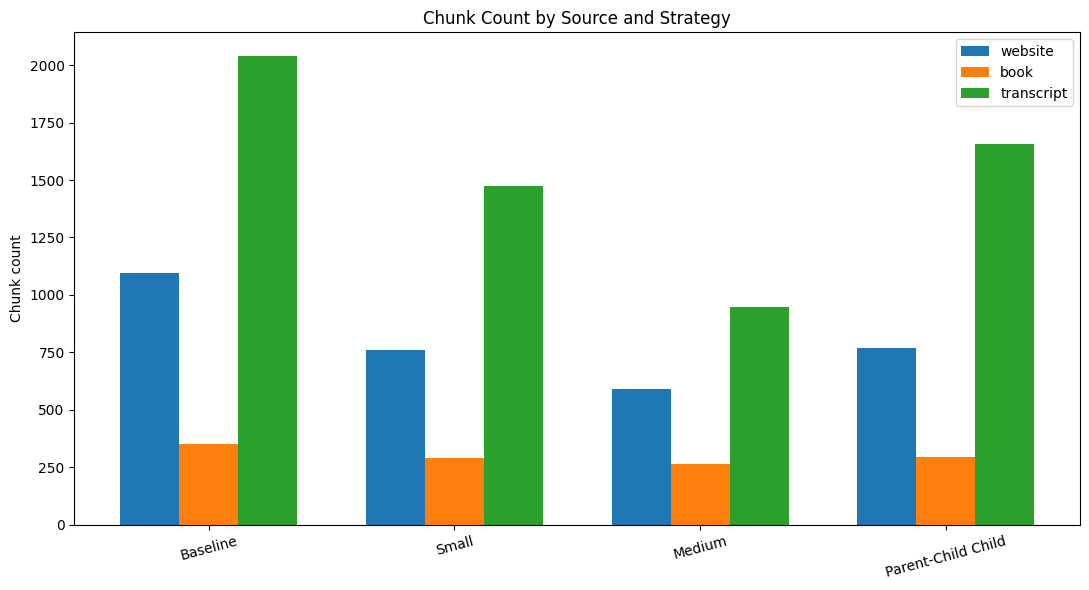

FIGURE 2 — TOKEN DISTRIBUTION


/var/folders/c6/kh1v5smn18l3tbcsjpvvqv1h0000gn/T/ipykernel_66125/3313037729.py:308: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


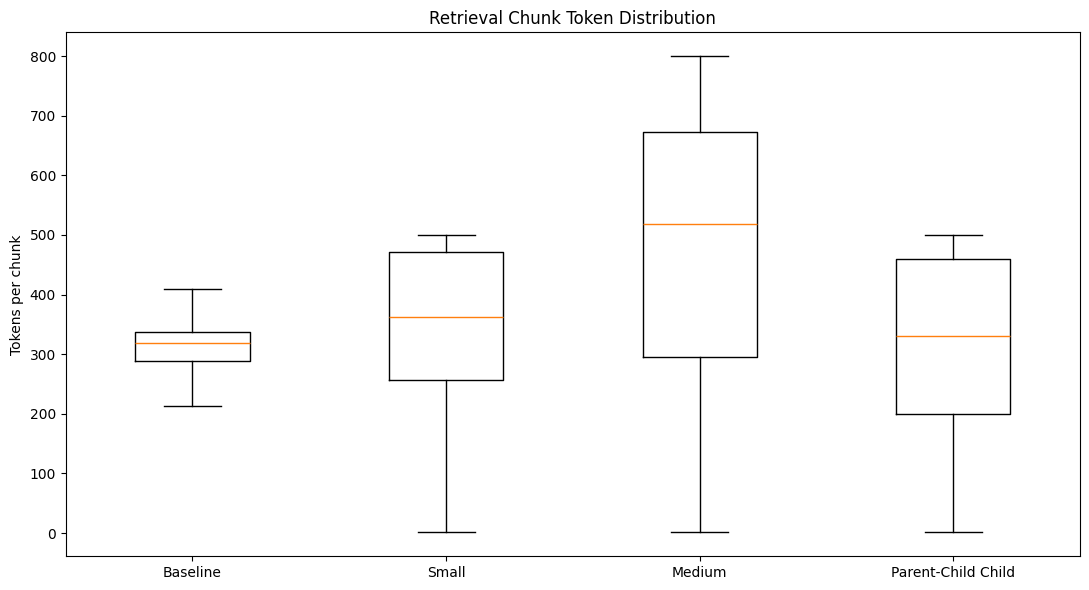

FIGURE 3 — TARGET FIT / TINY RATE


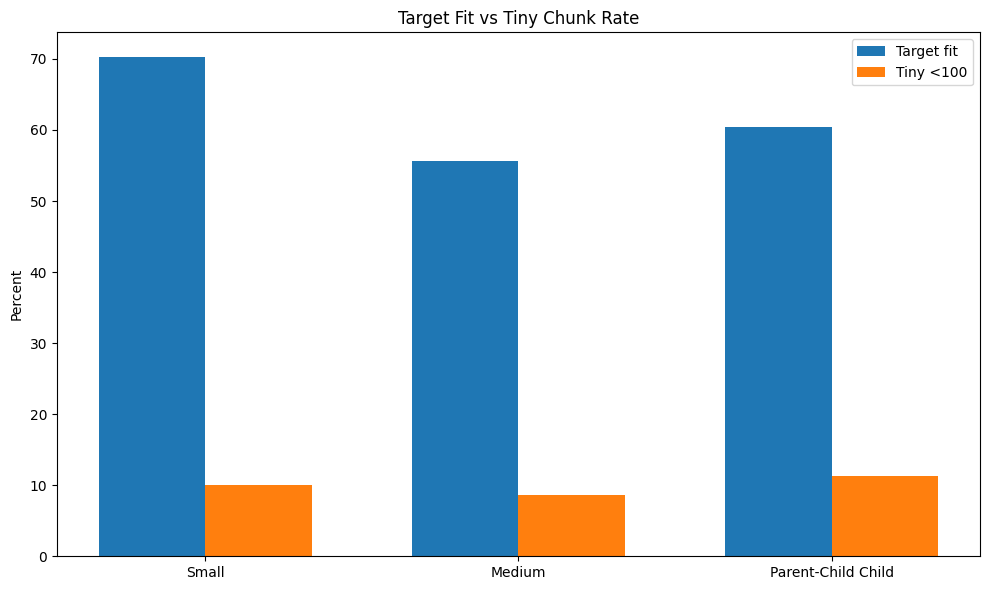

FIGURE 4 — TRANSCRIPT ATTRIBUTION RISK


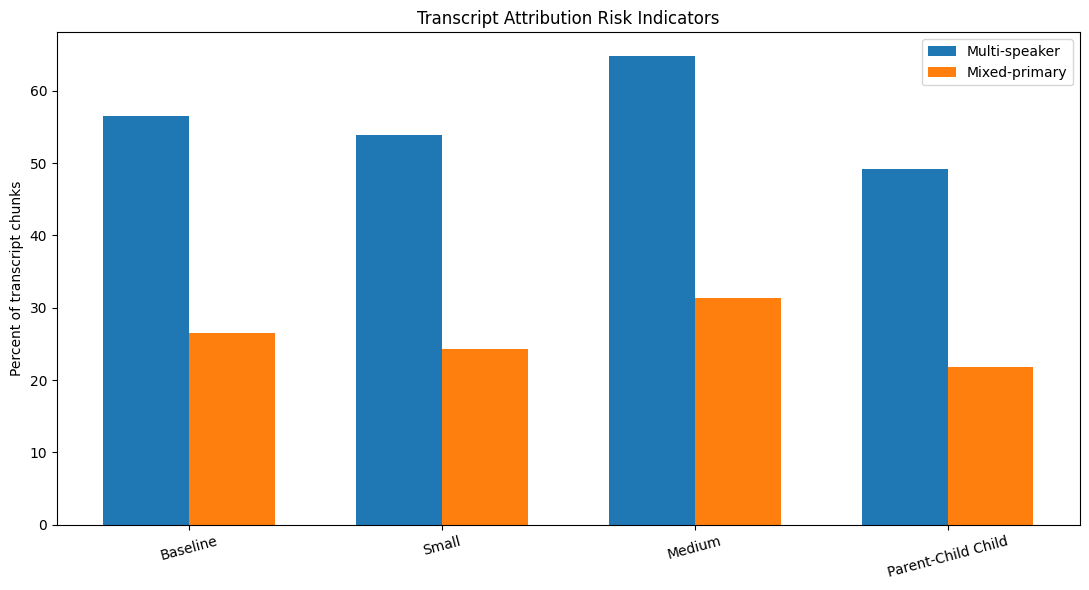

FIGURE 5 — PAYLOAD / STORAGE RATIO


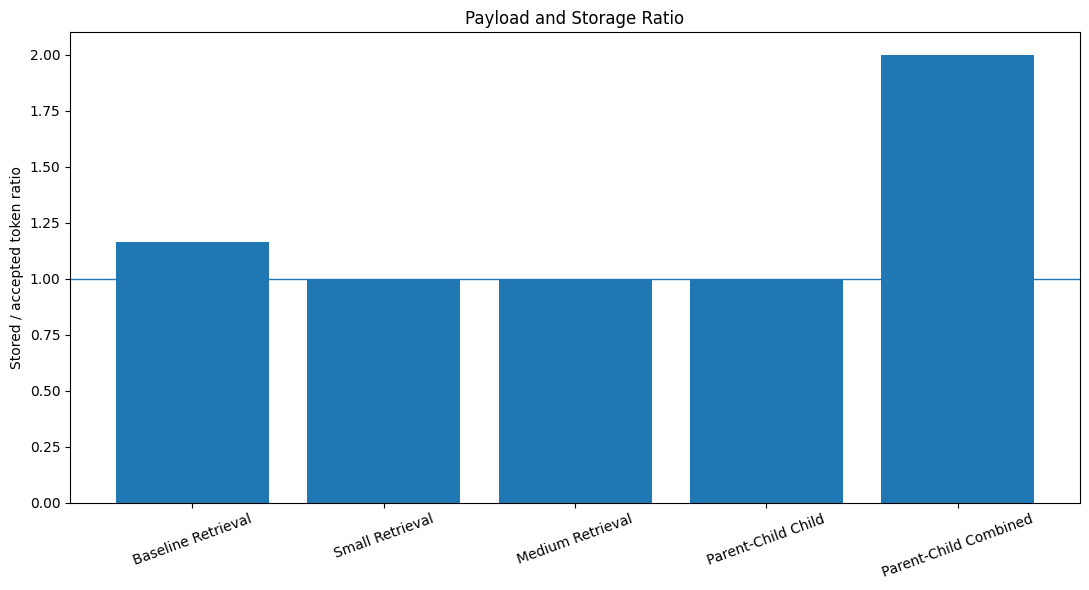

FIGURE 6 — BOOK TINY ROOT CAUSE


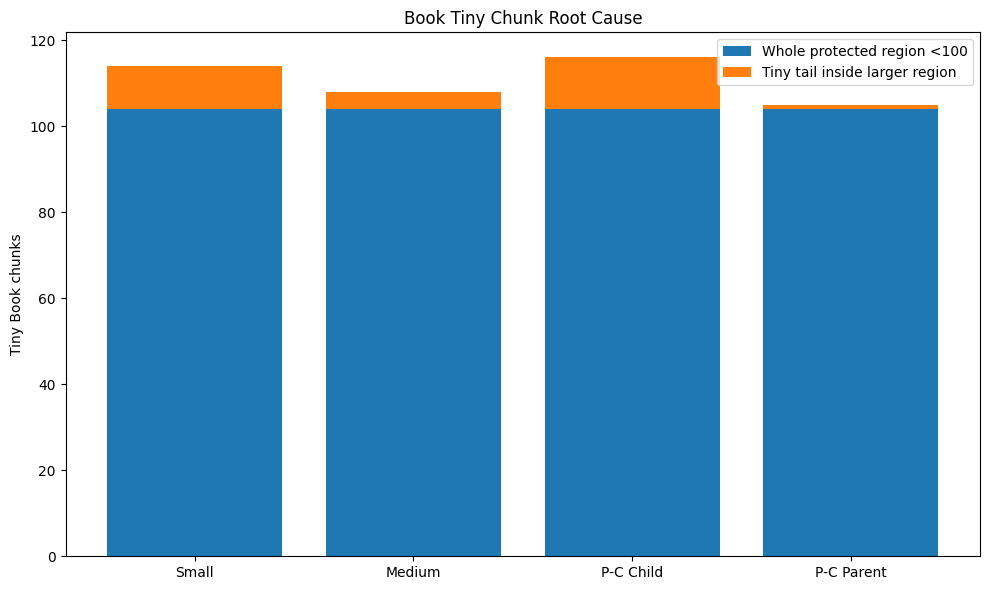

FIGURE 7 — PARENT UNDERFILL ROOT CAUSE


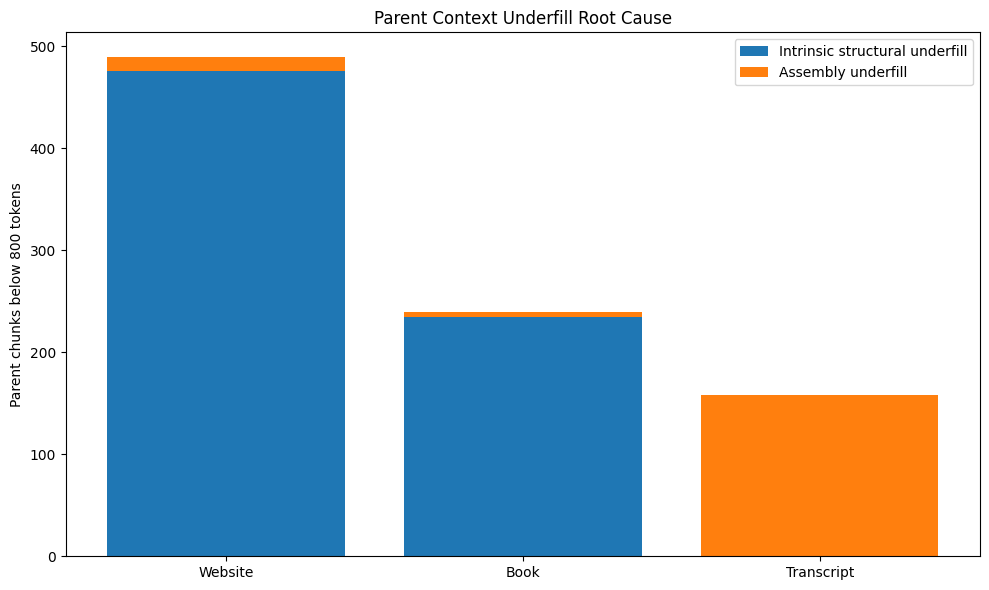

FIGURE 8 — SMALL TO MEDIUM ATTRIBUTION DELTA


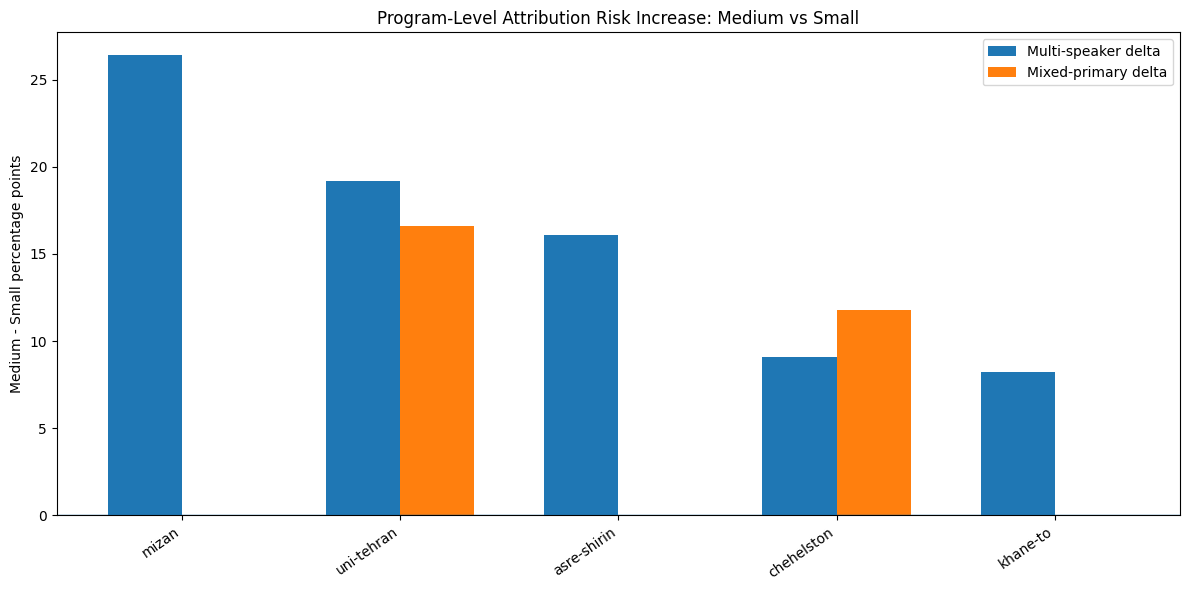


STRUCTURAL FIGURE MANIFEST
- chunk_count_by_source: reports/phase2/chunking/figures/01_chunk_count_by_source_and_strategy.png | bytes=59473 | sha256=ac0b9dfbc90722cb4b9bb6ae8766e9bb1d183a2d9e6d3dd9f4832548ba06c7e5
- token_distribution_by_strategy: reports/phase2/chunking/figures/02_token_distribution_by_strategy.png | bytes=42580 | sha256=3db0a2479b4de385d648fd113e8abcc7c546cccaada524252ba3a9275b2f48a6
- target_fit_and_tiny_rate: reports/phase2/chunking/figures/03_target_fit_and_tiny_rate.png | bytes=35313 | sha256=bbe3fa25d1283694c44bca04a95b2124bc7714fea93881215ca8e650679e0b71
- transcript_attribution_risk: reports/phase2/chunking/figures/04_transcript_attribution_risk.png | bytes=56884 | sha256=974f695f9856b90134990bb1f657e456abdc468491d38e83511ee2f21b52231e
- payload_ratio: reports/phase2/chunking/figures/05_payload_and_storage_ratio.png | bytes=74799 | sha256=7772c6b336c8737b77d19a7ea3a018560d75eea4a89a514f5227b82f8ae99341
- book_tiny_root_cause: reports/phase2/chunking/figures/0

In [24]:
# Code Cell 24

# Temporary local import by current notebook development policy.
# It will be consolidated into Code Cell 01 during final cleanup.
import matplotlib.pyplot as plt


STRUCTURAL_VISUALIZATION_POLICY_V1 = {
    "status":
        "STRUCTURAL_VISUALS_GENERATED_RETRIEVAL_VISUALS_DEFERRED",

    "measured_only":
        True,

    "retrieval_metrics": {
        "Recall@k":
            "NOT_MEASURED",

        "MRR":
            "NOT_MEASURED",

        "nDCG":
            "NOT_MEASURED",
    },

    "modify_evaluation_freeze_manifest":
        False,

    "production_strategy_selected":
        False,
}


# ============================================================
# Output directory
# ============================================================

NB11_FIGURE_DIR = (
    repo_root
    / "reports"
    / "phase2"
    / "chunking"
    / "figures"
)


NB11_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print("=" * 72)
print("NB11 STRUCTURAL VISUALIZATION")
print("=" * 72)

print(
    "Figure directory:",
    NB11_FIGURE_DIR,
)

print(
    "Production strategy selected:",
    STRUCTURAL_VISUALIZATION_POLICY_V1[
        "production_strategy_selected"
    ],
)


# ============================================================
# Common helpers
# ============================================================

FIGURE_MANIFEST = {}


def save_figure(
    figure_id,
    filename,
):
    path = (
        NB11_FIGURE_DIR
        / filename
    )

    plt.tight_layout()

    plt.savefig(
        path,
        dpi=160,
        bbox_inches="tight",
    )

    plt.show()

    plt.close()


    FIGURE_MANIFEST[
        figure_id
    ] = {
        "path":
            str(
                path.relative_to(
                    repo_root
                )
            ),

        "sha256":
            sha256_file(
                path
            ),

        "bytes":
            path.stat().st_size,
    }


    return path


def percent_value(
    value,
):
    return (
        value
        * 100
    )


# ============================================================
# Stable display order
# ============================================================

STRATEGY_DISPLAY_ORDER = [
    "baseline_phase1_char_safe",
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child_child",
]


STRATEGY_LABELS = {
    "baseline_phase1_char_safe":
        "Baseline",

    "structure_aware_small":
        "Small",

    "structure_aware_medium":
        "Medium",

    "parent_child_child":
        "Parent-Child Child",
}


SOURCE_DISPLAY_ORDER = [
    "website",
    "book",
    "transcript",
]


# ============================================================
# Figure 1
# Chunk Count by Source and Strategy
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "FIGURE 1 — CHUNK COUNT BY SOURCE"
)

print(
    "=" * 72
)


x = list(
    range(
        len(
            STRATEGY_DISPLAY_ORDER
        )
    )
)


bar_width = 0.24


plt.figure(
    figsize=(11, 6)
)


for source_index, source_type in enumerate(
    SOURCE_DISPLAY_ORDER
):
    values = [
        CANDIDATE_BENCHMARK_PROFILES[
            strategy_id
        ][
            "source_chunk_counts"
        ].get(
            source_type,
            0,
        )

        for strategy_id
        in STRATEGY_DISPLAY_ORDER
    ]


    positions = [
        value
        + (
            source_index
            - 1
        )
        * bar_width

        for value
        in x
    ]


    plt.bar(
        positions,
        values,
        width=bar_width,
        label=source_type,
    )


plt.xticks(
    x,
    [
        STRATEGY_LABELS[
            strategy_id
        ]
        for strategy_id
        in STRATEGY_DISPLAY_ORDER
    ],
    rotation=15,
)


plt.ylabel(
    "Chunk count"
)

plt.title(
    "Chunk Count by Source and Strategy"
)

plt.legend()


save_figure(
    "chunk_count_by_source",
    "01_chunk_count_by_source_and_strategy.png",
)


# ============================================================
# Figure 2
# Token Distribution
# ============================================================

print(
    "FIGURE 2 — TOKEN DISTRIBUTION"
)


token_distribution_data = [
    [
        chunk[
            "token_count"
        ]
        for chunk
        in CANDIDATE_CHUNKS_IN_MEMORY[
            (
                "parent_child"
                if strategy_id
                == "parent_child_child"
                else strategy_id
            )
        ][
            "retrieval_chunks"
        ]
    ]

    for strategy_id
    in STRATEGY_DISPLAY_ORDER
]


plt.figure(
    figsize=(11, 6)
)


plt.boxplot(
    token_distribution_data,
    labels=[
        STRATEGY_LABELS[
            strategy_id
        ]
        for strategy_id
        in STRATEGY_DISPLAY_ORDER
    ],
    showfliers=False,
)


plt.ylabel(
    "Tokens per chunk"
)

plt.title(
    "Retrieval Chunk Token Distribution"
)


save_figure(
    "token_distribution_by_strategy",
    "02_token_distribution_by_strategy.png",
)


# ============================================================
# Figure 3
# Target Fit and Tiny Chunk Rate
# ============================================================

print(
    "FIGURE 3 — TARGET FIT / TINY RATE"
)


target_strategy_ids = [
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child_child",
]


target_labels = [
    "Small",
    "Medium",
    "Parent-Child Child",
]


target_fit_rates = [
    percent_value(
        CANDIDATE_BENCHMARK_PROFILES[
            strategy_id
        ][
            "target_fit_rate"
        ]
    )
    for strategy_id
    in target_strategy_ids
]


tiny_rates = [
    percent_value(
        CANDIDATE_BENCHMARK_PROFILES[
            strategy_id
        ][
            "tiny_chunk_rate"
        ]
    )
    for strategy_id
    in target_strategy_ids
]


x = list(
    range(
        len(
            target_strategy_ids
        )
    )
)


bar_width = 0.34


plt.figure(
    figsize=(10, 6)
)


plt.bar(
    [
        value
        - bar_width / 2
        for value
        in x
    ],
    target_fit_rates,
    width=bar_width,
    label="Target fit",
)


plt.bar(
    [
        value
        + bar_width / 2
        for value
        in x
    ],
    tiny_rates,
    width=bar_width,
    label="Tiny <100",
)


plt.xticks(
    x,
    target_labels,
)


plt.ylabel(
    "Percent"
)

plt.title(
    "Target Fit vs Tiny Chunk Rate"
)

plt.legend()


save_figure(
    "target_fit_and_tiny_rate",
    "03_target_fit_and_tiny_rate.png",
)


# ============================================================
# Figure 4
# Transcript Attribution Risk
# ============================================================

print(
    "FIGURE 4 — TRANSCRIPT ATTRIBUTION RISK"
)


attribution_strategy_ids = [
    "baseline_phase1_char_safe",
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child_child",
]


attribution_labels = [
    STRATEGY_LABELS[
        strategy_id
    ]
    for strategy_id
    in attribution_strategy_ids
]


multi_speaker_rates = [
    percent_value(
        CANDIDATE_BENCHMARK_PROFILES[
            strategy_id
        ][
            "multi_speaker_rate"
        ]
    )
    for strategy_id
    in attribution_strategy_ids
]


mixed_primary_rates = [
    percent_value(
        CANDIDATE_BENCHMARK_PROFILES[
            strategy_id
        ][
            "mixed_primary_signal_rate"
        ]
    )
    for strategy_id
    in attribution_strategy_ids
]


x = list(
    range(
        len(
            attribution_strategy_ids
        )
    )
)


bar_width = 0.34


plt.figure(
    figsize=(11, 6)
)


plt.bar(
    [
        value
        - bar_width / 2
        for value
        in x
    ],
    multi_speaker_rates,
    width=bar_width,
    label="Multi-speaker",
)


plt.bar(
    [
        value
        + bar_width / 2
        for value
        in x
    ],
    mixed_primary_rates,
    width=bar_width,
    label="Mixed-primary",
)


plt.xticks(
    x,
    attribution_labels,
    rotation=15,
)


plt.ylabel(
    "Percent of transcript chunks"
)

plt.title(
    "Transcript Attribution Risk Indicators"
)

plt.legend()


save_figure(
    "transcript_attribution_risk",
    "04_transcript_attribution_risk.png",
)


# ============================================================
# Figure 5
# Payload / Storage Ratio
# ============================================================

print(
    "FIGURE 5 — PAYLOAD / STORAGE RATIO"
)


payload_labels = [
    "Baseline Retrieval",
    "Small Retrieval",
    "Medium Retrieval",
    "Parent-Child Child",
    "Parent-Child Combined",
]


payload_ratios = [
    baseline_profile[
        "payload_ratio_vs_accepted_tokens"
    ],

    small_profile[
        "payload_ratio_vs_accepted_tokens"
    ],

    medium_profile[
        "payload_ratio_vs_accepted_tokens"
    ],

    parent_child_profile[
        "payload_ratio_vs_accepted_tokens"
    ],

    parent_child_duplication_ratio,
]


plt.figure(
    figsize=(11, 6)
)


plt.bar(
    payload_labels,
    payload_ratios,
)


plt.axhline(
    y=1.0,
    linewidth=1,
)


plt.ylabel(
    "Stored / accepted token ratio"
)

plt.title(
    "Payload and Storage Ratio"
)

plt.xticks(
    rotation=20,
)


save_figure(
    "payload_ratio",
    "05_payload_and_storage_ratio.png",
)


# ============================================================
# Figure 6
# Book Tiny Root Cause
# ============================================================

print(
    "FIGURE 6 — BOOK TINY ROOT CAUSE"
)


book_strategy_ids = [
    "structure_aware_small",
    "structure_aware_medium",
    "parent_child_child",
    "parent_child_parent",
]


book_labels = [
    "Small",
    "Medium",
    "P-C Child",
    "P-C Parent",
]


book_intrinsic_tiny = [
    BOOK_TINY_REGION_DIAGNOSIS[
        strategy_id
    ].get(
        "whole_region_under_100",
        0,
    )
    for strategy_id
    in book_strategy_ids
]


book_assembly_tiny = [
    BOOK_TINY_REGION_DIAGNOSIS[
        strategy_id
    ].get(
        "tiny_chunk_inside_larger_region",
        0,
    )
    for strategy_id
    in book_strategy_ids
]


plt.figure(
    figsize=(10, 6)
)


plt.bar(
    book_labels,
    book_intrinsic_tiny,
    label="Whole protected region <100",
)


plt.bar(
    book_labels,
    book_assembly_tiny,
    bottom=book_intrinsic_tiny,
    label="Tiny tail inside larger region",
)


plt.ylabel(
    "Tiny Book chunks"
)

plt.title(
    "Book Tiny Chunk Root Cause"
)

plt.legend()


save_figure(
    "book_tiny_root_cause",
    "06_book_tiny_root_cause.png",
)


# ============================================================
# Figure 7
# Parent Underfill Root Cause by Source
# ============================================================

print(
    "FIGURE 7 — PARENT UNDERFILL ROOT CAUSE"
)


parent_source_labels = [
    "Website",
    "Book",
    "Transcript",
]


parent_intrinsic_values = [
    UNDERFILL_DIAGNOSIS[
        "parent_child_parent"
    ][
        "by_source"
    ][
        source_type
    ][
        "intrinsic_structural_underfill"
    ]
    for source_type
    in SOURCE_DISPLAY_ORDER
]


parent_assembly_values = [
    UNDERFILL_DIAGNOSIS[
        "parent_child_parent"
    ][
        "by_source"
    ][
        source_type
    ][
        "assembly_underfill"
    ]
    for source_type
    in SOURCE_DISPLAY_ORDER
]


plt.figure(
    figsize=(10, 6)
)


plt.bar(
    parent_source_labels,
    parent_intrinsic_values,
    label="Intrinsic structural underfill",
)


plt.bar(
    parent_source_labels,
    parent_assembly_values,
    bottom=parent_intrinsic_values,
    label="Assembly underfill",
)


plt.ylabel(
    "Parent chunks below 800 tokens"
)

plt.title(
    "Parent Context Underfill Root Cause"
)

plt.legend()


save_figure(
    "parent_underfill_root_cause",
    "07_parent_underfill_root_cause.png",
)


# ============================================================
# Figure 8
# Program-level Small -> Medium attribution delta
# ============================================================

print(
    "FIGURE 8 — SMALL TO MEDIUM ATTRIBUTION DELTA"
)


program_delta_rows = []


for program_id, values in (
    SMALL_MEDIUM_ATTRIBUTION_DELTA.items()
):
    max_positive_delta = max(
        values[
            "multi_speaker_delta"
        ],
        values[
            "mixed_primary_delta"
        ],
    )


    if (
        max_positive_delta
        <= 0
    ):
        continue


    program_delta_rows.append(
        (
            program_id,
            values[
                "multi_speaker_delta"
            ]
            * 100,
            values[
                "mixed_primary_delta"
            ]
            * 100,
        )
    )


program_delta_rows = sorted(
    program_delta_rows,
    key=lambda row:
        max(
            row[1],
            row[2],
        ),
    reverse=True,
)[:10]


program_labels = [
    row[0].replace(
        "program:",
        "",
    )
    for row
    in program_delta_rows
]


program_multi_deltas = [
    row[1]
    for row
    in program_delta_rows
]


program_mixed_deltas = [
    row[2]
    for row
    in program_delta_rows
]


x = list(
    range(
        len(
            program_delta_rows
        )
    )
)


bar_width = 0.34


plt.figure(
    figsize=(12, 6)
)


plt.bar(
    [
        value
        - bar_width / 2
        for value
        in x
    ],
    program_multi_deltas,
    width=bar_width,
    label="Multi-speaker delta",
)


plt.bar(
    [
        value
        + bar_width / 2
        for value
        in x
    ],
    program_mixed_deltas,
    width=bar_width,
    label="Mixed-primary delta",
)


plt.axhline(
    y=0,
    linewidth=1,
)


plt.xticks(
    x,
    program_labels,
    rotation=35,
    ha="right",
)


plt.ylabel(
    "Medium - Small percentage points"
)

plt.title(
    "Program-Level Attribution Risk Increase: Medium vs Small"
)

plt.legend()


save_figure(
    "small_medium_program_attribution_delta",
    "08_small_medium_program_attribution_delta.png",
)


# ============================================================
# Measured visualization summary
# ============================================================

STRUCTURAL_VISUALIZATION_EVIDENCE_V1 = {
    "status":
        (
            "STRUCTURAL_VISUALS_GENERATED_"
            "RETRIEVAL_VISUALS_DEFERRED"
        ),

    "figure_count":
        len(
            FIGURE_MANIFEST
        ),

    "figures":
        FIGURE_MANIFEST,

    "measured_visualized_dimensions": [
        "chunk_count_by_source",
        "token_distribution",
        "target_fit",
        "tiny_chunk_rate",
        "transcript_multi_speaker_rate",
        "transcript_mixed_primary_rate",
        "payload_ratio",
        "book_tiny_root_cause",
        "parent_underfill_root_cause",
        "program_level_small_medium_attribution_delta",
    ],

    "deferred_dimensions": [
        "Recall@k",
        "MRR",
        "nDCG",
        "citation_correctness",
        "attribution_correctness",
        "context_completeness",
        "unnecessary_context",
        "final_tradeoff_decision_chart",
    ],

    "freeze_manifest_modified":
        False,

    "production_strategy_selected":
        False,

    "final_production_strategy":
        None,
}


# ============================================================
# Save auxiliary visualization manifest
# ============================================================

visualization_manifest_path = (
    NB11_REPORT_DIR
    / "structural_visualization_evidence_v1.json"
)


visualization_manifest_write = (
    write_json_artifact(
        visualization_manifest_path,
        STRUCTURAL_VISUALIZATION_EVIDENCE_V1,
    )
)


with visualization_manifest_path.open(
    "r",
    encoding="utf-8",
) as handle:

    visualization_manifest_disk = (
        json.load(
            handle
        )
    )


visualization_manifest_payload_gate = (
    visualization_manifest_disk
    == to_builtin_json(
        STRUCTURAL_VISUALIZATION_EVIDENCE_V1
    )
)


visualization_manifest_hash_gate = (
    sha256_file(
        visualization_manifest_path
    )
    == visualization_manifest_write[
        "sha256"
    ]
)


# ============================================================
# Figure existence / hash validation
# ============================================================

figure_validation_failures = []


for figure_id, metadata in (
    FIGURE_MANIFEST.items()
):

    path = (
        repo_root
        / metadata[
            "path"
        ]
    )


    exists = (
        path.exists()
    )


    hash_match = (
        exists

        and sha256_file(
            path
        )
        == metadata[
            "sha256"
        ]
    )


    nonempty = (
        exists

        and path.stat().st_size
        > 0
    )


    if not (
        exists

        and hash_match

        and nonempty
    ):

        figure_validation_failures.append(
            {
                "figure_id":
                    figure_id,

                "exists":
                    exists,

                "hash_match":
                    hash_match,

                "nonempty":
                    nonempty,
            }
        )


figure_validation_gate = (
    len(
        figure_validation_failures
    )
    == 0
)


figure_count_gate = (
    len(
        FIGURE_MANIFEST
    )
    == 8
)


retrieval_visuals_deferred_gate = (
    all(
        value
        == "NOT_MEASURED"

        for value
        in STRUCTURAL_VISUALIZATION_POLICY_V1[
            "retrieval_metrics"
        ].values()
    )

    and "Recall@k"
    in STRUCTURAL_VISUALIZATION_EVIDENCE_V1[
        "deferred_dimensions"
    ]

    and "MRR"
    in STRUCTURAL_VISUALIZATION_EVIDENCE_V1[
        "deferred_dimensions"
    ]

    and "nDCG"
    in STRUCTURAL_VISUALIZATION_EVIDENCE_V1[
        "deferred_dimensions"
    ]
)


freeze_manifest_untouched_gate = (
    STRUCTURAL_VISUALIZATION_POLICY_V1[
        "modify_evaluation_freeze_manifest"
    ]
    is False
)


no_production_selection_gate = (
    STRUCTURAL_VISUALIZATION_EVIDENCE_V1[
        "production_strategy_selected"
    ]
    is False

    and STRUCTURAL_VISUALIZATION_EVIDENCE_V1[
        "final_production_strategy"
    ]
    is None
)


# ============================================================
# Human-readable figure manifest
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STRUCTURAL FIGURE MANIFEST"
)

print(
    "=" * 72
)


for figure_id, metadata in (
    FIGURE_MANIFEST.items()
):

    print(
        f"- {figure_id}: "
        f"{metadata['path']} | "
        f"bytes={metadata['bytes']} | "
        f"sha256={metadata['sha256']}"
    )


print(
    "\nVisualization evidence report:"
)

print(
    visualization_manifest_write[
        "path"
    ],
)

print(
    "SHA256:",
    visualization_manifest_write[
        "sha256"
    ],
)


# ============================================================
# Final Gate
# ============================================================

final_gate = (
    figure_count_gate

    and figure_validation_gate

    and visualization_manifest_payload_gate

    and visualization_manifest_hash_gate

    and retrieval_visuals_deferred_gate

    and freeze_manifest_untouched_gate

    and no_production_selection_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 24 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Eight structural figures generated:",
    "PASS"
    if figure_count_gate
    else "FAIL",
)

print(
    "Figure existence/hash validation:",
    "PASS"
    if figure_validation_gate
    else "FAIL",
)

print(
    "Visualization report reread:",
    "PASS"
    if visualization_manifest_payload_gate
    else "FAIL",
)

print(
    "Visualization report hash:",
    "PASS"
    if visualization_manifest_hash_gate
    else "FAIL",
)

print(
    "Unmeasured retrieval visuals deferred:",
    "PASS"
    if retrieval_visuals_deferred_gate
    else "FAIL",
)

print(
    "Evaluation freeze manifest untouched:",
    "PASS"
    if freeze_manifest_untouched_gate
    else "FAIL",
)

print(
    "No production strategy selected:",
    "PASS"
    if no_production_selection_gate
    else "FAIL",
)


print(
    "\nCODE CELL 24 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "NB11 structural visualization failed. "
    "Do not proceed to final notebook cleanup until "
    "all measured structural figures and their evidence manifest PASS."
)


print(
    "NB11 structural visualization completed."
)

print(
    "Eight measured structural/attribution figures were generated."
)

print(
    "Retrieval-quality charts remain deferred because "
    "Recall@k, MRR, and nDCG are not yet measured."
)

print(
    "The FROZEN_FOR_EVALUATION candidate manifest was not modified."
)

print(
    "No final production chunking strategy has been selected."
)

<div style="direction: rtl; white-space: normal; line-height: 1.7;">

<h3>Final Cleanup and Reproducibility Readiness</h3>

<p>
تحلیل، Candidate Generation، Benchmark، Reconstruction،
Root-Cause Analysis، Evaluation Freeze و Structural Visualization
همگی تکمیل شده‌اند.
</p>

<p>
پیش از Restart Kernel و Run All،
این مرحله وضعیت نهایی Notebook را از نظر Dependency،
Artifact، Freeze Semantics و Handoff بررسی می‌کند.
</p>

<h4>هدف</h4>

<ul>
<li>تأیید Importهای مرکزی مورد نیاز Notebook.</li>
<li>تأیید وجود Candidateهای Frozen for Evaluation.</li>
<li>تأیید Hash و Manifest اصلی Evaluation Freeze.</li>
<li>تأیید وجود هشت نمودار Structural.</li>
<li>تأیید اینکه Production Winner هنوز انتخاب نشده است.</li>
<li>تأیید اینکه Retrieval Metricهای اندازه‌گیری‌نشده جعل نشده‌اند.</li>
<li>آمادگی برای Restart Kernel → Run All.</li>
</ul>

<h4>مفهوم Freeze</h4>

<p>
وضعیت فعلی همچنان:
</p>

<p><code>FROZEN_FOR_EVALUATION</code></p>

<p>
است، نه Production Freeze.
</p>

<p>
Candidateها ثابت شده‌اند تا NB12 و Evaluationهای بعدی
دقیقاً روی همان Chunkهایی اجرا شوند که در NB11 Benchmark شدند.
</p>

<h4>Selection</h4>

<p>
Strategy نهایی فقط پس از Golden Dataset، Retrieval،
Citation، Attribution و Context Evaluation قابل انتخاب است.
</p>

</div>

In [30]:
# Code Cell 25

FINAL_CLEANUP_POLICY_V1 = {
    "status":
        "READY_FOR_RESTART_RUN_ALL_VALIDATION",

    "central_imports_expected": [
        "Path",
        "Counter",
        "hashlib",
        "json",
        "re",
        "subprocess",
        "sys",
        "plt",
        "AutoTokenizer",
    ],

    "evaluation_freeze_required":
        True,

    "production_strategy_must_remain_unselected":
        True,

    "retrieval_metrics_must_remain_unmeasured":
        True,

    "next_step":
        "RESTART_KERNEL_RUN_ALL",
}


# ============================================================
# Central import readiness
# ============================================================

print("=" * 72)
print("FINAL IMPORT READINESS")
print("=" * 72)


required_symbol_checks = {
    "Path":
        "Path" in globals(),

    "Counter":
        "Counter" in globals(),

    "hashlib":
        "hashlib" in globals(),

    "json":
        "json" in globals(),

    "re":
        "re" in globals(),

    "subprocess":
        "subprocess" in globals(),

    "sys":
        "sys" in globals(),

    "plt":
        "plt" in globals(),

    "AutoTokenizer":
        "AutoTokenizer" in globals(),
}


for symbol, available in (
    required_symbol_checks.items()
):
    print(
        f"- {symbol}:",
        "PASS"
        if available
        else "FAIL",
    )


central_import_gate = all(
    required_symbol_checks.values()
)


print(
    "\nCentral import readiness:",
    "PASS"
    if central_import_gate
    else "FAIL",
)


# ============================================================
# Candidate Freeze artifact inventory
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "FROZEN CANDIDATE ARTIFACT READINESS"
)

print(
    "=" * 72
)


EXPECTED_FROZEN_CANDIDATES = {
    "baseline_phase1_char_safe": {
        "path":
            (
                NB11_CHUNK_ARTIFACT_DIR
                / "baseline_phase1_char_safe_v1.jsonl"
            ),

        "records":
            3488,
    },

    "structure_aware_small": {
        "path":
            (
                NB11_CHUNK_ARTIFACT_DIR
                / "structure_aware_small_v1.jsonl"
            ),

        "records":
            2526,
    },

    "structure_aware_medium": {
        "path":
            (
                NB11_CHUNK_ARTIFACT_DIR
                / "structure_aware_medium_v1.jsonl"
            ),

        "records":
            1799,
    },

    "parent_child_children": {
        "path":
            (
                NB11_CHUNK_ARTIFACT_DIR
                / "parent_child_children_v1.jsonl"
            ),

        "records":
            2721,
    },

    "parent_child_parents": {
        "path":
            (
                NB11_CHUNK_ARTIFACT_DIR
                / "parent_child_parents_v1.jsonl"
            ),

        "records":
            1447,
    },
}


candidate_readiness_failures = []


for candidate_id, metadata in (
    EXPECTED_FROZEN_CANDIDATES.items()
):
    path = (
        metadata[
            "path"
        ]
    )

    exists = (
        path.exists()
    )

    record_count = 0


    if exists:

        with path.open(
            "r",
            encoding="utf-8",
        ) as handle:

            record_count = sum(
                1
                for line
                in handle
                if line.strip()
            )


    count_match = (
        record_count
        == metadata[
            "records"
        ]
    )


    print(
        f"- {candidate_id}: "
        f"exists={exists} | "
        f"records={record_count} | "
        f"expected={metadata['records']} | "
        f"count_match={count_match}"
    )


    if not (
        exists
        and count_match
    ):

        candidate_readiness_failures.append(
            {
                "candidate_id":
                    candidate_id,

                "exists":
                    exists,

                "record_count":
                    record_count,

                "expected":
                    metadata[
                        "records"
                    ],
            }
        )


candidate_artifact_gate = (
    len(
        candidate_readiness_failures
    )
    == 0
)


print(
    "\nFrozen candidate artifacts:",
    "PASS"
    if candidate_artifact_gate
    else "FAIL",
)


# ============================================================
# Evaluation Freeze Manifest readiness
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "EVALUATION FREEZE MANIFEST READINESS"
)

print(
    "=" * 72
)


evaluation_manifest_path = (
    NB11_REPORT_DIR
    / "evaluation_freeze_manifest_v1.json"
)


evaluation_manifest_exists = (
    evaluation_manifest_path.exists()
)


if evaluation_manifest_exists:

    with evaluation_manifest_path.open(
        "r",
        encoding="utf-8",
    ) as handle:

        evaluation_manifest_disk = (
            json.load(
                handle
            )
        )

else:

    evaluation_manifest_disk = {}


manifest_status_gate = (
    evaluation_manifest_exists

    and evaluation_manifest_disk.get(
        "status"
    )
    == "FROZEN_FOR_EVALUATION"
)


manifest_not_production_gate = (
    evaluation_manifest_disk.get(
        "not_production_selection"
    )
    is True

    and evaluation_manifest_disk.get(
        "final_production_strategy"
    )
    is None
)


manifest_corpus_gate = (
    (
        evaluation_manifest_disk.get(
            "accepted_corpus"
        )
        or {}
    ).get(
        "records"
    )
    == EXPECTED_CORPUS_RECORDS

    and (
        evaluation_manifest_disk.get(
            "accepted_corpus"
        )
        or {}
    ).get(
        "sha256"
    )
    == EXPECTED_CORPUS_SHA256
)


manifest_actual_sha256 = (
    sha256_file(
        evaluation_manifest_path
    )
    if evaluation_manifest_exists
    else None
)


print(
    "Manifest exists:",
    "PASS"
    if evaluation_manifest_exists
    else "FAIL",
)

print(
    "Manifest status:",
    "PASS"
    if manifest_status_gate
    else "FAIL",
)

print(
    "Manifest is evaluation-only:",
    "PASS"
    if manifest_not_production_gate
    else "FAIL",
)

print(
    "Manifest accepted-corpus identity:",
    "PASS"
    if manifest_corpus_gate
    else "FAIL",
)

print(
    "Manifest SHA256:",
    manifest_actual_sha256,
)


evaluation_manifest_gate = (
    manifest_status_gate
    and manifest_not_production_gate
    and manifest_corpus_gate
)


# ============================================================
# Structural visualization readiness
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STRUCTURAL VISUALIZATION READINESS"
)

print(
    "=" * 72
)


visualization_report_path = (
    NB11_REPORT_DIR
    / "structural_visualization_evidence_v1.json"
)


visualization_report_exists = (
    visualization_report_path.exists()
)


if visualization_report_exists:

    with visualization_report_path.open(
        "r",
        encoding="utf-8",
    ) as handle:

        visualization_report_disk = (
            json.load(
                handle
            )
        )

else:

    visualization_report_disk = {}


figure_manifest_disk = (
    visualization_report_disk.get(
        "figures"
    )
    or {}
)


figure_failures = []


for figure_id, metadata in (
    figure_manifest_disk.items()
):

    figure_path = (
        repo_root
        / metadata[
            "path"
        ]
    )


    exists = (
        figure_path.exists()
    )


    hash_match = (
        exists

        and sha256_file(
            figure_path
        )
        == metadata[
            "sha256"
        ]
    )


    if not (
        exists
        and hash_match
    ):

        figure_failures.append(
            {
                "figure_id":
                    figure_id,

                "exists":
                    exists,

                "hash_match":
                    hash_match,
            }
        )


figure_count_gate = (
    len(
        figure_manifest_disk
    )
    == 8
)


figure_integrity_gate = (
    len(
        figure_failures
    )
    == 0
)


visualization_status_gate = (
    visualization_report_disk.get(
        "status"
    )
    == (
        "STRUCTURAL_VISUALS_GENERATED_"
        "RETRIEVAL_VISUALS_DEFERRED"
    )
)


print(
    "Visualization report exists:",
    "PASS"
    if visualization_report_exists
    else "FAIL",
)

print(
    "Eight structural figures registered:",
    "PASS"
    if figure_count_gate
    else "FAIL",
)

print(
    "Figure hash integrity:",
    "PASS"
    if figure_integrity_gate
    else "FAIL",
)

print(
    "Retrieval visuals deferred:",
    "PASS"
    if visualization_status_gate
    else "FAIL",
)


visualization_gate = (
    visualization_report_exists
    and figure_count_gate
    and figure_integrity_gate
    and visualization_status_gate
)


# ============================================================
# Selection semantics
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "FINAL-SELECTION SEMANTIC READINESS"
)

print(
    "=" * 72
)


production_strategy_gate = (
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "final_production_strategy"
    ]
    is None

    and FINAL_CHUNK_SELECTION_REQUIREMENTS_V1[
        "final_selection"
    ]
    == "NOT_YET"

    and evaluation_manifest_disk.get(
        "final_production_strategy"
    )
    is None
)


small_candidate_semantic_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "structure_aware_small"
    ][
        "status"
    ]
    == "PRIMARY_RETRIEVAL_SHORTLIST"

    and STRUCTURAL_SHORTLIST_V1[
        "structure_aware_small"
    ][
        "final_selection"
    ]
    is False
)


baseline_semantic_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "baseline_phase1_char_safe"
    ][
        "status"
    ]
    == "REJECTED_AS_PRODUCTION_DEFAULT"
)


medium_semantic_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "structure_aware_medium"
    ][
        "status"
    ]
    == "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN"
)


parent_child_semantic_gate = (
    STRUCTURAL_SHORTLIST_V1[
        "parent_child"
    ][
        "status"
    ]
    == "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST"
)


print(
    "Final production strategy remains None:",
    "PASS"
    if production_strategy_gate
    else "FAIL",
)

print(
    "Small remains leading candidate, not winner:",
    "PASS"
    if small_candidate_semantic_gate
    else "FAIL",
)

print(
    "Baseline remains historical comparison:",
    "PASS"
    if baseline_semantic_gate
    else "FAIL",
)

print(
    "Medium remains retrieval ablation:",
    "PASS"
    if medium_semantic_gate
    else "FAIL",
)

print(
    "Parent-Child remains conditional architecture:",
    "PASS"
    if parent_child_semantic_gate
    else "FAIL",
)


selection_semantics_gate = (
    production_strategy_gate
    and small_candidate_semantic_gate
    and baseline_semantic_gate
    and medium_semantic_gate
    and parent_child_semantic_gate
)


# ============================================================
# Unmeasured metric integrity
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "UNMEASURED METRIC INTEGRITY"
)

print(
    "=" * 72
)


retrieval_metrics = (
    NB11_CANDIDATE_FREEZE_STATE_V1[
        "retrieval_metrics"
    ]
)


retrieval_metric_gate = all(
    value
    == "NOT_MEASURED"

    for value
    in retrieval_metrics.values()
)


print(
    "Recall@k:",
    retrieval_metrics[
        "Recall@k"
    ],
)

print(
    "MRR:",
    retrieval_metrics[
        "MRR"
    ],
)

print(
    "nDCG:",
    retrieval_metrics[
        "nDCG"
    ],
)


print(
    "No fabricated retrieval metrics:",
    "PASS"
    if retrieval_metric_gate
    else "FAIL",
)


# ============================================================
# NB12 Handoff readiness
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "NB12 HANDOFF READINESS"
)

print(
    "=" * 72
)


nb12_handoff_path = (
    NB11_REPORT_DIR
    / "nb12_golden_dataset_handoff_v1.json"
)


nb12_handoff_exists = (
    nb12_handoff_path.exists()
)


if nb12_handoff_exists:

    with nb12_handoff_path.open(
        "r",
        encoding="utf-8",
    ) as handle:

        nb12_handoff_disk = (
            json.load(
                handle
            )
        )

else:

    nb12_handoff_disk = {}


nb12_handoff_status_gate = (
    nb12_handoff_disk.get(
        "status"
    )
    == "REQUIRED_FOR_FINAL_CHUNK_DECISION"
)


nb12_source_coverage_gate = all(
    len(
        nb12_handoff_disk.get(
            source_type,
            [],
        )
    )
    > 0

    for source_type
    in [
        "website",
        "book",
        "transcript",
    ]
)


nb12_strategy_coverage_gate = (
    set(
        nb12_handoff_disk.get(
            "candidate_strategies_to_compare",
            [],
        )
    )
    == {
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child_child",
    }
)


nb12_handoff_gate = (
    nb12_handoff_exists
    and nb12_handoff_status_gate
    and nb12_source_coverage_gate
    and nb12_strategy_coverage_gate
)


print(
    "NB12 handoff file:",
    "PASS"
    if nb12_handoff_exists
    else "FAIL",
)

print(
    "NB12 handoff status:",
    "PASS"
    if nb12_handoff_status_gate
    else "FAIL",
)

print(
    "Website / Book / Transcript failure modes included:",
    "PASS"
    if nb12_source_coverage_gate
    else "FAIL",
)

print(
    "All retrieval candidates included:",
    "PASS"
    if nb12_strategy_coverage_gate
    else "FAIL",
)


# ============================================================
# Restart / Run All readiness record
# ============================================================

NB11_RESTART_RUN_ALL_READINESS_V1 = {
    "status":
        "READY_FOR_RESTART_RUN_ALL",

    "central_imports":
        required_symbol_checks,

    "candidate_artifacts":
        "PASS"
        if candidate_artifact_gate
        else "FAIL",

    "evaluation_manifest":
        "PASS"
        if evaluation_manifest_gate
        else "FAIL",

    "visualizations":
        "PASS"
        if visualization_gate
        else "FAIL",

    "selection_semantics":
        "PASS"
        if selection_semantics_gate
        else "FAIL",

    "retrieval_metrics":
        "NOT_MEASURED",

    "nb12_handoff":
        "PASS"
        if nb12_handoff_gate
        else "FAIL",

    "production_strategy":
        None,

    "next_action":
        "RESTART_KERNEL_THEN_RUN_ALL",
}


# ============================================================
# Final gate
# ============================================================

final_gate = (
    central_import_gate

    and candidate_artifact_gate

    and evaluation_manifest_gate

    and visualization_gate

    and selection_semantics_gate

    and retrieval_metric_gate

    and nb12_handoff_gate
)


print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL 25 FINAL GATE"
)

print(
    "=" * 72
)


print(
    "Central imports:",
    "PASS"
    if central_import_gate
    else "FAIL",
)

print(
    "Frozen candidate artifacts:",
    "PASS"
    if candidate_artifact_gate
    else "FAIL",
)

print(
    "Evaluation freeze manifest:",
    "PASS"
    if evaluation_manifest_gate
    else "FAIL",
)

print(
    "Structural visualizations:",
    "PASS"
    if visualization_gate
    else "FAIL",
)

print(
    "Production-selection semantics:",
    "PASS"
    if selection_semantics_gate
    else "FAIL",
)

print(
    "Unmeasured retrieval metrics preserved:",
    "PASS"
    if retrieval_metric_gate
    else "FAIL",
)

print(
    "NB12 handoff:",
    "PASS"
    if nb12_handoff_gate
    else "FAIL",
)


print(
    "\nCODE CELL 25 GATE:",
    "PASS"
    if final_gate
    else "FAIL",
)


assert final_gate, (
    "NB11 final cleanup/readiness failed. "
    "Do not Restart Kernel / Run All until imports, frozen artifacts, "
    "visualizations, selection semantics, and NB12 handoff all PASS."
)


print(
    "NB11 is ready for Restart Kernel -> Run All."
)

print(
    "All benchmark candidates remain FROZEN_FOR_EVALUATION."
)

print(
    "No final production chunking strategy has been selected."
)

print(
    "After Run All succeeds, execute the permanent notebook Health Check."
)

FINAL IMPORT READINESS
- Path: PASS
- Counter: PASS
- hashlib: PASS
- json: PASS
- re: PASS
- subprocess: PASS
- sys: PASS
- plt: PASS
- AutoTokenizer: PASS

Central import readiness: PASS

FROZEN CANDIDATE ARTIFACT READINESS
- baseline_phase1_char_safe: exists=True | records=3488 | expected=3488 | count_match=True
- structure_aware_small: exists=True | records=2526 | expected=2526 | count_match=True
- structure_aware_medium: exists=True | records=1799 | expected=1799 | count_match=True
- parent_child_children: exists=True | records=2721 | expected=2721 | count_match=True
- parent_child_parents: exists=True | records=1447 | expected=1447 | count_match=True

Frozen candidate artifacts: PASS

EVALUATION FREEZE MANIFEST READINESS
Manifest exists: PASS
Manifest status: PASS
Manifest is evaluation-only: PASS
Manifest accepted-corpus identity: PASS
Manifest SHA256: c29c4f1840e1fbd313c4f27b3556ff84f2041cce86ba0d5e27ff278c450106cc

STRUCTURAL VISUALIZATION READINESS
Visualization report exists

In [33]:
# Code Cell 26

NB11_FINAL_HEALTH_POLICY_V1 = {
    "status": "PERMANENT_NOTEBOOK_HEALTH_CHECK",
    "expected_historical_code_cells": 25,
    "live_health_cell_number": 26,
    "final_total_code_cells": 26,
    "candidate_freeze_status": "FROZEN_FOR_EVALUATION",
    "final_production_strategy": None,
    "required_structural_figures": 8,
    "next_notebook": "12_golden_dataset.ipynb",
}


print("=" * 72)
print("NB11 PERMANENT FINAL HEALTH CHECK")
print("=" * 72)


# ============================================================
# Notebook path / saved-state discovery
# ============================================================

NB11_NOTEBOOK_PATH = (
    repo_root
    / "notebooks"
    / "phase2"
    / "11_chunking_benchmark.ipynb"
)


notebook_exists_gate = (
    NB11_NOTEBOOK_PATH.exists()
)


print(
    "Notebook:",
    NB11_NOTEBOOK_PATH,
)

print(
    "Notebook exists:",
    "PASS"
    if notebook_exists_gate
    else "FAIL",
)


assert notebook_exists_gate


with NB11_NOTEBOOK_PATH.open(
    "r",
    encoding="utf-8",
) as handle:
    notebook_payload = json.load(
        handle
    )


notebook_cells = notebook_payload.get(
    "cells",
    [],
)


saved_code_cells = [
    cell
    for cell
    in notebook_cells
    if cell.get(
        "cell_type"
    )
    == "code"
]


saved_markdown_cells = [
    cell
    for cell
    in notebook_cells
    if cell.get(
        "cell_type"
    )
    == "markdown"
]


saved_code_cell_count = len(
    saved_code_cells
)


print(
    "Total saved notebook cells:",
    len(
        notebook_cells
    ),
)

print(
    "Saved code cells:",
    saved_code_cell_count,
)

print(
    "Saved markdown cells:",
    len(
        saved_markdown_cells
    ),
)


# ============================================================
# Save-state interpretation
#
# Valid states:
#
# 25 saved code cells:
#   Code Cell 26 is currently running but has not yet been
#   persisted into the .ipynb snapshot.
#
# 26 saved code cells:
#   Code Cell 26 is already persisted.
#
# Anything else is a structural failure.
# ============================================================

saved_state_gate = (
    saved_code_cell_count
    in {
        25,
        26,
    }
)


health_cell_persisted = (
    saved_code_cell_count
    == 26
)


health_cell_live_only = (
    saved_code_cell_count
    == 25
)


print(
    "\nSaved-state interpretation:"
)


if health_cell_persisted:
    print(
        "- Code Cell 26 is already persisted in the notebook."
    )

elif health_cell_live_only:
    print(
        "- Code Cells 01-25 are persisted."
    )

    print(
        "- Code Cell 26 is the currently executing live Health Cell."
    )

else:
    print(
        "- Unexpected saved Code Cell count."
    )


print(
    "Saved-state validity:",
    "PASS"
    if saved_state_gate
    else "FAIL",
)


# ============================================================
# Parse saved Code Cell headers
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "CODE CELL NUMBERING AUDIT"
)

print(
    "=" * 72
)


numbering_failures = []

saved_discovered_numbers = []


for position, cell in enumerate(
    saved_code_cells,
    start=1,
):
    source = "".join(
        cell.get(
            "source",
            [],
        )
    )


    nonempty_lines = [
        line.strip()
        for line
        in source.splitlines()
        if line.strip()
    ]


    first_line = (
        nonempty_lines[0]
        if nonempty_lines
        else ""
    )


    match = re.fullmatch(
        r"# Code Cell (\d+)",
        first_line,
    )


    if match is None:
        numbering_failures.append(
            {
                "saved_position": position,
                "reason": "INVALID_CODE_CELL_HEADER",
                "first_line": first_line,
            }
        )

        continue


    saved_discovered_numbers.append(
        int(
            match.group(
                1
            )
        )
    )


saved_header_gate = (
    len(
        numbering_failures
    )
    == 0
)


if saved_code_cell_count == 25:
    expected_saved_numbers = list(
        range(
            1,
            26,
        )
    )

else:
    expected_saved_numbers = list(
        range(
            1,
            27,
        )
    )


saved_numbering_gate = (
    saved_discovered_numbers
    == expected_saved_numbers
)


saved_duplicate_number_gate = (
    len(
        saved_discovered_numbers
    )
    == len(
        set(
            saved_discovered_numbers
        )
    )
)


# The live Cell is explicitly Code Cell 26.
LIVE_HEALTH_CELL_NUMBER = 26


live_health_number_gate = (
    LIVE_HEALTH_CELL_NUMBER
    == NB11_FINAL_HEALTH_POLICY_V1[
        "live_health_cell_number"
    ]
)


final_numbering_gate = (
    saved_state_gate
    and saved_header_gate
    and saved_numbering_gate
    and saved_duplicate_number_gate
    and live_health_number_gate
)


print(
    "Saved valid Code Cell headers:",
    "PASS"
    if saved_header_gate
    else "FAIL",
)

print(
    "Saved numbering sequence:",
    saved_discovered_numbers,
)

print(
    "Saved numbering:",
    "PASS"
    if saved_numbering_gate
    else "FAIL",
)

print(
    "Duplicate saved Code Cell numbers:",
    "NONE"
    if saved_duplicate_number_gate
    else "FOUND",
)

print(
    "Live Health Cell number = 26:",
    "PASS"
    if live_health_number_gate
    else "FAIL",
)

print(
    "Final effective Code Cell sequence 01 -> 26:",
    "PASS"
    if final_numbering_gate
    else "FAIL",
)


if numbering_failures:
    print(
        "\nNumbering failures:"
    )

    for failure in numbering_failures:
        print(
            failure
        )


# ============================================================
# Historical audit scope
#
# Always audit Code Cells 01-25 from saved notebook history.
#
# Never use saved Cell 26 output to determine its own health,
# because that creates a self-referential failure loop.
# ============================================================

historical_code_cells = (
    saved_code_cells[
        :25
    ]
)


historical_scope_gate = (
    len(
        historical_code_cells
    )
    == 25
)


print(
    "\nHistorical audit scope:",
    "Code Cells 01-25",
)

print(
    "Health Cell self-output excluded:",
    "PASS"
    if historical_scope_gate
    else "FAIL",
)


# ============================================================
# Historical execution audit
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "EXECUTION AUDIT"
)

print(
    "=" * 72
)


execution_failures = []


for index, cell in enumerate(
    historical_code_cells,
    start=1,
):
    if (
        cell.get(
            "execution_count"
        )
        is None
    ):
        execution_failures.append(
            {
                "code_cell": index,
                "reason": "NOT_EXECUTED",
            }
        )


historical_execution_gate = (
    len(
        execution_failures
    )
    == 0
)


print(
    "Saved Code Cells 01-25 executed:",
    "PASS"
    if historical_execution_gate
    else "FAIL",
)


if execution_failures:
    for failure in execution_failures:
        print(
            failure
        )


# ============================================================
# Historical saved Error audit
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "ERROR OUTPUT AUDIT"
)

print(
    "=" * 72
)


historical_error_outputs = []


for code_index, cell in enumerate(
    historical_code_cells,
    start=1,
):
    for output in cell.get(
        "outputs",
        [],
    ):
        if (
            output.get(
                "output_type"
            )
            == "error"
        ):
            historical_error_outputs.append(
                {
                    "code_cell": code_index,
                    "ename": output.get(
                        "ename"
                    ),
                    "evalue": output.get(
                        "evalue"
                    ),
                }
            )


no_historical_errors_gate = (
    len(
        historical_error_outputs
    )
    == 0
)


print(
    "Saved Error outputs in Code Cells 01-25:",
    len(
        historical_error_outputs
    ),
)

print(
    "Zero historical execution errors:",
    "PASS"
    if no_historical_errors_gate
    else "FAIL",
)


if historical_error_outputs:
    for error in historical_error_outputs:
        print(
            error
        )


# ============================================================
# Historical explicit FAIL-marker audit
# ============================================================

historical_fail_gate_markers = []


for code_index, cell in enumerate(
    historical_code_cells,
    start=1,
):
    output_text_parts = []


    for output in cell.get(
        "outputs",
        [],
    ):
        output_type = output.get(
            "output_type"
        )


        if output_type == "stream":
            output_text_parts.append(
                "".join(
                    output.get(
                        "text",
                        [],
                    )
                )
            )


        elif output_type in {
            "execute_result",
            "display_data",
        }:
            text_plain = (
                (
                    output.get(
                        "data",
                        {},
                    )
                    or {}
                ).get(
                    "text/plain"
                )
            )


            if text_plain:
                if isinstance(
                    text_plain,
                    list,
                ):
                    output_text_parts.append(
                        "".join(
                            text_plain
                        )
                    )

                else:
                    output_text_parts.append(
                        str(
                            text_plain
                        )
                    )


    output_text = "\n".join(
        output_text_parts
    )


    if re.search(
        r"\bGATE:\s*FAIL\b",
        output_text,
    ):
        historical_fail_gate_markers.append(
            code_index
        )


no_historical_fail_gate = (
    len(
        historical_fail_gate_markers
    )
    == 0
)


print(
    "Saved explicit 'GATE: FAIL' markers in Code Cells 01-25:",
    historical_fail_gate_markers,
)

print(
    "Zero historical failed gates:",
    "PASS"
    if no_historical_fail_gate
    else "FAIL",
)


# ============================================================
# Evaluation Freeze Manifest health
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "EVALUATION FREEZE HEALTH"
)

print(
    "=" * 72
)


freeze_manifest_path = (
    repo_root
    / "reports"
    / "phase2"
    / "chunking"
    / "evaluation_freeze_manifest_v1.json"
)


freeze_manifest_exists_gate = (
    freeze_manifest_path.exists()
)


if freeze_manifest_exists_gate:
    with freeze_manifest_path.open(
        "r",
        encoding="utf-8",
    ) as handle:
        freeze_manifest = json.load(
            handle
        )

else:
    freeze_manifest = {}


freeze_status_gate = (
    freeze_manifest.get(
        "status"
    )
    == "FROZEN_FOR_EVALUATION"
)


freeze_scope_gate = (
    freeze_manifest.get(
        "freeze_scope"
    )
    == "BENCHMARK_CANDIDATES_ONLY"
)


no_final_strategy_gate = (
    freeze_manifest.get(
        "final_production_strategy"
    )
    is None

    and freeze_manifest.get(
        "not_production_selection"
    )
    is True
)


accepted_corpus_health_gate = (
    (
        freeze_manifest.get(
            "accepted_corpus"
        )
        or {}
    ).get(
        "records"
    )
    == EXPECTED_CORPUS_RECORDS

    and (
        freeze_manifest.get(
            "accepted_corpus"
        )
        or {}
    ).get(
        "sha256"
    )
    == EXPECTED_CORPUS_SHA256
)


print(
    "Freeze manifest exists:",
    "PASS"
    if freeze_manifest_exists_gate
    else "FAIL",
)

print(
    "Freeze status:",
    "PASS"
    if freeze_status_gate
    else "FAIL",
)

print(
    "Freeze scope is evaluation candidates only:",
    "PASS"
    if freeze_scope_gate
    else "FAIL",
)

print(
    "Production strategy remains unselected:",
    "PASS"
    if no_final_strategy_gate
    else "FAIL",
)

print(
    "Accepted corpus identity:",
    "PASS"
    if accepted_corpus_health_gate
    else "FAIL",
)


# ============================================================
# Frozen Candidate / Evidence Artifact integrity
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "FROZEN CANDIDATE / EVIDENCE ARTIFACT HEALTH"
)

print(
    "=" * 72
)


manifest_artifacts = (
    freeze_manifest.get(
        "artifacts"
    )
    or {}
)


frozen_artifact_failures = []


for artifact_id, metadata in manifest_artifacts.items():
    relative_path = metadata.get(
        "path"
    )

    expected_hash = metadata.get(
        "sha256"
    )


    if not relative_path:
        frozen_artifact_failures.append(
            {
                "artifact": artifact_id,
                "reason": "MISSING_PATH",
            }
        )

        continue


    artifact_path = (
        repo_root
        / relative_path
    )


    if not artifact_path.exists():
        frozen_artifact_failures.append(
            {
                "artifact": artifact_id,
                "reason": "FILE_NOT_FOUND",
                "path": relative_path,
            }
        )

        continue


    actual_hash = sha256_file(
        artifact_path
    )


    if (
        actual_hash
        != expected_hash
    ):
        frozen_artifact_failures.append(
            {
                "artifact": artifact_id,
                "reason": "SHA256_MISMATCH",
                "expected": expected_hash,
                "actual": actual_hash,
            }
        )


frozen_artifact_gate = (
    len(
        frozen_artifact_failures
    )
    == 0
)


print(
    "Frozen artifacts checked:",
    len(
        manifest_artifacts
    ),
)

print(
    "Artifact/hash failures:",
    len(
        frozen_artifact_failures
    ),
)

print(
    "Frozen artifact integrity:",
    "PASS"
    if frozen_artifact_gate
    else "FAIL",
)


if frozen_artifact_failures:
    for failure in frozen_artifact_failures[
        :20
    ]:
        print(
            failure
        )


# ============================================================
# Candidate Decision State
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "CANDIDATE DECISION STATE"
)

print(
    "=" * 72
)


shortlist = (
    freeze_manifest.get(
        "structural_shortlist"
    )
    or {}
)


baseline_gate = (
    (
        shortlist.get(
            "baseline_phase1_char_safe"
        )
        or {}
    ).get(
        "status"
    )
    == "REJECTED_AS_PRODUCTION_DEFAULT"
)


small_gate = (
    (
        shortlist.get(
            "structure_aware_small"
        )
        or {}
    ).get(
        "status"
    )
    == "PRIMARY_RETRIEVAL_SHORTLIST"

    and (
        shortlist.get(
            "structure_aware_small"
        )
        or {}
    ).get(
        "final_selection"
    )
    is False
)


medium_gate = (
    (
        shortlist.get(
            "structure_aware_medium"
        )
        or {}
    ).get(
        "status"
    )
    == "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN"
)


parent_child_gate = (
    (
        shortlist.get(
            "parent_child"
        )
        or {}
    ).get(
        "status"
    )
    == "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST"
)


candidate_decision_gate = (
    baseline_gate
    and small_gate
    and medium_gate
    and parent_child_gate
)


print(
    "Baseline historical/rejected default:",
    "PASS"
    if baseline_gate
    else "FAIL",
)

print(
    "Small leading candidate, not winner:",
    "PASS"
    if small_gate
    else "FAIL",
)

print(
    "Medium remains ablation:",
    "PASS"
    if medium_gate
    else "FAIL",
)

print(
    "Parent-Child remains conditional:",
    "PASS"
    if parent_child_gate
    else "FAIL",
)


# ============================================================
# Retrieval Metric Integrity
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "RETRIEVAL METRIC INTEGRITY"
)

print(
    "=" * 72
)


retrieval_metrics = (
    freeze_manifest.get(
        "retrieval_metrics"
    )
    or {}
)


retrieval_metrics_gate = (
    retrieval_metrics.get(
        "Recall@k"
    )
    == "NOT_MEASURED"

    and retrieval_metrics.get(
        "MRR"
    )
    == "NOT_MEASURED"

    and retrieval_metrics.get(
        "nDCG"
    )
    == "NOT_MEASURED"
)


print(
    "Recall@k:",
    retrieval_metrics.get(
        "Recall@k"
    ),
)

print(
    "MRR:",
    retrieval_metrics.get(
        "MRR"
    ),
)

print(
    "nDCG:",
    retrieval_metrics.get(
        "nDCG"
    ),
)

print(
    "No fabricated retrieval metrics:",
    "PASS"
    if retrieval_metrics_gate
    else "FAIL",
)


# ============================================================
# Structural Visualization Health
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "STRUCTURAL VISUALIZATION HEALTH"
)

print(
    "=" * 72
)


visualization_report_path = (
    repo_root
    / "reports"
    / "phase2"
    / "chunking"
    / "structural_visualization_evidence_v1.json"
)


visualization_report_exists_gate = (
    visualization_report_path.exists()
)


if visualization_report_exists_gate:
    with visualization_report_path.open(
        "r",
        encoding="utf-8",
    ) as handle:
        visualization_report = json.load(
            handle
        )

else:
    visualization_report = {}


figure_manifest = (
    visualization_report.get(
        "figures"
    )
    or {}
)


figure_count_gate = (
    len(
        figure_manifest
    )
    == NB11_FINAL_HEALTH_POLICY_V1[
        "required_structural_figures"
    ]
)


figure_failures = []


for figure_id, metadata in figure_manifest.items():
    figure_path = (
        repo_root
        / metadata[
            "path"
        ]
    )


    exists = figure_path.exists()


    hash_match = (
        exists
        and sha256_file(
            figure_path
        )
        == metadata[
            "sha256"
        ]
    )


    nonempty = (
        exists
        and figure_path.stat().st_size
        > 0
    )


    if not (
        exists
        and hash_match
        and nonempty
    ):
        figure_failures.append(
            {
                "figure": figure_id,
                "exists": exists,
                "hash_match": hash_match,
                "nonempty": nonempty,
            }
        )


figure_integrity_gate = (
    len(
        figure_failures
    )
    == 0
)


visualization_status_gate = (
    visualization_report.get(
        "status"
    )
    == (
        "STRUCTURAL_VISUALS_GENERATED_"
        "RETRIEVAL_VISUALS_DEFERRED"
    )
)


visualization_gate = (
    visualization_report_exists_gate
    and figure_count_gate
    and figure_integrity_gate
    and visualization_status_gate
)


print(
    "Visualization report:",
    "PASS"
    if visualization_report_exists_gate
    else "FAIL",
)

print(
    "Structural figures:",
    len(
        figure_manifest
    ),
)

print(
    "Expected structural figures:",
    NB11_FINAL_HEALTH_POLICY_V1[
        "required_structural_figures"
    ],
)

print(
    "Figure count:",
    "PASS"
    if figure_count_gate
    else "FAIL",
)

print(
    "Figure hash/existence integrity:",
    "PASS"
    if figure_integrity_gate
    else "FAIL",
)

print(
    "Retrieval visualizations remain deferred:",
    "PASS"
    if visualization_status_gate
    else "FAIL",
)


# ============================================================
# NB12 Handoff Health
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "NB12 HANDOFF HEALTH"
)

print(
    "=" * 72
)


nb12_handoff_path = (
    repo_root
    / "reports"
    / "phase2"
    / "chunking"
    / "nb12_golden_dataset_handoff_v1.json"
)


nb12_handoff_exists_gate = (
    nb12_handoff_path.exists()
)


if nb12_handoff_exists_gate:
    with nb12_handoff_path.open(
        "r",
        encoding="utf-8",
    ) as handle:
        nb12_handoff = json.load(
            handle
        )

else:
    nb12_handoff = {}


nb12_status_gate = (
    nb12_handoff.get(
        "status"
    )
    == "REQUIRED_FOR_FINAL_CHUNK_DECISION"
)


nb12_source_gate = all(
    len(
        nb12_handoff.get(
            source_type,
            [],
        )
    )
    > 0

    for source_type
    in [
        "website",
        "book",
        "transcript",
    ]
)


nb12_candidate_gate = (
    set(
        nb12_handoff.get(
            "candidate_strategies_to_compare",
            [],
        )
    )
    == {
        "baseline_phase1_char_safe",
        "structure_aware_small",
        "structure_aware_medium",
        "parent_child_child",
    }
)


nb12_handoff_gate = (
    nb12_handoff_exists_gate
    and nb12_status_gate
    and nb12_source_gate
    and nb12_candidate_gate
)


print(
    "NB12 handoff exists:",
    "PASS"
    if nb12_handoff_exists_gate
    else "FAIL",
)

print(
    "NB12 handoff status:",
    "PASS"
    if nb12_status_gate
    else "FAIL",
)

print(
    "Source failure-mode coverage:",
    "PASS"
    if nb12_source_gate
    else "FAIL",
)

print(
    "Candidate comparison coverage:",
    "PASS"
    if nb12_candidate_gate
    else "FAIL",
)


# ============================================================
# Measured benchmark summary
# ============================================================

print(
    "\n"
    + "=" * 72
)

print(
    "MEASURED NB11 DECISION SUMMARY"
)

print(
    "=" * 72
)


print(
    "Accepted corpus records:",
    EXPECTED_CORPUS_RECORDS,
)

print(
    "Accepted corpus tokens:",
    whole_corpus_total_tokens,
)


print(
    "\nCandidate chunk counts:"
)

print(
    "- Baseline:",
    len(
        BASELINE_PHASE1_CHAR_SAFE_CHUNKS
    ),
)

print(
    "- Structure-aware Small:",
    len(
        STRUCTURE_AWARE_SMALL_CHUNKS
    ),
)

print(
    "- Structure-aware Medium:",
    len(
        STRUCTURE_AWARE_MEDIUM_CHUNKS
    ),
)

print(
    "- Parent-Child retrieval children:",
    len(
        PARENT_CHILD_CHILD_CHUNKS
    ),
)

print(
    "- Parent-Child context parents:",
    len(
        PARENT_CHILD_PARENT_CHUNKS
    ),
)


print(
    "\nStructural evidence:"
)

print(
    "- Baseline structural cut rate:",
    f"{baseline_profile['baseline_structural_cut_rate'] * 100:.2f}%",
)

print(
    "- Small target fit:",
    f"{small_profile['target_fit_rate'] * 100:.2f}%",
)

print(
    "- Medium target fit:",
    f"{medium_profile['target_fit_rate'] * 100:.2f}%",
)

print(
    "- Parent-Child child target fit:",
    f"{parent_child_profile['target_fit_rate'] * 100:.2f}%",
)


print(
    "\nTranscript attribution indicators:"
)

print(
    "- Small multi-speaker:",
    f"{small_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "- Medium multi-speaker:",
    f"{medium_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "- Parent-Child child multi-speaker:",
    f"{parent_child_profile['multi_speaker_rate'] * 100:.2f}%",
)

print(
    "- Small mixed-primary:",
    f"{small_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)

print(
    "- Medium mixed-primary:",
    f"{medium_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)

print(
    "- Parent-Child child mixed-primary:",
    f"{parent_child_profile['mixed_primary_signal_rate'] * 100:.2f}%",
)


print(
    "\nContext/storage evidence:"
)

print(
    "- Parent-Child combined storage ratio:",
    round(
        parent_child_duplication_ratio,
        4,
    ),
)

print(
    "- Book Small intrinsic tiny share:",
    f"{book_tiny_intrinsic_share * 100:.2f}%",
)


# ============================================================
# Permanent final health record
# ============================================================

NB11_FINAL_HEALTH_V1 = {
    "status": "PENDING_FINAL_GATE",

    "notebook":
        str(
            NB11_NOTEBOOK_PATH.relative_to(
                repo_root
            )
        ),

    "saved_code_cells":
        saved_code_cell_count,

    "effective_code_cells":
        26,

    "health_cell_persisted":
        health_cell_persisted,

    "health_cell_live_only":
        health_cell_live_only,

    "effective_sequence":
        "CODE_CELL_01_TO_26",

    "historical_audit_scope":
        "CODE_CELL_01_TO_25",

    "historical_execution":
        "PASS"
        if historical_execution_gate
        else "FAIL",

    "historical_error_outputs":
        len(
            historical_error_outputs
        ),

    "historical_failed_gates":
        historical_fail_gate_markers,

    "accepted_corpus": {
        "records":
            EXPECTED_CORPUS_RECORDS,

        "sha256":
            EXPECTED_CORPUS_SHA256,
    },

    "candidate_freeze":
        "FROZEN_FOR_EVALUATION",

    "production_strategy":
        None,

    "leading_simple_candidate":
        "structure_aware_small",

    "baseline_status":
        "REJECTED_AS_PRODUCTION_DEFAULT",

    "medium_status":
        "DEPRIORITIZED_PENDING_RETRIEVAL_GAIN",

    "parent_child_status":
        "CONDITIONAL_CONTEXT_ARCHITECTURE_SHORTLIST",

    "structural_figures":
        len(
            figure_manifest
        ),

    "retrieval_metrics": {
        "Recall@k":
            "NOT_MEASURED",

        "MRR":
            "NOT_MEASURED",

        "nDCG":
            "NOT_MEASURED",
    },

    "nb12_handoff":
        "READY",

    "next_notebook":
        "12_golden_dataset.ipynb",
}


# ============================================================
# Final Health Gate
# ============================================================

final_health_gate = (
    notebook_exists_gate

    and saved_state_gate

    and final_numbering_gate

    and historical_scope_gate

    and historical_execution_gate

    and no_historical_errors_gate

    and no_historical_fail_gate

    and freeze_manifest_exists_gate

    and freeze_status_gate

    and freeze_scope_gate

    and no_final_strategy_gate

    and accepted_corpus_health_gate

    and frozen_artifact_gate

    and candidate_decision_gate

    and retrieval_metrics_gate

    and visualization_gate

    and nb12_handoff_gate
)


NB11_FINAL_HEALTH_V1[
    "status"
] = (
    "PASS"
    if final_health_gate
    else "FAIL"
)


print(
    "\n"
    + "=" * 72
)

print(
    "NB11 FINAL NOTEBOOK HEALTH"
)

print(
    "=" * 72
)


print(
    "Notebook saved-state:",
    "PASS"
    if saved_state_gate
    else "FAIL",
)

print(
    "Effective Code Cell structure 01 -> 26:",
    "PASS"
    if final_numbering_gate
    else "FAIL",
)

print(
    "Historical audit scope excludes Health Cell self-output:",
    "PASS"
    if historical_scope_gate
    else "FAIL",
)

print(
    "Restart/Run-All Code Cells 01-25:",
    "PASS"
    if historical_execution_gate
    else "FAIL",
)

print(
    "Zero historical saved execution errors:",
    "PASS"
    if no_historical_errors_gate
    else "FAIL",
)

print(
    "Zero historical failed gates:",
    "PASS"
    if no_historical_fail_gate
    else "FAIL",
)

print(
    "Accepted corpus identity:",
    "PASS"
    if accepted_corpus_health_gate
    else "FAIL",
)

print(
    "Frozen candidate/evidence artifacts:",
    "PASS"
    if frozen_artifact_gate
    else "FAIL",
)

print(
    "Evaluation-only freeze:",
    "PASS"
    if (
        freeze_status_gate
        and freeze_scope_gate
        and no_final_strategy_gate
    )
    else "FAIL",
)

print(
    "Candidate decision state:",
    "PASS"
    if candidate_decision_gate
    else "FAIL",
)

print(
    "Eight structural visualizations:",
    "PASS"
    if visualization_gate
    else "FAIL",
)

print(
    "Retrieval metrics not fabricated:",
    "PASS"
    if retrieval_metrics_gate
    else "FAIL",
)

print(
    "NB12 handoff:",
    "PASS"
    if nb12_handoff_gate
    else "FAIL",
)


print(
    "\nNB11 FINAL HEALTH:",
    "PASS"
    if final_health_gate
    else "FAIL",
)


assert final_health_gate, (
    "NB11 FINAL HEALTH FAILED. "
    "Do not mark the notebook complete until notebook structure, "
    "historical execution, frozen artifacts, visualizations, "
    "evaluation-only freeze semantics, and NB12 handoff all PASS."
)


print(
    "\nNB11 technical closeout: PASS"
)

print(
    "Chunking discovery and benchmark work is complete."
)

print(
    "Candidate construction, reconstruction validation, "
    "root-cause analysis, decision readiness, evaluation freeze, "
    "and structural visualization are complete."
)

print(
    "All exact benchmark candidates are reproducibly "
    "FROZEN_FOR_EVALUATION."
)

print(
    "Structure-aware Small is the leading simple retrieval candidate, "
    "but NOT the final production winner."
)

print(
    "Structure-aware Medium remains an ablation candidate."
)

print(
    "Parent-Child remains a conditional context architecture."
)

print(
    "The historical character baseline is not a production default."
)

print(
    "Final production chunk selection remains intentionally deferred "
    "until Golden Dataset, retrieval, citation, attribution, "
    "and context-quality evaluation."
)

print(
    "NB11 is technically ready to close and hand off to NB12."
)

NB11 PERMANENT FINAL HEALTH CHECK
Notebook: /Users/macbookpro/AMIR_DATA/00_WORKS/01_PROJECTS/RAG-projects/RAG_finance/notebooks/phase2/11_chunking_benchmark.ipynb
Notebook exists: PASS
Total saved notebook cells: 50
Saved code cells: 25
Saved markdown cells: 25

Saved-state interpretation:
- Code Cells 01-25 are persisted.
- Code Cell 26 is the currently executing live Health Cell.
Saved-state validity: PASS

CODE CELL NUMBERING AUDIT
Saved valid Code Cell headers: PASS
Saved numbering sequence: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]
Saved numbering: PASS
Duplicate saved Code Cell numbers: NONE
Live Health Cell number = 26: PASS
Final effective Code Cell sequence 01 -> 26: PASS

Historical audit scope: Code Cells 01-25
Health Cell self-output excluded: PASS

EXECUTION AUDIT
Saved Code Cells 01-25 executed: PASS

ERROR OUTPUT AUDIT
Saved Error outputs in Code Cells 01-25: 0
Zero historical execution errors: PASS
Saved explicit 'GATE: 

<div style="direction: rtl; white-space: normal; line-height: 1.8;">

<h2>جمع‌بندی نهایی NB11 — Chunking Strategy Discovery, Benchmark and Evaluation Freeze</h2>

<h3>1. وضعیت نهایی این Notebook</h3>

<p>
Notebook شماره 11 با هدف کشف، ساخت، مقایسه و ارزیابی مهندسی Strategyهای مختلف Chunking
برای Corpus کامل Phase 2 اجرا شد.
</p>

<p>
تمام مراحل Discovery، Candidate Generation، Structural Benchmark،
Lineage / Locator Validation، Reconstruction، Content Preservation،
Root-Cause Analysis، Visualization، Decision Readiness،
Evaluation Freeze و Final Health Check با موفقیت تکمیل شدند.
</p>

<p>
Health Check نهایی Notebook:
</p>

<p><strong>NB11 FINAL HEALTH: PASS</strong></p>

<p>
تمام Code Cellهای 01 تا 25 پس از Restart Kernel و Run All بدون Error اجرا شدند
و Code Cell 26 نیز به‌عنوان Permanent Final Health Check با موفقیت PASS شد.
</p>

<hr>

<h3>2. Corpus واقعی مورد استفاده</h3>

<p>
Source of Truth این Notebook همان Corpus پذیرفته‌شده Phase 2 است:
</p>

<ul>
<li><strong>کل Records:</strong> 19,456</li>
<li><strong>Website:</strong> 529</li>
<li><strong>Book:</strong> 2,701</li>
<li><strong>Transcript:</strong> 16,226</li>
<li><strong>کل Tokenهای اندازه‌گیری‌شده:</strong> 857,218</li>
</ul>

<p>
هیچ Source جدیدی در این Notebook ساخته یا از روی حدس وارد Corpus نشد.
Chunking مستقیماً بر اساس Corpus پذیرفته‌شده و Lineage موجود انجام شد.
</p>

<hr>

<h3>3. چرا Chunking قدیمی Phase 1 کافی نبود؟</h3>

<p>
روش تاریخی Phase 1 بر Windowهای Character-based با تنظیم تقریبی
1200 Character و 200 Character Overlap استوار بود.
</p>

<p>
این روش برای MVP اولیه مفید بود، اما برای Corpus کامل Phase 2 که شامل Website،
Book و Transcript چندگوینده است، Structure و Attribution را به‌اندازه کافی رعایت نمی‌کند.
</p>

<p>
Benchmark واقعی نشان داد:
</p>

<ul>
<li><strong>Baseline Chunk Count:</strong> 3,488</li>
<li><strong>Structural Cut Rate:</strong> 89.65%</li>
<li><strong>Payload Ratio:</strong> 1.1649</li>
</ul>

<p>
یعنی تقریباً 89.65 درصد Chunkهای Baseline حداقل یک Boundary ساختاری را قطع می‌کردند
و به دلیل Overlap تقریباً 16.49 درصد Payload اضافی ایجاد می‌شد.
</p>

<p>
بنابراین Baseline از نظر ساختاری به‌عنوان Production Default رد شد،
ولی برای Historical Comparison و Ablation حفظ شده است.
</p>

<hr>

<h3>4. Measurement Tokenizer</h3>

<p>
برای اینکه اندازه Chunkها بر اساس Character Count حدسی نباشد،
یک Tokenizer مشخص برای Measurement در NB11 Freeze شد:
</p>

<p><code>intfloat/multilingual-e5-small</code></p>

<p>
این Tokenizer فقط برای اندازه‌گیری Chunking استفاده شد
و انتخاب Embedding Model نهایی نیست.
Embedding Benchmark در مراحل بعدی انجام خواهد شد.
</p>

<hr>

<h3>5. Strategyهای واقعی ساخته‌شده</h3>

<p>
چهار Strategy اصلی Benchmark شدند:
</p>

<h4>5.1 Character Baseline</h4>

<ul>
<li>Chunk Count: 3,488</li>
<li>Historical / Regression Baseline</li>
<li>Production Default: رد شده</li>
</ul>

<h4>5.2 Structure-Aware Small</h4>

<ul>
<li>Target Range: تقریباً 300–500 Token</li>
<li>Chunk Count: 2,526</li>
<li>Target Fit: 70.23%</li>
<li>Retrieval Payload Ratio: تقریباً 1.0</li>
<li>وضعیت: <strong>Leading Simple Retrieval Candidate</strong></li>
</ul>

<h4>5.3 Structure-Aware Medium</h4>

<ul>
<li>Target Range: تقریباً 500–800 Token</li>
<li>Chunk Count: 1,799</li>
<li>Target Fit: 55.59%</li>
<li>Retrieval Payload Ratio: تقریباً 1.0</li>
<li>وضعیت: <strong>Retrieval Ablation Candidate</strong></li>
</ul>

<h4>5.4 Parent-Child</h4>

<ul>
<li>Retrieval Children: 2,721</li>
<li>Context Parents: 1,447</li>
<li>Child Target Fit: 60.42%</li>
<li>Combined Stored Token Ratio: 2.0×</li>
<li>وضعیت: <strong>Conditional Context Architecture</strong></li>
</ul>

<hr>

<h3>6. Website چگونه Chunk شد؟</h3>

<p>
Website بر اساس Structure واقعی Article، Sentence Boundary و Document Boundary پردازش شد.
</p>

<p>
در Candidateهای Structure-aware هیچ Source Crossing انجام نشد
و Locatorهای Character-based برای Website حفظ شدند.
</p>

<p>
Reconstruction Audit نشان داد:
</p>

<ul>
<li>Non-whitespace Character Coverage Failure: صفر</li>
<li>Meaningful Content Loss: صفر</li>
</ul>

<p>
Whitespaceهای جداکننده‌ای که بین Segmentها وجود داشتند به‌صورت مستقل Audit شدند
و هیچ محتوای معنایی Website از بین نرفت.
</p>

<hr>

<h3>7. Book چگونه Chunk شد؟</h3>

<p>
Book Chunking بر اساس ساختار واقعی Section، Heading Path،
Narrative Region، Table Region و Supplemental Linkage انجام شد.
</p>

<p>
Section Boundary به‌صورت پیش‌فرض شکسته نشد.
Tableهای بزرگ نیز به‌جای شکستن مخرب متن،
فقط در Boundary رکوردهای ساختاری خود Table تقسیم شدند.
</p>

<p>
تمام 2,701 Book Record در Reconstruction / Preservation Audit بررسی شدند
و Preservation Failure برابر صفر بود.
</p>

<h4>Tiny Chunkهای Book</h4>

<p>
یکی از یافته‌های مهم این Notebook این بود که Tiny Chunkهای Book
عمدتاً Bug در Builder نیستند.
</p>

<p>
برای Structure-Aware Small:
</p>

<ul>
<li>Tiny Book Chunks: 114</li>
<li>Protected Regionهایی که کل آن‌ها زیر 100 Token بود: 104</li>
<li>Intrinsic Tiny Share: 91.23%</li>
</ul>

<p>
بنابراین حدود 91 درصد Tiny Chunkهای Book به این دلیل Tiny هستند
که خود Region ساختاری واقعاً کوتاه است.
</p>

<p>
در نتیجه نباید صرفاً برای رسیدن به یک Minimum Token دلخواه،
Heading یا Table Boundaryهای سالم را کورکورانه Merge کرد.
</p>

<hr>

<h3>8. Transcript چگونه Chunk شد؟</h3>

<p>
Transcript Chunking با حساسیت ویژه نسبت به Speaker، Program،
Physical File، Conversation Unit و Attribution انجام شد.
</p>

<p>
قواعد اصلی:
</p>

<ul>
<li>Cross-file merge ممنوع</li>
<li>Unknown Speaker inference ممنوع</li>
<li>Multi-speaker information قابل بازیابی باقی می‌ماند</li>
<li>Primary / Nonprimary / Unresolved composition حفظ می‌شود</li>
<li>Speaker identity به یک Label ساده Collapse نمی‌شود</li>
</ul>

<p>
در Corpus فقط تعداد محدودی Utterance واقعاً بزرگ وجود داشت.
برای موارد Oversize، Sentence-based و Token fallback کنترل‌شده اعمال شد.
</p>

<p>
Transcript Preservation Audit:
</p>

<ul>
<li>Structure-Aware Small: 51 Oversize Utterance بررسی شد</li>
<li>Structure-Aware Medium: 15 Oversize Utterance بررسی شد</li>
<li>Preservation Failure: صفر</li>
</ul>

<hr>

<h3>9. Attribution Risk چه چیزی نشان داد؟</h3>

<p>
در Transcript چندگوینده، Chunk بزرگ‌تر الزاماً بهتر نیست.
</p>

<p>
مقایسه اصلی:
</p>

<table>
<tr>
<th>Strategy</th>
<th>Multi-speaker</th>
<th>Mixed-primary</th>
</tr>

<tr>
<td>Structure-Aware Small</td>
<td>53.83%</td>
<td>24.27%</td>
</tr>

<tr>
<td>Structure-Aware Medium</td>
<td>64.84%</td>
<td>31.36%</td>
</tr>

<tr>
<td>Parent-Child Child</td>
<td>49.19%</td>
<td>21.85%</td>
</tr>
</table>

<p>
Medium با وجود کاهش تعداد Chunk،
در Transcriptهای چندگوینده Attribution Ambiguity بیشتری ایجاد کرد.
</p>

<p>
افزایش ریسک Medium مخصوصاً در Programهای چندگوینده دیده شد.
</p>

<ul>
<li>Uni Tehran: Mixed-primary حدود +16.61 واحد درصد</li>
<li>Uni Tehran: Multi-speaker حدود +19.20 واحد درصد</li>
<li>Mizan: Multi-speaker حدود +26.40 واحد درصد</li>
<li>Asre Shirin: Multi-speaker حدود +16.06 واحد درصد</li>
<li>Chehelston: Mixed-primary حدود +11.80 واحد درصد</li>
</ul>

<p>
بنابراین Medium فقط زمانی ارزش ادامه دارد که Retrieval Benchmark
یک Gain واقعی و قابل اندازه‌گیری نسبت به Small نشان دهد.
</p>

<hr>

<h3>10. Parent-Child چه چیزی نشان داد؟</h3>

<p>
Child Layer در Transcript کمترین Attribution Risk را میان Candidateهای جدید نشان داد.
</p>

<p>
اما Parent Layer فعلی دو مسئله مهم دارد:
</p>

<ul>
<li>Combined Stored Token Payload تقریباً 2× Corpus است.</li>
<li>Fixed Parent Range 800–1200 با بسیاری از Website و Book Regionها سازگار نیست.</li>
</ul>

<p>
از 886 Parent زیر Minimum:
</p>

<ul>
<li>710 مورد Intrinsic Structural Underfill بودند.</li>
<li>176 مورد Assembly Underfill بودند.</li>
</ul>

<p>
Website و Book عمدتاً Intrinsic بودند،
ولی Transcript Underfill Parent بیشتر Assembly-driven بود.
</p>

<p>
بنابراین اگر Parent-Child در Context Evaluation مفید باشد،
معماری آینده باید احتمالاً به سمت Source-specific Parent
یا Lazy / Reconstructable Parent Context حرکت کند
تا Duplicate Storage کاهش یابد.
</p>

<hr>

<h3>11. آیا Content Loss داشتیم؟</h3>

<p><strong>خیر.</strong></p>

<p>
Reconstruction و Content Preservation Audit برای تمام Candidateهای اصلی PASS شد.
</p>

<ul>
<li>Baseline Exact Reconstruction Failure: صفر</li>
<li>Website Meaningful Character Coverage Failure: صفر</li>
<li>Book Preservation Failure: صفر</li>
<li>Atomic Unit Representation Failure: صفر</li>
<li>Transcript Preservation Failure: صفر</li>
<li>Parent-Child Containment Failure: صفر</li>
</ul>

<p>
اختلاف دو Token میان Token Sum مستقل Corpus و Structure-aware Payload
ناشی از Composition-sensitive Tokenization هنگام Join کردن Segmentها بود
و Reconstruction Audit ثابت کرد نشانه Content Loss نیست.
</p>

<hr>

<h3>12. نمودارهای تولیدشده</h3>

<p>
هشت نمودار Structural / Attribution واقعی تولید و Hash شدند:
</p>

<ol>
<li>Chunk Count by Source and Strategy</li>
<li>Token Distribution by Strategy</li>
<li>Target Fit vs Tiny Chunk Rate</li>
<li>Transcript Attribution Risk</li>
<li>Payload and Storage Ratio</li>
<li>Book Tiny Chunk Root Cause</li>
<li>Parent Context Underfill Root Cause</li>
<li>Small → Medium Program-level Attribution Delta</li>
</ol>

<p>
این نمودارها در مسیر زیر ذخیره شده‌اند:
</p>

<p><code>reports/phase2/chunking/figures/</code></p>

<p>
نمودارها بخشی از Evidence رسمی NB11 هستند و باید همراه Notebook حفظ شوند.
</p>

<p>
نمودارهای Recall@k، MRR، nDCG و Final Retrieval Trade-off
عمداً تولید نشده‌اند چون این Metricها هنوز اندازه‌گیری نشده‌اند.
</p>

<hr>

<h3>13. چه چیزی Freeze شده است؟</h3>

<p>
Candidateهایی که دقیقاً در همین Notebook Benchmark شدند
با وضعیت زیر Freeze شده‌اند:
</p>

<p><strong>FROZEN_FOR_EVALUATION</strong></p>

<p>
Artifactهای اصلی:
</p>

<ul>
<li><code>baseline_phase1_char_safe_v1.jsonl</code></li>
<li><code>structure_aware_small_v1.jsonl</code></li>
<li><code>structure_aware_medium_v1.jsonl</code></li>
<li><code>parent_child_children_v1.jsonl</code></li>
<li><code>parent_child_parents_v1.jsonl</code></li>
</ul>

<p>
مسیر:
</p>

<p><code>data/phase2/chunks/nb11_benchmark_v1/</code></p>

<p>
هر Artifact دارای Count و SHA256 معتبر است
و پس از Write دوباره از Disk خوانده و اعتبارسنجی شده است.
</p>

<p>
Artifactهای تاریخی Website v2/v3 تغییر نکردند.
</p>

<hr>

<h3>14. آیا Chunk نهایی انتخاب شد؟</h3>

<p><strong>خیر.</strong></p>

<p>
این مهم‌ترین نکته اختتامیه NB11 است.
</p>

<p>
وضعیت فعلی:
</p>

<ul>
<li><strong>Baseline:</strong> Rejected as Production Default</li>
<li><strong>Structure-Aware Small:</strong> Leading Simple Retrieval Candidate</li>
<li><strong>Structure-Aware Medium:</strong> Retrieval Ablation Candidate</li>
<li><strong>Parent-Child:</strong> Conditional Context Architecture</li>
<li><strong>Final Production Strategy:</strong> NOT SELECTED</li>
</ul>

<p>
Structure-Aware Small بر اساس Evidence ساختاری فعلی بهترین Candidate ساده است،
ولی هنوز Production Winner نیست.
</p>

<p>
انتخاب Winner قبل از اندازه‌گیری Retrieval Quality
یک تصمیم زودهنگام و از نظر مهندسی غیرقابل دفاع بود.
بنابراین این Notebook عمداً انتخاب نهایی را Deferred کرده است.
</p>

<hr>

<h3>15. برای انتخاب نهایی چه چیزی کم است؟</h3>

<p>
قبل از Final Production Freeze باید حداقل موارد زیر واقعاً اندازه‌گیری شوند:
</p>

<ul>
<li>Recall@k</li>
<li>MRR</li>
<li>nDCG</li>
<li>Evidence Hit Rate</li>
<li>Citation / Locator Correctness</li>
<li>Attribution Correctness</li>
<li>Context Completeness</li>
<li>Unnecessary Context</li>
</ul>

<p>
هیچ‌یک از این Metricها در NB11 جعل یا تخمین زده نشده‌اند.
</p>

<hr>

<h3>16. اگر Candidateهای فعلی جواب ندهند چه می‌کنیم؟</h3>

<p>
این Notebook فقط Candidate تولید نکرد؛ مسیر بهبود نیز ثبت شد.
</p>

<h4>اگر Small Retrieval ضعیف باشد</h4>

<ul>
<li>Failure Caseها با Medium و Parent-Child مقایسه می‌شوند.</li>
<li>مشخص می‌شود مشکل از Chunk Size است یا Embedding / Ranking.</li>
<li>به‌جای بزرگ‌کردن همه Sourceها، Source-specific Range آزمایش می‌شود.</li>
</ul>

<h4>اگر Medium Gain واقعی داشته باشد</h4>

<ul>
<li>می‌توان آن را فقط برای Source یا Programهای خاص نگه داشت.</li>
<li>Speaker-homogeneous Boundary برای Transcript آزمایش می‌شود.</li>
</ul>

<h4>اگر Parent-Child مفید باشد</h4>

<ul>
<li>Lazy Parent Reconstruction بررسی می‌شود.</li>
<li>Source-specific Parent Definition آزمایش می‌شود.</li>
<li>Storage و Context-builder Latency اندازه‌گیری می‌شود.</li>
</ul>

<h4>اگر Attribution Error در Transcript دیده شود</h4>

<ul>
<li>Hard Speaker-homogeneous Chunking آزمایش می‌شود.</li>
<li>Effective-primary homogeneous Boundary آزمایش می‌شود.</li>
<li>Uni Tehran، Chehelston، Asre Shirin، Khane-To و Mizan در اولویت قرار می‌گیرند.</li>
</ul>

<hr>

<h3>17. Handoff به NB12</h3>

<p>
NB12 باید Golden Dataset را برای انتخاب نهایی Chunk Strategy بسازد.
</p>

<p>
Golden Dataset فقط نباید Topic Coverage داشته باشد؛
باید Failure Modeهای کشف‌شده در NB11 را نیز عمداً پوشش دهد.
</p>

<h4>Website</h4>

<ul>
<li>Direct / Supervised</li>
<li>Short / Long</li>
<li>Multi-topic</li>
<li>Citation-sensitive</li>
</ul>

<h4>Book</h4>

<ul>
<li>Tiny Narrative Region</li>
<li>Tiny Table Region</li>
<li>Long Section</li>
<li>Large Table</li>
<li>Exercise / Self-assessment</li>
<li>Supplemental Footnote</li>
<li>Deep Heading Path</li>
<li>Multi-paragraph Evidence</li>
</ul>

<h4>Transcript</h4>

<ul>
<li>Single-speaker Primary</li>
<li>Single-speaker Unresolved</li>
<li>Multi-speaker Cases</li>
<li>Primary → Nonprimary Transition</li>
<li>Mixed-primary Cases</li>
<li>Long Utterance</li>
<li>Fallback Sentence</li>
<li>Question / Answer Transition</li>
</ul>

<hr>

<h3>18. نتیجه مهندسی NB11</h3>

<p>
NB11 ثابت کرد که برای Corpus کامل پروژه نمی‌توان یک Fixed Character Window
را بدون توجه به Source Structure به‌عنوان معماری Production پذیرفت.
</p>

<p>
Website، Book و Transcript رفتار ساختاری متفاوت دارند
و Chunking باید Source-aware باشد.
</p>

<p>
بر اساس Evidence فعلی:
</p>

<p>
<strong>Structure-Aware Small بهترین نقطه شروع برای Retrieval Evaluation است.</strong>
</p>

<p>
اما Production Freeze فقط پس از Evidence واقعی Retrieval،
Citation، Attribution و Context Quality انجام خواهد شد.
</p>

<p>
این رویکرد باعث می‌شود تصمیم Chunking بر اساس Measurement،
Ablation، Reproducibility و Failure Analysis باشد،
نه بر اساس حدس یا یک عدد ثابت برای Chunk Size.
</p>

<hr>

<h3>19. وضعیت اختتامیه</h3>

<p><strong>NB11 Technical Health: PASS</strong></p>

<p><strong>Chunking Discovery: COMPLETE</strong></p>

<p><strong>Candidate Generation: COMPLETE</strong></p>

<p><strong>Structural Benchmark: COMPLETE</strong></p>

<p><strong>Reconstruction / Preservation: PASS</strong></p>

<p><strong>Root-Cause Analysis: COMPLETE</strong></p>

<p><strong>Structural Visualization: COMPLETE — 8 Figures</strong></p>

<p><strong>Evaluation Candidate Freeze: COMPLETE</strong></p>

<p><strong>Final Production Chunk Strategy: NOT SELECTED</strong></p>

<p><strong>NB12 Handoff: READY</strong></p>

<p>
<strong>
NB11 is complete and closed for its current Phase 2 responsibility.
The next step is NB12 — Golden Dataset.
</strong>
</p>

</div>